( Previous: [**7.1 Other Control Valves and their Circuit Models**](../Chapter.7/chapter7.ipynb)( [**TOC**](../TOC.md) | Next: [**9.1 Waveform_Generation**](../chapter.9/chapter9.ipynb) )

**Chapter 8**

## Wave Shaping And Amplification

**By Abbas Kohan and M. B. Ghaznavi-Ghoushchi**

#  8.1 Introduction 

Wave shaping describes the function performed by a wide variety of electronic circuits. For example, a limiter may produce a rectangular output waveform from a sinusoidal input waveform. An integrating circuit converts a rectangular wave to a triangular wave. Linear amplification of voltage or current time functions calls for an increase in amplitude without distortion of waveform and can be regarded as a special case of wave shaping. The basic aspects of linear amplification are considered here, along with wave shaping, because many of the circuits that modify or shape a waveform can be used to amplify without modifying the waveform. The difference in function depends on the values of circuit elements and on the input waveform. Analysis of the wave-shaping properties of a circuit determines the conditions necessary for linear amplification. 
In the piecewise-linear approximation of a resistive circuit, the condi- tion for linear amplification amounts to restricting the operation to a single state of the ideal diodes in the circuit model. This can be done by restricting both the direct component and the alternating component of the input voltage to suitable values. With one or more energy-storage elements in the circuit, the wave-shaping properties are frequency dependent, in which case both the frequency and the amplitude of the input waveform affect the result. 


# 8.2 The Role of Energy-Storage Elements 

In this chapter we shall concern ourselves with the basic effects of a single energy-storage element on nonlinear or piecewise-linear circuit operation. The results of our calculations will apply to more complicated circuits when the effects of a single energy-storage element can be isolated in frequency or in time; for example, if a circuit includes two capacitors, one very large and one very small, the circuit behavior can usually be specified with adequate accuracy by considering the effects of each capacitor separately. 
Since electronic devices normally require polarizing voltages, the interconnection of circuits becomes a problem. Direct coupling with resistances and batteries is cumbersome and costly. When the direct component of a signal need not be preserved, the d-c isolation provided by a capacitor or a transformer results in considerable circuit simpli- fication. We shall examine simple coupling circuits and their influence on wave shaping and amplification. We shall also examine the effects of small energy-storage elements (such as interelectrode capacitances) which are inherent in all physical devices. Adding these appropriately to a resistive model extends the range of frequencies for which the model is valid.


#  8.3 Wave Shaping with Nonlinear Resistive Circuits 

The wave-shaping properties of resistive circuits depend upon the non-linearities in driving-point or transfer curves. Many of the circuits discussed in the previous chapters illustrate amplitude limiting, clipping, or slicing. These terms denote only a difference in degree, since they all imply a removal of some portion of the input time function. 
The basic limiter circuit is shown in $Fig. 8.1 (a)$. The corresponding transfer curve, $(6)$, has slopes of zero and$R2٫(R1+R2).$ When the slope between the break points is required to be greater than unity, linear amplification is necessary. In comparing $Fig. 8.1 (c)$ and $(d)$ with $(e)$ and $(f)$, note that the end result depends upon the order in which limiting and amplifications are performed. For linear operations the end result is not affected by reversing the order. 
To avoid considering resistive loading effects, assume that the amplifier has a very large input resistance and negligible output resistance. The amplifier required in $(c)$ must, of course, have a greater range of linear operation than the one in $(e)$. We note from the curve in $(d)$ that the 


Text(0.5, 1.0, 'Original')

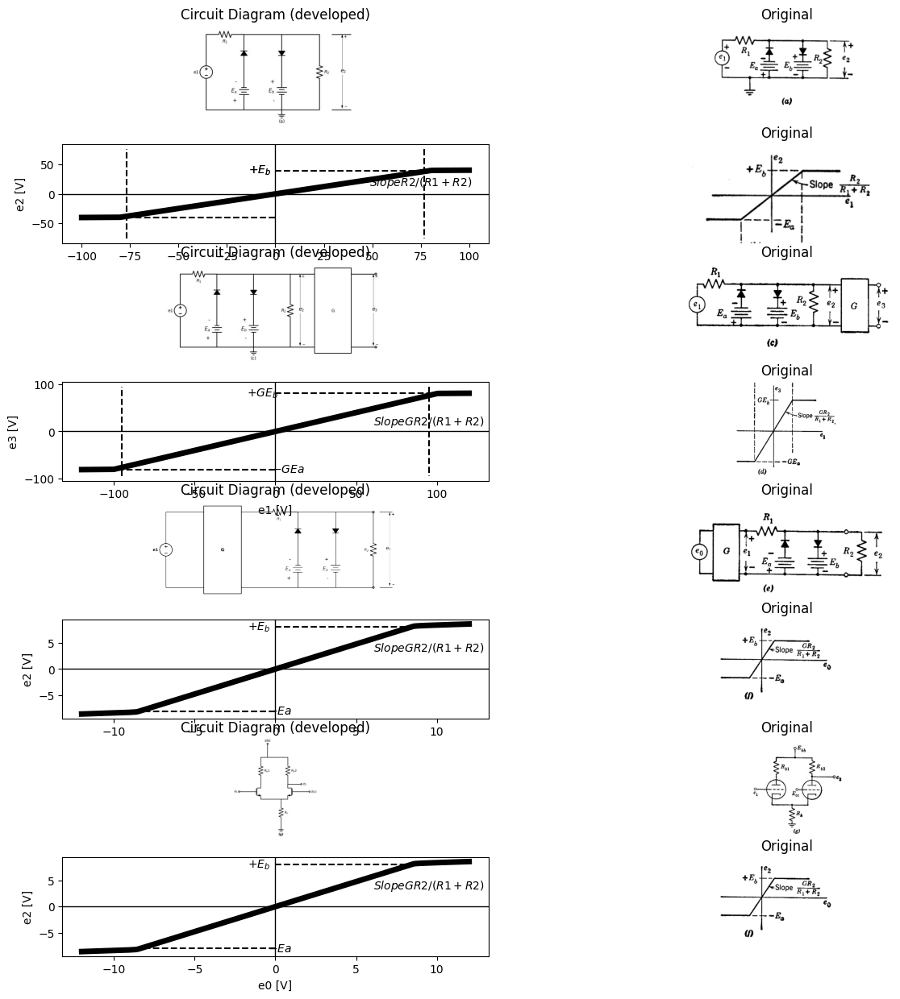

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(8, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*2).label('e1', 'top') 
d += (R1 := elm.Resistor().right().label('$R_1$', 'bottom'))
d += (D1 := elm.Diode(fill= True).down().reverse())
d += (E1 := elm.Battery().down().reverse().label(['-','$E_a$','+'], ofst=.2 , fontsize = 16).color('black'))
l1 = d.add(elm.Line().left())
l3 = d.add(elm.Line().right().at(R1.end))
d += (D2 := elm.Diode(fill= True).down())
d += (E2 := elm.Battery().down().label(['+','$E_b$','-'], ofst=.2 , fontsize = 16).color('black'))
l4 = d.add(elm.Line().left())
l5 = d.add(elm.Line().right().at(l3.end))
d += (R2 := elm.Resistor().down(d.unit*2).label('$R_2$', 'bottom'))
l6 = d.add(elm.Line().left())
d += elm.Line().right().length(1.5).at((10,0)).color('black')
d += elm.Line().right().length(1.5).at((10,6)).color('black')
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((9.2,1.8))
d += elm.Arrow().up().length(2.7).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((10.8,3.3))
d += elm.Arrow().down().length(2.7).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((10.8,2.8))
G = d.add(elm.Ground().at(E2.end).label('(a)','bottom'))
d.save('Drawings/8-1a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/8-1a.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-1a1.png')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*2).label('e1', 'top') 
d += (R1 := elm.Resistor().right().label('$R_1$', 'bottom'))
d += (D1 := elm.Diode(fill= True).down().reverse())
d += (E1 := elm.Battery().down().reverse().label(['-','$E_a$','+'], ofst=.2 , fontsize = 16).color('black'))
l1 = d.add(elm.Line().left())
l3 = d.add(elm.Line().right().at(R1.end))
d += (D2 := elm.Diode(fill= True).down())
d += (E2 := elm.Battery().down().label(['+','$E_b$','-'], ofst=.2 , fontsize = 16).color('black'))
l4 = d.add(elm.Line().left())
l5 = d.add(elm.Line().right().at(l3.end))
d += (R2 := elm.Resistor().down(d.unit*2).label('$R_2$', 'top'))
l6 = d.add(elm.Line().left())
d += elm.Line().right().length(2).at((9,0)).color('black')
d += elm.Line().right().length(2).at((9,6)).color('black')
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((8.2,1.8))
d += elm.Arrow().up().length(2.7).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((9.8,3.3))
d += elm.Arrow().down().length(2.7).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((9.8,2.8))
G = d.add(elm.Ground().at(E2.end).label('(c)','bottom'))
d += ( T := dsp.Box(w=3, h=7).anchor('W').fill('white').label('G').at((11,3)))
d += elm.Line().right().length(2).at((14,0)).dot(open=True).color('black')
d += elm.Line().right().length(2).at((14,6)).dot(open=True).color('black')
d += elm.Gap().up().label(  '$e_3$' , ofst=-1.7 , fontsize = 16).color('black').at((14.2,1.8))
d += elm.Arrow().up().length(2.7).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((15.8,3.3))
d += elm.Arrow().down().length(2.7).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((15.8,2.8))
d.save('Drawings/8-1c1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/8-1c1.jpg')
axs[2, 0].imshow(img)
axs[2, 0].axis('off')  # Hide axes for image display
axs[2, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-1c.png')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 800@u_Ohm)
circuit.D(1, '3','2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 40@u_V)
circuit.D(2, '2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 40@u_V)
circuit.R(2, '2', circuit.gnd , 800@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-100, 100, .1))
axs[1,0].plot(analysis['1'], analysis['2'],'black',linewidth=5)
axs[1,0].plot([0, 77], [40, 40], color='black', linestyle='--', label='Membership = 1')
axs[1,0].plot([0, -77], [-40, -40], color='black', linestyle='--', label='Membership = 1')
axs[1,0].plot([77, 77], [77, -77], color='black', linestyle='--', label='Membership = 2')
axs[1,0].plot([-77, -77], [-77, 77], color='black', linestyle='--', label='Membership = 2')
axs[1,0].text( -8, 40, '$+E_b$', ha='center', va='center')
axs[1,0].text( -8, 40, '$+E_b$', ha='center', va='center')
axs[1,0].text( 75, 20, '$Slope R2/(R1+R2)$', ha='center', va='center')
axs[1,0].set_xlabel('e1 [V]')
axs[1,0].set_ylabel('e2 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
d.save('Drawings/8-1a.jpg')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-1b.png')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 500@u_Ohm)
circuit.D(1, '3','2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 80@u_V)
circuit.D(2, '2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 80@u_V)
circuit.R(2, '2', circuit.gnd , 2000@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-120, 120, .01))
axs[3,0].plot(analysis['1'], analysis['2'],'black',linewidth=5)
axs[3,0].plot([0, 120], [80, 80], color='black', linestyle='--', label='Membership = 2')
axs[3,0].plot([0, -120], [-80, -80], color='black', linestyle='--', label='Membership = 2')
axs[3,0].plot([95, 95], [95, -95], color='black', linestyle='--', label='Membership = 2')
axs[3,0].plot([-95, -95], [-95, 95], color='black', linestyle='--', label='Membership = 2')
axs[3,0].text( -8, 80, '$+GE_b$', ha='center', va='center')
axs[3,0].text( 8, -80, '$-GEa$', ha='center', va='center')
axs[3,0].text( 95, 20, '$Slope GR2/(R1+R2)$', ha='center', va='center')
axs[3,0].set_xlabel('e1 [V]')
axs[3,0].set_ylabel('e3 [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
d.save('Drawings/8-1b.jpg')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-1d.png')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*2).label('e1', 'top') 
l1 = d.add(elm.Line().right())
d += ( T := dsp.Box(w=3, h=7).anchor('W').fill('white').label('G').at((3,3)))
l2 = d.add(elm.Line().left().at((3,0)))
l1 = d.add(elm.Line().right(d.unit*.5).at((6,6)))
d += (R1 := elm.Resistor().right().label('$R_1$', 'bottom'))
d += (D1 := elm.Diode(fill= True).down().reverse())
d += (E1 := elm.Battery().down().reverse().label(['-','$E_a$','+'], ofst=.2 , fontsize = 16).color('black'))
l1 = d.add(elm.Line().left(d.unit*1.5))
l3 = d.add(elm.Line().right().at(R1.end))
d += (D2 := elm.Diode(fill= True).down())
d += (E2 := elm.Battery().down().label(['+','$E_b$','-'], ofst=.2 , fontsize = 16).color('black'))
l4 = d.add(elm.Line().left())
l5 = d.add(elm.Line().right().at(l3.end).dot(open=True))
d += (R2 := elm.Resistor().down(d.unit*2).label('$R_2$', 'top').dot(open=True))
l6 = d.add(elm.Line().left(d.unit*1))
d += elm.Line().right().length(1).at((17,0)).color('black')
d += elm.Line().right().length(1).at((17,6)).color('black')
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((16,1.8))
d += elm.Arrow().up().length(2.7).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((17.8,3.3))
d += elm.Arrow().down().length(2.7).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((17.8,2.8))
d.save('Drawings/8-1e1.png')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/8-1e1.png')
axs[4, 0].imshow(img)
axs[4, 0].axis('off')  # Hide axes for image display
axs[4, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-1e.png')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')


rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.D(1, '3','2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 8@u_V)
circuit.D(2, '2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 8@u_V)
circuit.R(2, '2', circuit.gnd , 2000@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-12, 12, .01))
axs[5,0].plot(analysis['1'], analysis['2'],'black',linewidth=5)
axs[5,0].plot([0, 8], [8, 8], color='black', linestyle='--', label='Membership = 2')
axs[5,0].plot([0, -8.5], [-8, -8], color='black', linestyle='--', label='Membership = 2')
axs[5,0].text( -1, 8, '$+E_b$', ha='center', va='center')
axs[5,0].text( .3, -8, '$-Ea$', ha='center', va='center')
axs[5,0].text( 9.5, 4, '$Slope GR2/(R1+R2)$', ha='center', va='center')
axs[5,0].set_xlabel('e0 [V]')
axs[5,0].set_ylabel('e2 [V]')
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
d.save('Drawings/8-1c.jpg')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-1f.png')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).at((3,0)))
l1 = d.add(elm.Line().right(d.unit*.75).at(M1.source))
d += (R1 := elm.Resistor().down().label('$R_k$', 'bottom'))
l2 = d.add(elm.Line().left(d.unit*.75).at(M2.source))
G = d.add(elm.Ground().at(R1.end).label('(g)','bottom'))
d += (R2 := elm.Resistor().up().label('$R_b1$', 'bottom').at(M1.drain))
d += (R3 := elm.Resistor().up().label('$R_b2$', 'bottom').at(M2.drain))
l3 = d.add(elm.Line().left(d.unit*.75).at(R3.end))
l4 = d.add(elm.Line().up(d.unit*.5).dot(open=True).label('$Ebb $','right'))
l5 = d.add(elm.Line().right(d.unit*.75).at(R2.end))
l6 = d.add(elm.Line().right(d.unit*.5).dot(open=True).label('$e_2 $','right').at(R3.start))
l7 = d.add(elm.Line().right(d.unit*.5).dot(open=True).label('$Ecc $','right').at(M2.gate))
l8 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
d.save('Drawings/8-1g1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/8-1g1.jpg')
axs[6, 0].imshow(img)
axs[6, 0].axis('off')  # Hide axes for image display
axs[6, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-1g.jpg')  # Load the PNG file
axs[6,1].imshow(img_sample)
axs[6,1].axis('off')  # Hide axes for image display
axs[6,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 100@u_Ohm)
circuit.D(1, '3','2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 8@u_V)
circuit.D(2, '2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 8@u_V)
circuit.R(2, '2', circuit.gnd , 2000@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-12, 12, .01))
axs[7,0].plot(analysis['1'], analysis['2'],'black',linewidth=5)
axs[7,0].plot([0, 8], [8, 8], color='black', linestyle='--', label='Membership = 2')
axs[7,0].plot([0, -8.5], [-8, -8], color='black', linestyle='--', label='Membership = 2')
axs[7,0].text( -1, 8, '$+E_b$', ha='center', va='center')
axs[7,0].text( .3, -8, '$-Ea$', ha='center', va='center')
axs[7,0].text( 9.5, 4, '$Slope GR2/(R1+R2)$', ha='center', va='center')
axs[7,0].set_xlabel('e0 [V]')
axs[7,0].set_ylabel('e2 [V]')
axs[7,0].axhline(0, color='black', linewidth=1)
axs[7,0].axvline(0, color='black', linewidth=1)
d.save('Drawings/8-1d.jpg')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-1f.png')  # Load the PNG file
axs[7,1].imshow(img_sample)
axs[7,1].axis('off')  # Hide axes for image display
axs[7,1].set_title('Original')

## Fig8.1. Amplitude Limiters

input voltage range between break points has not changed but the output range has expanded. On the other hand, in the curve of $(f)$ the output range is unchanged, and the range of input voltage between break points is compressed. The cathode-coupled circuit shown in $Fig. 8.1(g)$ is often used as a limiter. Its transfer curve is shown in $(h).$ 
The effects of a limiter on a variety of electrical time functions $e(t)$ are shown in $Fig. 8.2.$ Note that the amplitude of the waveform, together with the $d-c$ level, determines the character of the output wave. For 


Text(0.5, 1.0, 'Original')

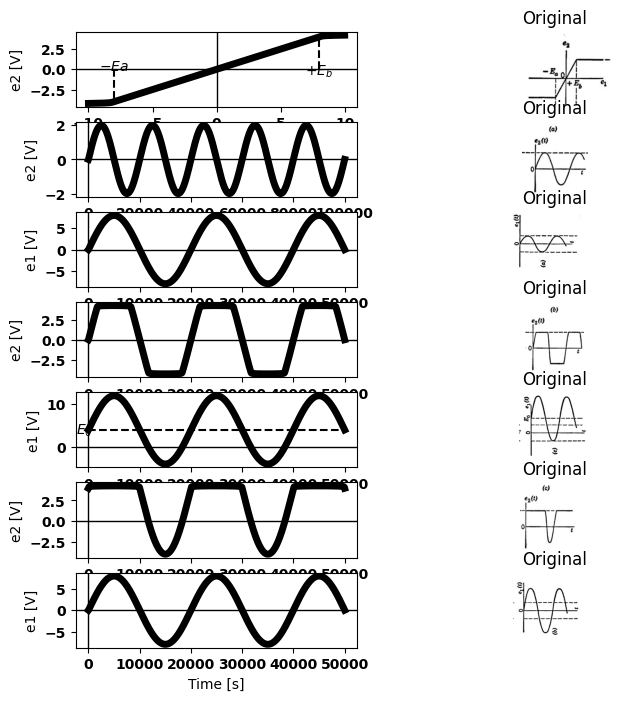

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
rcParams['font.weight'] = 'bold'
fig, axs = plt.subplots(7, 2, figsize=(8, 8))
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 800@u_Ohm)
circuit.D(1, '3','2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 4@u_V)
circuit.D(2, '2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 4@u_V)
circuit.R(2, '2', circuit.gnd , 800@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-10, 10, .01))
axs[0,0].plot(analysis['1'], analysis['2'],'black',linewidth=5)
axs[0,0].plot([8, 8], [0, 4], color='black', linestyle='--', label='Membership = 1')
axs[0,0].plot([-8, -8], [0, -4], color='black', linestyle='--', label='Membership = 1')
axs[0,0].text( 8, -0.2, '$+E_b$', ha='center', va='center')
axs[0,0].text( -8, .4, '$-Ea$', ha='center', va='center')
axs[0,0].set_xlabel('e1 [V]')
axs[0,0].set_ylabel('e2 [V]')
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-2.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
circuit.SinusoidalVoltageSource('i', '1', circuit.gnd, amplitude=4@u_V)
circuit.R(1, '1', 'e2', 800@u_Ohm)
circuit.D(1, '3','e2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 4@u_V)
circuit.D(2, 'e2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 4@u_V)
circuit.R(2, 'e2', circuit.gnd , 800@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['e2'],'black',linestyle='-',linewidth=5) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].set_ylabel('e2 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-2a-out.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

rcParams['font.weight'] = 'bold'

circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 1@u_Ohm )
circuit.SinusoidalVoltageSource('i', '1', circuit.gnd, amplitude=8@u_V)
circuit.R(1, '1', 'e2', 800@u_Ohm)
circuit.D(1, '3','e2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 4@u_V)
circuit.D(2, 'e2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 4@u_V)
circuit.R(2, 'e2', circuit.gnd , 80000@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.05@u_s)
axs[2,0].plot(analysis['1'],'black',linestyle='-',linewidth=5) 
axs[2,0].set_xlabel('Time [s]')
axs[2,0].set_ylabel('e1 [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-2a-in.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 1@u_Ohm )
circuit.SinusoidalVoltageSource('i', '1', circuit.gnd, amplitude=8@u_V)
circuit.R(1, '1', 'e2', 800@u_Ohm)
circuit.D(1, '3','e2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 4@u_V)
circuit.D(2, 'e2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 4@u_V)
circuit.R(2, 'e2', circuit.gnd , 80000@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.05@u_s)
axs[3,0].plot(analysis['e2'],'black',linestyle='-',linewidth=5) 
axs[3,0].set_xlabel('Time [s]')
axs[3,0].set_ylabel('e2 [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-2b-out.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')


rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 1@u_Ohm )
circuit.SinusoidalVoltageSource('i', '1', circuit.gnd, amplitude=8@u_V)
Vi = circuit.V('E0', '1', '11', -4@u_V)
circuit.R(1, '11', 'e2', 800@u_Ohm)
circuit.D(1, '3','e2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 4@u_V)
circuit.D(2, 'e2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 4@u_V)
circuit.R(2, 'e2', circuit.gnd , 80000@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.05@u_s) 
axs[4,0].plot(analysis['11'],'black',linestyle='-',linewidth=5)  
axs[4,0].plot([4, 50000], [4, 4], color='black', linestyle='--', label='Membership = 1')
axs[4,0].text( -800, 4, '$E_0$', ha='center', va='center')
axs[4,0].set_xlabel('Time [s]')
axs[4,0].set_ylabel('e1 [V]')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)

img_sample = mpimg.imread('images/8-2c-in.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

rcParams['font.weight'] = 'bold'

circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 1@u_Ohm )
circuit.SinusoidalVoltageSource('i', '1', circuit.gnd, amplitude=8@u_V)
Vi = circuit.V('E0', '1', '11', -4@u_V)
circuit.R(1, '11', 'e2', 800@u_Ohm)
circuit.D(1, '3','e2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 4@u_V)
circuit.D(2, 'e2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 4@u_V)
circuit.R(2, 'e2', circuit.gnd , 80000@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.05@u_s)
axs[5,0].plot(analysis['e2'],'black',linestyle='-',linewidth=5)  
axs[5,0].set_xlabel('Time [s]')
axs[5,0].set_ylabel('e2 [V]')
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-2c-out.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 1@u_Ohm )
circuit.SinusoidalVoltageSource('i', '1', circuit.gnd, amplitude=8@u_V)
circuit.R(1, '1', 'e2', 800@u_Ohm)
circuit.D(1, '3','e2', model = 'BAV21')
circuit.V(1, circuit.gnd,'3' , 4@u_V)
circuit.D(2, 'e2','4', model = 'BAV21')
circuit.V(2,'4' ,circuit.gnd , 4@u_V)
circuit.R(2, 'e2', circuit.gnd , 80000@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.05@u_s)
axs[6,0].plot(analysis['1'],'black',linestyle='-',linewidth=5) 
axs[6,0].set_xlabel('Time [s]')
axs[6,0].set_ylabel('e1 [V]')
axs[6,0].axhline(0, color='black', linewidth=1)
axs[6,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-2b-in.jpg')  # Load the PNG file
axs[6,1].imshow(img_sample)
axs[6,1].axis('off')  # Hide axes for image display
axs[6,1].set_title('Original')

## Fig 8.2. Linear amplification and limiting

this limiter-amplifier curve, linear amplification is obtained if the time- varying signal can be fitted between the break points, as shown in part $(a).$ Symmetrical and unsymmetrical limiting or clipping are illustrated by $(b)$ and $(c).$ If the distance between break points along the input axis is very small compared to the total amplitude of the input signal, the operation is called "slicing." This amounts to passing only a thin slice of the input waveform, and results in a very nearly rectangular output waveform. Slicing amounts to "hard limiting," and effectively 
determines the instant at which the input time function crosses a given voltage level. 


# 8.4 Wave Shaping with Linear Energy-Storage Elements 

The relation between current and voltage for a resistance is independ- ent of time. The terminal relations between current and voltage for inductance or capacitance are time dependent $(v=Ldi٫dt and i = Cdv٫dt).$ The simple voltage and current waveforms shown in $Fig. 8.3 (b)$ and $(c)$ illustrate the wave-shaping properties of inductance and capacitance. Whether we consider current to be the cause and voltage the effect, or vice versa, the shapes of the time functions $v(t)$ and $i(t)$ are 

Text(0.5, 1.0, 'Original')

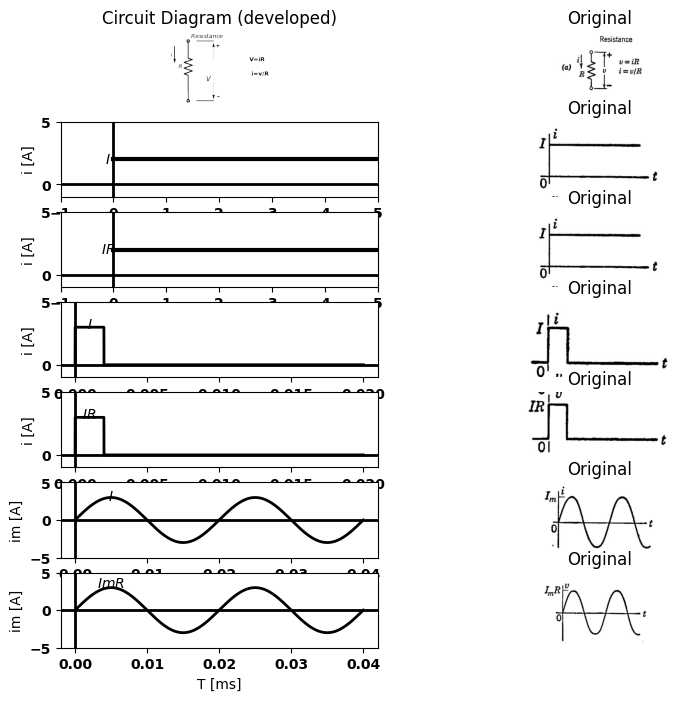

In [3]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(7, 2, figsize=(9, 8))
d = schemdraw.Drawing()
l1 = d.add(elm.Line().up().length(0.5).dot(open=True))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l2 = d.add(elm.Line().down().length(0.5).dot(open=True))
d += elm.Arrow().down().length(1).color('black').label('$i$', loc='top', color='black'). at((-0.8,.2))
d += elm.Line().right().length(1).at((0.5,-3)).color('black')
d += elm.Line().right().length(1.).at((.5,.5)).color('black').label('  $Resistance$','top')
d += elm.Gap().up().label(  '$V$' , ofst=-1.7 , fontsize = 16).color('black').at((-0.5,-3))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((1.5,-.6))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((1.5,-1.9))
l3 = d.add(elm.Line().right().color('white').length(0.5).at((3,-1)).label('V=iR\n\n i=v/R','right',color='black'))
d.save('images/8-3r1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-3r1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-3r.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.I(1 ,'1', circuit.gnd, 2@u_A )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))

axs[1,0].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=3)
axs[1,0].set_xlim(-1, 5)
axs[1,0].set_xlabel('T [s]')
axs[1,0].set_ylabel('i [A]')
axs[1,0].text( -.1, 2, '$I$', ha='center', va='center')
axs[1,0].set_ylim(-1, 5)
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3rb1.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.I(1 ,'1', circuit.gnd, 2@u_A )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))

axs[2,0].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=3)
axs[2,0].set_xlim(-1, 5)
axs[2,0].set_xlabel('T [s]')
axs[2,0].set_ylabel('i [A]')
axs[2,0].text( -.1, 2, '$IR$', ha='center', va='center')
axs[2,0].set_ylim(-1, 5)
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3rb1.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=2@u_ms, period=20@u_ms)
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[3,0].set_xlabel('T [ms]')
axs[3,0].set_ylabel('i [A]')
axs[3,0].text( 0.0010, 3.2, '$I$', ha='center', va='center')
axs[3,0].set_ylim(-1, 5)
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3rc1.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=2@u_ms, period=20@u_ms)
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[4,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[4,0].set_xlabel('T [ms]')
axs[4,0].set_ylabel('i [A]')
axs[4,0].text( 0.0010, 3.2, '$IR$', ha='center', va='center')
axs[4,0].set_ylim(-1, 5)
axs[4,0].axhline(0, color='black', linewidth=2)
axs[4,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3rc2.JPG')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.SinusoidalVoltageSource('V1', '1', circuit.gnd, amplitude=3@u_V) 
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[5,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[5,0].set_xlabel('T [ms]')
axs[5,0].set_ylabel('im [A]')
axs[5,0].text( 0.0050, 3.2, '$I$', ha='center', va='center')
axs[5,0].set_ylim(-5, 5)
axs[5,0].axhline(0, color='black', linewidth=2)
axs[5,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3rd1.JPG')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.SinusoidalVoltageSource('V1', '1', circuit.gnd, amplitude=3@u_V) 
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[6,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[6,0].set_xlabel('T [ms]')
axs[6,0].set_ylabel('im [A]')
axs[6,0].text( 0.0050, 3.5, '$ImR$', ha='center', va='center')
axs[6,0].set_ylim(-5, 5)
axs[6,0].axhline(0, color='black', linewidth=2)
axs[6,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3rd2.JPG')  # Load the PNG file
axs[6,1].imshow(img_sample)
axs[6,1].axis('off')  # Hide axes for image display
axs[6,1].set_title('Original')


Text(0.5, 1.0, 'Original')

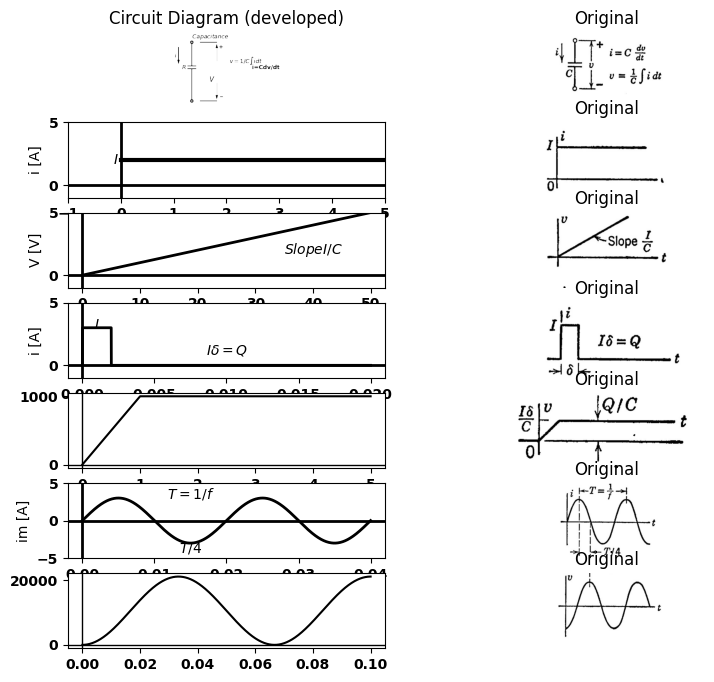

In [4]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(7, 2, figsize=(9, 8))
d = schemdraw.Drawing()
l1 = d.add(elm.Line().up().length(0.5).dot(open=True))
d += (C1 := elm.Capacitor().down().label('$R$', 'top'))
l2 = d.add(elm.Line().down().length(0.5).dot(open=True))
d += elm.Arrow().down().length(1).color('black').label('$i$', loc='top', color='black'). at((-0.8,.2))
d += elm.Line().right().length(1).at((0.5,-3)).color('black')
d += elm.Line().right().length(1.).at((.5,.5)).color('black').label('  $Capacitance$','top')
d += elm.Gap().up().label(  '$V$' , ofst=-1.7 , fontsize = 16).color('black').at((-0.5,-3))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((1.5,-.6))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((1.5,-1.9))
l3 = d.add(elm.Line().right().color('white').length(0.5).at((3,-1)).label('i=Cdv/dt','right',color='black').label('$v=1/C\int idt$','top',color='black'))
d.save('images/8-3c1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-3c1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-3c.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.I(1 ,'1', circuit.gnd, 2@u_A )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))

axs[1,0].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=3)
axs[1,0].set_xlim(-1, 5)
axs[1,0].set_xlabel('T [s]')
axs[1,0].set_ylabel('i [A]')
axs[1,0].text( -.1, 2, '$I$', ha='center', va='center')
axs[1,0].set_ylim(-1, 5)
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3cb1.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.C(1 ,'1', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))
axs[2,0].plot(analysis['1'],'black',linewidth=2) 
axs[2,0].set_xlabel('T [ms]')
axs[2,0].set_ylabel('V [V]')
axs[2,0].text( 40, 2, '$Slope I/C$', ha='center', va='center')
axs[2,0].set_ylim(-1, 5)
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3cb2.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=2@u_ms, period=20@u_ms)
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[3,0].set_xlabel('T [ms]')
axs[3,0].set_ylabel('i [A]')
axs[3,0].text( 0.0010, 3.2, '$I$', ha='center', va='center')
axs[3,0].text( 0.010, 1.2, '$I\delta=Q$', ha='center', va='center')
axs[3,0].set_ylim(-1, 5)
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3cc1.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

# Parameters
C = 1e-6  # Capacitance (Farads)
pulse_duration = 1e-3  # Pulse duration (seconds)
pulse_amplitude = 1.0 # Pulse amplitude (Amps)
simulation_time = 5 * pulse_duration  # Simulation time (seconds)
dt = 1e-6 # time step

# Time array
time = np.arange(0, simulation_time, dt)

# Input Pulse current
current = np.zeros_like(time)
current[(time >= 0) & (time < pulse_duration)] = pulse_amplitude

# Voltage calculation
voltage = np.zeros_like(time)
for i in range(1,len(time)):
    voltage[i] = voltage[i-1] + (1/C) * current[i] * dt


axs[4,0].plot(time*1000, voltage, color='black')
axs[4,0].axhline(0, color='black', lw=1)
axs[4,0].axvline(0, color='black', lw=1)
img_sample = mpimg.imread('images/8-3cc2.JPG')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.SinusoidalVoltageSource('V1', '1', circuit.gnd, amplitude=3@u_V) 
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[5,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[5,0].set_xlabel('T [ms]')
axs[5,0].set_ylabel('im [A]')
axs[5,0].text( 0.0150, 3.5, '$T=1/f$', ha='center', va='center')
axs[5,0].text( 0.0150, -3.7, '$T/4$', ha='center', va='center')
axs[5,0].set_ylim(-5, 5)
axs[5,0].axhline(0, color='black', linewidth=2)
axs[5,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3cd1.JPG')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

# Parameters
C = 1e-6  # Capacitance (Farads)
frequency = 100  # Frequency of the sinusoidal current (Hz)
amplitude = 1.0  # Amplitude of the sinusoidal current (Amps)
simulation_time = 0.1  # Simulation time (seconds)
dt = 1e-6  # Time step (seconds)

# Time array
time = np.arange(0, simulation_time, dt)

# Input sinusoidal current
current = amplitude * np.sin(.3 * np.pi * frequency * time)

# Voltage calculation
voltage = np.zeros_like(time)
for i in range(1,len(time)):
    voltage[i] = voltage[i-1] + (1/C) * current[i] * dt

axs[6,0].plot(time, voltage, color='black')
#axs[6,0].xlabel("Time (s)")
#axs[6,0].ylabel("Voltage (V)")
axs[6,0].axhline(0, color='black', lw=1)
axs[6,0].axvline(0, color='black', lw=1)

img_sample = mpimg.imread('images/8-3cd2.JPG')  # Load the PNG file
axs[6,1].imshow(img_sample)
axs[6,1].axis('off')  # Hide axes for image display
axs[6,1].set_title('Original')



Text(0.5, 1.0, 'Original')

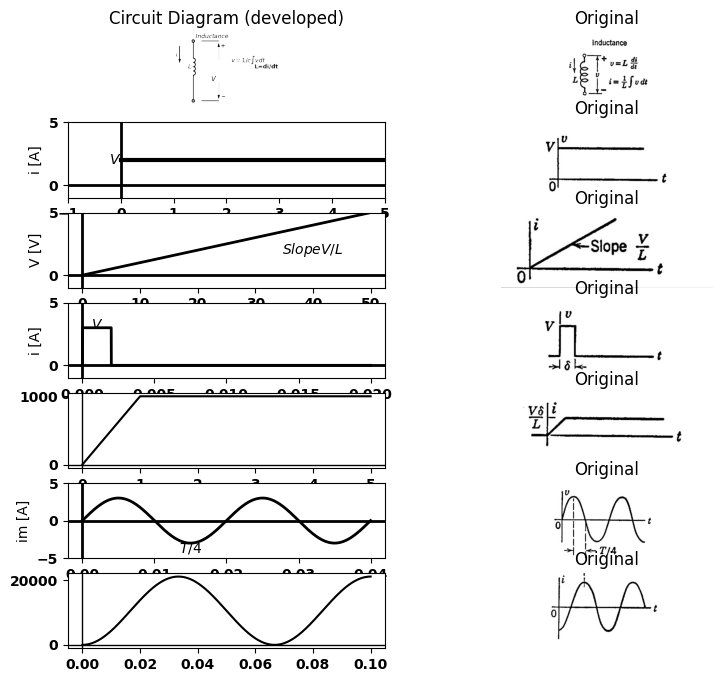

In [5]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(7, 2, figsize=(9, 8))
d = schemdraw.Drawing()
l1 = d.add(elm.Line().up().length(0.5).dot(open=True))
d += (L1 := elm.Inductor().down().label('$L$', 'top').reverse())
l2 = d.add(elm.Line().down().length(0.5).dot(open=True))
d += elm.Arrow().down().length(1).color('black').label('$i$', loc='top', color='black'). at((-0.8,.2))
d += elm.Line().right().length(1).at((0.5,-3)).color('black')
d += elm.Line().right().length(1.).at((.5,.5)).color('black').label('  $Inductance$','top')
d += elm.Gap().up().label(  '$V$' , ofst=-1.7 , fontsize = 16).color('black').at((-0.5,-3))
d += elm.Arrow().up().length(1).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((1.5,-.6))
d += elm.Arrow().down().length(1).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((1.5,-1.9))
l3 = d.add(elm.Line().right().color('white').length(0.5).at((3,-1)).label('L=di/dt','right',color='black').label('$v=1/c\int vdt$','top',color='black'))
d.save('images/8-3l1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-3l1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-3l.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.I(1 ,'1', circuit.gnd, 2@u_A )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))

axs[1,0].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=3)
axs[1,0].set_xlim(-1, 5)
axs[1,0].set_xlabel('T [s]')
axs[1,0].set_ylabel('i [A]')
axs[1,0].text( -.1, 2, '$V$', ha='center', va='center')
axs[1,0].set_ylim(-1, 5)
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3la1.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.C(1 ,'1', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))
axs[2,0].plot(analysis['1'],'black',linewidth=2) 
axs[2,0].set_xlabel('T [ms]')
axs[2,0].set_ylabel('V [V]')
axs[2,0].text( 40, 2, '$Slope V/L$', ha='center', va='center')
axs[2,0].set_ylim(-1, 5)
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3la2.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=2@u_ms, period=20@u_ms)
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[3,0].set_xlabel('T [ms]')
axs[3,0].set_ylabel('i [A]')
axs[3,0].text( 0.0010, 3.2, '$V$', ha='center', va='center')

axs[3,0].set_ylim(-1, 5)
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3lb1.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

# Parameters
C = 1e-6  # Capacitance (Farads)
pulse_duration = 1e-3  # Pulse duration (seconds)
pulse_amplitude = 1.0 # Pulse amplitude (Amps)
simulation_time = 5 * pulse_duration  # Simulation time (seconds)
dt = 1e-6 # time step

# Time array
time = np.arange(0, simulation_time, dt)

# Input Pulse current
current = np.zeros_like(time)
current[(time >= 0) & (time < pulse_duration)] = pulse_amplitude

# Voltage calculation
voltage = np.zeros_like(time)
for i in range(1,len(time)):
    voltage[i] = voltage[i-1] + (1/C) * current[i] * dt


axs[4,0].plot(time*1000, voltage, color='black')
axs[4,0].axhline(0, color='black', lw=1)
axs[4,0].axvline(0, color='black', lw=1)
img_sample = mpimg.imread('images/8-3lb2.JPG')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.SinusoidalVoltageSource('V1', '1', circuit.gnd, amplitude=3@u_V) 
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[5,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[5,0].set_xlabel('T [ms]')
axs[5,0].set_ylabel('im [A]')
axs[5,0].text( 0.0150, -3.7, '$T/4$', ha='center', va='center')
axs[5,0].set_ylim(-5, 5)
axs[5,0].axhline(0, color='black', linewidth=2)
axs[5,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-3lc1.JPG')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

# Parameters
C = 1e-6  # Capacitance (Farads)
frequency = 100  # Frequency of the sinusoidal current (Hz)
amplitude = 1.0  # Amplitude of the sinusoidal current (Amps)
simulation_time = 0.1  # Simulation time (seconds)
dt = 1e-6  # Time step (seconds)

# Time array
time = np.arange(0, simulation_time, dt)

# Input sinusoidal current
current = amplitude * np.sin(.3 * np.pi * frequency * time)

# Voltage calculation
voltage = np.zeros_like(time)
for i in range(1,len(time)):
    voltage[i] = voltage[i-1] + (1/C) * current[i] * dt

axs[6,0].plot(time, voltage, color='black')
#axs[6,0].xlabel("Time (s)")
#axs[6,0].ylabel("Voltage (V)")
axs[6,0].axhline(0, color='black', lw=1)
axs[6,0].axvline(0, color='black', lw=1)

img_sample = mpimg.imread('images/8-3lc2.JPG')  # Load the PNG file
axs[6,1].imshow(img_sample)
axs[6,1].axis('off')  # Hide axes for image display
axs[6,1].set_title('Original')


## 8.3. Current-voltage relation for R,L and C

different for $L$ and C, but identical for $R.$ For the idealized waveforms shown, the necessary differentiation or integration can be carried out by inspection. In $(d)$, note that $v(t)$ or $i(t)$ is subject to a time delay (or advance) rather than a change in shape.

# 8.5 Series RC Circuit with Sine-Wave Input 

The response of a series RC circuit to a sinusoidal input is summarized in Fig. 8.4. This circuit is of considerable importance, since it represents the basic capacitive coupling network used for d-c isolation. The direct component of the input voltage charges the capacitance to the value QoCEo, but does not affect the steady-state a-c voltage across the resistor; nor does the static capacitor voltage Eo affect the variational capacitor voltage. The separability of these d-c and a-c effects is a consequence of the fact that the principle of superposition applies to linear systems. The voltage waveforms appear in (d). We have tacitly assumed that the d-c and a-c components of e₁ were applied to the circuit at some time in the past, and that steady-state conditions already existed at our arbitrary time reference $t 0.$ 
The vector diagram $[Fig. 8.4(e)]$ shows the relative amplitudes and phase relations of the three voltages involved. The direction of the current vector $Im$ coincides with that of $E2$ $ImR$. This vector diagram is drawn for a particular value of angular frequency $w.$ Since the current is common, a $90°$ phase relation exists between resistive voltage and capacitive voltage for any value of frequency. Thus the locus of point Pis a semicircle if w is varied from zero to infinity while Em is held constant. The vector diagram also shows that the magnitude of $ex$ or $e₂$ cannot exceed that of $e₁$, since the diameter of the circle is larger than any chord. 


# 8.6 Step Response of a Series RC Circuit 

Let us now review the short-time or transient effect of suddenly applying a $d-e $voltage to a series RC circuit, $Fig. 8.5(a).$ The basic equations are given in $(b).$ The requirement that e shall equal zero for t less than zero, and equal E fort greater than zero, is met by the circuit given in (c), where switch S closes at $t = 0$ to apply the battery $E$ to the $RC$ combination. This is equivalent to a time-varying generator $e₁ (t)$ whose output waveform is a step of voltage from$ 0$ to$ Eatt = 0.$ If the time $t$ is plotted in units $RC$ (the time constant), the voltage waveforms 

Text(0.5, 1.0, 'Original')

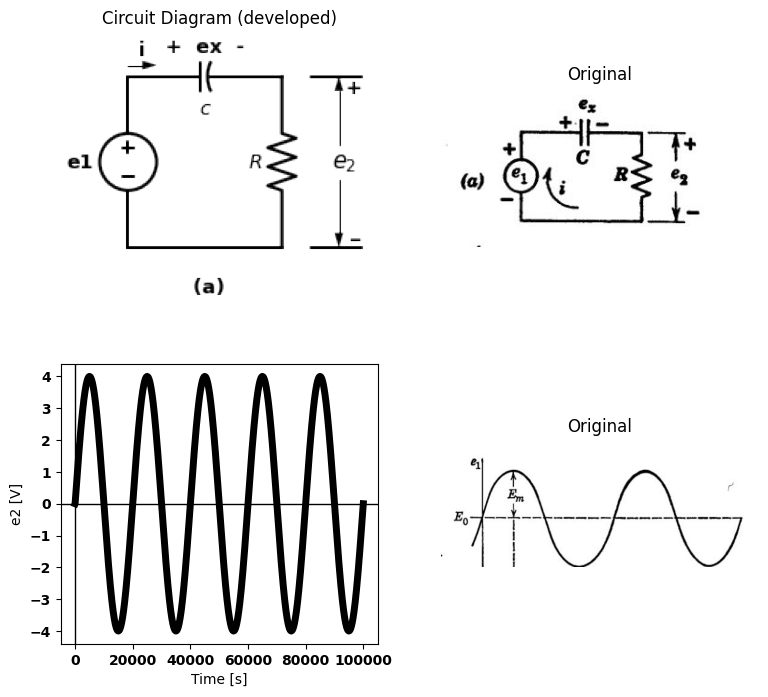

In [6]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(9, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label('\n (a)','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-4a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-4a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-4a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.SinusoidalVoltageSource('i', '1', circuit.gnd, amplitude=4@u_V)
circuit.C(1, '1', '2', 10@u_uF)
circuit.R(1, '2', circuit.gnd, 90@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s) 
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=5)
axs[1,0].set_xlabel('Time [s]')
axs[1,0].set_ylabel('e2 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-4d1.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')


Text(0.5, 1.0, 'Original')

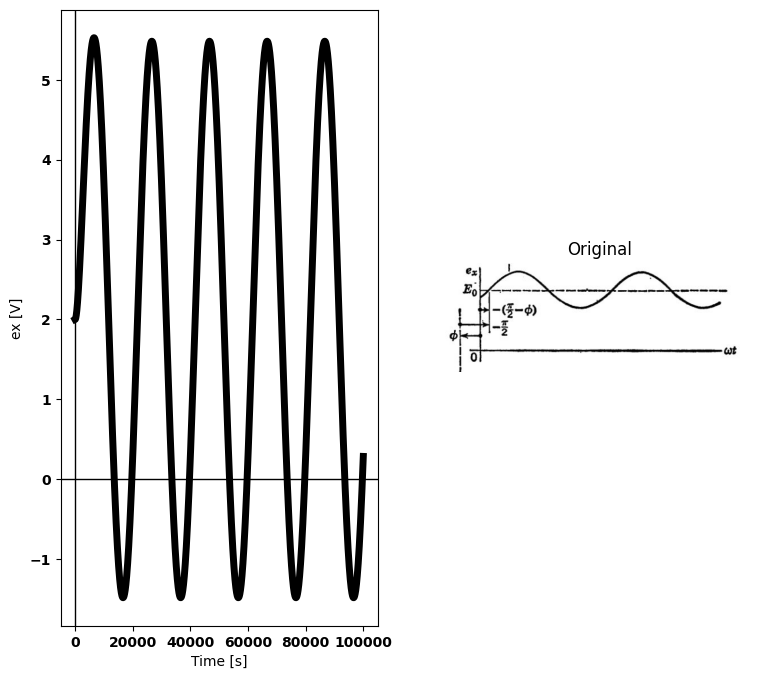

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(9, 8))
d = schemdraw.Drawing()
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
circuit.SinusoidalVoltageSource('i', '1', circuit.gnd, amplitude=4@u_V)
Vth = circuit.V('th', '1', '11', -2@u_V)
circuit.C(1, '11', '2', 2@u_uF)
circuit.R(1, '2', circuit.gnd, 900@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
axs[0].plot(analysis['11']-analysis['2'],'black',linestyle='-',linewidth=5) 
axs[0].set_xlabel('Time [s]')
axs[0].set_ylabel('ex [V]')
axs[0].axhline(0, color='black', linewidth=1)
axs[0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-4d2.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

Text(0.5, 1.0, 'Original')

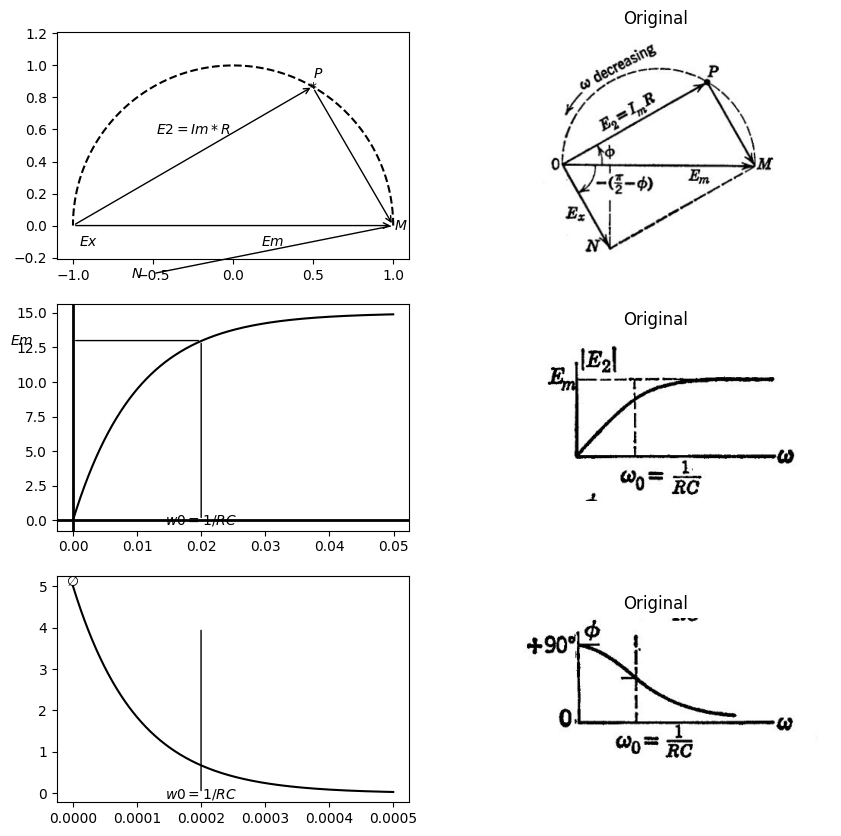

In [6]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 10))
d = schemdraw.Drawing()
theta = np.linspace(0, np.pi, 100)
x = np.cos(theta)
y = np.sin(theta)
axs[0,0].annotate('', xy=(1, 0), xytext=(-1, 0), arrowprops=dict(arrowstyle='->'))
axs[0,0].annotate('', xy=(.5, .87), xytext=(-1, 0), arrowprops=dict(arrowstyle='->'))
axs[0,0].annotate('', xy=(1, 0), xytext=(0.5, .86), arrowprops=dict(arrowstyle='->'))
axs[0,0].annotate('', xy=(-.5, -0.3), xytext=(-1, 0), arrowprops=dict(arrowstyle='->'))
axs[0,0].annotate('', xy=(1, 0), xytext=(-.5, -.3), arrowprops=dict(arrowstyle='-'))
axs[0,0].plot(x, y, linestyle='--',color='black')
axs[0,0].text(.5, .87, '$*$', ha='center', va='center')
axs[0,0].text(.53, .95, '$P$', ha='center', va='center')
axs[0,0].text(1.05, 0, '$M$', ha='center', va='center')
axs[0,0].text(-.6, -.3, '$N$', ha='center', va='center')
axs[0,0].text(.25, -.1, '$Em$', ha='center', va='center')
axs[0,0].text(-.9, -.1, '$Ex$', ha='center', va='center')
axs[0,0].text(-.25, .6, '$E2=Im*R$', ha='center', va='center')
axs[0,0].axis('equal')
#axs[0].show()
img_sample = mpimg.imread('images/8-4e1.JPG')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

R = 1000     
C = 10e-6    
V0 = 15       
t_start = 0 
t_end = 5*R*C     
dt = (t_end - t_start) / 1000   
t = np.arange(t_start, t_end, dt)
Vc = V0 * (1 - np.exp(-t / (R * C)))
axs[1,0].text(.02, -.01, '$w0=1/RC$', ha='center', va='center')
axs[1,0].text(-.008, 13, '$Em$', ha='center', va='center')
axs[1,0].annotate('', xy=(0.02, 0), xytext=(0.02, 13), arrowprops=dict(arrowstyle='-'))
axs[1,0].annotate('', xy=(0, 13), xytext=(0.02, 13), arrowprops=dict(arrowstyle='-'))
axs[1,0].plot(t, Vc, color='black')
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-4e2.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
R = 1000     
C = .10e-6     
V0 = 5       

t_start = 0 
t_end = 5*R*C     
dt = (t_end - t_start) / 1000   

t = np.arange(t_start, t_end, dt)
Vc = V0 * np.exp(-t / (R * C))
axs[2,0].plot(t, Vc,color='black')
axs[2,0].text(.0002, -.03, '$w0=1/RC$', ha='center', va='center')
axs[2,0].text(.0000, 5.1, '$\emptyset$', ha='center', va='center')
axs[2,0].annotate('', xy=(0.0002, 0), xytext=(0.0002, 4), arrowprops=dict(arrowstyle='-'))
img_sample = mpimg.imread('images/8-4e3.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## fig 8.4 Linear RC Circuit with d-c and a-c Voltage aplied

are independent of $R$ and $C$, and the current waveform involves$ R$ only in the amplitude scale. Alternatively, we may plot normalized time $(x=t٫RC=t/\tau)$, in which case the units are $1$, $2$,$ 3$ etc., instead of $\tau$, $2\tau$, $3\tau$, etc. (See exponential curves in Appendix D.) 
The slope of an exponential waveform at any point is the remaining amplitude divided by the time constant. Thus, at$ t = 0$ the slope has a magnitude $E/\tau$; and if the initial slope is extended to $t = \tau$, the final value is reached. 
Integration of the current waveform from $t= 0 $to  $t=\infty $ yield $E\tau/ R=EC=Q $, the charge required to change $ex $from zero to $E.$ It 



Text(0.5, 1.0, 'Original')

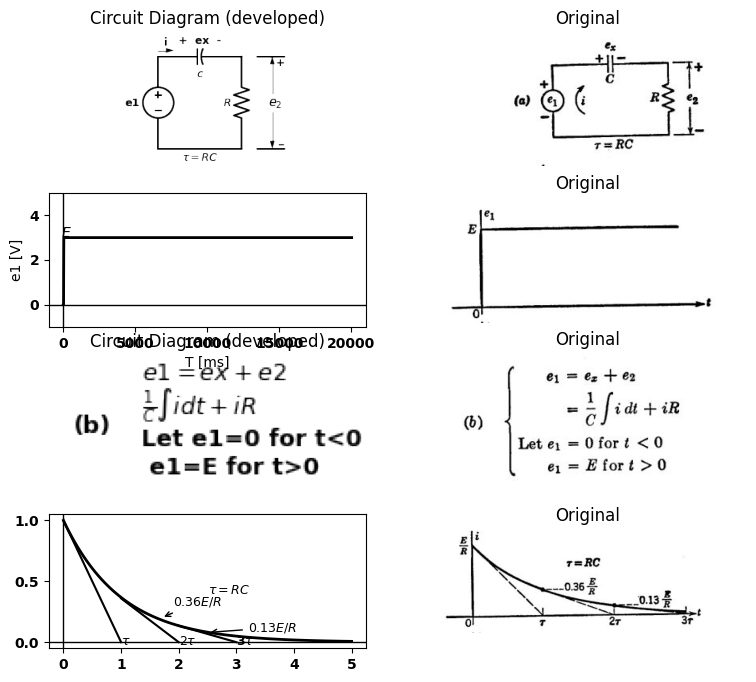

In [11]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(9, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$\tau=RC$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-4a1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-4a1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-5a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=20@u_ms, period=20@u_ms)
circuit.R(1 ,'1', '2', 1@u_Ohm )
circuit.C(1 ,'2', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['2'],'black',linewidth=2) 
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].text( 200, 3.2, '$E$', ha='center', va='center')
axs[1,0].set_ylim(-1, 5)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-5a1.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
l1 = d.add(elm.Line().right().length(.1).label('$e1=ex+e2$','right',color='black').color('white')) 
l2 = d.add(elm.Line().right().length(.1).label(r'$\frac{1}{C}\int{idt+iR}$','right',color='black').color('white').at((0,-.5)))
l3 = d.add(elm.Line().right().length(.1).label('Let e1=0 for t<0\n e1=E for t>0','right',color='black').color('white').at((0,-1.2)))
l4 = d.add(elm.Line().right().length(.1).at((-1,-.8)).label('(b)','right',color='black').color('white'))
d.save('images/8-5b-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-5b-1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-5b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
# 1
Eb = 1  
RC = 1  
t = np.linspace(0, 5, 100)   
x1 = np.array([0, 1])  
y1 = np.array([1, 0])  
x2 = np.array([1, 2])    
y2 = np.array([0.36, 0])   
x3 = np.array([2, 3])  
y3 = np.array([0.135, 0])  
v = Eb * np.exp(-t / RC)  
E1 = 0.35     
x = np.linspace(0, 0.7, 100)   
axs[3,0].plot(t, v / Eb, color='black', linewidth=2, label=r'$v$=$E_be^{-t/RC}$')  
axs[3,0].plot(x1, y1, color='black')  
axs[3,0].plot(x2, y2, color='black')  
axs[3,0].plot(x3, y3, color='black')   
 
axs[3,0].annotate(r'$\tau$', xy=(1, -0.02),   
             xytext=(1, -0.02),   
             #arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black')  
axs[3,0].annotate(r'$2\tau$', xy=(2, -0.02),   
             xytext=(2, -0.02),   
             #arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black') 
axs[3,0].annotate(r'3$\tau$', xy=(3, -0.02),   
             xytext=(3, -0.02),   
             #arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black') 
axs[3,0].annotate(r'$0.36E/R$', xy=(1.7, 0.2),   
             xytext=(1.9, 0.3),   
             arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black')  
axs[3,0].annotate(r'$0.13E/R$', xy=(2.5, 0.08),   
             xytext=(3.2, 0.09),   
             arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black') 
axs[3,0].annotate(r'$\tau=RC$', xy=(2.5, 0.4),   
             xytext=(2.5, 0.4),     
             fontsize=9, color='black')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1) 
img_sample = mpimg.imread('images/8-5b1.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')


Text(0.5, 1.0, 'Original')

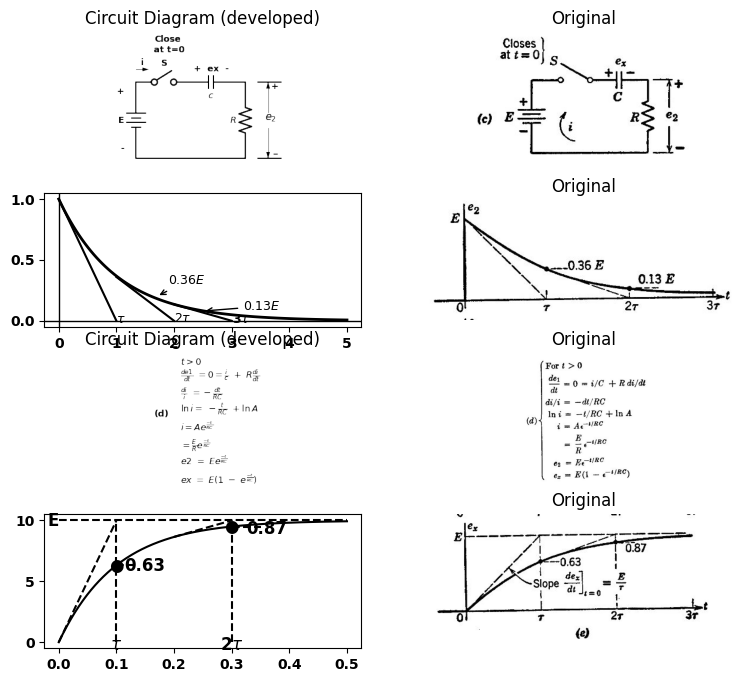

In [12]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(9, 8))
d = schemdraw.Drawing()
d += elm.Battery().down(d.unit*1).label(['+','','','E','','','-'], 'top') 
l1 = d.add(elm.Line().right(d.unit*.2).at((0,0)))
l2 = d.add(elm.Switch().right(d.unit*.2).label('S','top'))
d += (C1:=elm.Capacitor().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top').at(l2.end))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l3 = d.add(elm.Line().left(d.unit*1.43))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,0.5))
d += elm.Arrow().right().length(.5).linewidth(1).color('white').label('Close\n at t=0','top',color='black'). at((1,1))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((3.6,-2.7))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.2,-1.2))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((5.2,-1.8))
l2 = d.add(elm.Line().right(d.unit*.3).at((4.8,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((4.8,-3)))
d.save('images/8-5c-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-5c-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-5c.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
# 2
Eb = 1  
RC = 1  
t = np.linspace(0, 5, 100)   
x1 = np.array([0, 1])  
y1 = np.array([1, 0])  
x2 = np.array([1, 2])    
y2 = np.array([0.36, 0])   
x3 = np.array([2, 3])  
y3 = np.array([0.135, 0])  
v = Eb * np.exp(-t / RC)  
E1 = 0.35     
x = np.linspace(0, 0.7, 100)   
axs[1,0].plot(t, v / Eb, color='black', linewidth=2, label=r'$v$=$E_be^{-t/RC}$')  
axs[1,0].plot(x1, y1, color='black')  
axs[1,0].plot(x2, y2, color='black')  
axs[1,0].plot(x3, y3, color='black')   
 
axs[1,0].annotate(r'$\tau$', xy=(1, -0.02),   
             xytext=(1, -0.02),   
             #arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black')  
axs[1,0].annotate(r'$2\tau$', xy=(2, -0.01),   
             xytext=(2, -0.01),   
             #arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black') 
axs[1,0].annotate(r'3$\tau$', xy=(3, -0.02),   
             xytext=(3, -0.02),   
             #arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black') 
axs[1,0].annotate(r'$0.36E$', xy=(1.7, 0.2),   
             xytext=(1.9, 0.3),   
             arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black')  
axs[1,0].annotate(r'$0.13E$', xy=(2.5, 0.08),   
             xytext=(3.2, 0.09),   
             arrowprops=dict(facecolor='black', arrowstyle='->'),  
             fontsize=9, color='black') 
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1) 
img_sample = mpimg.imread('images/8-5c1.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
l1 = d.add(elm.Line().right().length(.1).label('$t>0$','right',color='black').color('white')) 
l2 = d.add(elm.Line().right().length(.1).label(r'$\frac{de1}{dt}\ =0=\frac{i}{c}\ +\ R\frac{di}{dt}$','right',color='black').color('white').at((0,-.5)))
l3 = d.add(elm.Line().right().length(.1).label(r'$\frac{di}{i}\ =-\frac{dt}{RC}$','right',color='black').color('white').at((0,-1.2)))
l4 = d.add(elm.Line().right().length(.1).label(r'$\ln{i=\ -\frac{t}{RC}}\ +\ln{A}$','right',color='black').color('white').at((0,-1.8)))
l5 = d.add(elm.Line().right().length(.1).label(r'$i=Ae^\frac{-t}{RC}$','right',color='black').color('white').at((0,-2.5)))
l6 = d.add(elm.Line().right().length(.1).label(r'$        =\frac{E}{R}e^\frac{-t}{RC}$','right',color='black').color('white').at((0,-3.2)))
l7 = d.add(elm.Line().right().length(.1).label(r'$e2\ =\ Ee^\frac{-t}{RC}$','right',color='black').color('white').at((0,-3.8)))
l8 = d.add(elm.Line().right().length(.1).label(r'$ex\ =\ E(1\ -\ e^\frac{-t}{RC})$','right',color='black').color('white').at((0,-4.5)))
l4 = d.add(elm.Line().right().length(.1).at((-1,-2)).label('(d)','right',color='black').color('white'))
d.save('images/8-5d-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-5d-1.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-5d.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

def capacitor_charge(time, voltage_source, resistance, capacitance):
  
    tau = resistance * capacitance
    return voltage_source * (1 - np.exp(-time / tau))

voltage_source = 10   
resistance = 1000   
capacitance = 0.0001 

time = np.linspace(0, 5 * resistance * capacitance, 500) 
voltage = capacitor_charge(time, voltage_source, resistance, capacitance)
axs[3,0].plot(time, voltage, label='Capacitor Voltage', color='black')
axs[3,0].text(-0.01, 10, 'E', fontsize=12, ha='center', va='center', color='black')
axs[3,0].text(0.1, 6.3, '●', fontsize=12, ha='center', va='center', color='black')
axs[3,0].text(0.15, 6.3, '0.63', fontsize=12, ha='center', va='center', color='black')
axs[3,0].text(0.3, 9.5, '●', fontsize=12, ha='center', va='center', color='black')
axs[3,0].text(0.36, 9.3, '0.87', fontsize=12, ha='center', va='center', color='black')
axs[3,0].text(0.1, -.2, r'$\tau$', fontsize=12, ha='center', va='center', color='black')
axs[3,0].text(0.3, -.2, r'2$\tau$', fontsize=12, ha='center', va='center', color='black')
#axs[3,0].xlabel('Time (s)') 
#axs[3,0].ylabel('ex (V)') 
axs[3,0].plot([0.1, 0.13], [6.3, 6.3], color='black', linestyle='--')
axs[3,0].plot([0, 0.1], [0, 10], color='black', linestyle='--')
axs[3,0].plot([.1, 0.1], [0, 10], color='black', linestyle='--')
axs[3,0].plot([0, 0.5], [10, 10], color='black', linestyle='--')
axs[3,0].plot([0.2, 0.3], [8.65, 10], color='black', linestyle='--')
axs[3,0].plot([.3, 0.3], [0, 10], color='black', linestyle='--')
axs[3,0].plot([.3, 0.35], [9.5, 9.5], color='black', linestyle='--')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-5e.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')


## Fig8.5 Step response of Series RC Circuit

follows that the total area under the waveform of $e₂$ is this value times $R:$ namely, $E\tau.$ With reference to the waveform of $e₂$ in part $(e)$, this means that half of the area under the $e₂$ curve is under the dotted line between $t = 0$ and $t = \tau$, while the remaining half is bounded by the waveform, the dotted line, and the horizontal axis. 
Since superposition applies to linear circuits, it is convenient to normalize the amplitude as well as the time scale. Thus, if we divide  all voltage and current values by $E$, the results are those that would be  


Text(0.5, 1.0, 'Original')

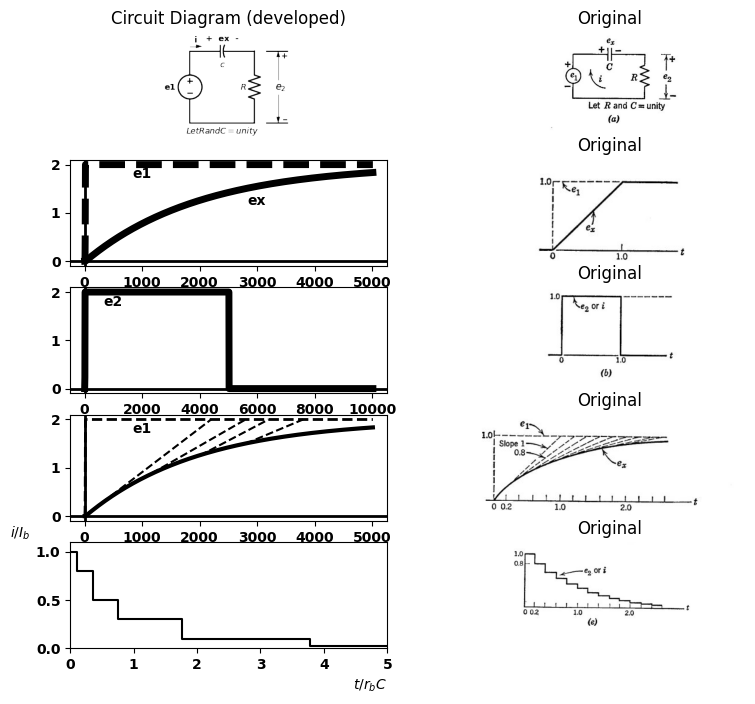

In [29]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(9, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$Let R and C= unity$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-6a-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-6a-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-6a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')  
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'2', circuit.gnd, 10@u_Ohm )
circuit.C(1 ,'1', '2', 200@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=5@u_ms)
axs[1,0].plot(analysis['1'],'black',linewidth=5,linestyle='--')
axs[1,0].plot(analysis['1']-analysis['2'],'black',linewidth=5)
axs[1,0].text( 1000, 1.8, 'e1', ha='center', va='center')
axs[1,0].text( 3000, 1.25, 'ex', ha='center', va='center')
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-6x.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'2', circuit.gnd, 10@u_Ohm )
circuit.C(1 ,'1', '2', 200@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
axs[2,0].plot(analysis['1'],'black',linewidth=5,linestyle='-')
axs[2,0].text( 1000, 1.8, 'e2', ha='center', va='center')
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-6b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'2', circuit.gnd, 10@u_Ohm )
circuit.C(1 ,'1', '2', 200@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=5@u_ms)
axs[3,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[3,0].plot([0, 2200], [0, 2], color='black', linestyle='--', label='Membership = 0.9')
axs[3,0].plot([1000, 2800], [.77, 2], color='black', linestyle='--', label='Membership = 0.9')
axs[3,0].plot([2000, 3200], [1.25, 2], color='black', linestyle='--', label='Membership = 0.9')
axs[3,0].plot([2800, 3800], [1.5, 2], color='black', linestyle='--', label='Membership = 0.9')
axs[3,0].plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[3,0].text( 1000, 1.8, 'e1', ha='center', va='center')
#ax1.text( 3000, 1.25, 'ex', ha='center', va='center')
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-6e1.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
t = np.linspace(0,10,100)
r0=3
rb=1
c = 0.5
x = t/(rb*c)
tA = 0.1
tB = 0.3
tC = 0.8
tD = 1.6
tE = 3.6
Eb = 4
Ib = Eb/rb
K = 0.5
y0 = 4/((2+x)**2)
y1 =np.where(x < tA, ((((4/((2+tA)**2)))-1)/tA)*x+1,np.where(x < tB, ((4/((2+tA)**2)-(4/((2+tB)**2)))/(tA-tB))*(x-tA)+((4/(2+tA)**2)),
            np.where(x < tC, ((4/((2+tB)**2)-(4/((2+tC)**2)))/(tB-tC))*(x-tB)+((4/(2+tB)**2)),
            np.where(x < tD, ((4/((2+tC)**2)-(4/((2+tD)**2)))/(tC-tD))*(x-tC)+((4/(2+tC)**2)),
            np.where(x < tE, ((4/((2+tD)**2)-(4/((2+tE)**2)))/(tD-tE))*(x-tD)+((4/(2+tD)**2)),((4/((2+tE)**2)-(4/((2+5)**2)))/(tE-5))*(x-tE)+((4/(2+tE)**2)))))))

x = np.linspace(0,1,20)
v = x*Eb
i = K*v**(3/2)
y1 = i/Ib
y2 = rb*x
XE = 0.1
XD = 0.3
XC = 0.5
XB = 0.7
XA = 0.9
y3 =np.where(x > XA,(K/Ib)*(Eb)**(3/2) ,np.where(x > XB,(K/Ib)*(0.8*Eb)**(3/2) ,
    np.where(x > XC,(K/Ib)*(0.6*Eb)**(3/2) ,np.where(x > XD,(K/Ib)*(0.4*Eb)**(3/2) ,
    np.where(x > XE,(K/Ib)*(0.2*Eb)**(3/2) ,(K/Ib)*(0.05*Eb)**(3/2))))))

XE = 3.8
XD = 1.8
XC = 0.8
XB = 0.4
XA = 0.15
Xt = t/rb*c
y4 = 8/(2+Xt)**3
y5 =np.where(Xt > XE,0.026,np.where(Xt > XD,0.1,
    np.where(Xt > XC,0.3,np.where(Xt > XB,0.5,
    np.where(Xt > XA,0.8,1)))))
#axs[4,0].plot(Xt, y4, color='black',linestyle='--', label=r'$i/I_b$=$8/(2+t/r_bc)^3$')
axs[4,0].step(Xt, y5, color='black', label=r'$slope$')
axs[4,0].set_ylim(0, 1.1)
axs[4,0].set_xlim(0, 5)
axs[4,0].set_xlabel(r'$t/r_bC$', loc='right')  
axs[4,0].set_ylabel(r'$i/I_b$',rotation=0,loc='top')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-6e.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

## Fig 8.6 Approximating the step response of the series RC circuit

obtained with a step of unit amplitude applied to the circuit. Then,  using a normalized time variable $(x=t/RC)$, we have initial slopes  equal to unity (or minus one), the area under $e₂$ equal to unity, and the  area under the current waveform equal to $1/R.$  
The step and ramp waveforms for individual elements (R and C)  given in Fig. 8.3(b) can be used to approximate the behavior of a circuit  such as the series RC circuit of $Fig. 8.6(a).$ For convenience, we shall  assume $R$ is $1$ ohm and $C$ is $1$ farad. Also, let the input step have  unit amplitude. 
 

The sketches in $Fig. 8.6(b)$ represent a very crude approximation to  the exponential curves. The upper sketch shows waveforms of $e1$  (dotted line) and $ex$ (solid line), whereas the second sketch shows $e₂$ or $i$.  Application of a unit step $e₁$ causes unit voltage $e₂$, since $ez$ cannot change  instantaneously unless there is an impulse of current (a finite charge  deposited on the capacitor by means of an infinite current lasting for  zero time). The unit voltage $e2$ causes unit current i. This current  
causes ex to increase with unit slope $(dex/dt = i/C)$. If this situation  
persists for unit time, the capacitor voltage reaches unity, the steady- state value, which corresponds to a steady-state current $i = 0.$ Thus  we are assuming a rectangular pulse of current $i$, which leads to the  ramp $ex.$ However, adding er to $e₂$ yields an input voltage which exceeds  the unit step by the ramp voltage $ez.$ This is obviously a very poor  representation of the step input. The pulse and ramp are equally poor  approximations to the desired exponentials. 


The waveforms shown in $Fig. 8.6(c)$ begin in the same fashion as those  in $(b),$ but persist only until $t = 0.5$ Now, since $e_{x} = 0.5$ $t = 0.5$ the  current i should correspondingly be reduced to $0.5$, since i  If this current persists for one time constant, $eX$ rises with slope $0.5$ and  reaches unity $t = 1.5$ The current waveform is still very crude, but  the integration has given $ez$ some semblance of realism. The waveforms  in $Fig. 8.6(d)$ and $(e)$ are more accurate approximations, obtained by  simple extension of the above techniques.  

# 8.7 Step, Ramp, and Pulse Waveforms 

The ramp waveform, like the step, is convenient to use in electronic  circuit analysis. As indicated in $Fig. 8.7(a)$ and $(b)$, the integral of a  step with an amplitude of $E$ volts is a ramp with a slope of E volts per  unit time. The impulse waveform indicated in $Fig. 8.7(c)$ can be regarded as the derivative of the step waveform. Since the step rises to  amplitude $E$ in zero time, the slope is infinite. Interpreting the impulse  as the derivative of the step requires that it have infinite amplitude for  zero time with an area equal to the step amplitude E. This is more readily visualized if we regard the step as the limiting case of a truncated  ramp with an amplitude $E.$ The sequence of waveforms in $Fig. 8.7 (d)$  indicates the trend of the pulse toward the impulse as the slope of the  

Text(0.5, 1.0, 'Original')

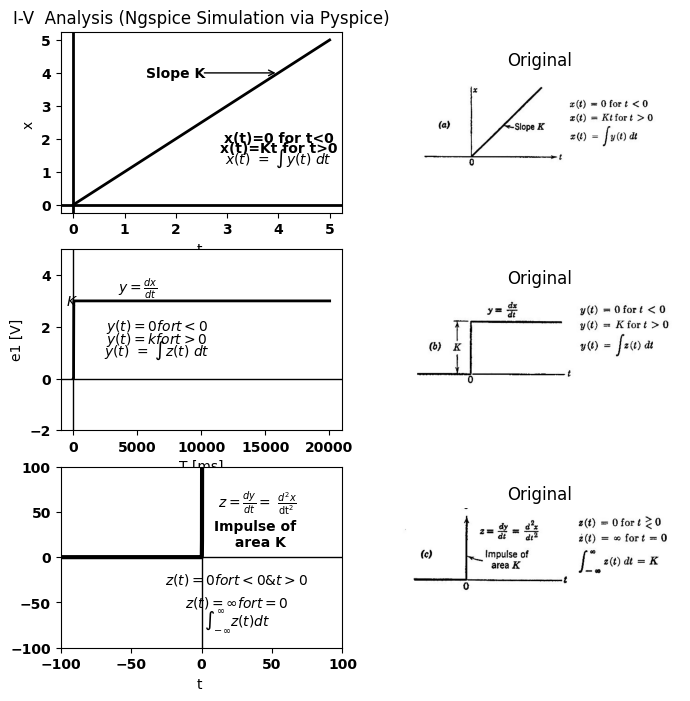

In [15]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(8, 8))

d = schemdraw.Drawing()
#
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', circuit.gnd, 1@u_Ohm )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))

axs[0,0].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=2)
axs[0,0].set_title('I-V  Analysis (Ngspice Simulation via Pyspice)')
axs[0,0].set_ylabel('x ')
axs[0,0].set_xlabel('t ')
axs[0,0].text( 2, 4, 'Slope K', ha='center', va='center')
axs[0,0].text( 4, 2, 'x(t)=0 for t<0', ha='center', va='center')
axs[0,0].text( 4, 1.7, 'x(t)=Kt for t>0', ha='center', va='center')
axs[0,0].text( 4, 1.4, r'$x(t)\ =\ \int{y(t)\ dt}$', ha='center', va='center')
axs[0,0].axhline(0, color='black', linewidth=2)
axs[0,0].axvline(0, color='black', linewidth=2)
axs[0,0].annotate('', xy=(4, 4), xytext=(2.5,4), arrowprops=dict(arrowstyle='->'))
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-7a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=20@u_ms, period=20@u_ms)
circuit.R(1 ,'1', '2', 1@u_Ohm )
circuit.C(1 ,'2', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['2'],'black',linewidth=2) 
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].text( 5000, 3.5, r'$y=\frac{dx}{dt}$', ha='center', va='center')
axs[1,0].text( -100, 3, '$K$', ha='center', va='center')
axs[1,0].text( 6500, 2, '$y(t)=0   for  t<0$', ha='center', va='center')
axs[1,0].text( 6500, 1.5, '$y(t)=k   for  t>0$', ha='center', va='center')
axs[1,0].text( 6500, 1.1, r'$y(t)\ =\ \int{z(t)\ dt}$', ha='center', va='center')
axs[1,0].set_ylim(-2, 5)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-7b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
# Create subplots
# circuit 2 
circuit = Circuit('Diode2')
circuit.model('BAV21','D' ,IS = 40@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.1@u_mV ,CJO = 7.048E-13 ,RS = 0.01@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1', circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-100, 100, 0.1))
axs[2,0].plot(analysis['1'],u_mA(-analysis.Vth), 'black', linewidth=3)
axs[2,0].set_xlim(-100, 100)
axs[2,0].set_xlabel('t ')
axs[2,0].text(40, 25, 'Impulse of \n area K', ha='center', va='center')
axs[2,0].text(40, 60, r'$z=\frac{dy}{dt}=\ \frac{d^2x}{{\rm dt}^2}$', ha='center', va='center')
axs[2,0].text( 25, -25, '$z(t)=0   for  t<0 & t>0$', ha='center', va='center')
axs[2,0].text( 25, -50, r'$z(t)=\infty   for  t=0$', ha='center', va='center')
axs[2,0].text( 25, -70, r'$\int_{-\infty}^{\infty}{z(t)dt}$', ha='center', va='center')
axs[2,0].set_ylim(-100, 100)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-7c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

Text(0.5, 1.0, 'Original')

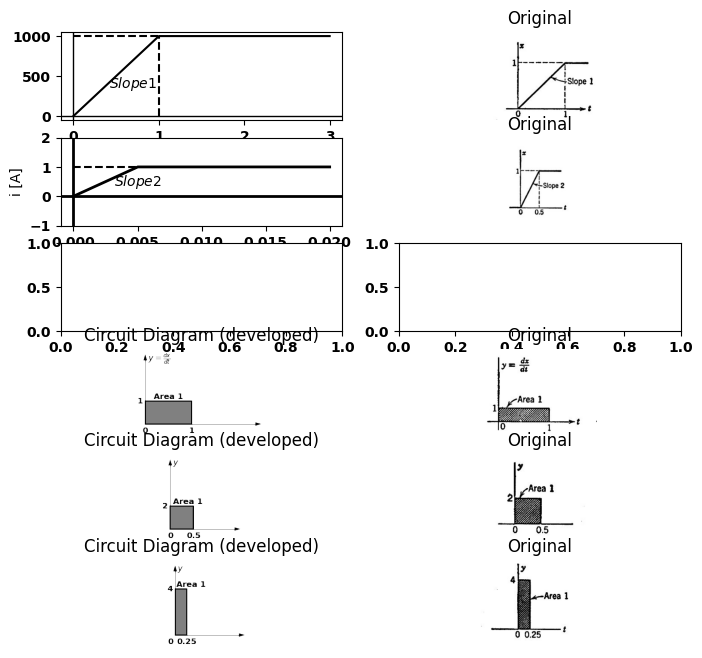

In [16]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from schemdraw import dsp
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(8, 8))

d = schemdraw.Drawing()
# Parameters
C = 1e-6  # Capacitance (Farads)
pulse_duration = 1e-3  # Pulse duration (seconds)
pulse_amplitude = 1.0 # Pulse amplitude (Amps)
simulation_time = 3 * pulse_duration  # Simulation time (seconds)
dt = 1e-6 # time step

# Time array
time = np.arange(0, simulation_time, dt)

# Input Pulse current
current = np.zeros_like(time)
current[(time >= 0) & (time < pulse_duration)] = pulse_amplitude

# Voltage calculation
voltage = np.zeros_like(time)
for i in range(1,len(time)):
    voltage[i] = voltage[i-1] + (1/C) * current[i] * dt

axs[0,0].plot(time*1000, voltage, color='black')
axs[0,0].plot([1, 1], [2, 1000], color='black', linestyle='--', label='Membership = 1')
axs[0,0].plot([0, 1], [1000, 1000], color='black', linestyle='--', label='Membership = 1')
axs[0,0].text( 0.7, 400, '$Slope 1$', ha='center', va='center')
axs[0,0].axhline(0, color='black', lw=1)
axs[0,0].axvline(0, color='black', lw=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/slope1.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += e.Arrow().up().length(3).linewidth(0.6).color('black')
d += e.Arrow().right().length(5).linewidth(0.6).color('black').at((0,0))
d += ( T := dsp.Box(w=2, h=1).anchor('W').fill('gray').label('Area 1','top').at((0,.5)))
l1 = d.add(e.Line().up().length(.2).at((0,0)).label('0','left'))
l2 = d.add(e.Line().up().length(.2).at((2,0)).label('1','left'))
l3 = d.add(e.Line().right().length(.2).at((0,1)).label('1','left'))
d += e.Arrow().up().length(.3).linewidth(0.6).color('black').at((0,2.70)).label(r'$ y=\frac{dx}{dt}$','bottom')
d.save('images/8-7-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-7-2.png')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/Area1.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original') 
d = schemdraw.Drawing()
d += e.Arrow().up().length(3).linewidth(0.6).color('black')
d += e.Arrow().right().length(3).linewidth(0.6).color('black').at((0,0))
d += ( T := dsp.Box(w=1, h=1).anchor('W').fill('gray').label('    Area 1','top').at((0,.5)))
l1 = d.add(e.Line().up().length(.2).at((0,0)).label('0','left'))
l2 = d.add(e.Line().up().length(.2).at((1,0)).label('0.5','left'))
l3 = d.add(e.Line().right().length(.2).at((0,1)).label('2','left'))
d += e.Arrow().up().length(.3).linewidth(0.6).color('black').at((0,2.70)).label('$ y$','bottom')
d.save('images/8-7-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-7-3.png')
axs[4,0].imshow(img)
axs[4,0].axis('off')  # Hide axes for image display
axs[4,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/Area2.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original') 
d = schemdraw.Drawing()
d += e.Arrow().up().length(3).linewidth(0.6).color('black')
d += e.Arrow().right().length(3).linewidth(0.6).color('black').at((0,0))
d += ( T := dsp.Box(w=0.5, h=2).anchor('W').fill('gray').label('       Area 1','top').at((0,1)))
l1 = d.add(e.Line().up().length(.2).at((0,0)).label('0   ','left'))
l2 = d.add(e.Line().up().length(.2).at((.5,0)).label('0.25','left'))
l3 = d.add(e.Line().right().length(.2).at((0,2)).label('4','left'))
d += e.Arrow().up().length(.3).linewidth(0.6).color('black').at((0,2.70)).label('$ y$','bottom')
d.save('images/8-7-4.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-7-4.png')
axs[5,0].imshow(img)
axs[5,0].axis('off')  # Hide axes for image display
axs[5,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/Area3.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original') 

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse2 = circuit.PulseVoltageSource('V2', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=1@u_V,rise_time=5@u_ms,fall_time=1@u_ps,pulse_width=15@u_ms, period=20@u_ms) 
circuit.R(1 ,'1', circuit.gnd, 2@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1') 
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('i [A]')
axs[1,0].text( 0.0050, .5, '$Slope 2$', ha='center', va='center')
#axs[1,0].plot([0, 0.005], [1, 1], color='black', linestyle='--', label='Membership = 1')
#axs[1,0].plot([0.005, 0.005], [1, 1], color='black', linestyle='--', label='Membership = 1')
#axs[1,0].plot([1, 1], [2, 1000], color='black', linestyle='--', label='Membership = 1')
axs[1,0].plot([0, 0.005], [1, 1], color='black', linestyle='--', label='Membership = 1')
axs[1,0].set_ylim(-1, 2)
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-7d2.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

## Fig8.7 Relation among step, ramp, and impulse waveforms

limited ramp approaches that of the step. The area of the pulse remains  constant and equal to the amplitude E of the ramp waveform as the  limiting process takes place. The impulse waveform is very useful in linear circuit analysis. In  analyzing an electronic circuit, we can replace a pulse of amplitude $E $ and duration $\delta$ by an impulse of area $E\delta$, provided the amplitude $E$ is    

Text(0.5, 1.0, 'Original')

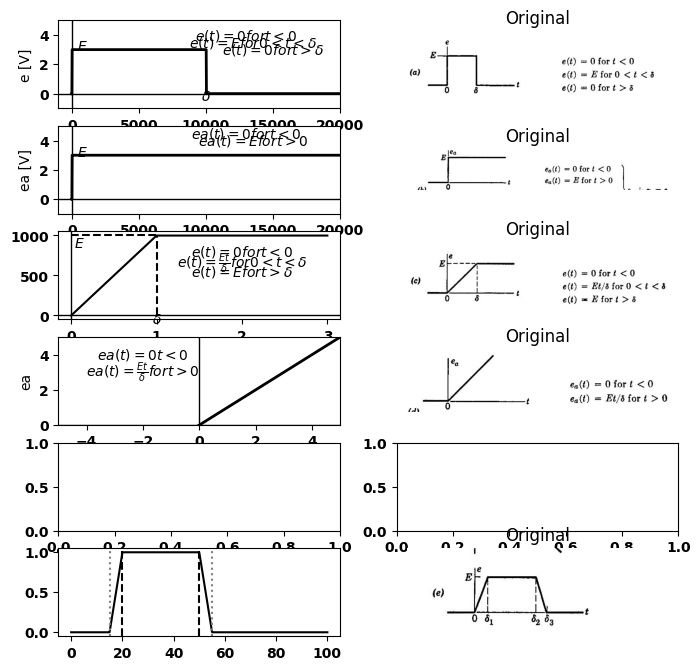

In [17]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as e
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(8, 8))

d = schemdraw.Drawing()
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.R(1 ,'1', '2', 1@u_Ohm )
circuit.C(1 ,'2', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[0,0].plot(analysis['2'],'black',linewidth=2) 
axs[0,0].set_xlabel('T [ms]')
axs[0,0].set_ylabel('e [V]')
axs[0,0].text( 800, 3.2, '$E$', ha='center', va='center')
axs[0,0].text( 10000, -.2, r'$\delta$', ha='center', va='center')
axs[0,0].text( 13000, 4, '$e(t)= 0 for  t<0 $', ha='center', va='center')
axs[0,0].text( 13500, 3.5, r'$e(t)= E for 0< t<\delta $', ha='center', va='center')
axs[0,0].text( 15000,3, r'$e(t)= 0 for  t> \delta $', ha='center', va='center')
axs[0,0].set_ylim(-1, 5)
axs[0,0].set_xlim(-1000, 20000)
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-8a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=20@u_ms, period=20@u_ms)
circuit.R(1 ,'1', '2', 1@u_Ohm )
circuit.C(1 ,'2', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['2'],'black',linewidth=2) 
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('ea [V]')
axs[1,0].text( 800, 3.2, '$E$', ha='center', va='center')
axs[1,0].text( 13000, 4.5, '$ea(t)= 0 for  t<0 $', ha='center', va='center')
axs[1,0].text( 13500, 4, r'$ea(t)= E for  t>0 $', ha='center', va='center')
axs[1,0].set_ylim(-1, 5)
axs[1,0].set_xlim(-1000, 20000)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-8b1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
# Parameters
C = 1e-6  # Capacitance (Farads)
pulse_duration = 1e-3  # Pulse duration (seconds)
pulse_amplitude = 1.0 # Pulse amplitude (Amps)
simulation_time = 3 * pulse_duration  # Simulation time (seconds)
dt = 1e-6 # time step

# Time array
time = np.arange(0, simulation_time, dt)

# Input Pulse current
current = np.zeros_like(time)
current[(time >= 0) & (time < pulse_duration)] = pulse_amplitude

# Voltage calculation
voltage = np.zeros_like(time)
for i in range(1,len(time)):
    voltage[i] = voltage[i-1] + (1/C) * current[i] * dt

axs[2,0].plot(time*1000, voltage, color='black')
axs[2,0].plot([1, 1], [2, 1000], color='black', linestyle='--', label='Membership = 1')
axs[2,0].plot([0, 1], [1000, 1000], color='black', linestyle='--', label='Membership = 1')
axs[2,0].text( 1,-50, '$\delta$', ha='center', va='center')
axs[2,0].text( .1,900, '$E$', ha='center', va='center')
axs[2,0].text( 2,800, '$e(t)= 0 for t<0$', ha='center', va='center')
axs[2,0].text( 2,650, r'$e(t)=\frac{Et}{\delta} for 0<t< \delta$', ha='center', va='center')
axs[2,0].text( 2,550, r'$e(t)=E for t>\delta $', ha='center', va='center')
axs[2,0].axhline(0, color='black', lw=1)
axs[2,0].axvline(0, color='black', lw=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-8c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', circuit.gnd, 1@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-5, 5, 0.1))
axs[3,0].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=2)
axs[3,0].set_xlim(-5, 5)
axs[3,0].set_xlabel('t ')
axs[3,0].set_ylabel('ea')
axs[3,0].set_ylim(0, 5)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
axs[3,0].text( -2, -4, 'i=v/ro', ha='center', va='center')
axs[3,0].text( -2, 4, '$ea(t) = 0 t<0$', ha='center', va='center')
axs[3,0].text( -2,3, r'$ea(t)=\frac{Et}{\delta} for t>0$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-8d1.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')


f_low = 20  
f_high = 50  
fs = 200  
transition_width = 5 

frequencies = np.linspace(0, fs / 2, 1000) 

H = np.zeros_like(frequencies)

start_transition_low = f_low - transition_width
end_transition_low = f_low
H[(frequencies >= start_transition_low) & (frequencies <= end_transition_low)] = \
    (frequencies[(frequencies >= start_transition_low) & (frequencies <= end_transition_low)] - start_transition_low) / transition_width

H[(frequencies >= f_low) & (frequencies <= f_high)] = 1

start_transition_high = f_high
end_transition_high = f_high + transition_width
H[(frequencies >= start_transition_high) & (frequencies <= end_transition_high)] = \
    1 - (frequencies[(frequencies >= start_transition_high) & (frequencies <= end_transition_high)] - start_transition_high) / transition_width

H = np.clip(H, 0, 1)

axs[5,0].plot(frequencies, H,  color="black")
axs[5,0].axvline(f_low, color="black", linestyle="--", label=r'$\delta 1$')
axs[5,0].axvline(f_high, color="black", linestyle="--", label=r'$\delta 2$')
axs[5,0].axvline(start_transition_low, color='gray', linestyle=':', label='0')
axs[5,0].axvline(end_transition_high, color='gray', linestyle=':', label=r'$\delta 3$')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-8e.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

## Fig 8.8 Composite Waveforme

such that the electronic device operates essentially linearly, and the  duration $\delta$ is small compared with the time constants associated with  the energy-storage elements.  
The pulse $e(t)$ shown in $Fig. 8.8(a)$ is an example of a composite  waveform, since it can be made up of a positive step $ea (t)$ and a negative step $es (t)$ delayed by the pulse duration $\delta$. The limited ramp is another  composite waveform. As shown by $(c)$ and $(d)$, it is equivalent to a  positive continuous ramp and a delayed negative ramp. Similarly,  the waveform given in $Fig. 8.8(e)$ can be composed of continuous  ramp functions. 


Text(0.5, 1.0, 'Original')

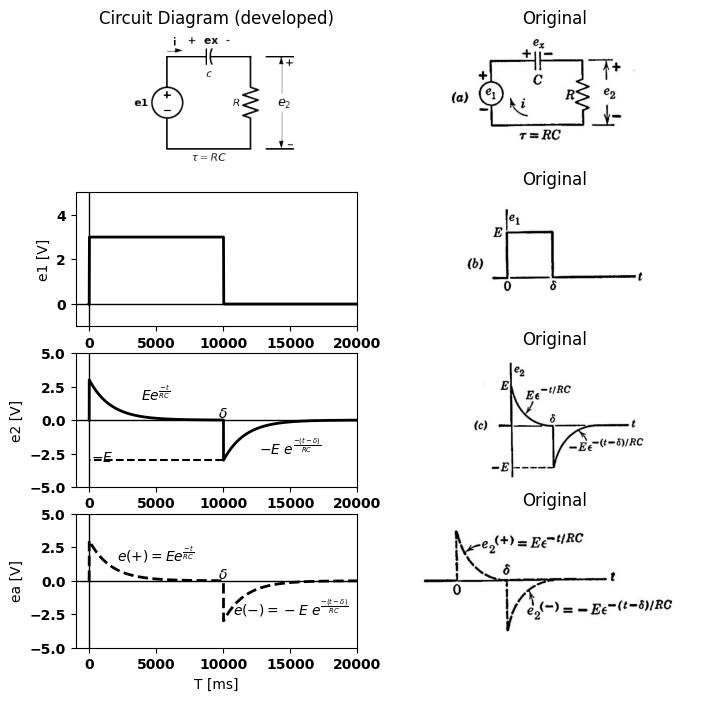

In [30]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$\tau=RC$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-9-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-9-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')  
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.R(1 ,'1', '2', 1@u_Ohm )
circuit.C(1 ,'2', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['2'],'black',linewidth=2) 
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].set_ylim(-1, 5)
axs[1,0].set_xlim(-1000, 20000)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9b1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.R(1 ,'2', circuit.gnd, 800@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[2,0].plot(analysis['2'],'black',linewidth=2) 
axs[2,0].set_xlabel('T [ms]')
axs[2,0].set_ylabel('e2 [V]')
axs[2,0].text( 15000, -2, r'$-E\ e^\frac{-(t-\delta)}{RC}$', ha='center', va='center')
axs[2,0].text( 5000, 2, r'$Ee^\frac{-t}{RC}$', ha='center', va='center')
axs[2,0].plot([10000, -3], [-3, -3], color='black', linestyle='--', label='Membership = 1')
axs[2,0].text( 1000,-2.8, '$-E$', ha='center', va='center')
axs[2,0].text( 10000, .5, r'$\delta$', ha='center', va='center')
axs[2,0].set_ylim(-5, 5)
axs[2,0].set_xlim(-1000, 20000)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9c1.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.R(1 ,'2', circuit.gnd, 800@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis['2'],'black',linewidth=2,linestyle='--') 
axs[3,0].set_xlabel('T [ms]')
axs[3,0].set_ylabel('ea [V]')
axs[3,0].text( 15000, -2, r'$e(-)=-E\ e^\frac{-(t-\delta)}{RC}$', ha='center', va='center')
axs[3,0].text( 5000, 2, r'$e(+)=Ee^\frac{-t}{RC}$', ha='center', va='center')
axs[3,0].text( 10000, .5, r'$\delta$', ha='center', va='center')
axs[3,0].set_ylim(-5, 5)
axs[3,0].set_xlim(-1000, 20000)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9c2.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig8.9 Response of a series RC circuit to a rectangular pulse having a duration δ mutch greater than the time canstance (δ >5RC)

# 8.8 Pulse Response of a Series RC Circuit  

Since superposition applies to linear circuits, the response of a given  circuit to a composite waveform can be expressed as the sum of the  responses to the basic elements of the driving waveform. Thus, if the  input voltage en for the circuit of $Fig. 8.9 (a)$ consists of a rectangular  pulse, we can use the results given in $Fig. 8.5(d) $and $(e)$ to find the   output voltage $e2$.  

The waveforms shown in $Fig. 8.9$ correspond to the case in which the  circuit time constant is much less than the duration of the input pulse,  hence the transient due to the positive step is "complete" before the de- layed negative step occurs. The capacitor voltage $E$ at $t = δ$ merely  

Text(0.5, 1.0, 'Original')

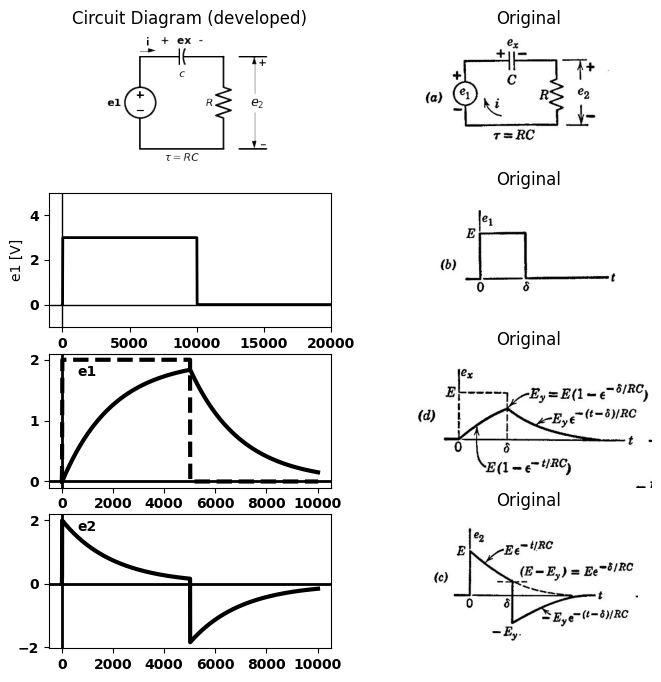

In [34]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$\tau=RC$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-9-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-9-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')  
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.R(1 ,'1', '2', 1@u_Ohm )
circuit.C(1 ,'2', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['2'],'black',linewidth=2) 
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].set_ylim(-1, 5)
axs[1,0].set_xlim(-1000, 20000)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9b1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'2', circuit.gnd, 10@u_Ohm )
circuit.C(1 ,'1', '2', 200@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
axs[2,0].plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[2,0].plot(analysis['1'],'black',linewidth=3,linestyle='--')
axs[2,0].text( 1000, 1.8, 'e1', ha='center', va='center')
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-10d.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'2', circuit.gnd, 10@u_Ohm )
circuit.C(1 ,'1', '2', 200@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
axs[3,0].plot(analysis['2'],'black',linewidth=3,linestyle='-')
axs[3,0].text( 1000, 1.8, 'e2', ha='center', va='center')
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-10c.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

### Fig. 8.10. Response of a series RC circuit to a rectangular pulse (δ < 5RC).  


shifts the zero level for the exponential resulting from the negative step.  The waveforms for $e1$, $e2$, and $ex$ are shown in composite form in $(b)$, $(c)$,  and $(d)$. The separate components resulting from individual step re- sponses are shown at the right of each waveform. The analytic expression for the composite of $e2$ is at every point equal to one component or  the other, since only one transient is in progress at any one time.  
When the pulse duration is insufficient to permit the first transient to  die out before the next one begins, the results are slightly more com- plicated. The waveforms for this case are shown in $Fig. 8.10.$ During 
the pulse, the expressions for e₂ and ex are the same as before. Numerical  values and the shapes of the waveforms differ from those of $Fig. 8.9$,  since the transients do not reach their final values. In general, the  value reached by the capacitor voltage at $t = δ$ is  


$ Ev\ =\ E\ (1-e^\frac{-\delta}{RC})$            $$(8.1)$$

At this point $e2$ is $(E-Ev)$. Fort greater than $δ$, the remaining portions  of the waveforms due to $e₁+$ subtract from those initiated at $t = δ$ by $e₁$.  Simple algebraic manipulations reduce the results of the summing opera- tion to the forms shown on the composite waveforms; that is, for $t$  greater than $δ$  

$ex\ =Ey\ e^\frac{-(t-\delta)}{RC}$    $$(8.2)$$

and

$e2\ =-Ey\ e^\frac{-(t-\delta)}{RC}$    $$(8.3)$$

The fact that $e2 = -ex$ for t greater than δ is immediately obvious, since  
$e1 = 0$ here. More important is the fact that the final expressions involve  only $E$ in the amplitude factor. Thus, for $t$ greater than $δ$, the wave- forms depend only on the capacitor voltage at $t = δ.$ If the source  voltage e₁ is nonzero for$ t$ greater than $δ,$ the waveforms will include  another term corresponding to the source voltage. Regardless of the  source applied for t greater than 8, the residual effects of anything that  transpired for $t$ less than $δ$ are all accounted for by the capacitor voltage  Eyatt $δ.$ We can thus conveniently use a new time reference for each  discrete section of a waveform. For the waveforms of $e₂$ and ex in 
$Fig. 8.10,$ we could express the voltage variations somewhat more simply  for t greater than 8 by counting time from $t = δ:$ in other words, replace  
$(t-δ)$ by $t'$ or simply by $t.$ The latter amounts to considering $δ = 0 $ 
in which case $δ$ disappears from the expressions. The numeric E, com- puted in the interval $0 < t < δ $is, of course, not subject to this modifica- tion. Although the dropping of one symbol may seem trivial here, the  extension of this idea to repetitive waveforms saves time and effort  during the course of a calculation.$ A$ delay factor can be reinserted in  the final result to refer to a specific time reference if desired.  


# 8.9 Ramp Response of a Series RC Circuit  

The series $RC$ circuit with a ramp input is shown in $Fig. 8.11$, and the  differential equation for the current is established in $(b).$ The solution  for the current is  

$i\ =\ KC\ (1-e^\frac{-t}{RC})$        $$(8.4 )$$

For $t≫ RC$, the current approaches $KC$, the value that would exist if the ramp were applied to the capacitance alone. Expressions for the  waveforms of voltages $e2$ and $e2$ follow immediately from the expression  for current, since $e₂$ equals $iR$ and $ex $equals $(e1 - e2)$. The $RC$ circuit  response to a limited ramp is shown in $Fig. 8.12$ for $δ$ greater than $5\tau$  andδ less than $5\tau$, where $\tau= RC$.  

Text(0.5, 1.0, 'Original')

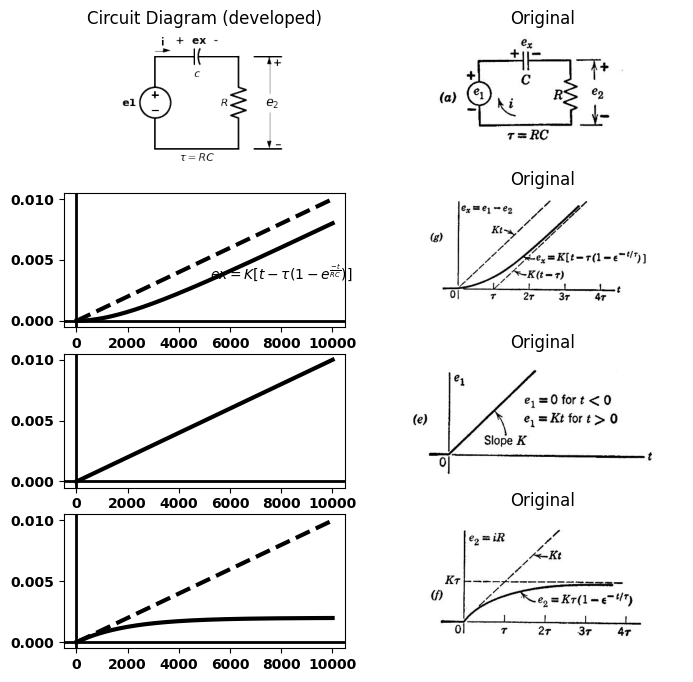

In [42]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$\tau=RC$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-9-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-9-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')  
circuit = Circuit('v-i curve')
#pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
pulse1= circuit.PieceWiseLinearVoltageSource(1, '1', circuit.gnd,
                                     values=[(0@u_s, 0@u_V),
                                             (1@u_ms, 1@u_V),
                                             (2@u_ms, 2@u_V),
                                             (3@u_ms, 3@u_V)]) #Ramp for 3ms
circuit.R(1 ,'2', circuit.gnd, 1@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_ns, end_time=10@u_us)
axs[1,0].plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[1,0].plot(analysis['1'],'black',linewidth=3,linestyle='--')
axs[1,0].text( 8000, 0.004, r'$ex=K[t-\tau(1-e^\frac{-t}{RC})]$', ha='center', va='center')
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-11g.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')  
circuit = Circuit('v-i curve')
#pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
pulse1= circuit.PieceWiseLinearVoltageSource(1, '1', circuit.gnd,
                                     values=[(0@u_s, 0@u_V),
                                             (1@u_ms, 1@u_V),
                                             (2@u_ms, 2@u_V),
                                             (3@u_ms, 3@u_V)]) #Ramp for 3ms
circuit.R(1 ,'2', circuit.gnd, 1@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_ns, end_time=10@u_us)
axs[2,0].plot(analysis['1'],'black',linewidth=3,linestyle='-')
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-11e.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')  
circuit = Circuit('v-i curve')
#pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
pulse1= circuit.PieceWiseLinearVoltageSource(1, '1', circuit.gnd,
                                     values=[(0@u_s, 0@u_V),
                                             (1@u_ms, 1@u_V),
                                             (2@u_ms, 2@u_V),
                                             (3@u_ms, 3@u_V)]) #Ramp for 3ms
circuit.R(1 ,'2', circuit.gnd, 1@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_ns, end_time=10@u_us)
axs[3,0].plot(analysis['2'],'black',linewidth=3,linestyle='-')
axs[3,0].plot(analysis['1'],'black',linewidth=3,linestyle='--')
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-11f.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original') 

# 8.10 Integration and Differentiation  of Excitation and Response Waveforms  

Differentiation of the expressions for e₁, i, e₂, and ez in Fig. 8.11 leads  to the expressions obtained for a step waveform of e₁ [Fig. 8.5(d)] if we  identify the constant K with the amplitude of the step. This calculation  is summarized in Fig. 8.13. Conversely, the ramp response waveforms  can be obtained directly from those for the step response by integrating  each of the expressions in Fig. 8.5.  
The generalization of this statement may be expressed as follows: If,  for a linear system, the response function for a given excitation function  


Text(0.5, 1.0, 'Original')

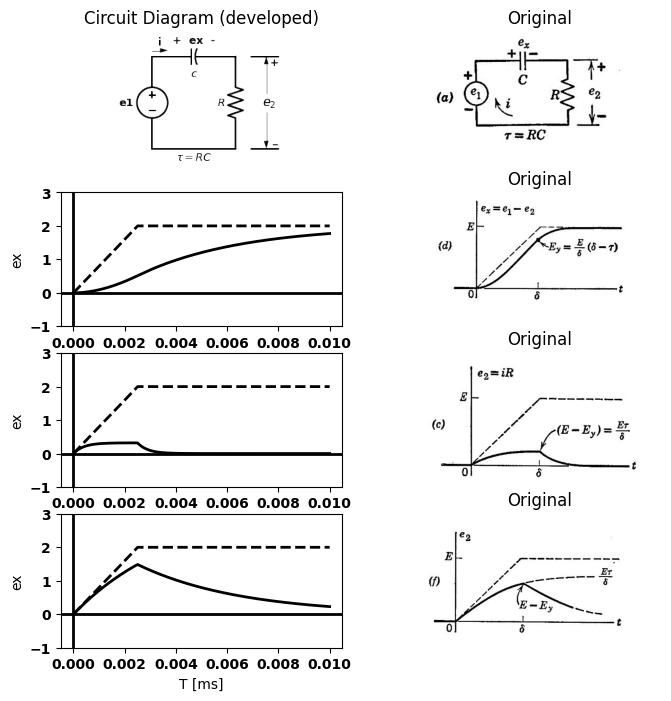

In [49]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$\tau=RC$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-9-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-9-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')  
logger = Logging.setup_logging()
circuit = Circuit('Pulse Sources ')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse2 = circuit.PulseVoltageSource('V2', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V,rise_time=2.5@u_ms,fall_time=1@u_ps,pulse_width=15@u_ms, period=20@u_ms) 
circuit.R(1 ,'2', circuit.gnd, 200@u_Ohm )
circuit.C(1 ,'1', '2', 20@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
axs[1,0].plot(analysis.time, analysis['1'], 'black', linewidth=2,linestyle='--', label='e 1') 
axs[1,0].plot(analysis.time, analysis['1']-analysis['2'], 'black', linewidth=2,linestyle='-', label='ex')
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('ex')
#ax.text( 0.0010, 3.2, '$I$', ha='center', va='center')
axs[1,0].set_ylim(-1, 3)
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-12e.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')  
logger = Logging.setup_logging()
circuit = Circuit('Pulse Sources ')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse2 = circuit.PulseVoltageSource('V2', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V,rise_time=2.5@u_ms,fall_time=1@u_ps,pulse_width=15@u_ms, period=20@u_ms) 
circuit.R(1 ,'2', circuit.gnd, 200@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
axs[2,0].plot(analysis.time, analysis['1'], 'black', linewidth=2,linestyle='--', label='e 1') 
axs[2,0].plot(analysis.time, analysis['2'], 'black', linewidth=2,linestyle='-', label='e2')
axs[2,0].set_xlabel('T [ms]')
axs[2,0].set_ylabel('ex')
#ax.text( 0.0010, 3.2, '$I$', ha='center', va='center')
axs[2,0].set_ylim(-1, 3)
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-12c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
logger = Logging.setup_logging()
circuit = Circuit('Pulse Sources ')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse2 = circuit.PulseVoltageSource('V2', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V,rise_time=2.5@u_ms,fall_time=1@u_ps,pulse_width=15@u_ms, period=20@u_ms) 
circuit.R(1 ,'2', circuit.gnd, 200@u_Ohm )
circuit.C(1 ,'1', '2', 20@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
axs[3,0].plot(analysis.time, analysis['1'], 'black', linewidth=2,linestyle='--', label='e 1') 
axs[3,0].plot(analysis.time, analysis['2'], 'black', linewidth=2,linestyle='-', label='e2')
axs[3,0].set_xlabel('T [ms]')
axs[3,0].set_ylabel('ex')
#ax.text( 0.0010, 3.2, '$I$', ha='center', va='center')
axs[3,0].set_ylim(-1, 3)
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-12f.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig. 8.12. Response of a series RC circuit to a limited ramp.  

is known, the integrals of each- or the derivatives of each-form addi- tional excitation-response pairs for that system. By mathematical  induction we see that the process can be repeated so that the 2nd, 3rd,  ..., nth integrals or derivatives also form excitation-response pairs of  the system. The validity of these statements is one of the many useful  consequences of linearity.  

# 8.11 Square-Wave Response of a  Linear Series RC Circuit  

The response of the series RC circuit to a step waveform led directly  to the response for a single pulse. This solution, in turn, can be extended 

Text(0.5, 1.0, 'Original')

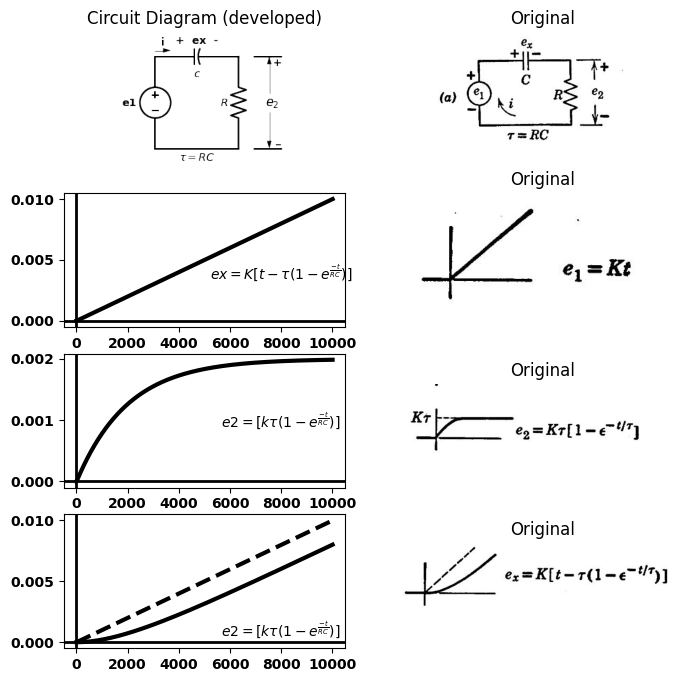

In [61]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$\tau=RC$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-9-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-9-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-9a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original') 
circuit = Circuit('v-i curve')
#pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
pulse1= circuit.PieceWiseLinearVoltageSource(1, '1', circuit.gnd,
                                     values=[(0@u_s, 0@u_V),
                                             (1@u_ms, 1@u_V),
                                             (2@u_ms, 2@u_V),
                                             (3@u_ms, 3@u_V)]) #Ramp for 3ms
circuit.R(1 ,'2', circuit.gnd, 1@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_ns, end_time=10@u_us)
#ax1.plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[1,0].plot(analysis['1'],'black',linewidth=3,linestyle='-')
axs[1,0].text( 8000, 0.004, r'$ex=K[t-\tau(1-e^\frac{-t}{RC})]$', ha='center', va='center')
axs[1,0].axhline(0, color='black', linewidth=2)
axs[1,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-13a.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original') 
circuit = Circuit('v-i curve')
#pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
pulse1= circuit.PieceWiseLinearVoltageSource(1, '1', circuit.gnd,
                                     values=[(0@u_s, 0@u_V),
                                             (1@u_ms, 1@u_V),
                                             (2@u_ms, 2@u_V),
                                             (3@u_ms, 3@u_V)]) #Ramp for 3ms
circuit.R(1 ,'2', circuit.gnd, 1@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_ns, end_time=10@u_us)
#ax1.plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[2,0].plot(analysis['2'],'black',linewidth=3,linestyle='-')
axs[2,0].text( 8000, 0.0010, r'$e2=[k\tau(1-e^\frac{-t}{RC})]$', ha='center', va='center')
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-13b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original') 
circuit = Circuit('v-i curve')
#pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
pulse1= circuit.PieceWiseLinearVoltageSource(1, '1', circuit.gnd,
                                     values=[(0@u_s, 0@u_V),
                                             (1@u_ms, 1@u_V),
                                             (2@u_ms, 2@u_V),
                                             (3@u_ms, 3@u_V)]) #Ramp for 3ms
circuit.R(1 ,'2', circuit.gnd, 1@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_ns, end_time=10@u_us)
axs[3,0].plot(analysis['1'],'black',linewidth=3,linestyle='--')
axs[3,0].plot(analysis['1']-analysis['2'],'black',linewidth=3,linestyle='-')
axs[3,0].text( 8000, 0.0010, r'$e2=[k\tau(1-e^\frac{-t}{RC})]$', ha='center', va='center')
axs[3,0].axhline(0, color='black', linewidth=2)
axs[3,0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-13c.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original') 

## Fig. 8.13. Relation between ramp and step response of a linear RC circuit.  

to the square wave. The circuit and the input waveform are shown in  Fig. 8.14(a). Let us assume that the square wave has been applied for  a long time prior to t = 0, so that steady-state conditions exist. Since  the average value of current i is zero, the average value of e₂ must be  Since the average value or direct component of e₁ is E/2, the  average value of ex must also be E/2. Let us now consider the character  of the waveforms of e₂ and ex for various values of the time constant. For the waveforms of ex and e2 shown in Fig. 8.14(b), the RC time  constant is chosen to be much less than 8, so that the transient goes  essentially to completion in each interval. The capacitor voltage can  not change at the instant of switching; therefore Δe₂ = Δe₁ = ±E at  the transitions of the square wave. As the time constant is made smaller,  relative to the interval 8, the waveform of ex approaches more closely  the waveform of e1, while e₂ approaches a succession of alternately posi- tive and negative spikes. Since these spikes have a finite amplitude E,  their area Er approaches zero as approaches zero. In the limit, there- fore, these spikes have a vanishingly small area.  
When the time constant  $\tau$ is comparable to the interval d, neither the  charge nor the discharge of the capacitor goes to completion. The  waveforms shown in Fig. 8.14(c) have been drawn for $\tau$  less than 7 , the  actual value being δ ≈ 0.7$\tau$. In this case the capacitor charges toward 
 

Text(0.5, 1.0, 'Original')

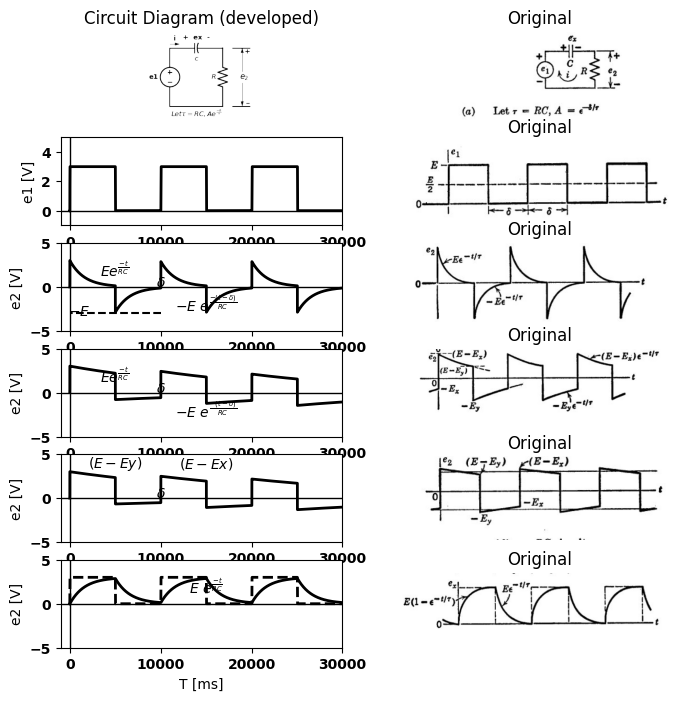

In [62]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e1', 'top') 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$Let \tau=RC, Ae^\frac{-\delta}{\tau}$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at((3.2,0)))
l3 = d.add(elm.Line().right(d.unit*.3).at((3.2,3)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.1,0.2))
d += elm.Arrow().up().length(1.2).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.7,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('i','top'). at((0,3.2))
d.save('images/8-9-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-9-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-14a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')  
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1 ,'1', '2', 1@u_Ohm )
circuit.C(1 ,'2', circuit.gnd, 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[1,0].plot(analysis['2'],'black',linewidth=2) 
axs[1,0].set_xlabel('T [ms]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].set_ylim(-1, 5)
axs[1,0].set_xlim(-1000, 30000)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-14a1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 800@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[2,0].plot(analysis['2'],'black',linewidth=2) 
axs[2,0].set_xlabel('T [ms]')
axs[2,0].set_ylabel('e2 [V]')
axs[2,0].text( 15000, -2, r'$-E\ e^\frac{-(t-\delta)}{RC}$', ha='center', va='center')
axs[2,0].text( 5000, 2, r'$Ee^\frac{-t}{RC}$', ha='center', va='center')
axs[2,0].plot([10000, -3], [-3, -3], color='black', linestyle='--', label='Membership = 1')
axs[2,0].text( 1000,-2.8, '$-E$', ha='center', va='center')
axs[2,0].text( 10000, .5, r'$\delta$', ha='center', va='center')
axs[2,0].set_ylim(-5, 5)
axs[2,0].set_xlim(-1000, 30000)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-14b2.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 8000@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[3,0].plot(analysis['2'],'black',linewidth=2) 
axs[3,0].set_xlabel('T [ms]')
axs[3,0].set_ylabel('e2 [V]')
axs[3,0].text( 15000, -2, r'$-E\ e^\frac{-(t-\delta)}{RC}$', ha='center', va='center')
axs[3,0].text( 5000, 2, r'$Ee^\frac{-t}{RC}$', ha='center', va='center')
#axs[3,0].plot([10000, -3], [-3, -3], color='black', linestyle='--', label='Membership = 1')
#axs[3,0].text( 1000,-2.8, '$-E$', ha='center', va='center')
axs[3,0].text( 10000, .5, r'$\delta$', ha='center', va='center')
axs[3,0].set_ylim(-5, 5)
axs[3,0].set_xlim(-1000, 30000)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-14d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 10000@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[4,0].plot(analysis['2'],'black',linewidth=2) 
axs[4,0].set_xlabel('T [ms]')
axs[4,0].set_ylabel('e2 [V]')
axs[4,0].text( 5000, 4, r'$(E -Ey)$', ha='center', va='center')
axs[4,0].text( 15000, 4, r'$(E - Ex)$', ha='center', va='center')
#axs[3,0].plot([10000, -3], [-3, -3], color='black', linestyle='--', label='Membership = 1')
#axs[3,0].text( 1000,-2.8, '$-E$', ha='center', va='center')
axs[4,0].text( 10000, .5, r'$\delta$', ha='center', va='center')
axs[4,0].set_ylim(-5, 5)
axs[4,0].set_xlim(-1000, 30000)
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-14d2.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 800@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[5,0].plot(analysis['1']-analysis['2'],'black',linewidth=2) 
axs[5,0].plot(analysis['1'],'black',linewidth=2, linestyle='--') 
axs[5,0].set_xlabel('T [ms]')
axs[5,0].set_ylabel('e2 [V]')
axs[5,0].text( 15000, 2, r'$E\ e^\frac{-t}{RC}$', ha='center', va='center')
#axs[2,0].text( 5000, 2, r'$Ee^\frac{-t}{RC}$', ha='center', va='center')
#axs[2,0].plot([10000, -3], [-3, -3], color='black', linestyle='--', label='Membership = 1')
#axs[2,0].text( 1000,-2.8, '$-E$', ha='center', va='center')
#axs[2,0].text( 10000, .5, r'$\delta$', ha='center', va='center')
axs[5,0].set_ylim(-5, 5)
axs[5,0].set_xlim(-1000, 30000)
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-14b3.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

## Fig. 8.14. Square-wave response of linear RC circuit.  

E, but reaches only the value Ey. It then discharges toward zero, but  falls only as low as Ex. With t = 0 taken at the beginning of a discharge  interval, the expression for capacitor voltage during that interval is  

$ex\ =Ey\ e^\frac{-t}{\tau} $   $$(8.5)$$

The final value at $t=\delta$

$Ex\ =Ey\ e^\frac{-\delta}{\tau} $   $$(8.6)$$

$Ex=AEy$   $$(8.7)$$

Where $A\ =\ e^\frac{-t}{\tau}$  $$(8.8)$$

If we now take t = 0 at the beginning of the charge interval, the expres- sion for the capacitor voltage during charge is  

$ex\ =E-(E-Ex)\ e^\frac{-t}{\tau}$   $$(8.9)$$

or

$E-ex=(E-Ex)\ e^\frac{-t}{\tau}$   $$(8.10)$$

At the end of the charge interval, ex=Ey, so that $Eq.8.10$ becomes

$E-Ey= A(E-Ex)$ $$(8.11)$$

Solving Eqs.8.7 and 8.11 simultaneously We obtain

$Ey=\frac{E}{1+A}$ $$(8.12)$$

$Ex=\frac{AE}{1+A}$ $$(8.13)$$

If We express Ey as $\frac{E}{2}+∆1$ and Ex as  $\frac{E}{2}-∆2$ We find,

$∆1=∆2=\frac {E(1-A)}{(1+A)}$  $$(8.14)$$

Thus the peak-to-peak Amplitude of the variation in ex is

$∆ex=Ey-Ex=\frac {E(1-A)}{(1+A)}$  $$(8.15)$$

The sum of Ey, and Ex is the input amplitude E, and the average of Ey  and Ex is E/2. Since the exponentials have the same time constant and  consequently the same form in the charge and discharge intervals, E/2  is also the time average of ex.  
An exponential is completely specified by the time constant and the  values at two known instants of time. Hence, the waveform of e₂ in  Fig. 8.14 (c) is completely determined once the values of E, and Ex have  been found, since these together with the input waveform-fix the  initial and final values of e2 in each interval.  
If RC is increased so that ٫r further decreases, the waveforms of ex  and ez tend toward the shapes indicated in Fig. 8.14(d). The constant  A approaches unity, both E and E, approach E/2; and the exponential  variations become nearly linear. The waveform of ez therefore approxi- mates a triangular wave. For small values of$\frac{\delta}{\tau}$ , the constant A  can be approximated by $(1 -\frac{\delta}{\tau})$. Substitution of this value into the  expressions in Fig. 8.14(c) yields the approximate expressions given in  (d). The peak-to-peak amplitude of capacitor voltage is approximately  $\frac{E\delta}{2\tau}$ in this case. The waveform of ez is nearly a reproduction of e1,  since the input waveform en is closely coupled to the output. However,  there is a change in average value or direct component. The direct  component of e₁ appears across the capacitor. 


# 8.12 Rectangular-Wave Response  of Piecewise-Linear Circuits  

The considerations in Article 8.11 imply no reasons for restrict- ing the intervals for capacitor charge and discharge to equal values.  Also, since the interval $\delta$ and the time constant $\tau $enter the waveform  expressions only as the ratio $\frac{t}{\tau}$, the time constant need not have the  same value during the charge and discharge intervals. Finally, there is  no reason to impose any restrictions on the direct component of the  input waveform. It follows that the previous analysis can be extended  to the circuit and input waveform shown in Fig. 8.15(a). The source e1  can be envisioned as a switch that alternately applies the constant  voltages E₁ and E₂ to the circuit for the intervals $\delta1$ and $\delta2$, respectively.  The polarity of e₂ (or the direction of current flow) determines which  diode conducts, and therefore determines the time constant for charge  or discharge. The resistances R₁ and R2, together with the two ideal  rectifiers, might represent a piecewise-linear approximation to a semi- conductor diode curve or similar nonlinear resistance.  
For the input waveform shown, the circuit of Fig. 8.15(a) can be  represented as in (b) during the interval $\delta2$, and as in (c) during the  interval $\delta1$. Since these circuits differ in no respect from the linear circuit  already analyzed, we can postulate the general shape of the waveforms  of e2 and ex to be similar to those given in Fig. 8.14(c). We are consider- ing here the most general case: the one for which the exponential tran- 

sients do not reach completion in their respective intervals, thus Ey, and  Ex are unknowns. The exponential expressions for ex are given in (b)  and (c). Using the methods of Article 11, we find the expressions for   capacitor voltage at the transitions to be  


$Ex=E1 + \frac{EA1(1 - A2)}{1- A1A2}$ $$(8.16)$$

$Ey=E1 + \frac{E(1 - A2)}{1- A1A2}$ $$(8.17)$$

As before, the end points of the waveform are fixed when $Ey$, and $Ex$ are known. The upward and downward jumps in$ e₂ $are the same as the  jumps in $e₁.$ Between initial and final values, the exponential variation   

Text(0.5, 1.0, 'Original')

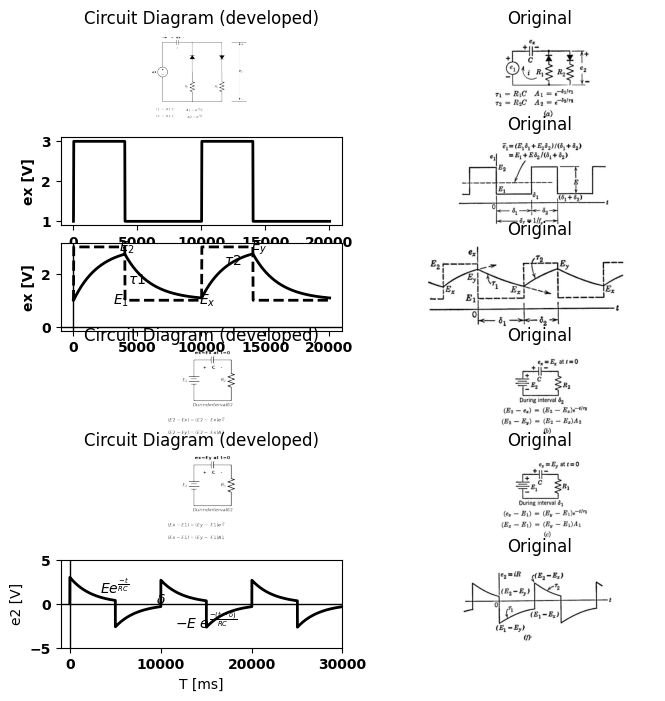

In [63]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*2).label('e1', 'top') 
d += (C1:=elm.Capacitor().right(d.unit*1).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (D1 := elm.Diode(fill= True).down().reverse())
d += (R1 := elm.Resistor().down().label('$R_1$', 'top'))
l1 = d.add(elm.Line().left())
l2 = d.add(elm.Line().right().at(D1.start))
d += (D2 := elm.Diode(fill= True).down())
d += (R2 := elm.Resistor().down().label('$R_2$', 'top'))
l3 = d.add(elm.Line().left())
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6.2,1.8))
d += elm.Arrow().up().length(2.7).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((7.8,3.3))
d += elm.Arrow().down().length(2.7).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((7.8,2.8))
d += elm.Line().right().length(1.5).at((7,0)).color('black')
d += elm.Line().right().length(1.5).at((7,6)).color('black')
d += elm.Line().right().length(.5).at((0,-.5)).color('white').label(r'$\tau1\ =\ R1\ C$','bottom',color='black')
d += elm.Line().right().length(.5).at((0,-1.2)).color('white').label(r'$\tau2\ =\ R2\ C$','bottom',color='black')
d += elm.Line().right().length(.5).at((3,-.5)).color('white').label(r'$A1=e^\frac{-\delta1}{-\tau1} C$','bottom',color='black')
d += elm.Line().right().length(.5).at((3,-1.2)).color('white').label(r'$A2=e^\frac{-\delta2}{-\tau2}$','bottom',color='black')
d += elm.Arrow().right().length(.5).color('black').label('$i$', loc='top', color='black'). at((0,6.5))
d.save('images/8-15-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-15-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-15a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')  
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=3@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 1000@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['1'],'black',linewidth=2, label='ex') 
axs[1,0].set_ylabel('ex [V]', color='black', weight='black', fontsize=10)

#axs[1,0].plot(analysis['1']-analysis['2'], 'black', linewidth=2, label='ex')
#ax1.text(12500, 2.5, r'$\tau2$', ha='center', va='center')
ax1.axhline(0, color='black', linewidth=1)
ax1.axvline(0, color='black', linewidth=1)
#ax1.text(5000, 1.8, r'$\tau1$', ha='center', va='center')
ax1.text(3750, 1, '$E_1$', ha='center', va='center')
ax1.text(4200, 3, '$E_2$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-15a1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=3@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 1000@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[2,0].plot(analysis['1'],'black',linewidth=2, linestyle='--', label='ex') 
axs[2,0].set_ylabel('ex [V]', color='black', weight='black', fontsize=10)

axs[2,0].plot(analysis['1']-analysis['2'], 'black', linewidth=2, label='ex')
axs[2,0].text(12500, 2.5, r'$\tau2$', ha='center', va='center')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
axs[2,0].text(5000, 1.8, r'$\tau1$', ha='center', va='center')
axs[2,0].text(3750, 1, '$E_1$', ha='center', va='center')
axs[2,0].text(4200, 3, '$E_2$', ha='center', va='center')
axs[2,0].text(10500, 1, '$E_x$', ha='center', va='center')
axs[2,0].text(14500, 3, '$E_y$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-15b1.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.Battery().up(d.unit*1).label('$E_2$', 'top').reverse() 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('+   C   -','bottom').label(' ex=Ex at t=0 ','top'))
d += (R1 := elm.Resistor().down().label('$R_2$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$Durind interval \delta2$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.1).at((0,-1)).label(r'$(E2-Ex)=(E2-\ Ex)e^\frac{-t}{\tau2}$','bottom',color='black').color('white'))
l3 = d.add(elm.Line().right(d.unit*.1).at((0,-2)).label(r'$(E2-Ey)=(E2-\ Ex)A2$','bottom',color='black').color('white'))
d.save('images/8-15-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-15-2.png')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')   
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-15b.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')  
d = schemdraw.Drawing()
d += elm.Battery().up(d.unit*1).label('$E_2$', 'top').reverse() 
d += (C1:=elm.Capacitor2().right(d.unit*0.9).color('black').label('+   C   -','bottom').label(' ex=Ey at t=0 ','top'))
d += (R1 := elm.Resistor().down().label('$R_1$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9).label(r'$Durind interval \delta2$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.1).at((0,-1)).label(r'$(Ex-E1)=(Ey-\ E1)e^\frac{-t}{\tau1}$','bottom',color='black').color('white'))
l3 = d.add(elm.Line().right(d.unit*.1).at((0,-2)).label(r'$(Ex-E1)=(Ey-\ E1)A1$','bottom',color='black').color('white'))
d.save('images/8-15-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-15-3.png')
axs[4,0].imshow(img)
axs[4,0].axis('off')  # Hide axes for image display
axs[4,0].set_title('Circuit Diagram (developed)')   
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-15c.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')  
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 1200@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[5,0].plot(analysis['2'],'black',linewidth=2) 
axs[5,0].set_xlabel('T [ms]')
axs[5,0].set_ylabel('e2 [V]')
axs[5,0].text( 15000, -2, r'$-E\ e^\frac{-(t-\delta)}{RC}$', ha='center', va='center')
axs[5,0].text( 5000, 2, r'$Ee^\frac{-t}{RC}$', ha='center', va='center')
axs[5,0].text( 10000, .5, r'$\delta$', ha='center', va='center')
axs[5,0].set_ylim(-5, 5)
axs[5,0].set_xlim(-1000, 30000)
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-15f.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

$ (d)\ \ \ Ex\ =\ \frac{E2A1(1-A2)+E1(1-A1)}{1-A1A2}\ =\ E1\ +\ \frac{EA1(1-A2)}{1-A1A2}$




$ \ \ \ Ey\ =\ \frac{E2(1-A2)+E1A2(1-A1)}{1-A1A2}\ =\ E1\ +\ \frac{E(1-A2)}{1-A1A2}$




$ \ \ \ e2`\ =\ \frac{C(Ey-Ex)R2-C(Ey-Ex)R1}{\delta1 +\delta2}\ =\ C(Ey-Ex)(R2 -R1)fr$



$\bar{ex} = \bar{e1} - \bar{e2}$

## Fig. 8.15. Rectangular-wave response of a piecewise-linear RC circuit.  

is in accordance with the appropriate time constant ($\tau₁$ during δ₁ and  $\tau2$ during  δ2). The average current through the capacitor must still be zero. However, there is no longer any restriction on the average value of the output  voltage e2, which now is   


$\bar{e}2\ =\ \frac{1}{\delta r}\ \left[\int_{0}^{\delta1}{i.R1.dt\ +\ \int_{\delta1}^{\delta1+\delta2}{i.R2.dt}}\right]$ $$(8.18)$$

$But$

$\int_{0}^{\delta1}{i.R1}.dt\ =∆Q(discharge) = C(Ex -Ey)$    $$(8.18a)$$

$\int_{0}^{\delta1+\delta2}{i.R1}.dt\ =∆Q(discharge) = C(Ey -Ex)$    $$(8.18b)$$

$Substituting Eqs 8.18a and 8.18b  in Eq.8.18:$

$\bar{e}2 = fr(R2 - R1)(Ey -Ex)C$     $$(8.19)$$

Since E, is greater than Ez, this average value will be positive for R2 greater than R₁ and negative for R₂ less than R1.The calculations outlined in Fig. 8.15 can be simplified for the special  cases in which either or both exponential transients essentially reach  completion. The function $ e^\frac{-t}{\tau}$ is unity at t = 0 and 0.006 at $t = 5\tau$  Thus we can consider the transient to be essentially complete after an  interval of five time constants. Waveforms for three examples are  shown in Fig. 8.16. When $\delta_{1} / \tau_{1}$ > 5 as in Fig. 8.16 (b), we have Ex = E1  and, hence, Ex is known immediately. The value of E, can then be  determined directly from the charge interval. Similarly, when $\delta_{2}$ / $\tau_{2}$ > 5  as in Fig. 8.16 (c), we have E E2 and, hence, E, is known, and Ex can  be determined easily. For the waveforms of Fig. 8.16(d), $\delta_{1}$ / $\tau_{1}$ > 5 and  $\delta_{2}$ / $\tau_{2}$ > 5 hence the initial and final values for both intervals are known,  and the exponentials can be sketched directly by using the known end   points and the known time constants.

# 8.13 Other Simple RC and RL Circuits  

The results of the foregoing analyses can be extended to any RC circuit  that can be reduced to the same form by means of Thevenin's theorem  or other network transformations. Since piecewise-linear circuit models  are linear within a given state of the ideal rectifiers, these methods of  linear circuit analysis can also be applied to the individual states of  piecewise-linear circuits. For example, the previous results can be  applied to any circuit which includes one linear capacitor and any  number of linear or two-segment piecewise-linear resistances. Alternatively, the circuit may include one such resistance and any number of  

Text(0.5, 1.0, 'Original')

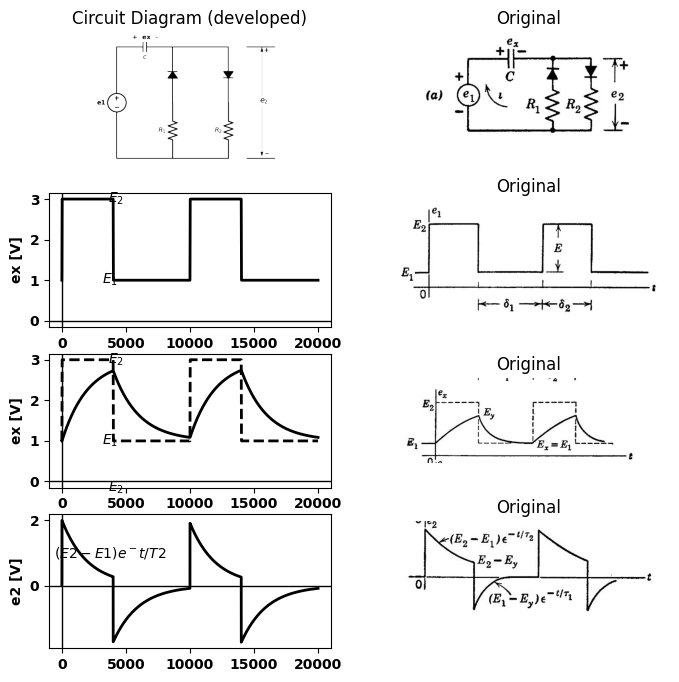

In [4]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*2).label('e1', 'top') 
d += (C1:=elm.Capacitor().right(d.unit*1).color('black').label('$c$','bottom').label('+  ex  -','top'))
d += (D1 := elm.Diode(fill= True).down().reverse())
d += (R1 := elm.Resistor().down().label('$R_1$', 'top'))
l1 = d.add(elm.Line().left())
l2 = d.add(elm.Line().right().at(D1.start))
d += (D2 := elm.Diode(fill= True).down())
d += (R2 := elm.Resistor().down().label('$R_2$', 'top'))
l3 = d.add(elm.Line().left())
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6.2,1.8))
d += elm.Arrow().up().length(2.7).linewidth(.6).color('black').label('+',loc='end', color='black',ofst=-.1). at((7.8,3.3))
d += elm.Arrow().down().length(2.7).linewidth(.6).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((7.8,2.8))
d += elm.Line().right().length(1.5).at((7,0)).color('black')
d += elm.Line().right().length(1.5).at((7,6)).color('black')
d.save('images/8-16-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-16-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-16.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original') 
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=3@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 1000@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['1'],'black',linewidth=2, label='ex') 
axs[1,0].set_ylabel('ex [V]', color='black', weight='black', fontsize=10)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
#ax1.text(5000, 1.8, r'$\tau1$', ha='center', va='center')
axs[1,0].text(3750, 1, '$E_1$', ha='center', va='center')
axs[1,0].text(4200, 3, '$E_2$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-16a1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=3@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 1000@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[2,0].plot(analysis['1'],'black',linewidth=2, linestyle='--', label='ex') 
axs[2,0].plot(analysis['1']-analysis['2'],'black',linewidth=2, label='ex') 
axs[2,0].set_ylabel('ex [V]', color='black', weight='black', fontsize=10)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
#ax1.text(5000, 1.8, r'$\tau1$', ha='center', va='center')
axs[2,0].text(3750, 1, '$E_1$', ha='center', va='center')
axs[2,0].text(4200, 3, '$E_2$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-16b1.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=3@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 1000@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis['2'],'black',linewidth=2, linestyle='-', label='e2') 
axs[3,0].set_ylabel('e2 [V]', color='black', weight='black', fontsize=10)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
axs[3,0].text(3750, 1, '$(E2-E1)e^-t/T2$', ha='center', va='center')
axs[3,0].text(4200, 3, '$E_2$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-16b2.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

Text(0.5, 1.0, 'Original')

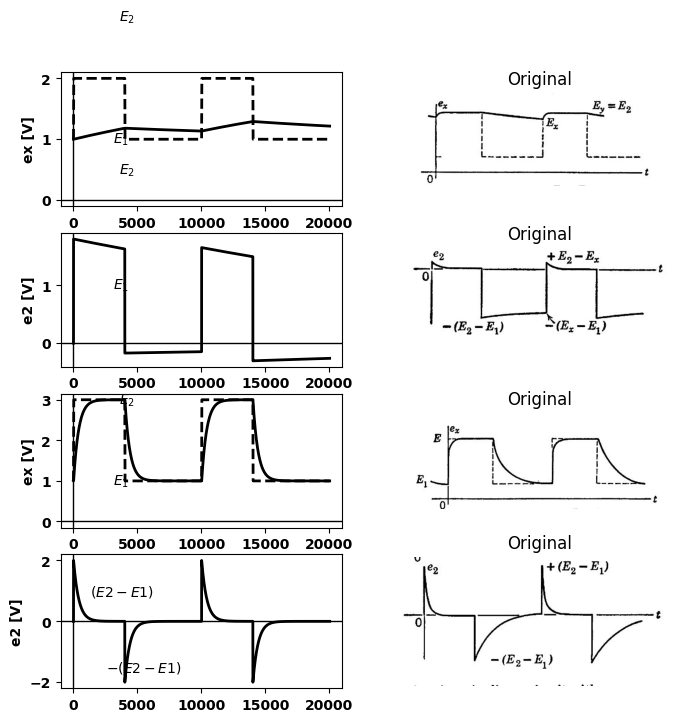

In [34]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(8, 8))
d = schemdraw.Drawing()
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 2@u_kOhm )
circuit.C(1 ,'1', '2', 10@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[0,0].plot(analysis['1'],'black',linewidth=2, linestyle='--', label='ex') 
axs[0,0].plot(analysis['1']-analysis['2'],'black',linewidth=2, label='ex') 
axs[0,0].set_ylabel('ex [V]', color='black', weight='black', fontsize=10)
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
#ax1.text(5000, 1.8, r'$\tau1$', ha='center', va='center')
axs[0,0].text(3750, 1, '$E_1$', ha='center', va='center')
axs[0,0].text(4200, 3, '$E_2$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-16c1.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=-.2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 2000@u_Ohm )
circuit.C(1 ,'1', '2', 20@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['2'],'black',linewidth=2, linestyle='-', label='e2') 
axs[1,0].set_ylabel('e2 [V]', color='black', weight='black', fontsize=10)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
axs[1,0].text(3750, 1, '$E_1$', ha='center', va='center')
axs[1,0].text(4200, 3, '$E_2$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-16c2.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=3@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd,800@u_Ohm )
circuit.C(1 ,'1', '2', .5@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[2,0].plot(analysis['1'],'black',linewidth=2, linestyle='--', label='ex') 
axs[2,0].plot(analysis['1']-analysis['2'],'black',linewidth=2, label='ex') 
axs[2,0].set_ylabel('ex [V]', color='black', weight='black', fontsize=10)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
#ax1.text(5000, 1.8, r'$\tau1$', ha='center', va='center')
axs[2,0].text(3750, 1, '$E_1$', ha='center', va='center')
axs[2,0].text(4200, 3, '$E_2$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-16d1.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
pulse1 = circuit.PulseVoltageSource('I1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=3@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'2', circuit.gnd, 200@u_Ohm )
circuit.C(1 ,'1', '2', 2@u_uF )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis['2'],'black',linewidth=2, linestyle='-', label='e2') 
axs[3,0].set_ylabel('e2 [V]', color='black', weight='black', fontsize=10)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
axs[3,0].text(3750, 1, '$(E2-E1)$', ha='center', va='center')
axs[3,0].text(5500, -1.5, '$-(E2-E1)$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-16d2.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig.8.16 Typical waveforms for piecewise -Linear circuit with rectangular-wave input.

Text(0.5, 1.0, 'Original')

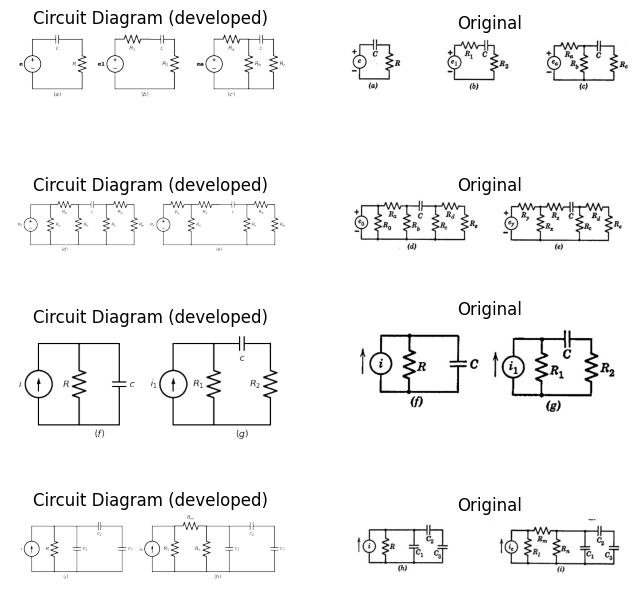

In [66]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(8, 8))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e', 'top') 
d += (C1:=elm.Capacitor().right(d.unit*1).color('black').label('$c$','bottom'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left().label('$(a)$','bottom'))
d += elm.SourceV().up(d.unit*1).label('e1', 'top').at((5,0)) 
d += (R1 := elm.Resistor().right(d.unit*.7).label('$R_1$', 'bottom'))
d += (C1:=elm.Capacitor().right(d.unit*.5).color('black').label('$c$','bottom'))
d += (R1 := elm.Resistor().down().label('$R_2$', 'top'))
l1 = d.add(elm.Line().left(d.unit*1.2).label('$(b)$','bottom'))
d += elm.SourceV().up(d.unit*1).label('ea', 'top').at((11,0))
d += (R3 := elm.Resistor().right(d.unit*.7).label('$R_a$', 'bottom'))
d += (R2 := elm.Resistor().down(d.unit*1).label('$R_b$', 'bottom'))
l1 = d.add(elm.Line().left(d.unit*.7).label('$(c)$','bottom'))
d += (C1:=elm.Capacitor().right(d.unit*.5).color('black').label('$c$','bottom').at(R3.end))
d += (R2 := elm.Resistor().down(d.unit*1).label('$R_c$', 'bottom'))
l1 = d.add(elm.Line().left(d.unit*.7))
d.save('images/8-17-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-17-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-17a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original') 
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('$e_o$', 'top') 
l1 = d.add(elm.Line().right(d.unit*.5))
d += (R1 := elm.Resistor().down(d.unit*1).label('$R_o$', 'bottom'))
l2 = d.add(elm.Line().left(d.unit*.5))
d += (R2 := elm.Resistor().right(d.unit*.7).label('$R_a$', 'bottom').at(l1.end))
d += (R3 := elm.Resistor().down(d.unit*1).label('$R_b$', 'bottom'))
l3 = d.add(elm.Line().left(d.unit*.7).label('$(d)$', 'bottom'))
d += (C1:=elm.Capacitor().right(d.unit*.7).color('black').label('$c$','bottom').at(R3.start))
d += (R4 := elm.Resistor().down(d.unit*1).label('$R_c$', 'bottom'))
l4 = d.add(elm.Line().left(d.unit*.7))
d += (R2 := elm.Resistor().right(d.unit*.7).label('$R_d$', 'bottom').at(R4.start))
d += (R3 := elm.Resistor().down(d.unit*1).label('$R_e$', 'bottom'))
l4 = d.add(elm.Line().left(d.unit*.7))
d += elm.SourceV().up(d.unit*1).label('$e_y$', 'top').at((10,0))
d += (R5 := elm.Resistor().right(d.unit*.7).label('$R_y$', 'bottom'))
d += (R6 := elm.Resistor().down(d.unit*1).label('$R_x$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*.7))
d += (R7 := elm.Resistor().right(d.unit*.7).label('$R_z$', 'bottom').at(R6.start))
d += (C1:=elm.Capacitor().right(d.unit*.7).color('black').label('$c$','bottom').at(R7.end))
d += (R8 := elm.Resistor().down(d.unit*1).label('$R_c$', 'bottom'))
l6 = d.add(elm.Line().left(d.unit*1.4).label('$(e)$', 'bottom'))
d += (R9 := elm.Resistor().right(d.unit*.7).label('$R_d$', 'bottom').at(R8.start))
d += (R10 := elm.Resistor().down(d.unit*1).label('$R_e$', 'bottom'))
l4 = d.add(elm.Line().left(d.unit*.7))
d.save('images/8-17-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-17-2.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-17b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceI().up(d.unit*1).label('$i$', 'top') 
l1 = d.add(elm.Line().right(d.unit*.5))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5))
l3 = d.add(elm.Line().right(d.unit*.5).at(l1.end))
d += (C1:=elm.Capacitor().down(d.unit*1).color('black').label('$c$','bottom'))
l2 = d.add(elm.Line().left(d.unit*.5).label('$(f)$', 'bottom'))
d += elm.SourceI().up(d.unit*1).label('$i_1$', 'top').at((5,0)) 
l4 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Resistor().down().label('$R_1$', 'top'))
l5 = d.add(elm.Line().left(d.unit*.5))
d += (C1:=elm.Capacitor().right(d.unit*.7).color('black').label('$c$','bottom').at(R2.start))
d += (R2 := elm.Resistor().down().label('$R_2$', 'top'))
l5 = d.add(elm.Line().left(d.unit*.7).label('$(g)$', 'bottom'))

d.save('images/8-17-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-17-3.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-17c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceI().up(d.unit*1).label('$i$', 'top') 
l1 = d.add(elm.Line().right(d.unit*.5))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5))
l3 = d.add(elm.Line().right(d.unit*.5).at(l1.end))
d += (C1:=elm.Capacitor().down(d.unit*1).color('black').label('$c_1$','bottom'))
l2 = d.add(elm.Line().left(d.unit*.5).label('$(i)$', 'bottom'))
d += (C2:=elm.Capacitor().right(d.unit*1).color('black').label('$c_2$','bottom').at(C1.start))
d += (C2:=elm.Capacitor().down(d.unit*1).color('black').label('$c_3$','bottom'))
l2 = d.add(elm.Line().left(d.unit*1))
d += elm.SourceI().up(d.unit*1).label('$i_e$', 'top').at((8,0)) 
l4 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Resistor().down().label('$R_1$', 'top'))
l5 = d.add(elm.Line().left(d.unit*.5))
d += (R3 := elm.Resistor().right(d.unit*.7).label('$R_m$', 'top').at(l4.end))
d += (R4 := elm.Resistor().down(d.unit*1).label('$R_n$', 'top'))
l6 = d.add(elm.Line().left(d.unit*.7))
l7 = d.add(elm.Line().right(d.unit*.5).at(R4.start))
d += (C3:=elm.Capacitor().down(d.unit*1).color('black').label('$c_1$','bottom'))
l2 = d.add(elm.Line().left(d.unit*.5).label('$(h)$', 'bottom'))
d += (C2:=elm.Capacitor().right(d.unit*1).color('black').label('$c_2$','bottom').at(C3.start))
d += (C2:=elm.Capacitor().down(d.unit*1).color('black').label('$c_3$','bottom'))
l6 = d.add(elm.Line().left(d.unit*1))
d.save('images/8-17-4.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-17-4.png')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-17d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## fig 8.17 Variation of the simple RC circuit

Text(0.5, 1.0, 'Original')

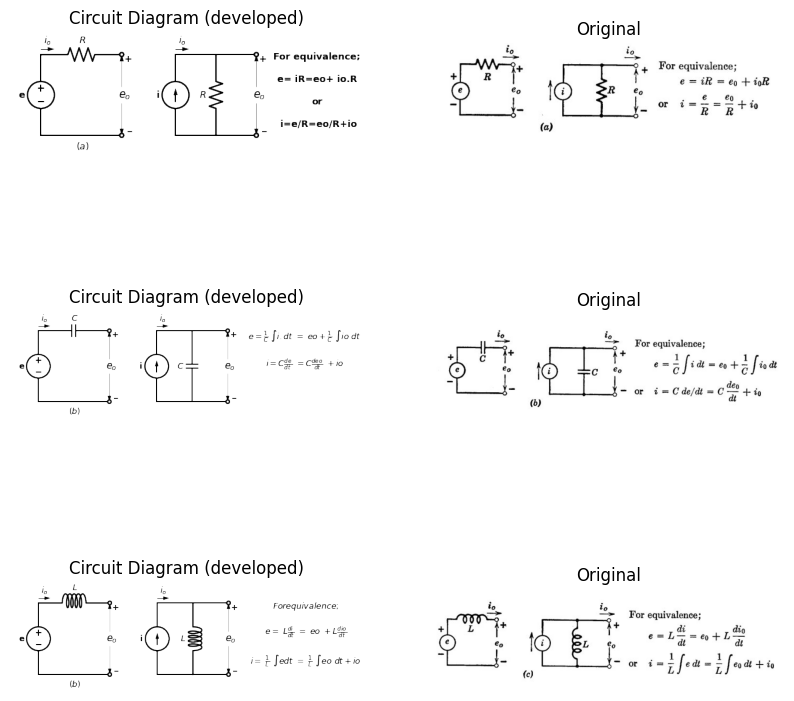

In [69]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e', 'top') 
d += (R1 := elm.Resistor().right().label('$R$', 'top').dot(open=True))
l1 = d.add(elm.Line().right().label('$(a)$','bottom').at((0,0)).dot(open=True))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i_o$','top'). at((0,3.2))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((1.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3,1.2))
d += elm.SourceI().up(d.unit*1).label('i', 'top').at((5,0))
l2 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Resistor().down().label('$R$', 'top'))
l3 = d.add(elm.Line().left(d.unit*.5))
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True).at(l2.end))
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True).at(l3.start))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((6.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((8,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((8,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i_o$','top'). at((5,3.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('white').label('For equivalence;\n\n e= iR=eo+ io.R \n\nor\n\n i=e/R=eo/R+io','bottom',color='black'). at((10,3.2))
d.save('images/8-18-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-18-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-18a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e', 'top') 
d += (R1 := elm.Capacitor().right().label('$C$', 'top').dot(open=True))
l1 = d.add(elm.Line().right().label('$(b)$','bottom').at((0,0)).dot(open=True))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i_o$','top'). at((0,3.2))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((1.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3,1.2))
d += elm.SourceI().up(d.unit*1).label('i', 'top').at((5,0))
l2 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Capacitor().down().label('$C$', 'top'))
l3 = d.add(elm.Line().left(d.unit*.5))
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True).at(l2.end))
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True).at(l3.start))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((6.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((8,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((8,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i_o$','top'). at((5,3.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('white').label(r'$e=\frac{1}{C}\ \int{i.dt\ =\ eo+\frac{1}{C}}\ \int{io\ dt}$','bottom',color='black'). at((11,3.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('white').label(r'$i=C\frac{de}{dt\ }\ =C\frac{deo}{dt}\ +io$','bottom',color='black'). at((11,2))
d.save('images/8-18-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-18-2.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-18b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e', 'top') 
d += (R1 := elm.Inductor2().right().label('$L$', 'top').dot(open=True))
l1 = d.add(elm.Line().right().label('$(b)$','bottom').at((0,0)).dot(open=True))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i_o$','top'). at((0,3.2))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((1.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3,1.2))
d += elm.SourceI().up(d.unit*1).label('i', 'top').at((5,0))
l2 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Inductor2().down().label('$L$', 'top'))
l3 = d.add(elm.Line().left(d.unit*.5))
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True).at(l2.end))
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True).at(l3.start))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((6.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((8,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((8,1.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i_o$','top'). at((5,3.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('white').label('$For equivalence;$','bottom',color='black'). at((11,3.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('white').label(r'$e=\ L\frac{di}{dt}\ =\ eo\ +L\frac{dio}{dt}$','bottom',color='black'). at((11,2.2))
d += elm.Arrow().right().length(.5).linewidth(1).color('white').label(r'$i=\ \frac{1}{L}\ \int{edt\ =\ \frac{1}{L}}\ \int{eo\ dt+io}$','bottom',color='black'). at((11,1))
d.save('images/8-18-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-18-3.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-18c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig 8.18 Summary of equivalent  two-element Linear source models

linear capacitances. Several examples of circuits which can be reduced  to the series$ RC$ circuit form are shown in $Fig. 8.17. $The Thevenin  equivalents shown in $Fig. 8.18$ can be used to reduce the circuits in  $Fig. 8.17 (f), (g), (h), (i)$ to the original voltage-source forms.  

$$ Circuit Duals$$

$$Voltage \rightarrow Current $$

$$Resistance \rightarrow Conductance $$


$$Inductance \rightarrow Capacitance  $$

$$ Series \rightarrow Parallel$$
$$ Loop \rightarrow Node$$
$$ (a)$$

Text(0.5, 1.0, 'Original')

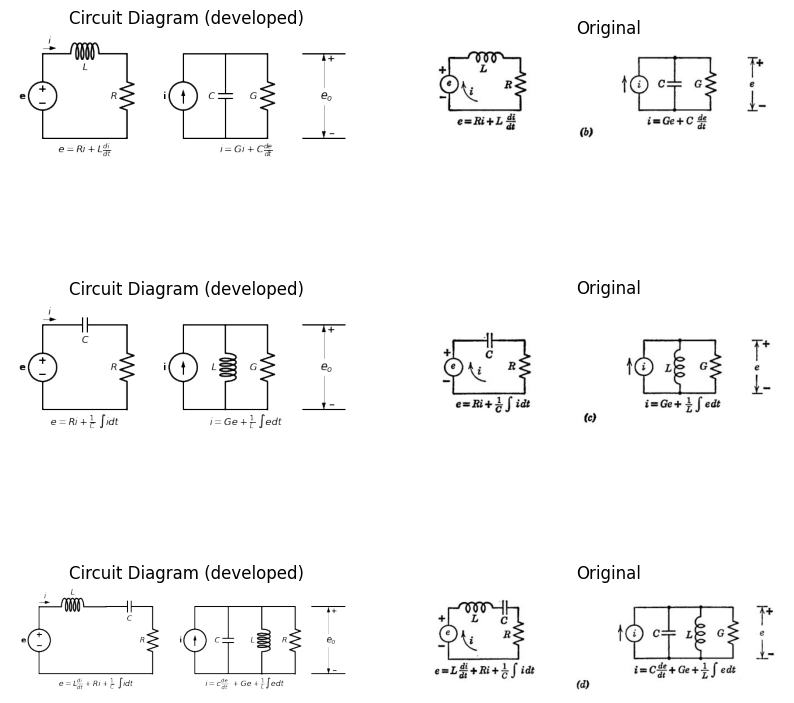

In [70]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e', 'top') 
d += (C1:=elm.Inductor2().right(d.unit*1).color('black').label('$L$','bottom'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left().label(r'$e=Ri+L\frac{di}{dt}$','bottom'))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i$','top'). at((0,3.2))
d += elm.SourceI().up(d.unit*1).label('i', 'top').at((5,0))
l2 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Capacitor().down().label('$C$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5))
l2 = d.add(elm.Line().right(d.unit*.5).at(R2.start))
d += (R1 := elm.Resistor().down().label('$G$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5).label(r'$i=Gi+C\frac{de}{dt}$','bottom'))
l6 = d.add(elm.Line().right(d.unit*.5).at((9.25,3)))
l5 = d.add(elm.Line().right(d.unit*.5).at((9.25,0)))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((8.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((10,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((10,1.2))

d.save('images/8-19-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-19-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-19b.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e', 'top') 
d += (C1:=elm.Capacitor().right(d.unit*1).color('black').label('$C$','bottom'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left().label(r'$e=Ri+\frac{1}{C}\ \int{idt}$','bottom'))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i$','top'). at((0,3.2))
d += elm.SourceI().up(d.unit*1).label('i', 'top').at((5,0))
l2 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Inductor2().down().label('$L$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5))
l2 = d.add(elm.Line().right(d.unit*.5).at(R2.start))
d += (R1 := elm.Resistor().down().label('$G$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5).label(r'$i=Ge+\frac{1}{L}\ \int{edt}$','bottom'))
l6 = d.add(elm.Line().right(d.unit*.5).at((9.25,3)))
l5 = d.add(elm.Line().right(d.unit*.5).at((9.25,0)))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((8.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((10,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((10,1.2))
d.save('images/8-19-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-19-2.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-19c.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('e', 'top') 
d += (L1 := elm.Inductor2().right().label('$L$', 'top'))
d += (C1:=elm.Capacitor().right(d.unit*.7).color('black').label('$C$','bottom'))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l1 = d.add(elm.Line().left(d.unit*1.7).label(r'$e=L\frac{di}{dt}+Ri+\frac{1}{C}\ \int{idt}$','bottom'))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i$','top'). at((0,3.2))
d += elm.SourceI().up(d.unit*1).label('i', 'top').at((7,0))
l2 = d.add(elm.Line().right(d.unit*.5))
d += (C1 := elm.Capacitor().down().label('$C$', 'top'))
l3 = d.add(elm.Line().left(d.unit*.5))
l4 = d.add(elm.Line().right(d.unit*.5).at(l2.end))
d += (L1 := elm.Inductor2().down().label('$L$', 'top'))
l5 = d.add(elm.Line().left(d.unit*.5).label(r'$i=c\frac{de}{dt}\ +Ge+\frac{1}{L}\int{edt}$','bottom'))
l6 = d.add(elm.Line().right(d.unit*.5).at(l4.end))
d += (R1 := elm.Resistor().down().label('$R$', 'top'))
l7 = d.add(elm.Line().left(d.unit*.5))
l6 = d.add(elm.Line().right(d.unit*.5).at((12.25,3)))
l5 = d.add(elm.Line().right(d.unit*.5).at((12.25,0)))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((11.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((13,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((13,1.2))
d.save('images/8-19-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-19-3.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-19d.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig8.19 Duality in Simple circuit

The methods thus far applied to RC circuit analysis can be used  equally well to analyze circuits containing a linear inductance and linear  or piecewise-linear resistances. The student may wish to repeat some of  the analyses for simple RL circuits in order to gain familiarity with the methods. However, it is possible to apply the concept of duality* to  extend the results of RC circuit analysis to RL circuits. Duality makes  it possible to transfer the results of one analysis to a different situation  merely by appropriate definition of dual quantities. A few useful pairs  of dual quantities and concepts are listed in Fig. 8.19, together with dual  pairs for simple three-element and four-element circuits. Any of the  dual pairs in the columns of Fig. 8.19(a) can be interchanged. 

# 8.14 Graphical Analysis of Nonlinear Circuits  

The nonlinear analysis of a simple diode circuit with rectangular-wave  input is outlined in Fig. 8.20. Consider diode D in Fig. 8.20(a) to be a  semiconductor junction diode with the curve $i = f(e_{2})$ as shown in (b).  The voltage equation for the circuit is  

$e_{1} = e_{r} + e_{x} + e_{2}  $   $$(8.20)$$

For a specific value of input voltage, say $E_{b}$ and an arbitrary value $e_{x}$ for  the capacitor voltage, the graphical solution of the voltage equation  specifies the operating point. The load-line form of the voltage equation  is  

$\frac{((e_{1} - e_{x}) - e_{2})}{R}= i  $ $$(8.21)$$

In this form, $(e_{1} - e_{x})$ is the effective driving voltage on the series  combination of R and D. With a rectangular wave input, $e_{1}$ remains  constant during each interval$\delta_{a}$ or $\delta_{b}$ but $e_{x}$ is a function of time; hence  the load line moves with time. If the capacitor charges and discharges  completely during the intervals$ \delta_{b}$ and $\delta_{a}$ the capacitor voltage varies  between $- E_{a}$and $E_{b}$ The voltage across the resistive elements R  and D varies, therefore, from $(E_{b} + E_{a})$ to zero during the interval $\delta_{b}$  and from$- (E_{b} + E_{a})$ to zero during $\delta_{a} $Correspondingly, the current  and therefore the diode operating point moves from point to point 0,  and from point P to point 0, as indicated in Fig. 8.20(b). 

In carrying out a graphical integration process, we are essentially  replacing differentials by increments: namely, replacing i $C dex/dt$ by  $i=C ∆ex/∆t$. We assume that current i remains constant for an increment of time ∆t, during which e changes by the amount ∆ex. This results in a new value of current which is held constant for a second  increment of time during which a second incremental change occurs in ex  
$E. A. Guillemin, Introductory Circuit Theory, John Wiley and Sons, New York,   1953, pp. 42-51, 241-243, 251-253, 373-374, 535-539. $
 


Repetition of this process determines e, as a smooth waveform which  is a piecewise-linear approximation to the true waveform of e. The  waveform of current i is a stepwise approximation. Carrying out the  analysis in systematic fashion, we can take equal increments for de, as  indicated by the sequence of dashed lines in Fig. 8.20(b); or we can take  equal increments in ∆t, as implied by Fig. 8.20 (c). The former provides  a better approximation to the true waveforms near the beginning of each  interval, while the latter provides more points near the end. A combination of the two can also be used. In any case, it is readily seen that   the process is time-consuming even for this extremely simple circuit  problem. To obtain reasonable accuracy, the nonlinear curve and wave- form plots must be constructed carefully and drawn to a fairly large scale.  

Text(0.5, 1.0, 'Original')

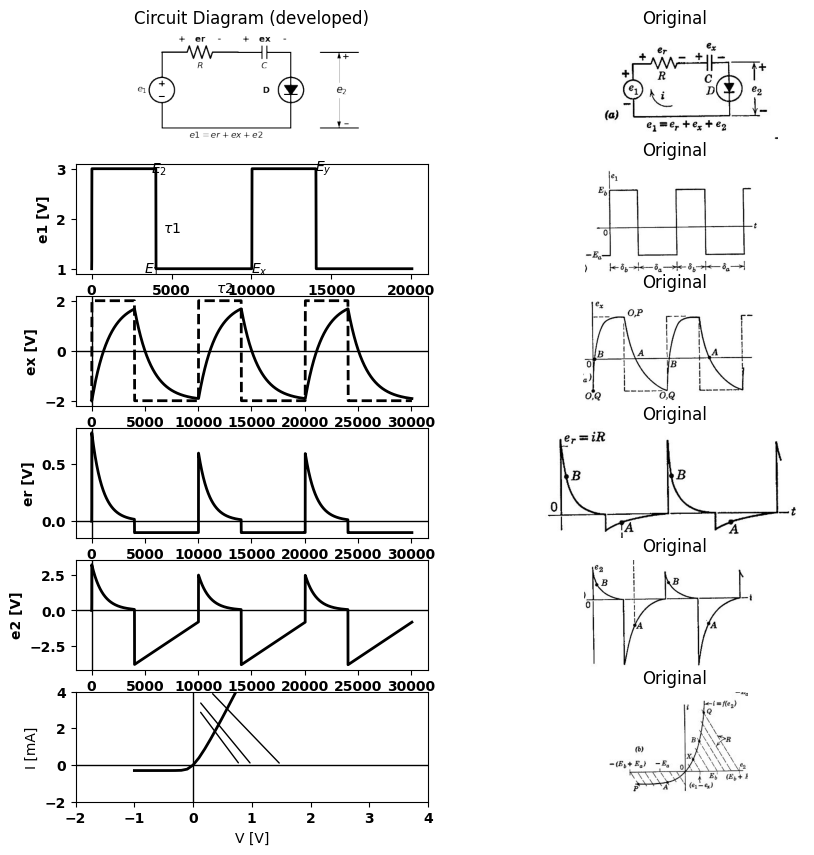

In [23]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('$e_1$', 'top') 
d += (R1 := elm.Resistor().right().label('$R$', 'bottom').label('+   er    -', 'top'))
d += (C1:=elm.Capacitor().right(d.unit*.7).color('black').label('$C$','bottom').label('+   ex    -', 'top'))
D2 = d.add(elm.Diode(fill=True).down().label('D    ','top'))
ss1 = d.add(elm.Source().down().at(D2.start))
l1 = d.add(elm.Line().left(d.unit*1.7).label('$e1= er + ex + e2$','bottom'))
l6 = d.add(elm.Line().right(d.unit*.5).at((6.25,3)))
l5 = d.add(elm.Line().right(d.unit*.5).at((6.25,0)))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5.4,0.2))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((7,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((7,1.2))
d.save('images/8-20-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-20-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-20.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS =10@u_mA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 800@u_Ohm ,TT = 3.48E-9)
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=3@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'1', '2', 10@u_Ohm )
circuit.C(1 ,'2', '3', 2@u_uF )
circuit.D(1, '3',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['1'],'black',linewidth=2, linestyle='-', label='e1') 
axs[1,0].set_ylabel('e1 [V]', color='black', weight='black', fontsize=10)
axs[1,0].text(5000, 1.8, r'$\tau1$', ha='center', va='center')
axs[1,0].text(3750, 1, '$E_1$', ha='center', va='center')
axs[1,0].text(4200, 3, '$E_2$', ha='center', va='center')
axs[1,0].text(10500, 1, '$E_x$', ha='center', va='center')
axs[1,0].text(14500, 3, '$E_y$', ha='center', va='center')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-20a1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS =100@u_mA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 800@u_Ohm ,TT = 3.48E-9)
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'1', '2', 1@u_Ohm )
circuit.C(1 ,'2', '3', 2@u_uF )
circuit.D(1, '3',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[2,0].plot(analysis['2']-analysis['3'],'black',linewidth=2, linestyle='-', label='ex') 
axs[2,0].plot(analysis['1'],'black',linewidth=2, linestyle='--', label='ex') 
axs[2,0].set_ylabel('ex [V]', color='black', weight='black', fontsize=10)
axs[2,0].text(12500, 2.5, r'$\tau2$', ha='center', va='center')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-20a2.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS =10@u_mA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 40@u_Ohm ,TT = 3.48E-9)
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'1', '2', 10@u_Ohm )
circuit.C(1 ,'2', '3', 20@u_uF )
circuit.D(1, '3',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[3,0].plot(analysis['1']-analysis['2'],'black',linewidth=2, linestyle='-', label='er') 
#axs[3,0].plot(analysis['1'],'black',linewidth=2, linestyle='--', label='ex') 
axs[3,0].set_ylabel('er [V]', color='black', weight='black', fontsize=10)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
 #**Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-20a3.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS =10@u_mA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 40@u_Ohm ,TT = 3.48E-9)
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1 ,'1', '2', 10@u_Ohm )
circuit.C(1 ,'2', '3', 20@u_uF )
circuit.D(1, '3',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
#axs[4,0].plot(analysis['1']-analysis['2'],'black',linewidth=2, linestyle='-', label='er') 
axs[4,0].plot(analysis['3'],'black',linewidth=2, linestyle='-', label='e2') 
axs[4,0].set_ylabel('e2 [V]', color='black', weight='black', fontsize=10)
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
 #**Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-20e2.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

# 
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 300@u_uA , N = 1.906  ,BV = 8100@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 150@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 0@u_Ohm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(-1,8, 0.1))
axs[5,0].plot(analysis['1'], u_mA(-analysis.Vi),'black',linewidth=2)

axs[5,0].set_xlim(-2, 4)
axs[5,0].set_ylim(-2, 4)
axs[5,0].set_xlabel('V [V]')
axs[5,0].set_ylabel('I [mA]')
#axs[5,0].text(2, 1.5, 'i=Io(e^(v/vD)-1)\n Where Vo=KT/e \n Vo=0.026 vlot at \n room Temprature\n 300(k)', ha='center', va='center', fontsize=12)
#axs[5,0].text(-1.1, -0.3, '$-Io$', ha='center', va='center', fontsize=12)
axs[5,0].axhline(0, color='black', linewidth=1 )
axs[5,0].axvline(0, color='black', linewidth=1)
axs[5,0].annotate('', xy=(1.5,0), xytext=(.3, 4), arrowprops=dict(arrowstyle='-'))
axs[5,0].annotate('', xy=(1,0), xytext=(.1, 3.5), arrowprops=dict(arrowstyle='-'))
axs[5,0].annotate('', xy=(.8,0), xytext=(.1, 3), arrowprops=dict(arrowstyle='-'))
 #**Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-20f.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

## Fig.8.20 Grapgical analysis of a nonlinear diode circuit

# 8.15 Triode with Parallel RC Plate Load  and Large-Amplitude Rectangular-Wave Input  

The instantaneous values of terminal current and voltage specify the  locus of the operating point for a control valve like a transistor, triode  or pentode. When a circuit contains energy-storage elements, the locus  depends on time scale and amplitude of the input waveform as well as the  circuit parameters. Although waveforms of current and voltage $[is (t)  and ex(t) for a triode] $contain all the necessary information, the locus of  the instantaneous operating point (ib vs. eb) plotted directly on the  is vs. es plane aids in visualizing the conditions imposed on the valve by  the circuit and input signal. The relations between the path of operation  of a triode and the current and voltage waveforms will be illustrated in  terms of a simple plate-loaded triode with a capacitor in parallel with  the load resistor. The same methods will then be applied to other basic  circuits. For continuity and ease of comparison, the vacuum triode is  used in a series of related examples of waveshaping circuits. The methods  and circuits apply equally well to other control valves such as transistors,  pentodes, etc.  
The two forms of the circuit shown in Fig. 8.21 (a) and (b) are identical  insofar as the triode is concerned. There is only a difference in the direct  component of the capacitor voltage for any particular set of circuit  conditions. Since the physical behavior of the two circuits is identical,  we shall confine our remarks to the circuit in (b). 

Suppose the triode in the circuit of Fig. 8.21 (b) is described by the  plate curves shown in Fig. 8.21 (c). The quiescent voltage Ea for e1  is determined by drawing the resistive load line Rs on the iz vs. es plane.  Let the rectangular waveform of e₁ shown in (d) have sufficient amplitude  to result in plate-current cutoff during the interval 82, and assume both  δ₁ and 82 to be of sufficient duration to permit complete charge and dis- charge of capacitor C. Under these conditions, the voltage and current  waveforms will be as shown in Fig. 8.21 (e) and (f). The dotted line in  (e) is the waveform of e2 in the absence of the capacitor C. The locus  of the operating point (ib vs. eb) for the triode is shown on the plate  curves in Fig. 8.21 (c). The points designated as A, B, C, and D on the  locus correspond to similarly marked points on the waveforms. The  transitions from A to B and from C to Dare instantaneous. The path 

Text(0.5, 1.0, 'Original')

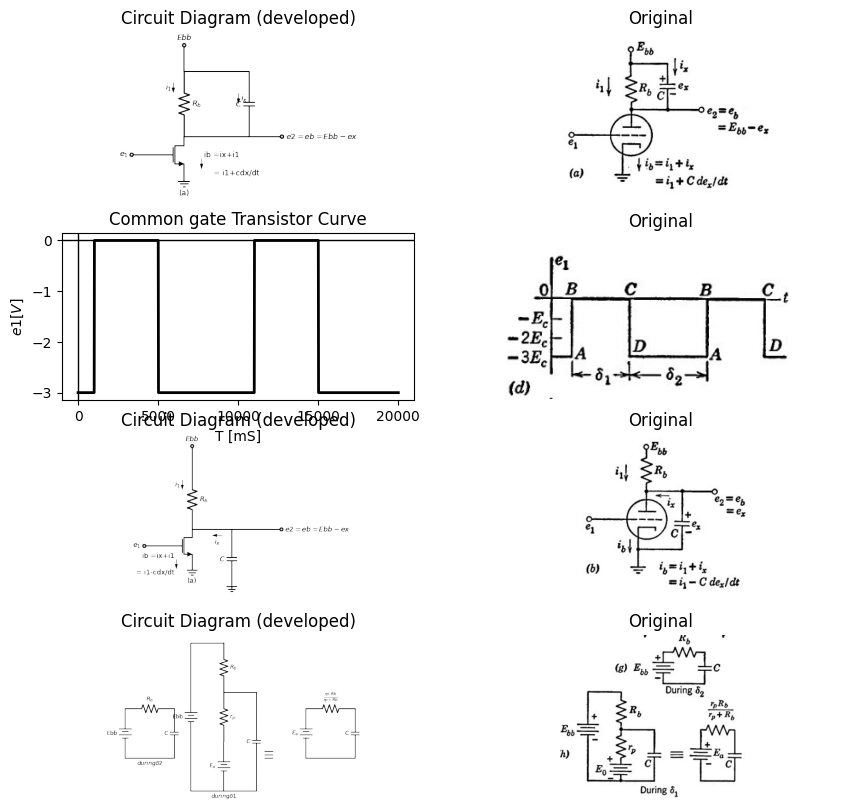

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
G = d.add(elm.Ground().at(M1.source).label('(a)','bottom'))
d += (R1 := elm.Resistor().up().label('$R_b$', 'bottom').at(M1.drain))
l2 = d.add(elm.Line().right(d.unit*1.5).dot(open=True).label('$e2=eb=Ebb-ex $','right').at(M1.drain))
l3 = d.add(elm.Line().right(d.unit*1).at(R1.end))
d += (C1 := elm.Capacitor().down().label('$C$', 'top'))
l4 = d.add(elm.Line().up(d.unit*.4).dot(open=True).label('$Ebb $','right').at(R1.end))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.5,2.5))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_x$','bottom'). at((2.5,2))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('ib =ix+i1\n\n    = i1+cdx/dt','bottom'). at((.8,-1))
d.save('images/8-21-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-21-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/21a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-3@u_V,delay_time=1@u_ms, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=180E-9, W=2E-6, Kp=0.13, Vto=0.8)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 4000@u_Ohm)
circuit.C(1, 'Ebb', 'e2', 20@u_uF)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['e1'],'black',linewidth=2)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/21-b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
G = d.add(elm.Ground().at(M1.source).label('(a)','bottom'))
d += (R1 := elm.Resistor().up().label('$R_b$', 'bottom').at(M1.drain))
l2 = d.add(elm.Line().right(d.unit*1.5).dot(open=True).label('$e2=eb=Ebb-ex $','right').at(M1.drain))
G = d.add(elm.Ground().at((2,-2.5)))
d += (C1 := elm.Capacitor().down().label('$C$', 'top').at((2,0)))
l4 = d.add(elm.Line().up(d.unit*.4).dot(open=True).label('$Ebb $','right').at(R1.end))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.5,2.5))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','bottom'). at((1.5,-0.3))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('ib =ix+i1\n\n    = i1-cdx/dt','top'). at((-.8,-1.5))
d.save('images/8-21-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-21-2.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/21c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.Battery().up(d.unit*1).label('Ebb', 'top').reverse()
d += (R1 := elm.Resistor().right().label('$R_b$', 'top'))
d += (C1 := elm.Capacitor().down().label('$C$', 'top'))
l1 = d.add(elm.Line().left().length(3).label(r'$during \delta2$', 'bottom'))
d += elm.Battery().up(d.unit*3).label('Ebb', 'top').reverse().at((4,-2))
l1 = d.add(elm.Line().right().length(2))
d += (R2 := elm.Resistor().down().label('$R_b$', 'bottom'))
d += (R3 := elm.Resistor().down().label('$r_p$', 'bottom'))
d += elm.Battery().up(d.unit*1).label('$E_o$', 'top').reverse().at((6,-2))
l1 = d.add(elm.Line().left().length(2).at((6,-2)))
l2 = d.add(elm.Line().right().length(2).at(R2.end))
d += (C1 := elm.Capacitor().down(d.unit*2).label('$C$', 'top'))
l1 = d.add(elm.Line().left().length(4).label(r'$during \delta1$', 'bottom'))
l1 = d.add(elm.Line().left().length(.5).at((9,0)))
l1 = d.add(elm.Line().left().length(.5).at((9,.2)))
l1 = d.add(elm.Line().left().length(.5).at((9,.4)))
d += elm.Battery().up(d.unit*1).label('$E_a$', 'top').reverse().at((11,0))
d += (R1 := elm.Resistor().right().label(r'$\frac{rp.Rb}{rp+Rb}$', 'top'))
d += (C1 := elm.Capacitor().down().label('$C$', 'top'))
l1 = d.add(elm.Line().left().length(3))
d.save('images/8-21-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-21-3.png')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/21d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig 8.21 Triod With Parallel RC Load. Rectangular-Wave Input

from B to C is traversed at a rate corresponding to the discharge of the  capacitor through the triode plate resistance in parallel with load resistance Rs. The time along the path from D to A depends upon the  exponential recharge of capacitor C to Ebb through Rs, as shown in Fig. 8.21 (g). The triode does not affect this portion of the path, since  plate current is zero.  
A step-by-step graphical calculation of the waveform of e2 could be  made during the interval $\delta1$. However, the use of a piecewise-linear  
 

Text(0.5, 1.0, 'Original')

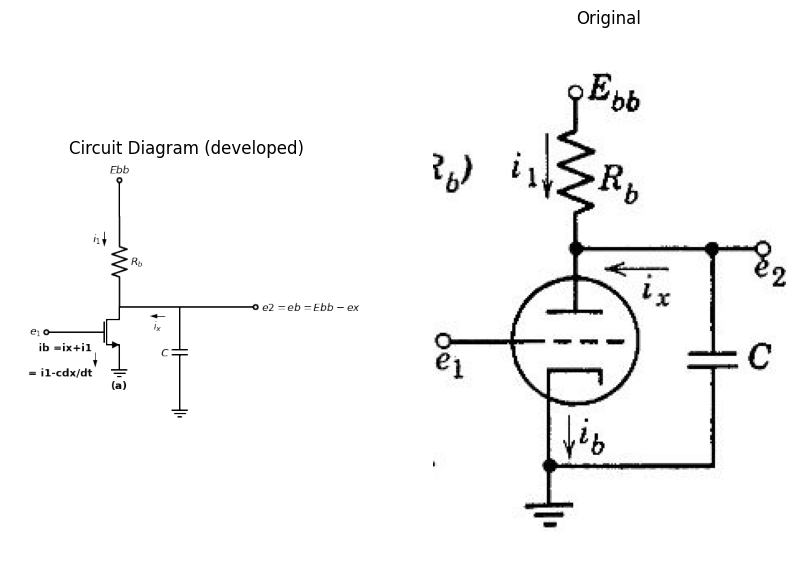

In [32]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
G = d.add(elm.Ground().at(M1.source).label('(a)','bottom'))
d += (R1 := elm.Resistor().up().label('$R_b$', 'bottom').at(M1.drain))
l2 = d.add(elm.Line().right(d.unit*1.5).dot(open=True).label('$e2=eb=Ebb-ex $','right').at(M1.drain))
G = d.add(elm.Ground().at(C1.end))
d += (C1 := elm.Capacitor().down().label('$C$', 'top').at((2,0)))
l4 = d.add(elm.Line().up(d.unit*.4).dot(open=True).label('$Ebb $','right').at(R1.end))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.5,2.5))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','bottom'). at((1.5,-0.3))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('ib =ix+i1\n\n    = i1-cdx/dt','top'). at((-.8,-1.5))
d.save('images/8-22-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-22-1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-22.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

## Fig.8.22 Lucas of operating point for various values of $\delta1$/$\tau1$ and $\delta2$/$\tau2$

approximation to the triode yields a result that is well within the toler- ances of the average plate characteristics. Let us approximate the  ec = 0 curve by passing a line $[shown dotted on Fig. 8.21 (c)]$ through  points B and C, thereby matching initial points and end points on the  waveforms. During $\delta1$ we now have the circuit model shown in  Fig. 8.21 (h). We see, from Fig. 8.21(g) and (h), that the circuit is  identical to the piecewise-linear RC circuit already analyzed.  
Referring to Fig. 8.21 (g) and (h), we see that the time constant of the  exponential charge during interval $\delta2$ is  

$\tau2=Rb.C$ $$(8.22)$$ 

For the discharge of capacitor C during interval $\delta1$, the time constant is 

$\tau1=C\frac{Rb.rp}{(rp+Rb)}$  $$(8.23)$$

The sketches in Fig. 8.22 indicate the effects of changes in $\delta1$ and $\delta2$  relative to $\tau1$ and $\tau1$. The locus given in (b) is the same as that in  Fig. 8.21 (c) namely, for complete charge and discharge. The locus  shown in Fig. 8.22 (c) is the intermediate case in which only the discharge  goes to completion, and the locus in (d) is for complete charge only.  The locus in (e) is the general case where neither charge nor discharge is  completed. In the limit, as $\delta1$, becomes very small relative to $\tau1$, and $\delta2$  becomes very small relative to $\tau2$, the locus closes up, since E, and Ex  approach e2

# 8.16  Effect of Rectangular-Wave Amplitude on a  Triode with Parallel RC Plate Load

Let us now examine the locus of the operating point of the triode with  parallel RC load for various values of the upper and lower values of the  input waveform. For simplicity, the operating paths shown in Fig. 8.23  are sketched assuming $\delta1$ > 5$\tau1$ and $\delta2$ > 5$\tau2$ so that charge and dis- charge of the capacitor go to completion. The several input waveforms  shown in the figure lead to the operating paths indicated on the plate  curves. Note that, for each input waveform, the resistive output wave- form (with capacitor removed) specifies the upper and lower bounds of  capacitor voltage attainable. These bounds are indicated by the dotted  line on the waveforms of e2. For any one locus specified by the input  waveform amplitude bounds, the effect of smaller intervals δ₁ and 82  will be to shrink the width of the locus, as in Fig. 8.22(c), (d), (e), and (f)

# 8.17 Triode with Parallel RC Plate Load  and Sine-Wave Input  

For the triode circuit with parallel RC load, the locus of the operating  point when sinusoidal excitation is applied is closely related to the 

Text(0.5, 1.0, 'Original')

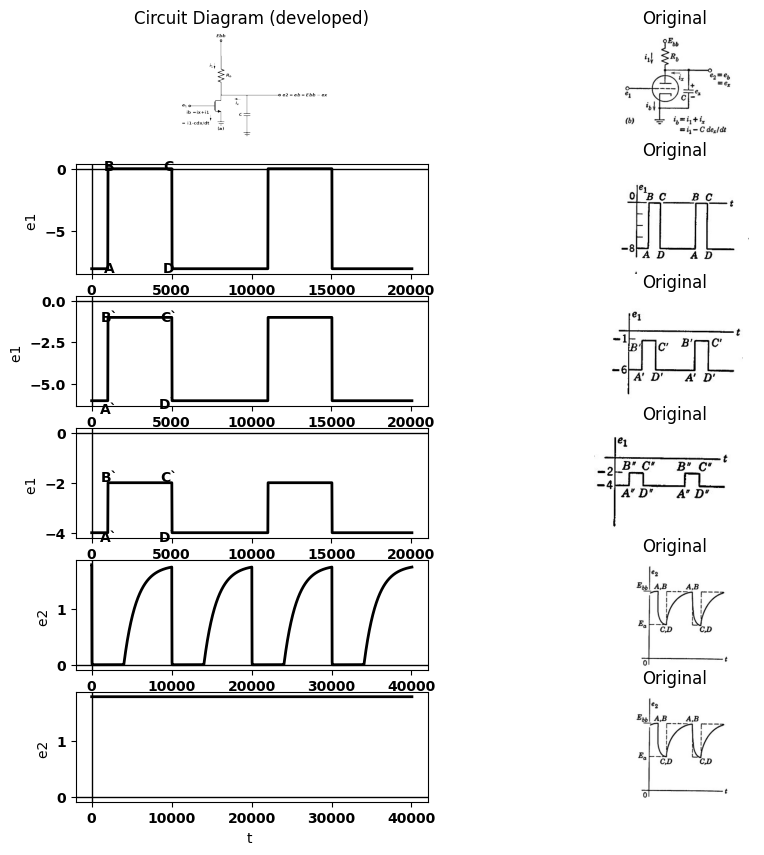

In [5]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
G = d.add(elm.Ground().at(M1.source).label('(a)','bottom'))
d += (R1 := elm.Resistor().up().label('$R_b$', 'bottom').at(M1.drain))
l2 = d.add(elm.Line().right(d.unit*1.5).dot(open=True).label('$e2=eb=Ebb-ex $','right').at(M1.drain))
G = d.add(elm.Ground().at((2,-2.5)))
d += (C1 := elm.Capacitor().down().label('$C$', 'top').at((2,0)))
l4 = d.add(elm.Line().up(d.unit*.4).dot(open=True).label('$Ebb $','right').at(R1.end))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.5,2.5))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','bottom'). at((1.5,-0.3))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('ib =ix+i1\n\n    = i1-cdx/dt','top'). at((-.8,-1.5))
d.save('images/8-23-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-23-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/21c.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-8@u_V,delay_time=1@u_ms, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=20E-6,LAMBDA = 0.1 ,Kp=0.007, Vto=.3)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 4@u_kOhm)
circuit.C(1, 'e2', circuit.gnd, 20@u_uF)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['e1'],'black',linewidth=2)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
axs[1,0].set_ylabel('e1 ')
axs[1,0].set_xlabel('t ')
axs[1,0].text( 1100, -8, 'A', ha='center', va='center')
axs[1,0].text( 1100, 0.2, 'B', ha='center', va='center')
axs[1,0].text( 4800, -8, 'D', ha='center', va='center')
axs[1,0].text( 4800, 0.2, 'C', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/23c.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-6@u_V,delay_time=1@u_ms, pulsed_value=-1@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=20E-6,LAMBDA = 0.1 ,Kp=0.007, Vto=.3)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 4@u_kOhm)
circuit.C(1, 'e2', circuit.gnd, 20@u_uF)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[2,0].plot(analysis['e1'],'black',linewidth=2)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
axs[2,0].set_ylabel('e1 ')
axs[2,0].set_xlabel('t ')
axs[2,0].text( 1100, -6.5, 'A`', ha='center', va='center')
axs[2,0].text( 1100, -1, 'B`', ha='center', va='center')
axs[2,0].text( 4800, -6.2, 'D`', ha='center', va='center')
axs[2,0].text( 4800, -1, 'C`', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/23c1.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-4@u_V,delay_time=1@u_ms, pulsed_value=-2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 0.1 ,Kp=0.007, Vto=.3)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 4@u_kOhm)
circuit.C(1, 'e2', circuit.gnd, 20@u_uF)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis['e1'],'black',linewidth=2)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
axs[3,0].set_ylabel('e1 ')
axs[3,0].set_xlabel('t ')
axs[3,0].text( 1100, -4.2, 'A`', ha='center', va='center')
axs[3,0].text( 1100, -1.8, 'B`', ha='center', va='center')
axs[3,0].text( 4800, -4.2, 'D`', ha='center', va='center')
axs[3,0].text( 4800, -1.8, 'C`', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/23c2.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-8@u_V,delay_time=0@u_ms, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=0.9E-6,LAMBDA = 0.1 ,Kp=0.007, Vto=.3)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 4000@u_Ohm)
circuit.C(1, 'e2', circuit.gnd, .4@u_uF)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[4,0].plot(analysis['e2'],'black',linewidth=2)
#axs[4,0].plot(analysis['e1'],'black',linewidth=2,linestyle='--')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
axs[4,0].set_ylabel('e2 ')
axs[4,0].set_xlabel('t ')
#axs[4,0].text( 1100, -8, 'A', ha='center', va='center')
#axs[4,0].text( 1100, 0.2, 'B', ha='center', va='center')
#axs[4,0].text( 4800, -8, 'D', ha='center', va='center')
#axs[4,0].text( 4800, 0.2, 'C', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/23d1.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-6@u_V,delay_time=1@u_ms, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=0.9E-6,LAMBDA = 0.1 ,Kp=0.007, Vto=.3)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 4000@u_Ohm)
circuit.C(1, 'e2', circuit.gnd, 20@u_uF)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[5,0].plot(analysis['e2'],'black',linewidth=2)
#axs[4,0].plot(analysis['e1'],'black',linewidth=2,linestyle='--')
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
axs[5,0].set_ylabel('e2 ')
axs[5,0].set_xlabel('t ')
#axs[4,0].text( 1100, -8, 'A', ha='center', va='center')
#axs[4,0].text( 1100, 0.2, 'B', ha='center', va='center')
#axs[4,0].text( 4800, -8, 'D', ha='center', va='center')
#axs[4,0].text( 4800, 0.2, 'C', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/23d1.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

## Fig. 8.23. Locus of operating point and waveforms for various values of input  amplitude ($\delta1$ > 5$\tau$1 and $\delta2$ > 5$\tau$2


square-wave or rectangular-wave cases discussed in the preceding  article. Let us consider an input voltage of the form  $$E1=-Eo+E sin wt$$ $$(8.24)$$ where Eo polarizes the grid negative with respect to cathode to a value  about midway between zero and cutoff. Let us also assume E small  enough to insure operation in the normal amplification region of the  triode. The circuit and plate-current curves are shown in Fig. 8.24 (a).The locus of the operating point for a low-frequency square wave is  indicated by the letters ABCDA, as before. If the square-wave fre- quency is raised to a sufficiently high value, the parallel dotted lines  AB and CD move together, and in the limit they merge into the single  vertical line through quiescent point $Q.*$ If each interval of the square  wave is greater than five time constants, the locus reaches maximum  size. Since the low-frequency square wave includes both very slow and 


Text(0.5, 1.0, 'Original')

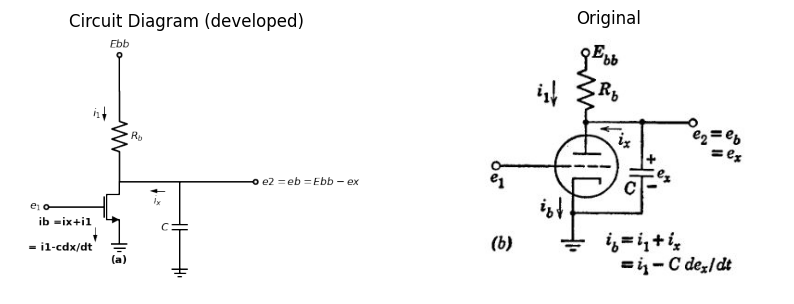

In [106]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
G = d.add(elm.Ground().at(M1.source).label('(a)','bottom'))
d += (R1 := elm.Resistor().up().label('$R_b$', 'bottom').at(M1.drain))
l2 = d.add(elm.Line().right(d.unit*1.5).dot(open=True).label('$e2=eb=Ebb-ex $','right').at(M1.drain))
G = d.add(elm.Ground().at((2,-2.5)))
d += (C1 := elm.Capacitor().down().label('$C$', 'top').at((2,0)))
l4 = d.add(elm.Line().up(d.unit*.4).dot(open=True).label('$Ebb $','right').at(R1.end))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.5,2.5))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','bottom'). at((1.5,-0.3))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('ib =ix+i1\n\n    = i1-cdx/dt','top'). at((-.8,-1.5))
d.save('images/8-23-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-23-1.png')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/21c.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


## Fig. 8.24. Locus of operation for triode with parallel RC load and sine wave input.  (a) Zero and infinite frequency locus of operating point. (b) Effect of successively  increasing frequency.  

very fast variations of input voltage, it actually represents many fre- quencies. During any one interval the square wave has a constant value  and therefore changes as little as any other waveform could change  
* This statement assumes linearity. Nonlinearities cause rectification and there- fore a shift in the quiescent values (direct components).

within that interval. At each transition, the square wave changes as  rapidly as any other waveform could. It can therefore be looked upon  as the limiting condition for any waveform with the same upper and  lower amplitude bounds If we now consider a sinusoidal input voltage with a very low frequency,  w, the capacitor current in C de2٫dt is negligible, since the rate of  - change of voltage is negligible. The locus of the operating point for  the limiting case as w approaches zero is therefore along the Ry load line  QCQAQ. For a sinusoidal input voltage of very high frequency, the  locus will be the vertical line through point Q. Thus the high-frequency  limit is the same for both sine waves and square waves.  
So long as the input sine-wave amplitude is held constant, the locus  for sine-wave operation must have a point of tangency on each of two  lines of constant grid voltage. We can therefore postulate that the  points of tangency must slide along from C to X and from A to Y as $\omega$ is increased from zero to infinity. Referring to Fig. 8.24(b), we see that  for a very low frequency $\omega$₁ the ellipse represents only a slight departure  from the zero-frequency locus. For a slightly higher value $\omega$2, the  ellipse has fattened, and the points of tangency have moved away  from A and C. This tendency continues to $\omega$3. At $\omega$4, the ellipse has  narrowed again, but the points of tangency have continued to move  toward X and Y. At $\omega5$, the locus is beginning to approach the line  XY, which is the limiting condition as $\omega$ approaches infinity. These  qualitative considerations are extended by the following incremental  analysis



#  8.18 Incremental Analysis of the Triode  with RC Plate Load and Sine-Wave Input 

 
For small-signal operation in the vicinity of the quiescent point Q,  shown in Fig. 8.24(a), the triode circuit can be represented by the in- cremental model given in Fig. 8.25 (a). We are dealing with incremental  quantities here instead of total quantities, and for convenience we shall  use complex notation. If only output voltage and capacitor current  are of interest, the equivalent model given in Fig. 8.25(b) simplifies  calculations. The current-source model given in Fig. 8.25 (c) is an  alternative to the description given in (a) and the corresponding simpli- fied equivalent is given in Fig. 8.25(d). These current-source models  are almost always used as incremental models for pentodes since rp is  so high that it does not appreciably shunt Rs, and G simplifies to Gb.  
The expressions for various voltages and currents in terms of e, are 



Text(0.5, 1.0, 'Original')

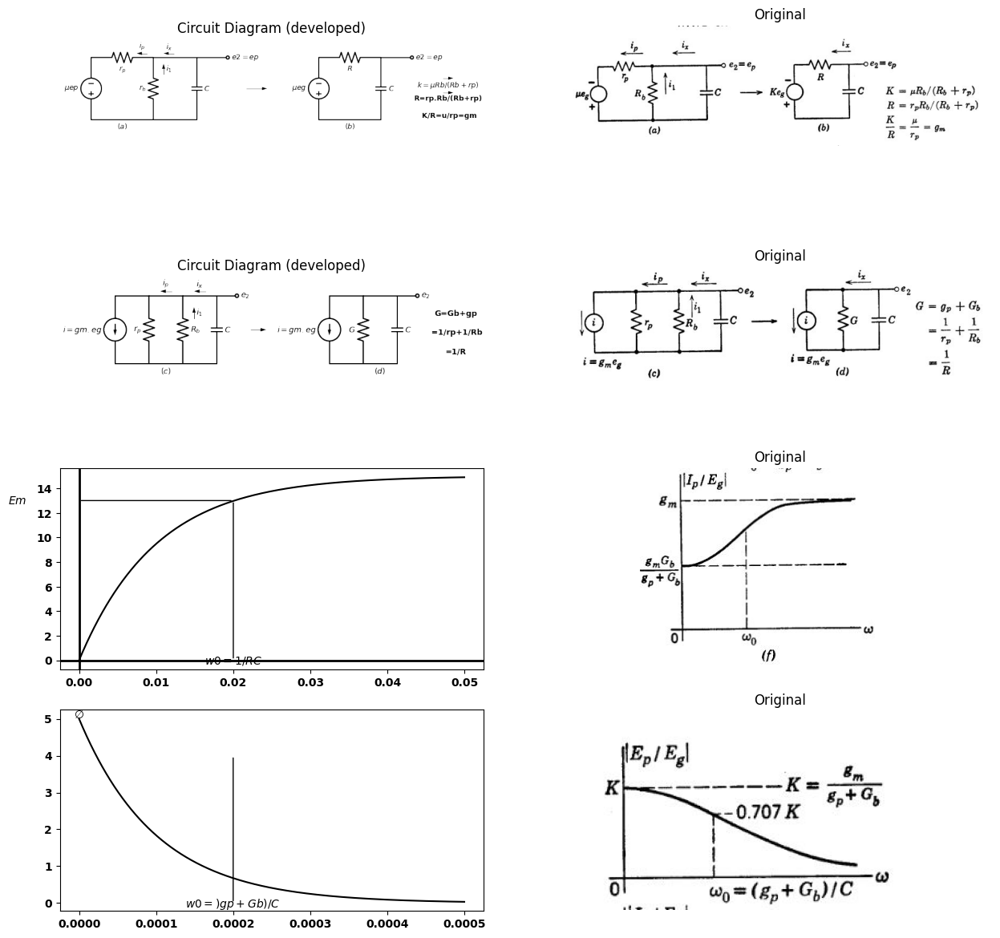

In [107]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label(r'$\mu ep$', 'top').reverse() 
d += (R1 := elm.Resistor().right().label('$r_p$', 'bottom'))
d += (R2 := elm.Resistor().down().label('$r_b$', 'top'))
l1 = d.add(elm.Line().left().label('$(a)$', 'bottom'))
l2 = d.add(elm.Line().right(d.unit*.7).at(R1.end))
d += (C1 := elm.Capacitor().down().label('$C$', 'bottom'))
l1 = d.add(elm.Line().left())
l2 = d.add(elm.Line().right(d.unit*.5).at(C1.start).dot(open=True).label('$e2 =ep$', 'right'))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_p$','top'). at((2.7,3.2))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','top'). at((4,3.2))
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('$i_1$','bottom'). at((3.5,2.2))
d += elm.Arrow().right().length(1).linewidth(1).color('black'). at((7.5,1.5))
d += elm.SourceV().up(d.unit*1).label(r'$\mu eg$', 'top').reverse().at((11,0))
d += (R4 := elm.Resistor().right().label('$R$', 'bottom'))
d += (C2 := elm.Capacitor().down().label('$C$', 'bottom'))
l1 = d.add(elm.Line().left().label('$(b)$', 'bottom'))
l1 = d.add(elm.Line().right(d.unit*.5).at(C2.start).dot(open=True).label('$e2=ep$','right'))
d += elm.Arrow().right().length(.5).linewidth(1).color('black'). at((17,2)).label(r'$k= \mu Rb/(Rb+rp)$', 'bottom')
d += elm.Arrow().right().length(.5).linewidth(1).color('black'). at((17,1.3)).label('R=rp.Rb/(Rb+rp)\n\n K/R=u/rp=gm', 'bottom')
d.save('images/8-25-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-25-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-25a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceI().up(d.unit*1).label('$i=gm.eg$', 'top').reverse() 
l1 = d.add(elm.Line().right(d.unit*.5))
d += (R1 := elm.Resistor().down().label('$r_p$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5))
l3 = d.add(elm.Line().right(d.unit*.5).at(l1.end))
d += (R2:=elm.Resistor().down(d.unit*1).color('black').label('$R_b$','bottom'))
l2 = d.add(elm.Line().left(d.unit*.5).label('$(c)$', 'bottom'))
l3 = d.add(elm.Line().right(d.unit*.5).at(R2.start))
d += (C1:=elm.Capacitor().down(d.unit*1).color('black').label('$C$','bottom'))
l2 = d.add(elm.Line().left(d.unit*.5))
l3 = d.add(elm.Line().right(d.unit*.3).at(C1.start).dot(open=True).label('$e_2$','right'))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_p$','top'). at((2.5,3.2))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','top'). at((4,3.2))
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('$i_1$','bottom'). at((3.5,2))
d += elm.Arrow().right().length(.7).linewidth(1).color('black'). at((6,1.5))
d += elm.SourceI().up(d.unit*1).label('$i=gm.eg$', 'top').reverse(). at((9.5,0)) 
l1 = d.add(elm.Line().right(d.unit*.5))
d += (R1 := elm.Resistor().down().label('$G$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5))
l3 = d.add(elm.Line().right(d.unit*.5).at(l1.end))
d += (C2:=elm.Capacitor().down(d.unit*1).color('black').label('$C$','bottom'))
l2 = d.add(elm.Line().left(d.unit*.5).label('$(d)$', 'bottom'))
l3 = d.add(elm.Line().right(d.unit*.3).at(C2.start).dot(open=True).label('$e_2$','right'))
d += elm.Arrow().right().length(.2).linewidth(1).color('white'). at((15,2.5)).label('G=Gb+gp\n\n =1/rp+1/Rb\n\n=1/R','bottom',color='black')
d.save('images/8-25-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-25-2.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-25b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

R = 1000     
C = 10e-6    
V0 = 15       
t_start = 0 
t_end = 5*R*C     
dt = (t_end - t_start) / 1000   
t = np.arange(t_start, t_end, dt)
Vc = V0 * (1 - np.exp(-t / (R * C)))
axs[2,0].text(.02, -.01, '$w0=1/RC$', ha='center', va='center')
axs[2,0].text(-.008, 13, '$Em$', ha='center', va='center')
axs[2,0].annotate('', xy=(0.02, 0), xytext=(0.02, 13), arrowprops=dict(arrowstyle='-'))
axs[2,0].annotate('', xy=(0, 13), xytext=(0.02, 13), arrowprops=dict(arrowstyle='-'))
axs[2,0].plot(t, Vc, color='black')
axs[2,0].axhline(0, color='black', linewidth=2)
axs[2,0].axvline(0, color='black', linewidth=2)
img_sample = mpimg.imread('images/8-25d.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
R = 1000     
C = .10e-6     
V0 = 5       

t_start = 0 
t_end = 5*R*C     
dt = (t_end - t_start) / 1000   

t = np.arange(t_start, t_end, dt)
Vc = V0 * np.exp(-t / (R * C))
axs[3,0].plot(t, Vc,color='black')
axs[3,0].text(.0002, -.03, '$w0=)gp+Gb)/C$', ha='center', va='center')
axs[3,0].text(.0000, 5.1, '$\emptyset$', ha='center', va='center')
axs[3,0].annotate('', xy=(0.0002, 0), xytext=(0.0002, 4), arrowprops=dict(arrowstyle='-'))
img_sample = mpimg.imread('images/8-25c.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

$E2=Ep=\frac{-gm.Eg}{gp+Gb+jwc}$

$\frac{E2}{E1}=\frac{Ep}{Eg}=\frac{-gm}{gp+Gb+jwc}$

$Ix=-E2jwc=\frac{jwcgmEg}{gp+Gb+jwc}$

$I1=-E2Gb=\frac{Gb.gmEg}{gp+Gb+jwc}$

$Ip=I1+Ix=\frac{(jwc+Gb)gmEg}{gp+Gb+jwc}$

$\frac{Ip}{Ep}= -(jwc+Gb)$


## Fig 8.25 Incremantal analysis of Triod with parallel RC Load and sine Wave input

given in Fig. 8.25(e). Plots of |E_{p} ٫ E_{g}| and |I_{p} ٫ E_{g}| vs. w are drawn in  Fig. 8.25(f) for G_{b} = g_{p} The voltage gain at omega = 0 has a magnitude  $$K = (\mu*R_b)/(R_b + r_p) = g_{m}/(g_{p} + G_{b})$$  $$(8.25)$$  and diminishes to zero as w approaches infinity. The bandwidth, $\omega_{0}$ is  defined as the point at which the gain E_{p} ٫ E_{g} has diminished to 0.707K.  
This point occurs when  $$\omega_{0}*C = (g_{p} + G_{b})$$  $$(8.26)$$  Since power gain is proportional to the square of voltage gain, this point  is usually called the half-power point.  




Text(0.5, 1.0, 'Original')

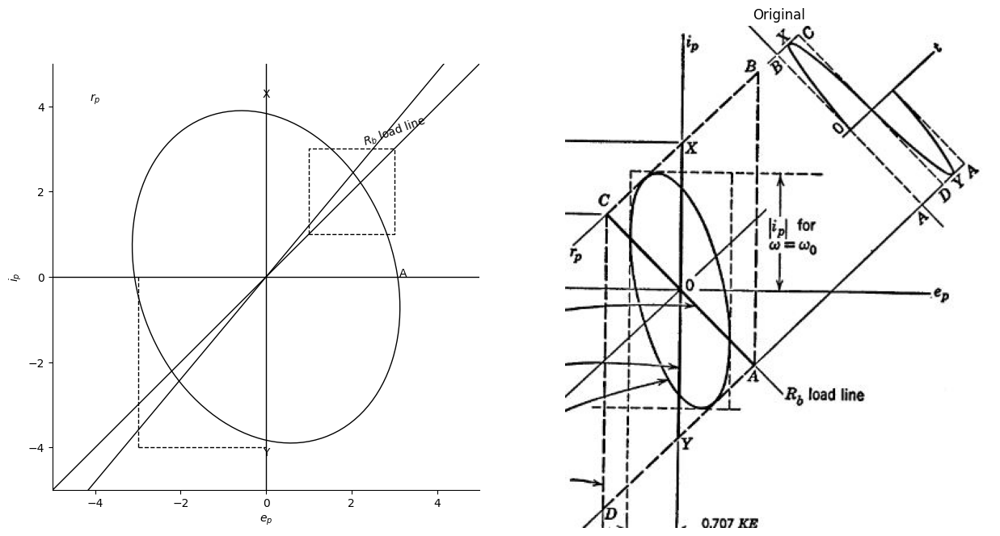

In [133]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from matplotlib.patches import Ellipse
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 15))
d = schemdraw.Drawing()


# 1. Coordinate System
axs[0].axvline(0, color='k', linewidth=1, label='$i_p$')  # Vertical axis
axs[0].axhline(0, color='k', linewidth=1, label='$e_p$')  # Horizontal axis
axs[0].set_xlabel('$e_p$')
axs[0].set_ylabel('$i_p$')

# 2.  Rb Load Line
ep = np.linspace(-5, 5, 100)  # Range for ep
Rb = 1  # Example Rb value. Adjust as needed.
ip = ep / Rb  # Simple linear relationship for demonstration
axs[0].plot(ep, ip, color='k', linewidth=1, label='$R_b$ load line')
axs[0].text(3, 3, '$R_b$ load line', rotation=20, ha='center', va='bottom')  # Position and rotate the label

# 3.  Ellipse
ellipse = Ellipse(xy=(0, 0), width=6, height=8, angle=20, edgecolor='k', facecolor='none')  # Adjust width, height, and angle
axs[0].add_patch(ellipse)

# 4.  Construction Lines
# Dashed lines from ellipse to axes. Example:
axs[0].plot([-3, -3], [-4, 0], linestyle='--', color='k', linewidth=1)
axs[0].plot([-3, 0], [-4, -4], linestyle='--', color='k', linewidth=1)

# 5. Additional lines
x = np.linspace(-5, 5, 100)
y = x * 1.2  # Example slope for the line.  Adjust as needed.
axs[0].plot(x, y, color='k', linestyle='-', linewidth=1)
axs[0].text(-4, 4, r'$r_p$', ha='center', va='bottom')

# 6.  Labels and Annotations
axs[0].text(0, 4.2, 'X', ha='center')
axs[0].text(0, -4.2, 'Y', ha='center')
axs[0].text(3.2, 0, 'A', ha='center')

# Dashed rectangle
axs[0].plot([1, 1, 3, 3, 1], [1, 3, 3, 1, 1], linestyle='--', color='k', linewidth=1)

# Axes configurations
axs[0].set_xlim(-5, 5)
axs[0].set_ylim(-5, 5)
axs[0].set_aspect('equal', adjustable='box')
axs[0].spines['top'].set_visible(False)
axs[0].spines['right'].set_visible(False)
img_sample = mpimg.imread('images/8-26.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

## Fig. 8.26. Locus of operating point for incremental analysis. 

In the locus plot (in vs. ep) given in Fig. 8.26, the origin 0 for incre- mental quantities corresponds to the quiescent point for total quan- tities. This plot is drawn for Ggp, and shows again the bounding  locus ABCDA corresponding to a square wave with a low repetition  frequency and the same peak-to-peak amplitude as the sine wave.  
The elliptical locus shown is drawn for $w = ωρ$ The peak value of  
$e_p$ is 0.707KE, and the peak value of ip is determined from the expression  for ip with $w = wo$. The ellipse must be tangent to the lines of constant  $e_c$ corresponding to the peak-to-peak input voltage variation. The  maximum horizontal excursion of the ellipse occurs on the $R_s$ load line. 
Since the plate voltage is not changing at the voltage peaks $(deb/dt = 0)$,  the capacitor current is zero and the plate current is determined solely  by Rb.

# 8.19 RC-Coupled Triodes with Rectangular Input Waveform  (Intervals Large Compared with Time Constants)  

  

The analysis of the triode with parallel RC load is readily extended to  the RC-coupled amplifier. The coupling capacitor serves primarily to  provide d-c isolation between coupled stages. This eases the problem  of providing appropriate polarizing voltages for the electrodes of succes- sive stages. If d-e isolation is the only function performed by the  capacitor, the time constants are made large compared with the in- tervals, and hence the calculations are needed only to determine the  distorting effects of the capacitor on the output waveform. In other  cases the value of the capacitor is a design parameter calculated to  produce a given wave-shaping effect.


In the circuit of Fig. 8.27 (a), we are merely connecting a resistance in  series with the capacitor instead of connecting the capacitor directly to  ground as in Fig. 8.23 or 8.24. The load on the plate circuit of the first  triode is therefore the d-c load resistance Ro in parallel with a series  combination of C and the piecewise-linear resistance R, where  
$R=Rg(ec < 0)$  $$(8.27)$$
$R=Rg.rg/(Rg+rg)(ec > 0)$ $$(8.28)$$  
This piecewise-linear resistive load is indicated graphically by the sketch  of $ix vs. e2.$  
Pertinent equations for a graphical analysis of the circuit are given in  Fig. 8.27 (b). The total tube current is is here expressed in terms of i₁  and iz. The current i₁ is represented graphically by the d-c load line  plotted in Fig. 8.27 (c). The capacitor current  
$ix=ex-eb)/R$ $$(8.29)$$  
is represented by a piecewise-linear load line drawn from the voltage ex,  as indicated by dotted lines in Fig. 8.27 (c). Since the capacitor voltage  is time-varying, this load line slides back and forth along the horizontal  axis. With a rectangular input voltage, indicated by the waveform e1,  the maximum excursion of ex lies between Ebb and Ea. 


Let us now examine the operation of the circuit, assuming that the  intervals $\delta_{1}$ and $\delta_{2}$ are long enough to permit completion of the RC  transients. At point A the tube is cut off; hence $i_{b} = 0$ $e_b =E_bb$ , $e_x =E_bb$ , and $e_{2} = 0 $The instantaneous transition to point B, where  

Text(0.5, 1.0, 'Original')

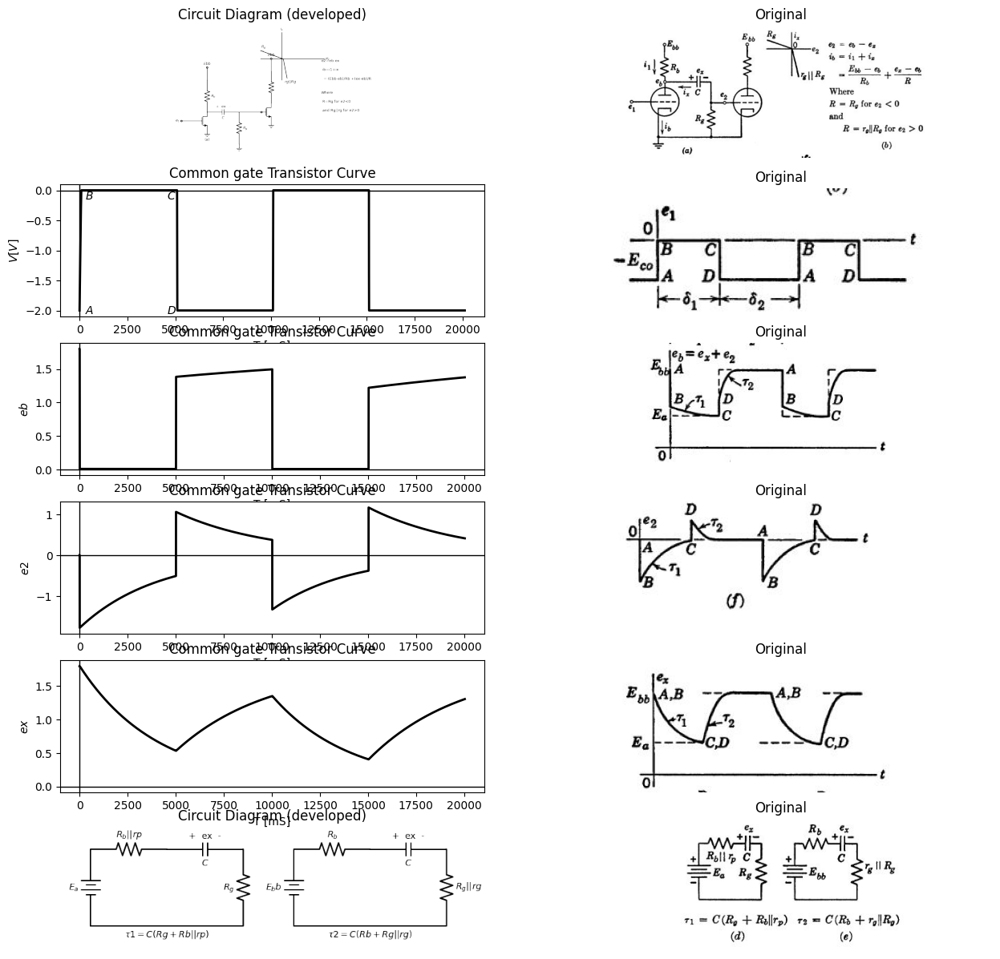

In [52]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
G = d.add(elm.Ground().at(M1.source).label('(a)','bottom'))
d += (R1 := elm.Resistor().up().label('$R_b$', 'bottom').at(M1.drain))
d += (C1 := elm.Capacitor().right().label('$C$', 'bottom').at(M1.drain).label('+  ex   -', 'top'))
d += (R2 := elm.Resistor().down().label('$R_g$', 'bottom'))
G = d.add(elm.Ground().at(R2.end))
l2 = d.add(elm.Line().up(d.unit*.4).dot(open=True).label('$Ebb $','right').at(R1.end))
l3 = d.add(elm.Line().right(d.unit*.7).dot(open=True).at(R2.start))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
G = d.add(elm.Ground().at(M2.source))
d += (R3 := elm.Resistor().up().at(M2.drain))
l4 = d.add(elm.Line().up(d.unit*.4).dot(open=True).label('$Ebb $','right').at(R3.end))
l5 = d.add(elm.Line().up(d.unit*1.5).at((7,3)).label('$i_x $','right'))
l6 = d.add(elm.Line().right(d.unit*2).at((5,5)).label('$e_2 $','right'))
l7 = d.add(elm.Line().right(d.unit*.2).color('white').at((5,5.8)).label('$R_g $','top',color='black'))
l8 = d.add(elm.Line().right(d.unit*.2).at((6.55,5)).color('black'))
l9 = d.add(elm.Line().right(d.unit*.2).at((7.5,3.2)).color('white').label('$rg||Rg $','bottom',color='black'))
l10 = d.add(elm.Line().right(d.unit*.2).endpoints(l7.start, l8.end).color('black'))
l10 = d.add(elm.Line().right(d.unit*.2).endpoints(l8.end, l9.start).color('black'))
l8 = d.add(elm.Line().right(d.unit*.2).at((10,4)).color('white').label('e2=eb-ex\n\n ib=i1+ix\n\n  = (Ebb-eb)/Rb +(ex-eb)/R','right',color='black'))
l8 = d.add(elm.Line().right(d.unit*.2).at((10,1)).color('white').label('Where\n\n R=Rg for e2<0\n\n and Rg||rg for e2>0','right',color='black'))
d.save('images/8-27-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-27-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-27a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=2)
axs[1,0].text( 500, -2, '$A$', ha='center', va='center')
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].text( 4800, -2, '$D$', ha='center', va='center')
axs[1,0].text( 500, -0.1, '$B$', ha='center', va='center')
axs[1,0].text( 4800, -0.1, '$C$', ha='center', va='center')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$V [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-27c.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_kOhm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_uF)
circuit.R(2, 'e2', circuit.gnd, 4@u_kOhm)
circuit.R(3, 'n1', 'Ebb', 4@u_kOhm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[2,0].plot(analysis['eb'],'black',linewidth=2)
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$eb$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-27d.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 800@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 1@u_uF)
circuit.R(2, 'e2', circuit.gnd, 4@u_kOhm)
circuit.R(3, 'n1', 'Ebb', 400@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis['e2'],'black',linewidth=2)
axs[3,0].set_title('Common gate Transistor Curve') 
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('$e2$')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-27e.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 800@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 1@u_uF)
circuit.R(2, 'e2', circuit.gnd, 4@u_kOhm)
circuit.R(3, 'n1', 'Ebb', 400@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[4,0].plot(analysis['eb']-analysis['e2'],'black',linewidth=2)
axs[4,0].set_title('Common gate Transistor Curve') 
axs[4,0].set_xlabel('T [mS]')
axs[4,0].set_ylabel('$ex$')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-27f.JPG')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.Battery().up(d.unit*1).label('$E_a$', 'top').reverse()
d += (R1 := elm.Resistor().right().label('$R_b||rp$', 'top'))
d += (C1 := elm.Capacitor().right().label('$C$', 'bottom').label('+  ex  -', 'top'))
d += (R2 := elm.Resistor().down().label('$R_g$', 'top'))
l1 = d.add(elm.Line().left().length(6).label(r'$\tau1 =C(Rg+Rb||rp)$', 'bottom'))
d += elm.Battery().up(d.unit*1).label('$E_bb$', 'top').reverse().at((8,0))
d += (R1 := elm.Resistor().right().label('$R_b$', 'top'))
d += (C1 := elm.Capacitor().right().label('$C$', 'bottom').label('+  ex  -', 'top'))
d += (R2 := elm.Resistor().down().label('$R_g||rg$', 'bottom'))
l1 = d.add(elm.Line().left().length(6).label(r'$\tau2 =C(Rb+Rg||rg)$', 'bottom'))
d.save('images/8-27-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-27-3.png')
axs[5,0].imshow(img)
axs[5,0].axis('off')  # Hide axes for image display
axs[5,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-27g.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

## Fig.8.27 Rectangular-wave behavior of RC coupling circuit ($\delta1>5\tau1$,$\delta2>5\tau2$ )

voltage is less than the capacitor voltage, iz is positive, and capacitor C  discharges in accordance with the circuit shown in Fig. 8.27 (d). As ex  decreases from Ebb to Ea, the R, load line for ix slides to the left, and the  composite load line Rb||Rg, shifts downward parallel to itself. Since  $e_{epsilon} = 0 $during the interval 81, the operating point moves along the line  $e_{c} = 0$ from B to C.  
At the end of interval 81, e₁ changes instantaneously (C to D) to a  value more negative than is required to effect plate-current cutoff. This  change causes the plate voltage to rise toward Est. Again, since Delta*e_{x} = 0  we must have Der De₂ at the transition. The circuit given in Fig.  8.27 (e) applies during the interval 82. For the instantaneous transition  from C to D, the variational resistive load on the tube is ro||RoRb,  because ez is positive during the interval $\delta2$. As the capacitor recharges,  e2 rises from Ea to Ebb (D to A) to complete the operating cycle. The  triode does not enter into the calculations during the interval 82, since  $i_{b} = 0$ and therefore $ix = i1.$ The operating point moves along the  
i_{b} = 0 axis as the iz load line slides to the right, and maintains $i₁ = -i2$  as ex increases.  
The circuit models for the two intervals $\delta1$ and $\delta2$ shown in (d) and  (e) are similar to those discussed in Art. 8.12, so the dimensions on the  e2 waveform in (f) may be found using the method discussed in that  article. For the time constants chosen here, the e₂ waveform is a series  of alternately positive and negative spikes at the transitions of the input waveform. If $\tau1$ and $\tau2$ are made very much smaller than $\delta1$ and $\delta2$, these  spikes approximate the derivative of the input waveform. Under these  conditions the circuit is also called a peaking circuit. In the following  article we shall consider the long-time-constant case for which the  transients do not go to completion.  



# 8.20 RC Coupled Triodes with Rectangular Input Waveform  (Intervals Small Compared with Time Constants) 

 
 
Using the same circuit as that of Fig. 8.27 (a), let us consider the case  where 81 is less than 571 and 82 is less than 572. A piecewise-linear model  of the circuit is shown in Fig. 8.28 (a), and the two linear circuits that  apply during the intervals 8 and 82 are shown in Fig. 8.28 (b) and (c),  respectively. The rectangular input waveform is again assumed to  drive the first tube into the grid-current region during interval d₁ and  into the plate-current cutoff region during 82. Correspondingly, the  capacitor voltage will charge to a value Ex, and discharge to a value Ez.  These values can be calculated from the two linear circuits by the method outlined in Fig. 8.15. Note that output voltage e₂ does not reach  zero at the end of each interval, since the exponential charge and discharge  



Text(0.5, 1.0, 'Original')

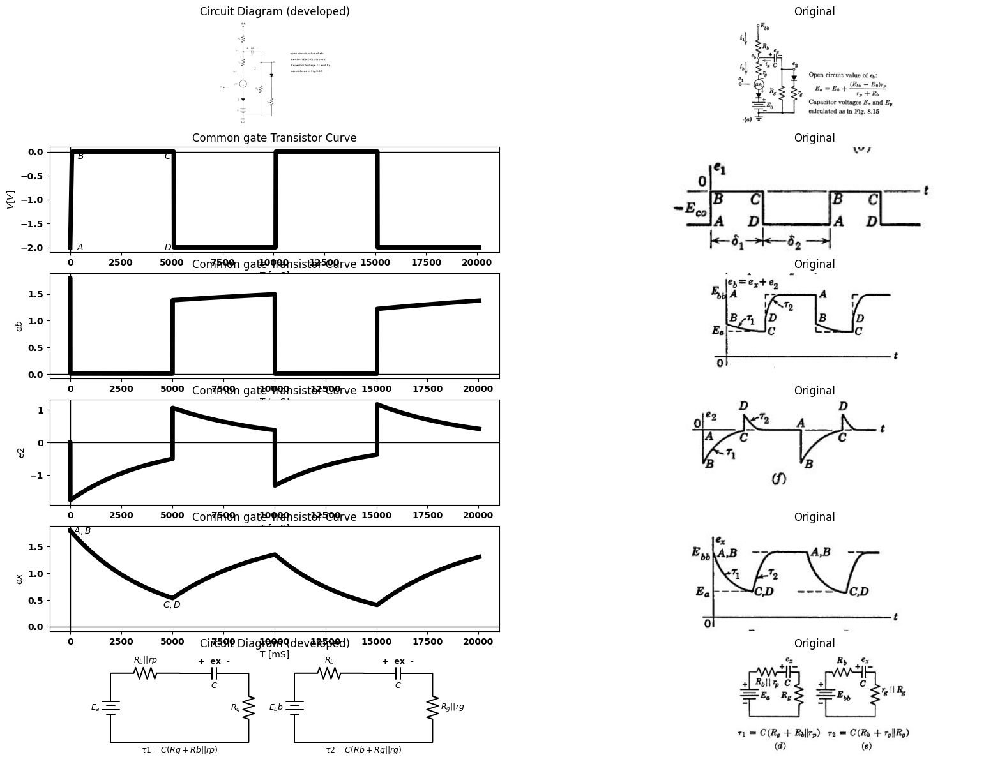

In [109]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d +=  (E1:=elm.SourceV().up(d.unit*1).label(r'$\mu e1$', 'top').reverse()) 
d += (R1 := elm.Resistor().up().label('$r_p$', 'top').dot(open=True))
d += (R2 := elm.Resistor().up(d.unit*1.2).label('$R_b$', 'top').dot(open=True).label('Ebb', 'right'))
d += (C1 := elm.Capacitor().right(d.unit*.85).label('$C$', 'bottom').at(R1.end).label('+   ex   -', 'top'))
D2 = d.add(elm.Diode(fill=True).down(d.unit*.5).label('D ','top').at(E1.start))
d += elm.Battery().down(d.unit*.5).label('$E_0$', 'top')
G = d.add(elm.Ground().label('(a)','bottom'))
l1 = d.add(elm.Line().right().length(2.5).at(G.start))
d += (R1 := elm.Resistor().up(d.unit*2.5).label('$R_g$', 'top').dot())
l2 = d.add(elm.Line().up().length(1.5))
l3 = d.add(elm.Line().right().length(1.5).at(l2.start).dot(open=True).label('$e_2$', 'right'))
D2 = d.add(elm.Diode(fill=True).down(d.unit*1.2))
d += (R3 := elm.Resistor().down(d.unit*1.3).label('$r_g$', 'top'))
l1 = d.add(elm.Line().left().length(1.5))
l1 = d.add(elm.Line().left().length(.7).dot(open=True).at((-2,1)).label('$e_1$', 'left'))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.75,6.5))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_b$','top'). at((-1,3.5))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','top'). at((2,3.5))
d += elm.Arrow().right().length(.5).linewidth(1).color('white').label('open circuit value of eb:\n\n Ea=E0+(Eb-E0)rp/(rp+rb)\n\n Capacitor Voltage Ex and Ey\n\n caculate as in Fig.8.15','right',color='black'). at((6,4.5))
d.save('images/8-28-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-28-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-28a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].text( 500, -2, '$A$', ha='center', va='center')
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].text( 4800, -2, '$D$', ha='center', va='center')
axs[1,0].text( 500, -0.1, '$B$', ha='center', va='center')
axs[1,0].text( 4800, -0.1, '$C$', ha='center', va='center')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$V [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-27c.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_kOhm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_uF)
circuit.R(2, 'e2', circuit.gnd, 4@u_kOhm)
circuit.R(3, 'n1', 'Ebb', 4@u_kOhm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[2,0].plot(analysis['eb'],'black',linewidth=5)
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$eb$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-27d.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 800@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 1@u_uF)
circuit.R(2, 'e2', circuit.gnd, 4@u_kOhm)
circuit.R(3, 'n1', 'Ebb', 400@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[3,0].plot(analysis['e2'],'black',linewidth=5)
axs[3,0].set_title('Common gate Transistor Curve') 
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('$e2$')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-27e.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 800@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 1@u_uF)
circuit.R(2, 'e2', circuit.gnd, 4000@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 400@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[4,0].plot(analysis['eb']-analysis['e2'],'black',linewidth=5)
axs[4,0].set_title('Common gate Transistor Curve') 
axs[4,0].text( 5000, .4, '$C,D$', ha='center', va='center')
axs[4,0].text( 600, 1.8, '$A,B$', ha='center', va='center')
axs[4,0].set_xlabel('T [mS]')
axs[4,0].set_ylabel('$ex$')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-27f.JPG')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.Battery().up(d.unit*1).label('$E_a$', 'top').reverse()
d += (R1 := elm.Resistor().right().label('$R_b||rp$', 'top'))
d += (C1 := elm.Capacitor().right().label('$C$', 'bottom').label('+  ex  -', 'top'))
d += (R2 := elm.Resistor().down().label('$R_g$', 'top'))
l1 = d.add(elm.Line().left().length(6).label(r'$\tau1 =C(Rg+Rb||rp)$', 'bottom'))
d += elm.Battery().up(d.unit*1).label('$E_bb$', 'top').reverse().at((8,0))
d += (R1 := elm.Resistor().right().label('$R_b$', 'top'))
d += (C1 := elm.Capacitor().right().label('$C$', 'bottom').label('+  ex  -', 'top'))
d += (R2 := elm.Resistor().down().label('$R_g||rg$', 'bottom'))
l1 = d.add(elm.Line().left().length(6).label(r'$\tau2 =C(Rb+Rg||rg)$', 'bottom'))
d.save('images/8-27-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-27-3.png')
axs[5,0].imshow(img)
axs[5,0].axis('off')  # Hide axes for image display
axs[5,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-27g.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

## Fig. 8.28. Locus and waveforms for coupling circuit with rectangular-wave input  ($\delta1>5\tau1$,$\delta2>5\tau2$ ).  

currents do not reach zero. For the same reason, es reaches  neither Ea nor Ebb. These effects may be seen both from the waveforms  and from the locus plot given in Fig. 8.28(d). Since ez does not reach its extreme values Ea and Est, the locus is restricted to a smaller portion  of the is vs. es plane.  
As en switches from A to B, the plate voltage decreases. Since ez  remains constant, e₂ falls by the same amount as es. When e₂ crosses  zero at point A', we have erez Ey. At this point the effective load  resistance for the triode changes from ro||Ro||Rs to Ro||Rb. Note that  whenever is exceeds in, the locus is above the Rs load line and iz is  positive. The piecewise-linear load lines shown by dotted lines at E  and E represent the contribution of iz to is for these specific values of  ex. For intermediate values of ex, the load line for iz slides along the  horizontal axis. Correspondingly, the piecewise-linear load line deter- mining total current is slides along Ro with the break moving from A' toward C' as time elapses from B to C. During this time, the operating  point is sliding along the ec 0 line from B to C. When e₁ switches  from C to D, the load transition at C' corresponds to e2 = i = 0 and  eb=ex =Ex. Closing the locus from D to A, we have ex increasing  from Ex to Ey, with ib = 0 and ix = i1.  
Determination of pertinent voltage values on the waveforms of es and  e2 follow readily, once E and Ey are calculated. The circuits do not  differ from those of Fig. 8.15, except that the resistive voltage drop is  divided into two parts here. Thus the total resistances of the charge and  discharge circuits in Fig. 8.28 correspond to R₁ and R2 in Fig. 8.15.  


# 8.21 Linear Amplification with RC-Coupled Triodes 


 
For the conditions described by Figs. 8.27 and 8.28, the waveform of  e2 has a negative average value because the resistance between grid and  cathode of the second triode is R, for negative values of e2, and ro||R, for  positive values of e2. This average voltage (sometimes called grid-leak  bias) can be computed from Ez and Ey, as indicated in Fig. 8.15(e). The  change in loading of the plate circuit of the first triode under these  conditions, changes the voltage gain during the cycle and therefore 
results in waveform distortion. To amplify the input waveform without  distortion, each triode must be operated in a single state: namely,  with e between 0 and - Ebb٫µ. In order that this requirement may  be satisfied, the amplitude of the input waveform must be suitably  restricted, and a negative polarizing voltage must be applied to the grid  of the second triode. In addition, the coupling time constant must be  large enough to prevent distortion of the input waveform.  
The circuit shown in Fig. 8.29 (a) is like that of Fig. 8.27 (a), with a  polarizing voltage added for the grid of the second triode. This voltage 


Text(0.5, 1.0, 'Original')

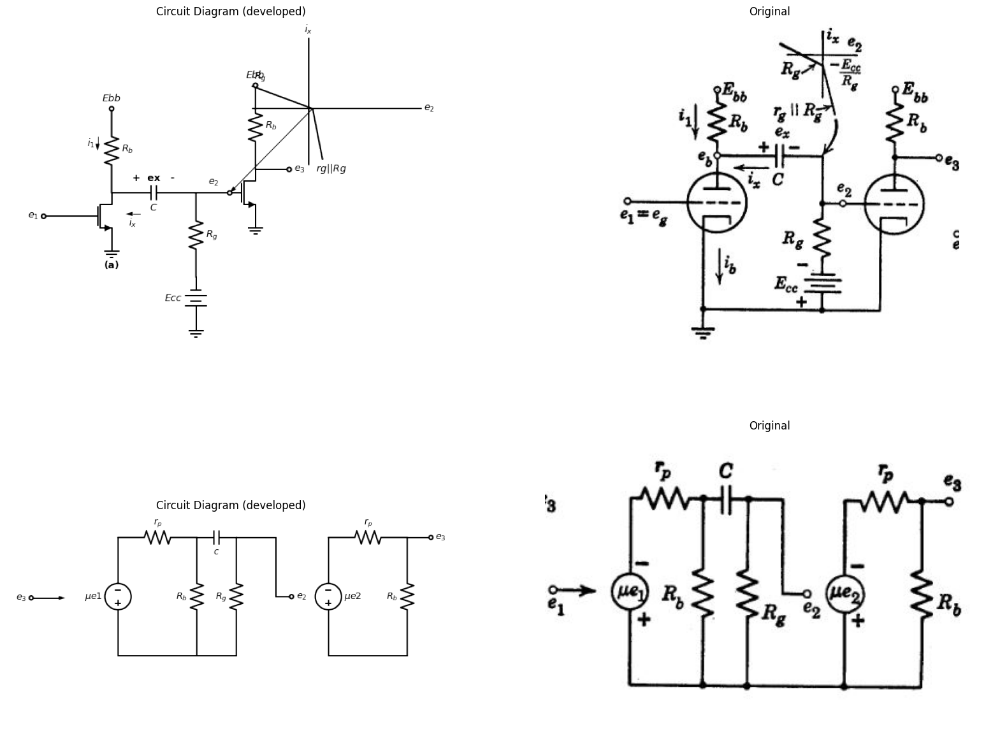

In [110]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
G = d.add(elm.Ground().at(M1.source).label('(a)','bottom'))
d += (R1 := elm.Resistor().up().label('$R_b$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
d += (C1 := elm.Capacitor().right().label('$C$', 'bottom').at(M1.drain).label('+  ex   -', 'top'))
d += (R2 := elm.Resistor().down().label('$R_g$', 'bottom'))
d += elm.Battery().down(d.unit*.5).label('$Ecc$', 'top').reverse()
G = d.add(elm.Ground())
l2 = d.add(elm.Line().right(d.unit*.4).dot(open=True).label('$e_2 $','top').at(R2.start))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
G = d.add(elm.Ground().at(M2.source))
d += (R3 := elm.Resistor().up().label('$R_b$', 'bottom').at(M2.drain).dot(open=True).label('$Ebb$', 'right'))
l3 = d.add(elm.Line().right(d.unit*.4).dot(open=True).label('$e_3 $','right').at(M2.drain))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.5,2))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','bottom'). at((1,-.75))
l5 = d.add(elm.Line().up(d.unit*1.5).at((7,1)).label('$i_x $','right'))
l6 = d.add(elm.Line().right(d.unit*2).at((5,3)).label('$e_2 $','right'))
l7 = d.add(elm.Line().right(d.unit*.2).color('white').at((5,3.8)).label('$R_g $','top',color='black'))
l8 = d.add(elm.Line().right(d.unit*.2).at((6.55,3)).color('black'))
l9 = d.add(elm.Line().right(d.unit*.2).at((7.5,1.2)).color('white').label('$rg||Rg $','bottom',color='black'))
l10 = d.add(elm.Line().right(d.unit*.2).endpoints(l7.start, l8.end).color('black'))
l10 = d.add(elm.Line().right(d.unit*.2).endpoints(l8.end, l9.start).color('black'))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').endpoints(l8.end, l2.end)
d.save('images/8-28-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-28-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-29a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1.5).label('$\mu e1 $', 'top').reverse()
d += (R1 := elm.Resistor().right().label('$r_p$', 'top'))
d += (R2 := elm.Resistor().down(d.unit*1.5).label('$R_b$', 'top'))
l2 = d.add(elm.Line().left(d.unit*1))
d += (C1:=elm.Capacitor().right(d.unit*.5).color('black').label('$c$','bottom').at(R2.start))
d += (R3 := elm.Resistor().down(d.unit*1.5).label('$R_g$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.5))
l2 = d.add(elm.Line().right(d.unit*.5).at(R3.start))
l2 = d.add(elm.Line().down(d.unit*.75))
l2 = d.add(elm.Line().right(d.unit*.2).dot(open=True).label('$e_2$', 'right'))
d += elm.SourceV().up(d.unit*1.5).label('$\mu e2 $', 'bottom').reverse().at((8,0))
d += (R3 := elm.Resistor().right().label('$r_p$', 'top'))
d += (R4 := elm.Resistor().down(d.unit*1.5).label('$R_b$', 'top'))
l2 = d.add(elm.Line().left(d.unit*1))
l2 = d.add(elm.Line().right(d.unit*.3).dot(open=True).at(R3.end).label('$e_3$', 'right'))
l2 = d.add(elm.Line().left(d.unit*.1).dot(open=True).at((-3,2.2)).label('$e_3$', 'left'))
d += elm.Arrow().right().length(1).linewidth(2).color('black'). at((-3,2.2))
d.save('images/8-28-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-28-2.png')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-29b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

Text(0.5, 1.0, 'Original')

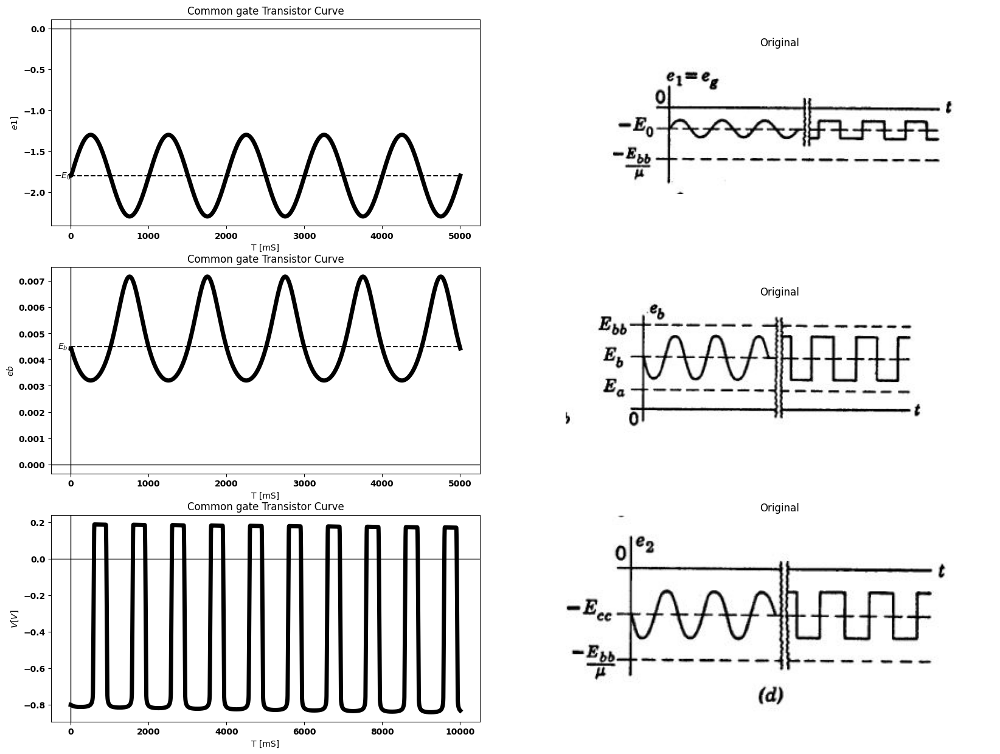

In [111]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
circuit = Circuit('NMOS')
circuit.SinusoidalVoltageSource(1, 'e1', 'VGS', amplitude=.5@u_V,frequency=1@u_kHz)
#pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_kOhm)
circuit.MOSFET(2, 'e3', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_uF)
circuit.R(2, 'e2', 'n2', 4@u_kOhm)
circuit.R(3, 'e3', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, -1.8@u_V)
circuit.V(4, circuit.gnd, 'n2', 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=5@u_ms)
axs[0,0].plot(analysis['e1'],'black',linewidth=5)
axs[0,0].set_title('Common gate Transistor Curve') 
axs[0,0].plot([0, 5000], [-1.8, -1.8], color='black', linestyle='--', label='Membership = 1')
axs[0,0].text( -100, -1.8, '$-E_0$', ha='center', va='center')
axs[0,0].set_xlabel('T [mS]')
axs[0,0].set_ylabel('$e1]$')
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-29d.JPG')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
circuit = Circuit('NMOS')
circuit.SinusoidalVoltageSource(1, 'e1', 'VGS', amplitude=.5@u_V,frequency=1@u_kHz)
#pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_kOhm)
circuit.MOSFET(2, 'e3', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_uF)
circuit.R(2, 'e2', 'n2', 4@u_kOhm)
circuit.R(3, 'e3', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, 1.8@u_V)
circuit.V(4, circuit.gnd, 'n2', 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=5@u_ms)
axs[1,0].plot(analysis['eb'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].plot([0, 5000], [0.0045, 0.0045], color='black', linestyle='--', label='Membership = 1')
axs[1,0].text( -100, 0.0045, '$E_b$', ha='center', va='center')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$eb$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-29e.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
circuit.SinusoidalVoltageSource(1, 'e1', 'VGS', amplitude=.5@u_V,frequency=1@u_kHz)
#pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_kOhm)
circuit.MOSFET(2, 'e3', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 20@u_uF)
circuit.R(2, 'e2', 'n2', 5000@u_Ohm)
circuit.R(3, 'e3', 'Ebb', 4@u_kOhm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(3, 'VGS', circuit.gnd, .8@u_V)
circuit.V(4, circuit.gnd, 'n2', .8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
axs[2,0].plot(analysis['e2'],'black',linewidth=5)

axs[2,0].set_title('Common gate Transistor Curve') 

axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$V [V]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-29f.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig. 8.29. Small-signal linear amplification with RC-coupled triodes. (a) Linear  amplifier circuit; (b) Plate circuit of first triode for e₁ = eo=-E0+ E sin wt;  (c) Incremental model; (d) Waveforms (assuming ex approximately constant at Eb+Ecc)  

has the effect of shifting the current at the break point of the piecewise- linear load R to the point  
     $ix=-\frac{Ecc}{Rg}$ $$(8.29)$$  
The locus plot for the plate circuit of the first triode, Fig. 8.29(b),  assumes that the variational amplitude E is small enough to preserve  linear operation throughout the circuit. When the piecewise-linear load  line is plotted on the is vs. es plane, the break point occurs at a voltage  Es+ Ecc. The polarizing voltage Ece must be sufficiently negative to  shift the break point of the broken load line outside the range of variation  of es shown by the heavy line.  
The incremental circuit model for the two triode stages is shown in  Fig. 8.29 (c). If the time constant  
$\tau$ = $C[Rg+rp||Rb] $ $$(8.30)$$
is many times greater than the period of the input waveform, the changes  in ex will be very small during the cycle. In the limit, the capacitor  voltage is constant (zero in the incremental circuit). In the circuit of  Fig. 8.29 (a) this amounts to replacement of the coupling capacitor C  by a battery whose voltage is $Eb + Eco.$ 
Waveforms for linear operation are given in Fig. 8.29(d) for both  sinusoidal and square-wave input voltage variations. The waveform of  ез (not shown) would be an inverted and amplified replica of e2. 


# 8.22 Effects of Shunt Capacitance on  Coupling-Circuit Behavior  

The model of the RC coupled circuit used in the preceding articles has  represented only the explicit circuit components (vacuum tubes, re- sistors, and capacitors). However, any physical structure consisting of  such components will also include implicit stray elements that have a  significant effect on circuit operation when high frequencies or rapid  changes are present in the input voltage. For example, the lines con- necting elements on a circuit diagram usually signify ideal conductors  that offer no impedance to the passage of current. Actual interconnect- ing wires have both resistance and inductance.  
The major circuit elements themselves embody stray parameters (for  example, the interelectrode capacitance of the triode). The capacitance  between any component and the metal chassis (called ground) may also  be important. The total capacitance between almost any node of the 


circuit and the chassis will usually be several micromicrofarads for  typical circuit construction. The principal effect of stray capacitances  can be determined by simple approximate calculations.  
An incremental model for the RC coupling circuit is shown in Fig.  8.30(a). This circuit assumes that the major effects of the stray ele- ments are adequately represented by a capacitance C₁ from the plate  of the first triode to ground, and by a capacitance C2 from the grid of  the second triode to ground. This model represents the actual circuit  fairly well, particularly if the tubes used are pentodes.  
The complex expression for E2 in terms of E₁ and the circuit param- eters is given in Fig. 8.30(a). Although the result can be written by  inspection of the circuit, it is cumbersome for purposes of calculation or  plotting. This expression can be reduced to three very simple expres- sions by making a few assumptions. In a practical circuit we shall  nearly always have C much larger than C₁ or C2. If C is large, it has a  very low a-c impedance for all but low frequencies. If C₁ and C₂ are  small, they have a very high impedance for all but high frequencies.  We therefore expect to find a range of frequencies (usually called mid- band) for which the resistive elements alone yield a good approximation  to e2. Thus 


$E2\ =\frac{-gm.E1}{gp+Gg+Gb}$ $$(8.31)$$

for $\omega$ in the vicinity of $\sqrt{\omega c.\omega s}$. The circuit and the corresponding plot  
of|E2/E1| vs. $\omega$ are shown in Fig. 8.30(b).  
For values of w approaching zero, we know that the reactance of  coupling capacitor C cannot be neglected; hence the circuit and curve  given in Fig. 8.30(c) are more representative of the true situation for low  frequencies. The equation for E₂ becomes
  $$E2\ =\ \frac{-gm.E1.Rg}{(gp+Gb)(Rg+\frac{1}{j\omega c})+1}\ for\ \omega<\sqrt{\omega c.\omega s}$$  $$(8.32)$$                                                                                                                                                                                                                                            
Similarly, for high frequencies the shunting effect of the decreasing  impedances of C₁ and C2 cannot be neglected. The circuit and curve  shown in Fig. 8.30(d) are therefore more accurate for high frequencies.  Here $$E2\ =\ \frac{-gm.E1}{G+j\omega Cs}\ for\ \omega>\ \sqrt{\omega c.\omega s}$$ $$(8.33)$$  Where $$G=gp+Gb+Gg$$ $$(8.34)$$
$$E2=\frac {-gm.E1[\frac {1}{Gg+jω∁2}]}{[(gp+Gb+jω∁1)+(\frac {1}{\frac {1}{jω∁}+\frac {1}{Gg+jω∁2})}][\frac {1}{jω∁}+\frac {1}{Gg+jω∁2}]}$$ $$(8.35)$$
The combined effects of coupling capacitor and shunt capacitors appear  in the curve shown in Fig. 8.30(e). This curve, obtained very easily  from the three separate circuits, is a good approximation to the curve  obtained by plotting the expression given in Fig. 8.30(a). If C, C1, and  C₂ are comparable in magnitude, w, and w, are not widely separated,  and the approximations are not as good.  
The step response of the coupling circuit can be calculated in a similar  manner, as outlined in Fig. 8.31. Since the circuit has two independent capacitor voltages, we expect to find a transient solution with two  exponential terms, each of which has a different time constant.  
For the resistive approximation given in Fig. 8.31(b), the step is  reproduced with no change other than a polarity reversal and a change  in amplitude. The circuit with the coupling capacitor alone, Fig. 8.31 (c),  produces a slowly decaying exponential. The stray capacitances in the  circuit of Fig. 8.31 (d) inhibit the instantaneous rise of the step input.  The combined effects of C and C. are shown in Fig. 8.31 (e); and for  C$\gg $Cs., this is a very good approximation to the actual waveform.  Calculating e2 from the complete circuit yields an expression consisting  of the sum of two exponentials with time constants slightly different  from $\tau c$ and $\tau s$. The exact plot would fall below the approximate one  during the rapid rise and slightly above it during the long decay. Our  approximation assumes no appreciable change in voltage on the coupling  capacitor during the rise and neglects the current through the shunt  capacitances during the decay. 



Text(0.5, 1.0, 'Original')

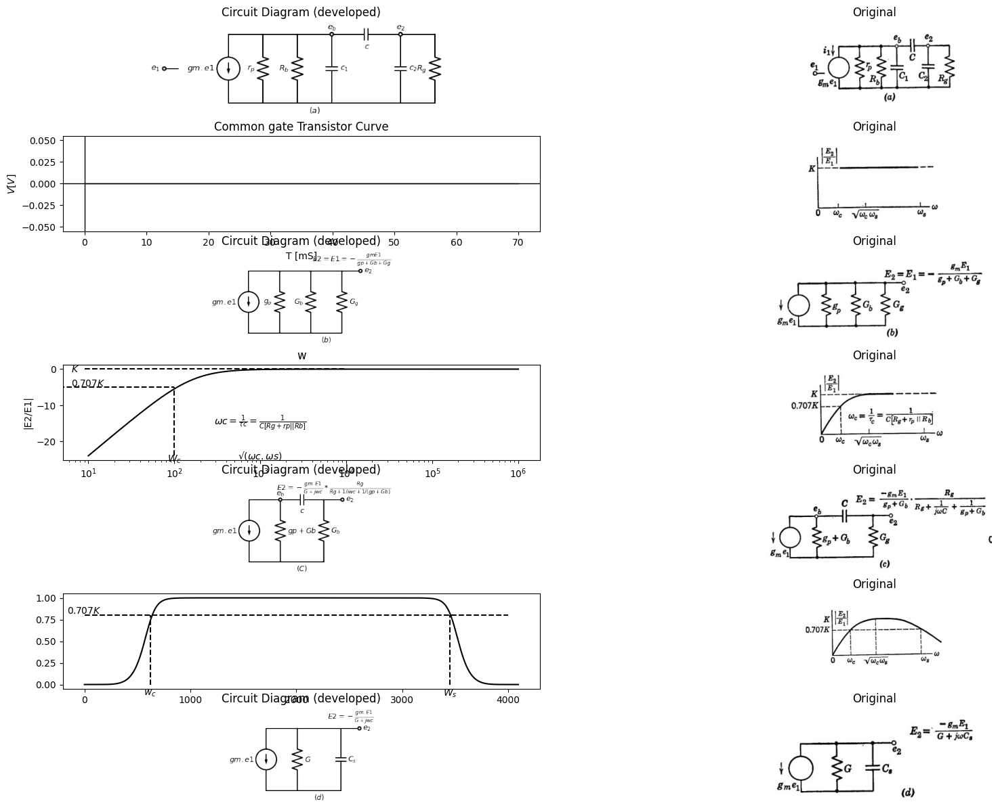

In [87]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(7, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += elm.SourceI().up(d.unit*1).label('$gm.e1$', 'top').at((8,0)) .reverse()
l4 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Resistor().down().label('$r_p$', 'top'))
l5 = d.add(elm.Line().left(d.unit*.5))
l7 = d.add(elm.Line().right(d.unit*.5).at(R2.start))
d += (R4 := elm.Resistor().down(d.unit*1).label('$R_b$', 'top'))
l6 = d.add(elm.Line().left(d.unit*.7))
l7 = d.add(elm.Line().right(d.unit*.5).at(R4.start).dot(open=True))
d += (C3:=elm.Capacitor().down(d.unit*1).color('black').label('$c_1$','bottom').label('$e_b$','right'))
l2 = d.add(elm.Line().left(d.unit*.5).label('$(a)$', 'bottom'))
d += (C4:=elm.Capacitor().right(d.unit*1).color('black').label('$c$','bottom').at(C3.start).dot(open=True))
d += (C5:=elm.Capacitor().down(d.unit*1).color('black').label('$c_2$','bottom').label('$e_2$','right'))
l6 = d.add(elm.Line().left(d.unit*1))
l8 = d.add(elm.Line().right(d.unit*.5).at(C5.start))
d += (R4 := elm.Resistor().down(d.unit*1).label('$R_g$', 'top'))
l8 = d.add(elm.Line().left(d.unit*.5))
l8 = d.add(elm.Line().left(d.unit*.2).dot(open=True).at((5.8,1.5)).label('$e_1$', 'left'))
d.save('images/8-30-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-30-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-30a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
#circuit.SinusoidalVoltageSource(1, 'e1', 'VGS', amplitude=.5@u_V,frequency=1@u_kHz)
#pulse1 = circuit.PulseVoltageSource(1, 'e1', 'VGS', initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
#circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
#circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'eb', circuit.gnd, 4@u_kOhm)
circuit.R(2, 'eb', circuit.gnd, 4@u_kOhm)
circuit.C(2, 'eb', 'e2', 20@u_uF)
circuit.C(1, 'eb', circuit.gnd, 20@u_uF)
circuit.C(3, 'e2', circuit.gnd, 20@u_uF)
circuit.R(3, 'e2', circuit.gnd, 5000@u_Ohm)
#circuit.R(3, 'e3', 'Ebb', 4@u_kOhm)
#circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
circuit.V(1, 'eb', circuit.gnd,1.8@u_V)
#circuit.V(4, circuit.gnd, 'n2', .8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
#analysis = simulator.dc(V1=slice(-2, 5, 0.1))
axs[1,0].plot(analysis['e2'],'black',linewidth=1)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$V [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-30a1.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceI().up(d.unit*1).label('$gm.e1$', 'top').at((8,0)) .reverse()
l4 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Resistor().down().label('$g_p$', 'top'))
l5 = d.add(elm.Line().left(d.unit*.5))
l7 = d.add(elm.Line().right(d.unit*.5).at(R2.start))
d += (R4 := elm.Resistor().down(d.unit*1).label('$G_b$', 'top'))
l6 = d.add(elm.Line().left(d.unit*.7))
l7 = d.add(elm.Line().right(d.unit*.5).at(R4.start))
d += (R5:=elm.Resistor().down(d.unit*1).color('black').label('$G_g$','bottom'))
l2 = d.add(elm.Line().left(d.unit*.5).label('$(b)$', 'bottom'))
l6 = d.add(elm.Line().right(d.unit*.3).dot(open=True).at(R5.start).label('$e_2$','right').label(r'$E2=E1= -\frac{gmE1}{gp+Gb+Gg}$','top'))
d.save('images/8-30-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-30-2.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-30b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

import numpy as np
import matplotlib.pyplot as plt

# Circuit parameters
R = 1000  # Resistance in ohms
C = 1e-6  # Capacitance in farads

# Frequency range
frequencies = np.logspace(1, 6, 400)  # 10 Hz to 1 MHz

# Transfer function for a high-pass RC filter: s / (s + 1) where s = jwRC
def high_pass_transfer_function(f, R, C):
    w = 2 * np.pi * f
    s = 1j * w * R * C
    return s / (1 + s)

# Calculate the transfer function
transfer_function = high_pass_transfer_function(frequencies, R, C)

# Calculate magnitude and phase (in degrees)
magnitude = np.abs(transfer_function)
phase = np.angle(transfer_function)

axs[3,0].semilogx(frequencies, 20 * np.log10(magnitude), color='black')  # Magnitude in dB
axs[3,0].set_ylabel('|E2/E1|')
axs[3,0].set_title('w')
axs[3,0].plot([0, 100], [-5, -5], color='black', linestyle='--', label='Membership = 2')
axs[3,0].plot([100, 100], [-24, -5], color='black', linestyle='--', label='Membership = 2')
axs[3,0].plot([9, 10000], [0, 0], color='black', linestyle='--', label='Membership = 2')
axs[3,0].text( 100, -25, '$W_c$', ha='center', va='center')
axs[3,0].text( 10,-4, '$0.707K$', ha='center', va='center')
axs[3,0].text( 1000,-24, '$√(ωc.ωs)$', ha='center', va='center')
axs[3,0].text( 7, 0, '$K$', ha='center', va='center')
axs[3,0].text( 1000,-15, r'$ ωc= \frac {1}{τc}= \frac {1}{C[Rg+rp||Rb]}$', ha='center', va='center')
 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-30c1.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceI().up(d.unit*1).reverse().label('$gm.e1$', 'top').at((5,0)) 
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True))
d += (R2 := elm.Resistor().down().label('$gp+Gb$', 'bottom').label('$e_b$','right'))
l5 = d.add(elm.Line().left(d.unit*.5))
d += (C1:=elm.Capacitor().right(d.unit*.7).color('black').label('$c$','bottom').at(R2.start))
d += (R2 := elm.Resistor().down().label('$G_b$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*.7).label('$(C)$', 'bottom'))
l5 = d.add(elm.Line().right(d.unit*.3).label('$e_2$','right').at(C1.end).dot(open=True).label(r'$E2=-\frac{gm.E1}{G+jwc}*\frac{Rg}{Rg+1/iwc+1/(gp+Gb)}$','top'))
d.save('images/8-30-5.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-30-5.png')
axs[4,0].imshow(img)
axs[4,0].axis('off')  # Hide axes for image display
axs[4,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-30d.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

t = np.arange(0, 8192, 1)
data = 1 + np.sin(.15 * np.pi * t + np.pi/2)

# Design the bandpass filter
b, a = butter(6, [0.15, 0.85], btype='band')

# Apply the filter to the data
y = lfilter(b, a, data)

# Take the FFT of the filtered data
y = np.fft.rfft(y)
y = np.abs(y)

# Take the FFT of the original data
x = np.fft.rfft(data)
x = np.abs(x)

# Calculate the frequency response
w, h = freqz(b, a, worN=4096)

axs[5,0].plot(np.arange(0, 4096, 1), np.abs(h), color='black')
axs[5,0].text( 0,0.85, '$0.707K$', ha='center', va='center')
axs[5,0].plot([0, 4000], [0.8, 0.8], color='black', linestyle='--', label='Membership = 2')
axs[5,0].plot([620, 620], [0, 0.8], color='black', linestyle='--', label='Membership = 2')
axs[5,0].plot([3450, 3450], [0, 0.8], color='black', linestyle='--', label='Membership = 2')
axs[5,0].text( 620,-.1, '$w_c$', ha='center', va='center')
axs[5,0].text( 3450,-.1, '$W_s$', ha='center', va='center')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-30h.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceI().up(d.unit*1).reverse().label('$gm.e1$', 'top').at((5,0)) 
l4 = d.add(elm.Line().right(d.unit*.5))
d += (R2 := elm.Resistor().down().label('$G$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*.5))
l5 = d.add(elm.Line().right(d.unit*.7).at(R2.start))
d += (C1 := elm.Capacitor().down().label('$C_s$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*.7).label('$(d)$', 'bottom'))
l5 = d.add(elm.Line().right(d.unit*.3).label('$e_2$','right').at(C1.start).dot(open=True).label(r'$E2=-\frac{gm.E1}{G+jwc}$','top'))
d.save('images/8-30-5.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-30-5.png')
axs[6,0].imshow(img)
axs[6,0].axis('off')  # Hide axes for image display
axs[6,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-30d1.jpg')  # Load the PNG file
axs[6,1].imshow(img_sample)
axs[6,1].axis('off')  # Hide axes for image display
axs[6,1].set_title('Original')

## Fig8.30 Frequncy Response of the RC coupling circuit

Text(0.5, 1.0, 'Original')

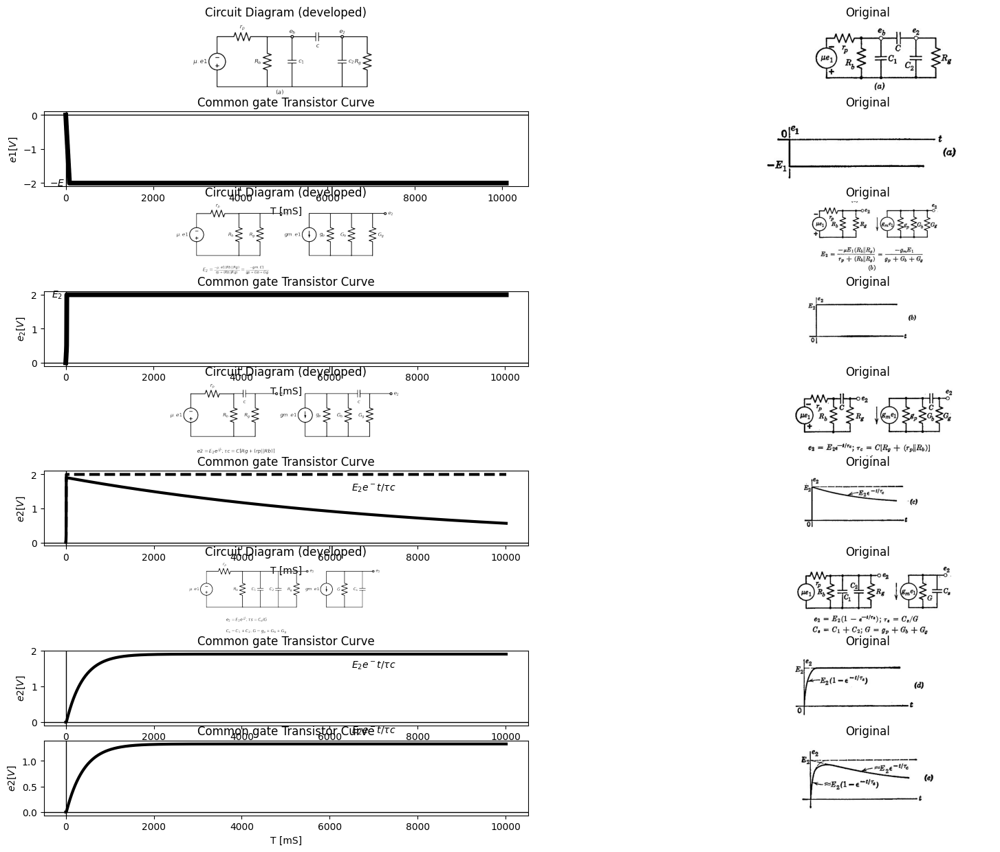

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(9, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('$μ.e1$', 'top') .reverse()
d += (R1 := elm.Resistor().right().label('$r_p$', 'top'))
d += (R2 := elm.Resistor().down(d.unit*1).label('$R_b$', 'top'))
l1 = d.add(elm.Line().left(d.unit*1))
l2 = d.add(elm.Line().right(d.unit*.5).at(R2.start).dot(open=True))
d += (C3:=elm.Capacitor().down(d.unit*1).color('black').label('$c_1$','bottom').label('$e_b$','right'))
l2 = d.add(elm.Line().left(d.unit*.5).label('$(a)$', 'bottom'))
d += (C4:=elm.Capacitor().right(d.unit*1).color('black').label('$c$','bottom').at(C3.start).dot(open=True))
d += (C5:=elm.Capacitor().down(d.unit*1).color('black').label('$c_2$','bottom').label('$e_2$','right'))
l6 = d.add(elm.Line().left(d.unit*1))
l8 = d.add(elm.Line().right(d.unit*.5).at(C5.start))
d += (R4 := elm.Resistor().down(d.unit*1).label('$R_g$', 'top'))
l8 = d.add(elm.Line().left(d.unit*.5))
d.save('images/8-31-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-31-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-31a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=-2@u_V, pulse_width=10@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].text( -200, -2, '$-E$', ha='center', va='center')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-31a1.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('$μ.e1$', 'top') .reverse()
d += (R1 := elm.Resistor().right().label('$r_p$', 'top'))
d += (R2 := elm.Resistor().down(d.unit*1).label('$R_b$', 'top'))
l1 = d.add(elm.Line().left(d.unit*1))
l2 = d.add(elm.Line().right(d.unit*.5).at(R2.start))
d += (R3 := elm.Resistor().down(d.unit*1).label('$R_g$', 'top'))
l3 = d.add(elm.Line().left(d.unit*.5))
l4 = d.add(elm.Line().right(d.unit*.5).at(R3.start).dot(open=True).label('$e_2$', 'right'))
d += elm.SourceI().up(d.unit*1).label('$gm.e1$', 'top').at((8,0)) .reverse()
l5 = d.add(elm.Line().right(d.unit*.5))
d += (R4 := elm.Resistor().down().label('$g_p$', 'top'))
l6 = d.add(elm.Line().left(d.unit*.5))
l7 = d.add(elm.Line().right(d.unit*.5).at(R4.start))
d += (R5 := elm.Resistor().down(d.unit*1).label('$G_b$', 'top'))
l8 = d.add(elm.Line().left(d.unit*.7))
l7 = d.add(elm.Line().right(d.unit*.5).at(R5.start))
d += (R6:=elm.Resistor().down(d.unit*1).color('black').label('$G_g$','bottom'))
l2 = d.add(elm.Line().left(d.unit*.5))
l6 = d.add(elm.Line().right(d.unit*.3).dot(open=True).at(R6.start).label('$e_2$','right'))
l6 = d.add(elm.Line().right(d.unit*.1).color('white').at((0,-1)).label(r'$E_2 = \frac {-μ.e1(Rb||Rg)}{rp+(Rb||Rg)} = \frac {-gm.E1}{gp+Gb+Gg}$','right',color='black'))
d.save('images/8-31-2.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-31-2.png')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-31b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)

axs[3,0].plot(analysis['e1'],'black',linewidth=5)
axs[3,0].set_title('Common gate Transistor Curve') 
axs[3,0].text( -200, 2, '$E_2$', ha='center', va='center')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('$e_2 [V]$')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-31b1.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('$μ.e1$', 'top') .reverse()
d += (R1 := elm.Resistor().right().label('$r_p$', 'top'))
d += (R2 := elm.Resistor().down(d.unit*1).label('$R_b$', 'top'))
l1 = d.add(elm.Line().left(d.unit*1))
d += (C1:=elm.Capacitor().right(d.unit*.5).color('black').label('$c$','bottom').at(R2.start))
d += (R3 := elm.Resistor().down(d.unit*1).label('$R_g$', 'top'))
l3 = d.add(elm.Line().left(d.unit*.5))
l4 = d.add(elm.Line().right(d.unit*.5).at(R3.start).dot(open=True).label('$e_2$', 'right'))
d += elm.SourceI().up(d.unit*1).label('$gm.e1$', 'top').at((8,0)) .reverse()
l5 = d.add(elm.Line().right(d.unit*.5))
d += (R4 := elm.Resistor().down().label('$g_p$', 'top'))
l6 = d.add(elm.Line().left(d.unit*.5))
l7 = d.add(elm.Line().right(d.unit*.5).at(R4.start))
d += (R5 := elm.Resistor().down(d.unit*1).label('$G_b$', 'top'))
l8 = d.add(elm.Line().left(d.unit*.7))
d += (C1:=elm.Capacitor().right(d.unit*.5).color('black').label('$c$','bottom').at(R5.start))
d += (R6 := elm.Resistor().down(d.unit*1).label('$G_g$', 'top'))
l8 = d.add(elm.Line().left(d.unit*.7))
l4 = d.add(elm.Line().right(d.unit*.5).at(R6.start).dot(open=True).label('$e_2$', 'right'))
l5 = d.add(elm.Line().right(d.unit*.1).color('white').at((0,-1)).label(r'$e2=E_2e^\frac {-t}{τc}  ; τc=C[Rg+(rp||Rb)]$', 'right',color='black'))
d.save('images/8-31-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-31-3.png')
axs[4,0].imshow(img)
axs[4,0].axis('off')  # Hide axes for image display
axs[4,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-31c.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=10@u_ms)
circuit.R(1, 'e1','2', 10@u_Ohm)
circuit.C(1, '2', 'e2', 20@u_uF)
circuit.R(2, '2', circuit.gnd, 400@u_Ohm)
circuit.R(3, 'e2', circuit.gnd, 400@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
axs[5,0].plot(analysis['e1'],'black',linewidth=3,linestyle='--')
axs[5,0].plot(analysis['e2'],'black',linewidth=3)
axs[5,0].set_title('Common gate Transistor Curve') 
axs[5,0].text( 7000, 1.6, '$E_2e^-t/τc$', ha='center', va='center')
axs[5,0].set_xlabel('T [mS]')
axs[5,0].set_ylabel('$e2 [V]$')
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-31c1.JPG')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label('$μ.e1$', 'top') .reverse()
d += (R1 := elm.Resistor().right().label('$r_p$', 'top'))
d += (R2 := elm.Resistor().down(d.unit*1).label('$R_b$', 'top'))
l1 = d.add(elm.Line().left(d.unit*1))
l2 = d.add(elm.Line().right(d.unit*.5).at(R2.start))
d += (C1:=elm.Capacitor().down(d.unit*1).color('black').label('$C_1$','top').at(l2.end))
l3 = d.add(elm.Line().left(d.unit*1))
l4 = d.add(elm.Line().right(d.unit*.5).at(C1.start))
d += (C2:=elm.Capacitor().down(d.unit*1).color('black').label('$C_2$','top').at(l4.end))
l5 = d.add(elm.Line().left(d.unit*1))
l4 = d.add(elm.Line().right(d.unit*.5).at(C2.start))
d += (R3 := elm.Resistor().down(d.unit*1).label('$R_g$', 'top'))
l5 = d.add(elm.Line().left(d.unit*1))
l5 = d.add(elm.Line().right(d.unit*.3).dot(open=True).at(R3.start).label('$e_2$','right'))
d += elm.SourceI().up(d.unit*1).label('$gm.e1$', 'top').at((10,0)) .reverse()
l5 = d.add(elm.Line().right(d.unit*.5))
d += (R4 := elm.Resistor().down().label('$G$', 'top'))
l6 = d.add(elm.Line().left(d.unit*.5))
l7 = d.add(elm.Line().right(d.unit*.5).at(R4.start))
d += (C3 := elm.Capacitor().down(d.unit*1).label('$C_s$', 'top'))
l8 = d.add(elm.Line().left(d.unit*.7))
l5 = d.add(elm.Line().right(d.unit*.3).dot(open=True).at(C3.start).label('$e_2$','right'))
l6 = d.add(elm.Line().right(d.unit*.5).color('white').at((0,-1)).label(r'$e_2 = E_2e^\frac {-t}{τc} ; τs= C_s/G$','right',color='black'))
l6 = d.add(elm.Line().right(d.unit*.5).color('white').at((0,-2)).label(r'$C_s= C_1 + C_2; G = g_p+ G_b +G_g$','right',color='black'))
d.save('images/8-31-3.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-31-3.png')
axs[6,0].imshow(img)
axs[6,0].axis('off')  # Hide axes for image display
axs[6,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-31d.jpg')  # Load the PNG file
axs[6,1].imshow(img_sample)
axs[6,1].axis('off')  # Hide axes for image display
axs[6,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=10@u_ms)
circuit.R(1, 'e1','e2', 10@u_Ohm)
circuit.C(1, 'e2', circuit.gnd, 20@u_uF)
circuit.C(2, 'e2', circuit.gnd, 20@u_uF)
circuit.R(2, 'e2', circuit.gnd, 400@u_Ohm)
circuit.R(3, 'e2', circuit.gnd, 400@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
#axs[7,0].plot(analysis['e1'],'black',linewidth=3,linestyle='--')
axs[7,0].plot(analysis['e2'],'black',linewidth=3)
axs[7,0].set_title('Common gate Transistor Curve') 
axs[7,0].text( 7000, 1.6, '$E_2e^-t/τc$', ha='center', va='center')
axs[7,0].set_xlabel('T [mS]')
axs[7,0].set_ylabel('$e2 [V]$')
axs[7,0].axhline(0, color='black', linewidth=1)
axs[7,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-31d1.JPG')  # Load the PNG file
axs[7,1].imshow(img_sample)
axs[7,1].axis('off')  # Hide axes for image display
axs[7,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=10@u_ms)
circuit.R(1, 'e1','e2', 10@u_Ohm)
circuit.C(1, 'e2', circuit.gnd, 20@u_uF)
circuit.C(2, 'e2', circuit.gnd, 40@u_uF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'e2', circuit.gnd, 40@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)
#axs[7,0].plot(analysis['e1'],'black',linewidth=3,linestyle='--')
axs[8,0].plot(analysis['e2'],'black',linewidth=3)
axs[8,0].set_title('Common gate Transistor Curve') 
axs[8,0].text( 7000, 1.6, '$E_2e^-t/τc$', ha='center', va='center')
axs[8,0].set_xlabel('T [mS]')
axs[8,0].set_ylabel('$e2 [V]$')
axs[8,0].axhline(0, color='black', linewidth=1)
axs[8,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-31e.JPG')  # Load the PNG file
axs[8,1].imshow(img_sample)
axs[8,1].axis('off')  # Hide axes for image display
axs[8,1].set_title('Original')

## Fig8.31 Approximating the step response of a linear  RC coupling circuit including stray capacitance

# 8.23 Locuse of operating With Coupling and Shunt Capacitance

When C is much greater than C₁ and C2, it is convenient to combine  the two shunt capacitances into a single capacitance C. where  $C = C1+C2 $ (8.35)  which appears only on one side of the coupling capacitor, as indicated in  Fig. 8.32(a). This simplification makes only a minor difference in the  voltage ez across the coupling capacitor. The extreme error in ex could  not exceed (C2/C) $(∆.e_2) max.$ This is the change in ex required to change  the voltage across C2 over its maximum range of variation.  
For the circuit of Fig. 8.32(a), with the input waveform shown, the  locus of operation is indicated in (b), (c), and (d) for three values of  coupling capacitor time constant. The d-c load line with slope R  is shown as a dotted line. The a-c load line, or locus without Co, is  shown by the solid lines AB'CD'. With shunt capacitance C. added to  the circuit, instantaneous changes in es are prohibited. In Fig. 8.32(b),  the operating point moves instantaneously from A to B, and then rapidly  to point Cas the shunt capacitance discharges. Conditions are then  very nearly quiescent at point C until the grid voltage switches negative  to D. This causes the instantaneous change CD and the rapid charge  from D to A, where the operating point remains (approximately) until  the next switch from A to B. 
Actually, the coupling capacitor charges and discharges slightly and  for a somewhat larger value of 8٫re the effect is more pronounced, as  shown in Fig. 8.32(c). Here the operating point moves instantaneously  from A to B, very rapidly from B to B', and then slowly from B to C.

Text(0.5, 1.0, 'Original')

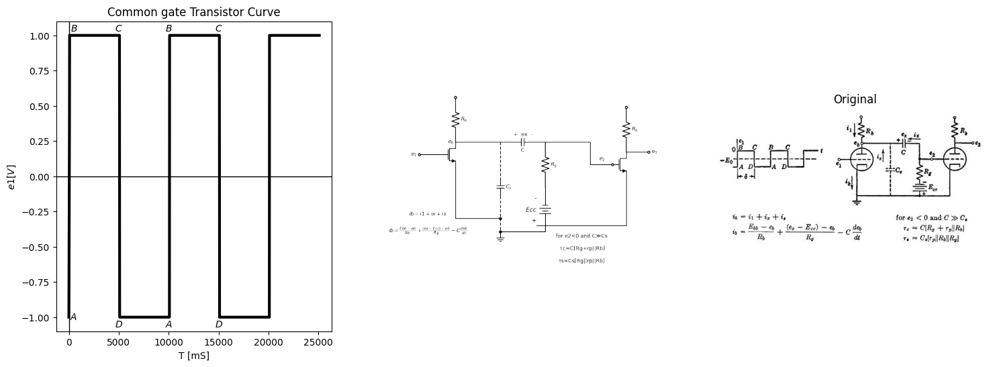

In [31]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1,3, figsize=(18, 6))
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=1@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)

axs[0].plot(analysis['e1'],'black',linewidth=3)
axs[0].set_title('Common gate Transistor Curve') 
axs[0].text( 500, -1, '$A$', ha='center', va='center')
axs[0].text( 500, 1.05, '$B$', ha='center', va='center')
axs[0].text( 5000, 1.05, '$C$', ha='center', va='center')
axs[0].text( 5000, -1.05, '$D$', ha='center', va='center')
axs[0].text( 10000, -1.05, '$A$', ha='center', va='center')
axs[0].text( 10000, 1.05, '$B$', ha='center', va='center')
axs[0].text( 15000, 1.05, '$C$', ha='center', va='center')
axs[0].text( 15000, -1.05, '$D$', ha='center', va='center')
axs[0].set_xlabel('T [mS]')
axs[0].set_ylabel('$e1 [V]$')
axs[0].axhline(0, color='black', linewidth=1)
axs[0].axvline(0, color='black', linewidth=1)
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
d += (R1 := elm.Resistor().up().label('$R_b$', 'bottom').dot(open=True).at(M1.drain))
l2 = d.add(elm.Line().right(d.unit*1).at(M1.drain).label('$e_b$','left'))
d += (C1 := elm.Capacitor().right().label('$C$', 'bottom').label('+  ex  -', 'top'))
l3 = d.add(elm.Line().down(d.unit*.8).at(l2.end).linestyle('--'))
d += (C2 := elm.Capacitor().down(d.unit*.4).label('$C_s$', 'bottom'))
l4 = d.add(elm.Line().down(d.unit*.8).at(C2.end).linestyle('--'))
G = d.add(elm.Ground().at(l4.end))
l5 = d.add(elm.Line().down(d.unit*1.15).at(M1.source))
l6 = d.add(elm.Line().right(d.unit*1).dot())
d += (R2 := elm.Resistor().down(d.unit*1).label('$R_g$', 'bottom').at(C1.end))
d += (E1 := elm.Battery().down(d.unit*1).reverse().label(['-','$Ecc$','+'], ofst=.2 , fontsize = 16).color('black'))
l7 = d.add(elm.Line().left(d.unit*1).dot())
l8 = d.add(elm.Line().right(d.unit*1).at(R2.start))
l9 = d.add(elm.Line().down(d.unit*.5))
l10 = d.add(elm.Line().right(d.unit*.5).dot(open=True).label('$e_2$','top'))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse().at(l10.end))
d += (R3 := elm.Resistor().up().label('$R_b$', 'bottom').dot(open=True).at(M2.drain))
l9 = d.add(elm.Line().down(d.unit*1.08).at(M2.source))
l9 = d.add(elm.Line().left(d.unit*2).label('\nfor e2<0 and C≫Cs\n\n τc≈C[Rg+rp||Rb]\n\nτs≈Cs[Rg||rp||Rb]','bottom'))
l10 = d.add(elm.Line().right(d.unit*.5).dot(open=True).label('$e_3$','right').at(M2.drain))
l9 = d.add(elm.Line().right(d.unit*.1).at((-2,-4.5)).color('white').label('$ib= i1+ix+is$','bottom',color='black'))
l9 = d.add(elm.Line().right(d.unit*.1).at((-2,-5.5)).color('white').label(r'$ib=\frac{Ebb-eb}{Rb}+ \frac{(ex-Ecc)-eb}{Rg}-C\frac{deb}{dt}$','bottom',color='black'))
d.save('./Drawings/8-32.png')
d.save('./Drawings/8-32.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/8-32.png')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
img_sample = mpimg.imread('images/8-32a.JPG')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')


## Fig8.32 Locus of operation with shunt capacitance and variouse degrees of coupling capacitor charge and discharge(C≫Cs in all cases) 

When C is reached, there is an instantaneous transition to D, a rapid  shift to D', and a slow shift back to A. Then the cycle repeats. The  same general statements apply to Fig. 8.32(d), except that motion from  B' to C and from D' to A is relatively more rapid, since 8٫7e is even  larger. Also, since the coupling capacitor may charge and discharge to  completion, the operating point may repose at C and A for some time  prior to each switching transition. In this case, C and A are true  quiescent points (on Ra load line), whereas in Fig. 8.32(b) these points.
were only "quasi-quiescent" as a result of the small value of $δ⁄τc$.  The methods we have used for determining waveforms and loci of  operation apply to any of the basic circuits with inductive or tuned loads  as well as capacitive loads. A few of the many possible combinations  will be discussed in the following articles. 


Text(0.5, 1.0, 'Original')

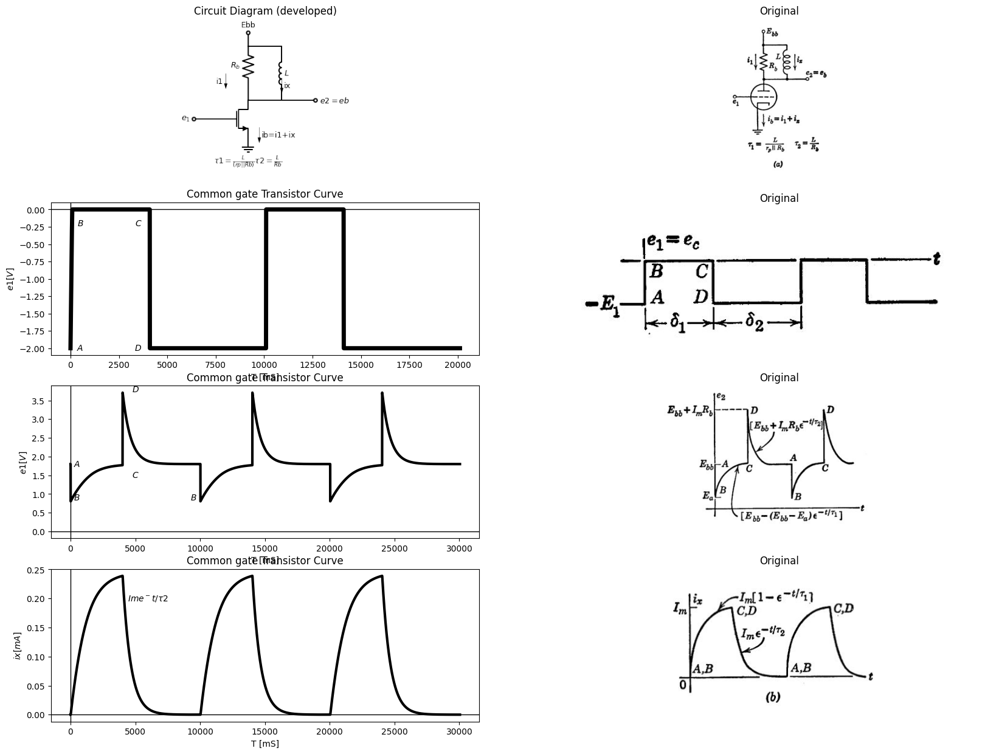

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).dot(open=True).label('$e_1 $','left').at(M1.gate))
d += (R1 := elm.Resistor().up().label('$R_b$', 'top').dot(open=True).at(M1.drain).label('Ebb','right'))
l2 = d.add(elm.Line().right(d.unit*.5).at(R1.start))
d += (L1 := elm.Inductor().up(d.unit*.8).label('$L$', 'bottom'))
l3 = d.add(elm.Line().left(d.unit*.5))
l8 = d.add(elm.Line().right(d.unit*.5).at(l2.end).dot(open=True).label('$e2=eb$', 'right'))
G = d.add(elm.Ground().at(M1.source).label(r'$τ1=\frac{L}{(rp||Rb )}    τ2=\frac{L}{Rb}$','bottom'))
d += elm.Arrow().down().length(.7).linewidth(.6).color('black').at((.5,-1.2)).label('ib=i1+ix','bottom')
d += elm.Arrow().down().length(.7).linewidth(.6).color('black').at((1.5,1)).label('ix','bottom')
d += elm.Arrow().down().length(.7).linewidth(.6).color('black').at((-1,1.2)).label('i1','top')
d.save('images/8-34-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-34-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-34a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].text( 500, -2, '$A$', ha='center', va='center')
axs[1,0].text( 3500, -2, '$D$', ha='center', va='center')
axs[1,0].text( 500, -.2, '$B$', ha='center', va='center')
axs[1,0].text( 3500, -.2, '$C$', ha='center', va='center')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-34b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 8@u_Ohm)
circuit.L(1, 'Ebb', 'e2', 5@u_mH)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)

axs[2,0].plot(analysis['e2'],'black',linewidth=3)
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].text( 500, 1.8, '$A$', ha='center', va='center')
axs[2,0].text( 500, .9, '$B$', ha='center', va='center')
axs[2,0].text( 9500, .9, '$B$', ha='center', va='center')
axs[2,0].text( 5000, 1.5, '$C$', ha='center', va='center')
axs[2,0].text( 5000, 3.8, '$D$', ha='center', va='center')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$e1 [V]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-34c.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 8@u_Ohm)
circuit.L(1, 'Ebb', 'e2', 5@u_mH)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)

axs[3,0].plot(analysis['L1'],'black',linewidth=3)
axs[3,0].set_title('Common gate Transistor Curve') 
axs[3,0].text( 6000, .2, '$Ime^-t/τ2$', ha='center', va='center')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('$ix [mA]$')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-33d.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig8.33 Triode with parallel RL plate load and rectangular-wave input (δ1>5τ1,δ2>5τ2 ).

# 8.24 Triode with Parallel RL Plate Load 

 
A triode with parallel RL load is shown in Fig. 8.33 (a). Let the input  waveform be as shown in (6), with intervals long compared to time con- stants. When triode conduction is initiated by the transition from A to  B, the current in the inductance is zero; hence the apparent triode load  is Rs, as indicated by the locus plot in Fig. 8.33 (c). As current builds  up in the inductance with a time constant 


$τ1 = \frac{L}{Rb||rp}$  $$(8.36)$$

(if we use a piecewise-linear model for the triode), the voltage across the  load decreases toward zero and plate voltage increases toward E bb The  triode current during this time is  
  $i b = \frac {E bb -e b} {R b} +i x $ $$(8.37)$$
  
The build-up of i_{x} corresponds to a translation of the R_{b} load line parallel  to itself, so that the operating point moves along the e_{c} = 0 line from  B to C. In effect, i_{x} is a time-varying current source acting on the  resistive portion of the circuit. When i_{x} has reached the quiescent  value I_{m} the voltage across the load is zero and e b =E bb During the  transition from C to D, the inductor current remains constant at I_{m}  hence the variational load again appears to be R_{b} The current I_{m} is  transferred from the triode to R_{b} as the triode cuts off, and results in an  overshoot of e_{b} above the value E bb by the amount I_{m}*R_{b} The current  now decays exponentially to zero with the time constant 

$τ2 = \frac{L}{Rb}$  $$(8.38)$$


If the intervals 81 and 82 are not sufficiently long to permit completion  of transients, we must solve a pair of simultaneous algebraic equations  as in the RC case. The current i will vary between a maximum of I  and a minimum of I instead of Im and zero. Once these values have  been found from the two linear circuits that apply during 81 and 52,  respectively, the waveforms or locus of operation can be plotted very  readily. The analysis is similar to the one outlined in Fig. 8.15 for the  RC circuit.  
The waveforms and locus of operating point shown in Fig. 8.33 apply  for an input waveform that has a sufficiently negative peak (E1) to  drive the triode to plate-current cutoff at the transition from C to D.  This requirement specifies a value of e₁ more negative than  -$(Ebb+ImRr)/µ.$ For a negative excursion less than this value the  triode plate current is not driven to zero instantaneously.  
The locus and waveforms in Fig. 8.34(a) and (b) apply to the circuit  of Fig. 8.33 for E₁=Ebb٫µ. Assuming the intervals 8₁ and 82 long  enough to permit completion of transients, the waveforms of e2 and the  locus are the same as before for the transition A to B and the interval  81 from B to C. However, since triode plate current is not cut off by the  transition from C to D, the positive overshoot on the waveform of ez has  a time constant $τ1 = L/(Rb||rp)$. In the previous example the time  constant was $τ2 = L/Rb$. The exponential decay of inductor current 
ix (waveform not shown) also has the time constant τ1. For -E1 =  - Ebb/µ, as in this example, the triode plate current just reaches cutoff  at the end of the overshoot exponential (D to A).  


Text(0.5, 1.0, 'Original')

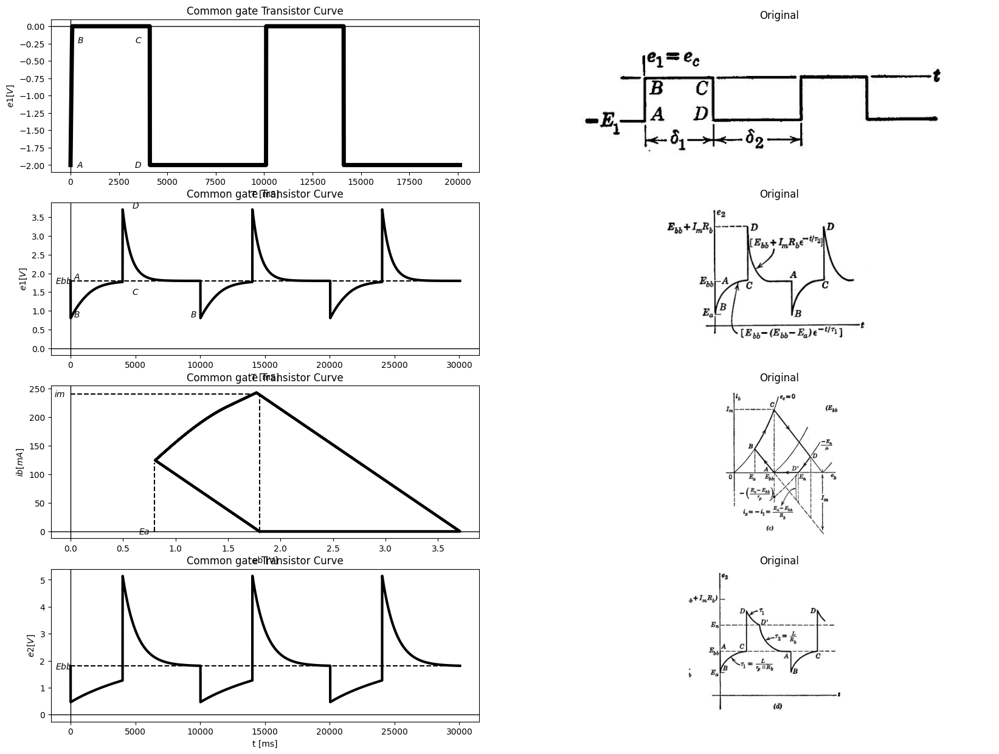

In [4]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[0,0].plot(analysis['e1'],'black',linewidth=5)
axs[0,0].set_title('Common gate Transistor Curve') 
axs[0,0].text( 500, -2, '$A$', ha='center', va='center')
axs[0,0].text( 3500, -2, '$D$', ha='center', va='center')
axs[0,0].text( 500, -.2, '$B$', ha='center', va='center')
axs[0,0].text( 3500, -.2, '$C$', ha='center', va='center')
axs[0,0].set_xlabel('T [mS]')
axs[0,0].set_ylabel('$e1 [V]$')
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-34b.JPG')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 8@u_Ohm)
circuit.L(1, 'Ebb', 'e2', 5@u_mH)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)

axs[1,0].plot(analysis['e2'],'black',linewidth=3)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].text( 500, 1.9, '$A$', ha='center', va='center')
axs[1,0].text( -500, 1.8, '$Ebb$', ha='center', va='center')
axs[1,0].text( 500, .9, '$B$', ha='center', va='center')
axs[1,0].text( 9500, .9, '$B$', ha='center', va='center')
axs[1,0].text( 5000, 1.5, '$C$', ha='center', va='center')
axs[1,0].text( 5000, 3.8, '$D$', ha='center', va='center')
axs[1,0].plot([0, 30000], [1.8, 1.8], color='black', linestyle='--')
#axs[3,0].plot([0, 0.1], [0, 10], color='black', linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-34c.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.M(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 8@u_Ohm)
circuit.L(1, 'Ebb', 'e2', 5@u_mH)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)

axs[2,0].plot(analysis['e2'], u_mA(-analysis.V2),'black',linewidth=3)
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].plot([0, 1.8], [240, 240], color='black', linestyle='--')
axs[2,0].plot([1.8, 1.8], [0, 240], color='black', linestyle='--')
axs[2,0].plot([.8, .8], [0, 120], color='black', linestyle='--')
axs[2,0].text( -.1, 240, '$im$', ha='center', va='center')
axs[2,0].text( .7, .1, '$Ea$', ha='center', va='center')
#axs[2,0].text( 5000, 3.8, '$D$', ha='center', va='center')
#axs[2,0].plot([0, 30000], [1.8, 1.8], color='black', linestyle='--')
#axs[3,0].plot([0, 0.1], [0, 10], color='black', linestyle='--')
axs[2,0].set_xlabel('eb [V]')
axs[2,0].set_ylabel('$ib [mA]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-34c1.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=5E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.M(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'e2', 8@u_Ohm)
circuit.L(1, 'Ebb', 'e2', 8.5@u_mH)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[3,0].plot([0, 30000], [1.8, 1.8], color='black', linestyle='--')
axs[3,0].text( -500, 1.8, '$Ebb$', ha='center', va='center')
axs[3,0].plot(analysis['e2'],'black',linewidth=3)
axs[3,0].set_title('Common gate Transistor Curve') 
axs[3,0].set_xlabel('t [ms]')
axs[3,0].set_ylabel('$e2 [V]$')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-34d1.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig8.34. Effect of input amplitude on triode with parallel RL load (δ1>5τ1,δ2>5τ2 ).

The locus and waveforms shown in Fig. 8.34 (c) and (d) have been  drawn for a value of E₁ between - Eb٫µ and -(Ebb + ImRb)٫μ.  - For this intermediate case the overshoot waveform consists of an expо- nential with a time constant $τ₁$ from D to D' at which point the plate  
current cuts off and the time constant is 72 from D' to A. The current  iz in the inductance (waveform not shown) decreases from Im with a  time constant $τ1$ and is heading toward a final value -(En Ebb)/rp.  [See locus plot in Fig. 8.34 (c).] However, when plate current reaches  zero, we have izi₁ (En Ebb)٫R, and from this value in  heads toward zero with a time constant $τ2.$ Although the slope of wave- form e₂ changes at the break point, dix/dt must be continuous at the  break, since e₂ is continuous. 


# 8.25 Triode with Series RL Plate Load

With a series resistance as the plate load on a triode, the response to rectangular wave is as show in Fig8.35. the effects

Text(0.5, 1.0, 'Original')

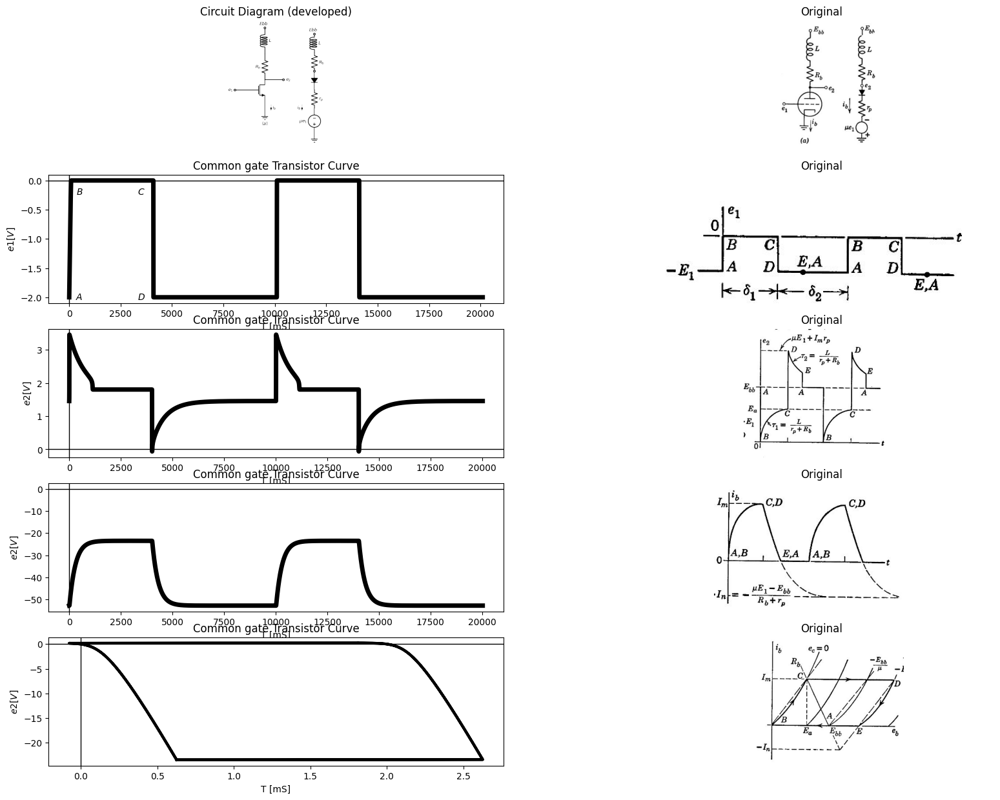

In [43]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().up(d.unit*.7).label('$R_b$', 'top').at(M1.drain))
d += (L1:=elm.Inductor2().up(d.unit*.7).color('black').label('$L$','bottom').dot(open=True).label('$Ebb$','right'))
l1 = d.add(elm.Line().left(d.unit*.5).at(M1.gate).dot(open=True).label('$e_1$','left'))
l2 = d.add(elm.Line().down(d.unit*.3).at(M1.source))
G = d.add(elm.Ground().at(l2.end).label('$(a)$','bottom'))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_b$','bottom'). at((0.5,-2))
l3 = d.add(elm.Line().right(d.unit*.5).at(M1.drain).dot(open=True).label('$e_2$','right'))
d += (L2:=elm.Inductor2().up(d.unit*.5).color('black').label('$L$','bottom').dot(open=True).label('$Ebb$','right').at((4,2.2)))
d += (R2 := elm.Resistor().down(d.unit*.5).label('$R_b$', 'bottom').at(L2.start).dot(open=True))
D= d.add(elm.Diode(fill=True).down(d.unit*.5))
d += (R3 := elm.Resistor().down(d.unit*.5).label('$r_p$', 'bottom'))
d += elm.SourceV().down(d.unit*.7).label(r'$\mu e_1$', 'top') 
G = d.add(elm.Ground())
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_b$','top'). at((3,-2))
d.save('images/8-35-1.png')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-35-1.png')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-35a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].text( 500, -2, '$A$', ha='center', va='center')
axs[1,0].text( 3500, -2, '$D$', ha='center', va='center')
axs[1,0].text( 500, -.2, '$B$', ha='center', va='center')
axs[1,0].text( 3500, -.2, '$C$', ha='center', va='center')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-35b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('BAV21','D' ,IS = 230@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 80@u_mV ,CJO = 7.048E-13,PF=90 ,RS = 10@u_Ohm ,TT = 3.48E-9)
circuit.D(1,'e2' ,'e3', model = 'BAV21')
circuit.L(1, 'Ebb', 'eb', 15@u_mH)
#circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
#circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(1, 'eb', 'e2', 5@u_Ohm)
circuit.R(2, 'e3', 'e1', 7@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[2,0].plot(analysis['e2'],'black',linewidth=5)
axs[2,0].set_title('Common gate Transistor Curve') 

axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$e2 [V]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-35c.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('BAV21','D' ,IS = 230@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 80@u_mV ,CJO = 7.048E-13,PF=90 ,RS = 10@u_Ohm ,TT = 3.48E-9)
circuit.D(1,'e2' ,'e3', model = 'BAV21')
circuit.L(1, 'Ebb', 'eb', 20@u_mH)
#circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
#circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(1, 'eb', 'e2', 50@u_Ohm)
circuit.R(2, 'e3', 'e1', 7@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[3,0].plot( u_mA(-analysis.L1),'black',linewidth=5)
axs[3,0].set_title('Common gate Transistor Curve') 

axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('$e2 [V]$')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-35d.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('BAV21','D' ,IS = 230@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 80@u_mV ,CJO = 7.048E-13,PF=90 ,RS = 10@u_Ohm ,TT = 3.48E-9)
circuit.D(1,'e2' ,'e3', model = 'BAV21')
circuit.L(1, 'Ebb', 'eb', 20@u_mH)
#circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
#circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(1, 'eb', 'e2', 50@u_Ohm)
circuit.R(2, 'e3', 'e1', 7@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[4,0].plot(analysis['e2'], u_mA(-analysis.L1),'black',linewidth=3)
axs[4,0].set_title('Common gate Transistor Curve') 

axs[4,0].set_xlabel('T [mS]')
axs[4,0].set_ylabel('$e2 [V]$')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-35e.JPG')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

## Fig 8.35 Triode with Series RL Plate Load (δ1>5τ1,δ2>5τ2 )

of stray capacitances are neglected, and the waveforms and locus are  drawn for intervals d₁ and 82 sufficiently long to permit completion of  the transients.  
There is a great deal of similarity between this case and the previous  one. If, for example, in the circuit of Fig. 8.35 (a) we consider resistance  Ro as part of the triode plate resistance, we effectively have a triode with  plate resistance $rp`=Rb+rp$, and an inductive load L. This, then,  corresponds to the circuit of Fig. 8.33 (a) with the resistance $R = ∞.$  In the series circuit of Fig. 8.35(a), the plate current cannot be cut off  no matter how negative E₁ is made.  

# 8.26 Cathode-Follower Circuit with Series RL Load  
A cathode follower with a series RL load is shown in Fig. 8.36 (α). Α  piecewise-linear model is shown in (b), and an incremental model is  shown in (c). The rectangular waveform of input voltage shown in (d)  results in the output waveform also sketched in (d) and the locus of  operation shown in (e). The amplitude of the input waveform has been  chosen deliberately in order to avoid positive-grid operation; in fact, E1  was chosen equal to (Ebb Ea). The intervals $δ1$ and $δ2$ are here being  considered large compared with time constants, so that transients go  to completion.  
With e1 = 0, the quiescent current is  $$I{o} = \frac {Ebb}{r{p}+R{k}(\mu-1)}$$  $$(8.39)$$


which may be found either analytically or graphically from the inter- section of the load line and the bias line  $$e_{1} = 0 = e_{c} + i_{b}*R_{k}$$  $$(8.40) $$ 
Note that the inductance is effectively absent under quiescent conditions.  However, when the input voltage is switched from A to B, the inductance  L plays a predominant role. The current cannot change instantaneously;  therefore, the incremental load impedance appears to be infinite. As a  result, the point B on the locus can be located from the open-circuit  voltage gain of the cathode follower: $$ \Delta e_{2} = \mu.\Delta e_{1}/ (\mu + 1) = \mu E_{1} / (\mu + 1)$$  $$(8.41) $$ 
For the value of $E_{1}$ chosen here,$ (E bb -E a )$ the build-up of current  leads to the quiescent point C at the intersection of the $R_{k} $load line and  thee $e_{c} = 0$ line. The variation in$i_{b}$ proceeds from $I_{0}$ to $I_{m}$ exponentially 





Text(0.5, 1.0, 'Original')

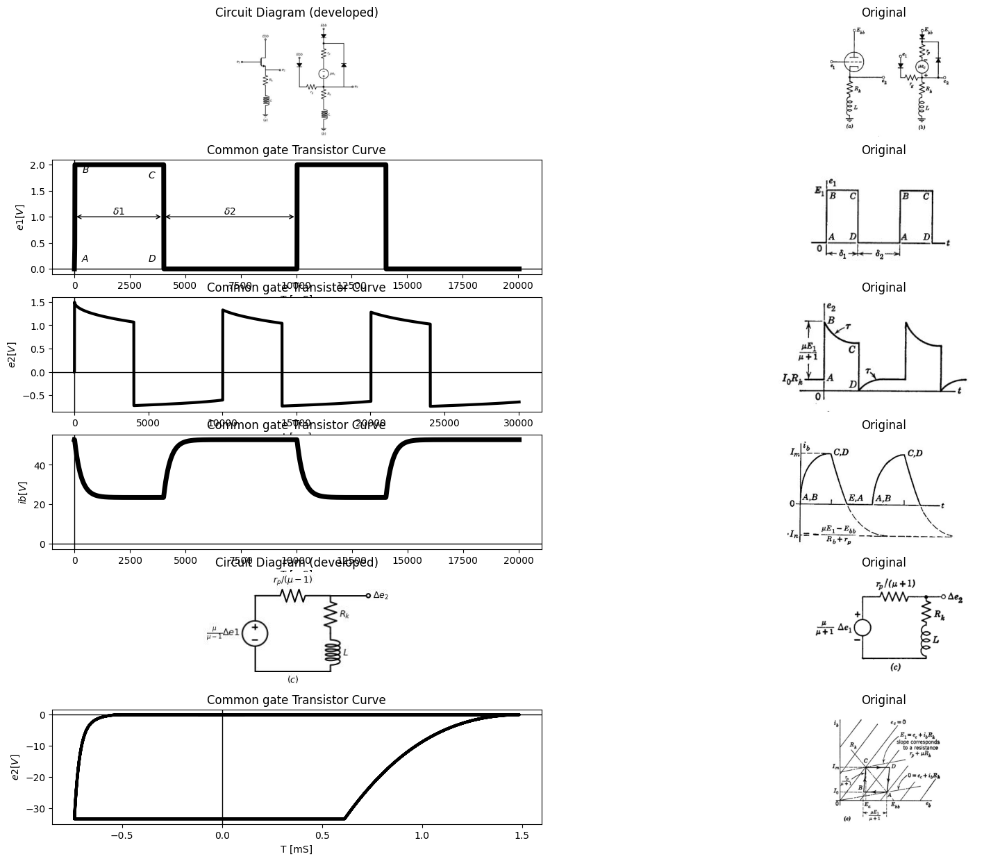

In [10]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.5).at(M1.gate).dot(open=True).label('$e_1$','left'))
l2 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$Ebb$','right'))
d += (R1 := elm.Resistor().down(d.unit*.7).label('$R_k$', 'bottom').at(M1.source))
d += (L1:=elm.Inductor2().down(d.unit*.7).color('black').label('$L$','bottom'))
G = d.add(elm.Ground().at(L1.end).label('$(a)$','bottom'))
l3 = d.add(elm.Line().right(d.unit*.5).at(M1.source).dot(open=True).label('$e_2$','right'))
l4 = d.add(elm.Line().up(d.unit*.2).at((6,2)).dot(open=True).label('$Ebb$','right'))
D= d.add(elm.Diode(fill=True).down(d.unit*.5).dot())
d += (R2 := elm.Resistor().down(d.unit*.7).label('$r_p$', 'bottom'))
d += elm.SourceV().down(d.unit*.7).label(r'$\mu e_c$', 'bottom') 
d += (R3 := elm.Resistor().down(d.unit*.7).label('$R_k$', 'bottom'))
d += (L2:=elm.Inductor2().down(d.unit*.7).color('black').label('$L$','bottom'))
G = d.add(elm.Ground().at(L2.end).label('$(b)$','bottom'))
l5 = d.add(elm.Line().up(d.unit*.2).at((3.5,-1)).dot(open=True).label('$Ebb$','right'))
D= d.add(elm.Diode(fill=True).down(d.unit*.5))
l5 = d.add(elm.Line().down(d.unit*.5))
d += (R4 := elm.Resistor().right(d.unit*.83).label('$r_g$', 'bottom').dot())
l6= d.add(elm.Line().right(d.unit*.7))
D= d.add(elm.Diode(fill=True).up(d.unit*1.5))
l5 = d.add(elm.Line().left(d.unit*.7))
l5 = d.add(elm.Line().right(d.unit*.3).dot(open=True).at(l6.end).label('$e_2$', 'right'))
d.save('images/8-36-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-36-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-36a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].text( 500, .2, '$A$', ha='center', va='center')
axs[1,0].text( 3500, .2, '$D$', ha='center', va='center')
axs[1,0].text( 500, 1.9, '$B$', ha='center', va='center')
axs[1,0].text( 3500, 1.8, '$C$', ha='center', va='center')
axs[1,0].text( 2000, 1.1, '$δ1$', ha='center', va='center')
axs[1,0].text( 7000, 1.1, '$δ2$', ha='center', va='center')
axs[1,0].annotate('', xy=(0., 1), xytext=(4000, 1), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(4000., 1), xytext=(10000, 1), arrowprops=dict(arrowstyle='<->'))
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-36b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=1E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.M(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', 'e3', 10@u_Ohm)
circuit.L(1, 'e3',circuit.gnd, 1@u_H)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)

axs[2,0].plot(analysis['e3'],'black',linewidth=3)
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].set_xlabel('t [ms]')
axs[2,0].set_ylabel('$e2 [V]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-36c.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('BAV21','D' ,IS = 230@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 80@u_mV ,CJO = 7.048E-13,PF=90 ,RS = 10@u_Ohm ,TT = 3.48E-9)
circuit.D(1,'e2' ,'e3', model = 'BAV21')
circuit.L(1, 'Ebb', 'eb', 20@u_mH)
circuit.R(1, 'eb', 'e2', 50@u_Ohm)
circuit.R(2, 'e3', 'e1', 7@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[3,0].plot( u_mA(-analysis.V2),'black',linewidth=5)
axs[3,0].set_title('Common gate Transistor Curve') 

axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('$ib [V]$')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-35d.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label(r'$\frac {\mu}{\mu -1}∆e1$', 'top') 
d += (R1 := elm.Resistor().right(d.unit*1).label(r'$r_p/(\mu -1)$', 'top'))
d += (R2 := elm.Resistor().down(d.unit*.5).label('$R_k$', 'bottom'))
d += (L1:=elm.Inductor2().down(d.unit*.5).color('black').label('$L$','bottom'))
l1 = d.add(elm.Line().left(d.unit*1).label('$(c)$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.5).label('$∆e_2$','right').dot(open=True).at(R1.end))
d.save('images/8-36-2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-36-2.jpg')
axs[4,0].imshow(img)
axs[4,0].axis('off')  # Hide axes for image display
axs[4,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-36c1.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=1E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.M(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', 'e3', .10@u_Ohm)
circuit.L(1, 'e3',circuit.gnd, .1@u_H)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)

axs[5,0].plot(analysis['e2'], u_mA(-analysis.L1),'black',linewidth=3)
axs[5,0].set_title('Common gate Transistor Curve') 

axs[5,0].set_xlabel('T [mS]')
axs[5,0].set_ylabel('$e2 [V]$')
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-36e1.JPG')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

## Fig8.36 Cathode follower with series RL Load

With the time constant $$τ= \frac {L}{R{k}+r{p}/(\mu-1)}$$ $$(8.42)$$

On the locus plot, the variation from B to C corresponding to this  build-up is a straight line of slope $r_{p} /(\mu + 1) .$  

An alternate solution to this problem can be found by plotting a new  set of $i_{b} vs. e_{b}$ curves with $e_{1}$ as parameter, rather than $e_{c}$ . These curves,  readily derivable from the standard triode curves, are useful in the  analysis of the cathode-follower circuit with any cathode load.  


Text(0.5, 1.0, 'Original')

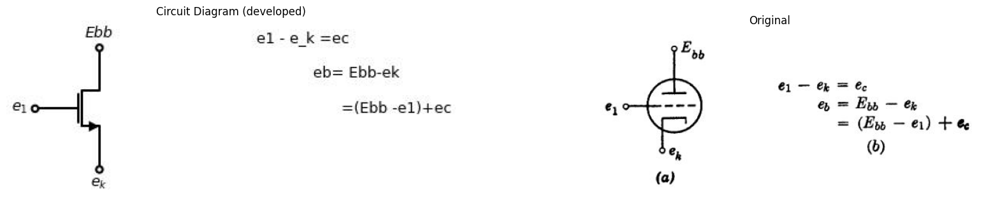

In [14]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.2).label('$e_1$','left').at(M1.gate).dot(open=True))
l2 = d.add(elm.Line().up(d.unit*.2).label('$Ebb$','right').at(M1.drain).dot(open=True))
l3 = d.add(elm.Line().down(d.unit*.2).label('$e_k$','left').at(M1.source).dot(open=True))
l4 = d.add(elm.Line().right(d.unit*.2).color('white').label('e1 - e_k =ec\n\n            eb= Ebb-ek\n\n                  =(Ebb -e1)+ec','right',color='black').at((3,0)))
d.save('images/8-37-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-37-1.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-37a.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

## Fig. 8.37. Construction of cathode-output curves.  


Consider the triode shown in Fig. 8.37 (a). If the plate is held at a  fixed potential E bb then from (b),  $$e{b} =(E bb -e 1 )+e{c} $$
$$(8.43)$$  
To plot the $e_{1} = 0$ line, locate the intersection of the grid-voltage lines $e_{c}$ 


with the corresponding plate voltage $e b =E bb +e c$ . The line joining  these intersections is the $e_{1}$ = 0 line and, as shown in Fig. 8.37 (c), it  has a slope of $r_{p}$/ $(\mu + 1)$  
The locus of operation can now be easily determined. At point A on  the input waveform, $e_{1} = 0$ and if previous transients have died out, the  operating point will be located at the intersection of the load line and the  $e_{1} = 0 $line. When the input voltage is switched from zero to $E_{1}$  $(A to B)$, the current cannot change instantaneously; so the locus is a  horizontal line from $e_{1} = 0 $to $e_{1} = E_{1}$ During the interval $\delta_{1}$ , $e {1} $ remains constant at $E_{1}$ the inductor current increases exponentially  to$I_{m}$ and the operating point moves up the $e_{1} = E_{1}$ curve. After the  transient has died out, the operating point is at C, the intersection of  the$ R_{k}$ load line with the $e_{1} = E_{1}$ curve. Similar arguments hold for the  transitions from C to D and D to A.  
# 8.27 Cathode Follower with Parallel RL Load  
The circuit shown in Fig. 8.38(a) can be approximated by the piece- wise-linear model given in (6). For grid-to-cathode voltages between  zero and plate current cutoff, the incremental models given in (c) can  be used to determine $\Delta$*e_{2} and $\Delta$*$i_{x}$  
Assume that the grid voltage $e_{1}$ at point A is much more negative than  the cutoff voltage $-E bb $/ $\mu $Then the point A is located on the $i_{b} $vs.  $e_{b}$  plane at $i_{b} = 0$, $e b =E bb $, as shown in Fig. 8.38(d). The input transition  from A to B drives the operating point along the $R_{k}$ load line, since $i_{x}$  remains zero instantaneously. The point B is located at the intersection  of the $R_{k}$ load line and the $e_{1} = 0$ line. As the current $i_{x}$ builds up  exponentially to $I m =E bb$/$r {p}$ with a time constant 
$$τ1= \frac {L}{R{k}||\frac {r{p}}{(\mu+1)}}$$ $$(8.44)$$



the output voltage es falls exponentially to zero. As $e_{1} = 0$ during this  interval (B to C), the operating point moves up the $e_{1} = 0 $line to the  $e_{c} = 0$ line (point C). Note that es equals Ess at this point.  The input transition from C to D again drives the operating point  along a line of slope corresponding to Re. The apparent large increase  in Es results because the current through the inductance,$ ix$=  $Im,$  instantaneously flows through Ra, driving the cathode to a large negative voltage $-ImR$. If e, is sufficiently negative at the point $D$ to cut the tube off in spite of this greatly increased plate voltage, the operating 


Text(0.5, 1.0, 'Original')

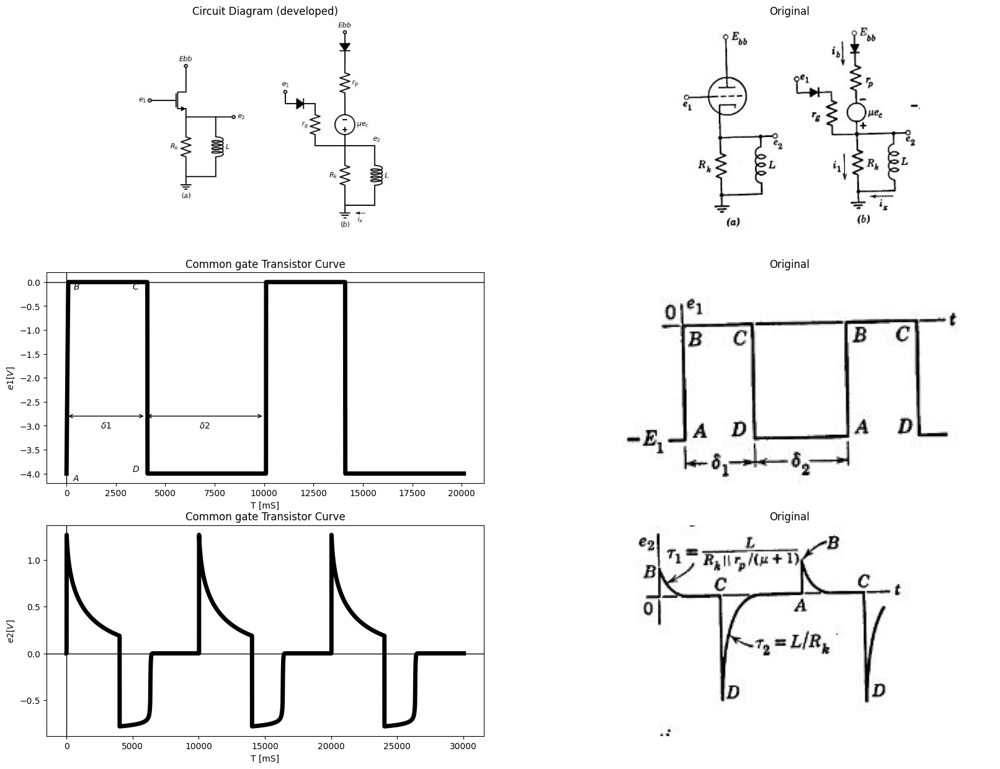

In [110]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().down(d.unit*1).label('$R_k$', 'top').at(M1.source))
l1 = d.add(elm.Line().right(d.unit*.5).at(R1.start))
d += (L1:=elm.Inductor2().down(d.unit*1).color('black').label('$L$','bottom').at(l1.end))
l2 = d.add(elm.Line().right(d.unit*.3).at(l1.end).dot(open=True).label('$e_2$','right'))
l3 = d.add(elm.Line().left(d.unit*.5).at(L1.end))
G = d.add(elm.Ground().at(R1.end).label('$(a)$','bottom'))
l3 = d.add(elm.Line().left(d.unit*.3).at(M1.gate).dot(open=True).label('$e_1$','left'))
l4 = d.add(elm.Line().up(d.unit*.3).at(M1.drain).dot(open=True).label('$Ebb$','right'))
l5 = d.add(elm.Line().up(d.unit*.2).at((8,2)).dot(open=True).label('$Ebb$','right'))
D= d.add(elm.Diode(fill=True).down(d.unit*.5))
d += (R1 := elm.Resistor().down(d.unit*.7).label('$r_p$', 'bottom'))
d += elm.SourceV().down(d.unit*.7).label(r'$\mu e_c$', 'bottom') 
l7 = d.add(elm.Line().up(d.unit*.2).at((5,-1)).dot(open=True).label('$e_1$','right'))
D= d.add(elm.Diode(fill=True).right(d.unit*.5).at(l7.start))
d += (R3 := elm.Resistor().down(d.unit*.7).label('$r_g$', 'top'))
l13 = d.add(elm.Line().right(d.unit*.5))
d += (R5 := elm.Resistor().down(d.unit*1).label('$R_k$', 'top'))
l14 = d.add(elm.Line().right(d.unit*.5).at(l13.end))
d += (L1:=elm.Inductor2().down(d.unit*1).color('black').label('$L$','bottom').label('$e_2$','right'))
l14 = d.add(elm.Line().left(d.unit*.5))
G = d.add(elm.Ground().at(R5.end).label('$(b)$','bottom'))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','bottom'). at((9,-6.5))
d.save('images/8-38-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-38-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-38a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-4@u_V, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].text( 500, -4.1, '$A$', ha='center', va='center')
axs[1,0].text( 3500, -3.9, '$D$', ha='center', va='center')
axs[1,0].text( 500, -.1, '$B$', ha='center', va='center')
axs[1,0].text( 3500, -0.1, '$C$', ha='center', va='center')
axs[1,0].text( 2000, -3, '$δ1$', ha='center', va='center')
axs[1,0].text( 7000, -3, '$δ2$', ha='center', va='center')
axs[1,0].annotate('', xy=(0., -2.8), xytext=(4000, -2.8), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(4000., -2.8), xytext=(10000, -2.8), arrowprops=dict(arrowstyle='<->'))
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-38b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 400@u_Ohm)
#circuit.R(2, 'e2', circuit.gnd, .10@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 10@u_mH)

circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)

axs[2,0].plot(analysis['e2'],'black',linewidth=5)
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$e2 [V]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-38c.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

Text(0.5, 1.0, 'Original')

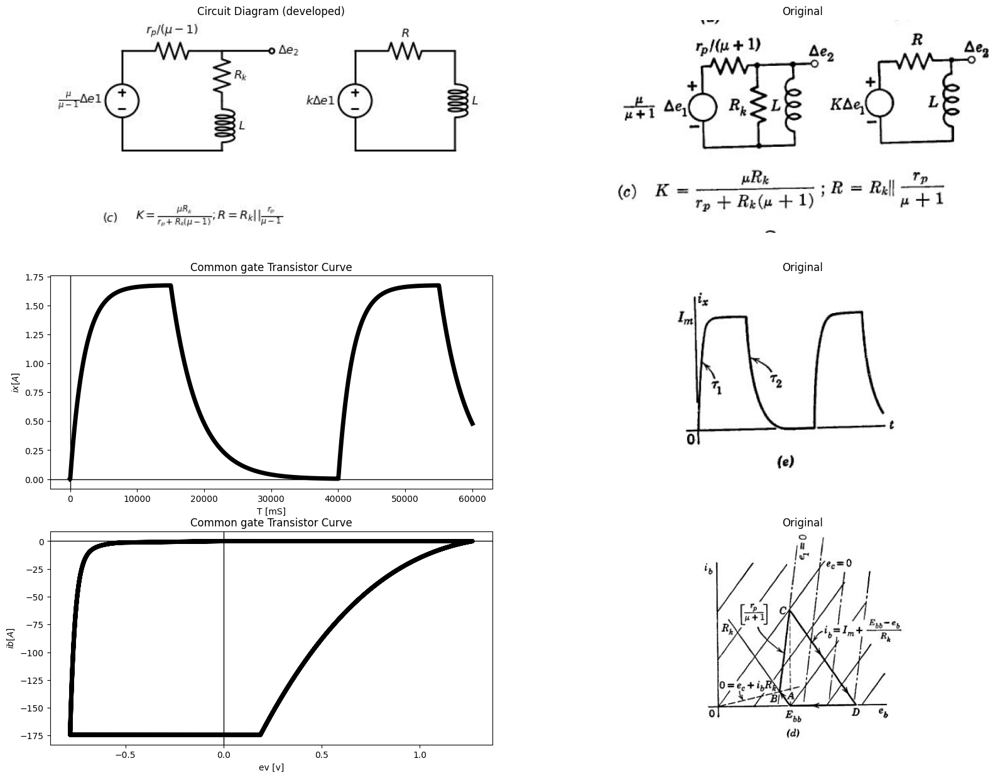

In [131]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1).label(r'$\frac {\mu}{\mu -1}∆e1$', 'top') 
d += (R1 := elm.Resistor().right(d.unit*1).label(r'$r_p/(\mu -1)$', 'top'))
d += (R2 := elm.Resistor().down(d.unit*.5).label('$R_k$', 'bottom'))
d += (L1:=elm.Inductor2().down(d.unit*.5).color('black').label('$L$','bottom'))
l1 = d.add(elm.Line().left(d.unit*1))
l2 = d.add(elm.Line().right(d.unit*.5).label('$∆e_2$','right').dot(open=True).at(R1.end))
d += elm.SourceV().up(d.unit*1).label(r'$k∆e1$', 'top').at((7,0)) 
d += (R1 := elm.Resistor().right(d.unit*1).label('$R$', 'top'))
d += (L1:=elm.Inductor2().down(d.unit*1).color('black').label('$L$','bottom'))
l1 = d.add(elm.Line().left(d.unit*1))
l1 = d.add(elm.Line().right(d.unit*.1).color('white').at((0,-2)).label('$(c)$','left',color='black').label(r'$K=\frac {\mu R_k}{r_p +R_k(\mu -1)}; R=R_k|| \frac {r_p}{\mu -1} $','right',color='black'))
d.save('images/8-38-2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-38-2.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-38d.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=3@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'ek',circuit.gnd, model='2N7000')
circuit.R(1, 'ek', circuit.gnd, 200@u_Ohm)
circuit.C(1, 'ek','e2', 10@u_uF)
circuit.R(2, 'e2', circuit.gnd, 200@u_Ohm)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[1,0].plot(analysis['ek']-analysis['e2'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$ix [A]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-38e.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 400@u_Ohm)
#circuit.R(2, 'e2', circuit.gnd, .10@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 10@u_mH)

circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)

axs[2,0].plot(analysis['e2'], u_mA(-analysis.L1),'black',linewidth=5,label = "Load Line")
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].set_xlabel('ev [v]')
axs[2,0].set_ylabel('$ib [A]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-38d1.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig.8.38 Cathode follower with parallel RL Load

Point Will follow the $R {k}$ Line down to the $i {b} = 0$ axis . From the graph it can be sean that the required nagative value of $e {1}$vfor cutoff is



$$ e {1} = -E_1 = -I{m}R{k}- \frac {(E{bb}+I{m}R_k)}{\mu}$$ $$(8.45)$$

During the interval $\delta_{2}$ (D to A), the current ix and voltage es decay to  zero, and the locus returns to A along the $i {b} = 0$ axis.  
Figure 8.38(d) shows both the $e {c}$ lines and the $e {1}$ lines. The locus can  be plotted using either of the methods discussed in Article 26.  


Text(0.5, 1.0, 'Original')

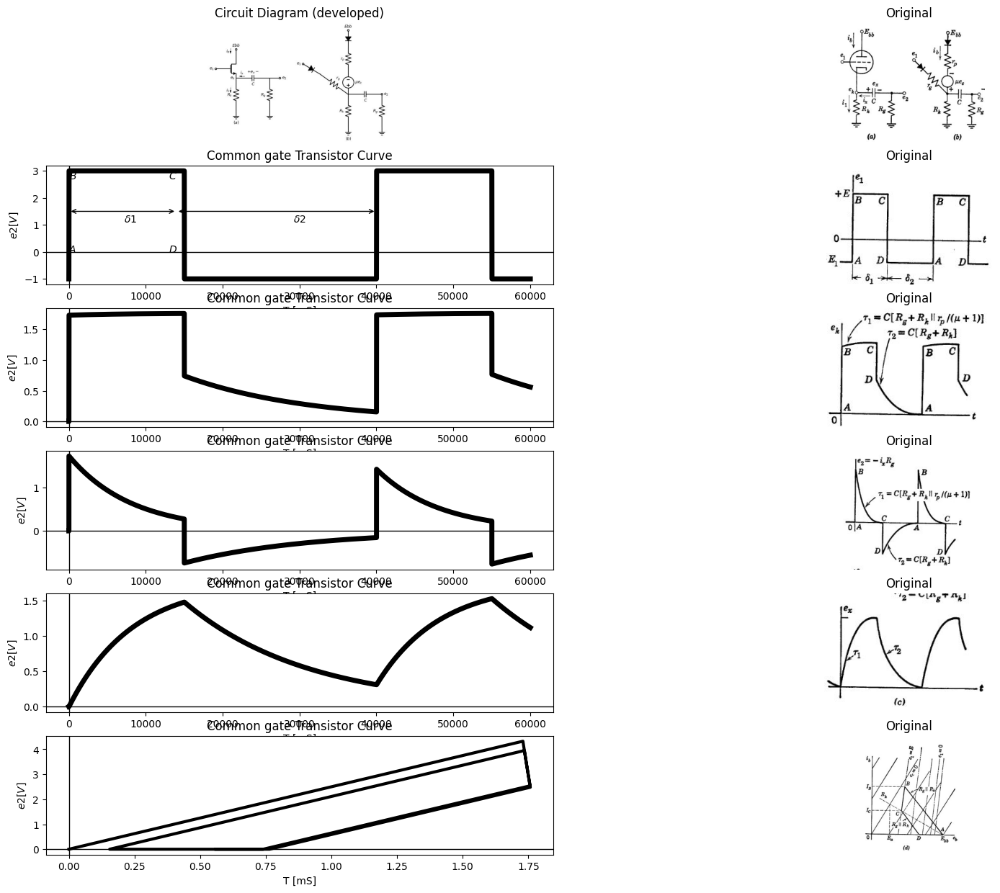

In [93]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().down(d.unit*1).label('$R_k$', 'top').at(M1.source))
l1 = d.add(elm.Line().left(d.unit*.3).at(M1.gate).dot(open=True).label('$e_1$', 'left'))
l2 = d.add(elm.Line().up(d.unit*.3).at(M1.drain).dot(open=True).label('$Ebb$','right'))
d += (C1:=elm.Capacitor().right(d.unit*1).color('black').label('$C$','bottom').at(R1.start).label('$e_k$','left').label('$ +  e_x -$','top'))
d += (R2 := elm.Resistor().down(d.unit*1).label('$R_g$', 'top'))
l3 = d.add(elm.Line().right(d.unit*.3).at(C1.end).dot(open=True).label('$e_2$', 'right'))
G = d.add(elm.Ground().at(R1.end).label('$(a)$','bottom'))
G = d.add(elm.Ground().at(R2.end))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_b$','top'). at((-.5,1))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.5,-2.5))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','top'). at((.75,-1.5))
l5 = d.add(elm.Line().up(d.unit*.2).at((10,2)).dot(open=True).label('$Ebb$','right'))
D= d.add(elm.Diode(fill=True).down(d.unit*.5))
d += (R1 := elm.Resistor().down(d.unit*.7).label('$r_p$', 'top'))
d += elm.SourceV().down(d.unit*.7).label(r'$\mu e_c$', 'bottom') 
l8 = d.add(elm.Line().left(d.unit*0.01))
l9 = d.add(elm.Line().left(d.unit*0.01).at((7.5,-1.3)))
d += (R1 := elm.Resistor().down(d.unit*.7).label('$r_g$', 'top').endpoints(l8.end,l9.end))
l10 = d.add(elm.Line().left(d.unit*0.01).at((6,-.4)).dot(open=True).label('$e_1$', 'left'))
D= d.add(elm.Diode(fill=True).down(d.unit*.5).endpoints(l10.end,l9.end))
d += (R10 := elm.Resistor().down(d.unit*1).label('$R_k$', 'top').at(l8.start))
d += (C1:=elm.Capacitor().right(d.unit*1).color('black').label('$C$','bottom').at(R10.start).dot(open=True).label('$e_2$','right'))
d += (R11 := elm.Resistor().down(d.unit*1).label('$R_g$', 'top'))
G = d.add(elm.Ground().at(R10.end).label('$(b)$','bottom'))
G = d.add(elm.Ground().at(R11.end))
d.save('images/8-39-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-39-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-39a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=3@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e2 [V]$')
axs[1,0].text( 500, 0.1, '$A$', ha='center', va='center')
axs[1,0].text( 13500, 0.1, '$D$', ha='center', va='center')
axs[1,0].text( 500, 2.8, '$B$', ha='center', va='center')
axs[1,0].text( 13500, 2.8, '$C$', ha='center', va='center')
axs[1,0].text( 8000, 1.2, '$δ1$', ha='center', va='center')
axs[1,0].text( 30000, 1.2, '$δ2$', ha='center', va='center')
axs[1,0].annotate('', xy=(0., 1.5), xytext=(14000, 1.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(14000., 1.5), xytext=(40000, 1.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-39b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=3@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'ek',circuit.gnd, model='2N7000')
circuit.R(1, 'ek', circuit.gnd, 800@u_Ohm)
circuit.C(1, 'ek','e2', 10@u_uF)
circuit.R(2, 'e2', circuit.gnd, 800@u_Ohm)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[2,0].plot(analysis['ek'],'black',linewidth=5)
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$e2 [V]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-39b1.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=3@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'ek',circuit.gnd, model='2N7000')
circuit.R(1, 'ek', circuit.gnd, 800@u_Ohm)
circuit.C(1, 'ek','e2', 10@u_uF)
circuit.R(2, 'e2', circuit.gnd, 800@u_Ohm)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[3,0].plot(analysis['e2'],'black',linewidth=5)
axs[3,0].set_title('Common gate Transistor Curve') 
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('$e2 [V]$')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-39c.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=3@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'ek',circuit.gnd, model='2N7000')
circuit.R(1, 'ek', circuit.gnd, 800@u_Ohm)
circuit.C(1, 'ek','e2', 10@u_uF)
circuit.R(2, 'e2', circuit.gnd, 800@u_Ohm)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[4,0].plot(analysis['ek']-analysis['e2'],'black',linewidth=5)
axs[4,0].set_title('Common gate Transistor Curve') 
axs[4,0].set_xlabel('T [mS]')
axs[4,0].set_ylabel('$e2 [V]$')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-39e.JPG')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=3@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'ek',circuit.gnd, model='2N7000')
circuit.R(1, 'ek', circuit.gnd, 800@u_Ohm)
circuit.C(1, 'ek','e2', 10@u_uF)
circuit.R(2, 'e2', circuit.gnd, 800@u_Ohm)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[5,0].plot(analysis['ek'], u_mA(-analysis.V3),'black',linewidth=3)
axs[5,0].set_title('Common gate Transistor Curve') 
axs[5,0].set_xlabel('T [mS]')
axs[5,0].set_ylabel('$e2 [V]$')
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-39g.JPG')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

## Fig.8.39. Cathode folower with capacitive coupling

# 8.28 Cathode Follower with Capacitive Coupling  
The circuit of Fig. 8.39 (a) shows a cathode follower with d-c load  resistance $R {k}$ and capacitive coupling to another resistance $R {g}$. In the interests of brevity, we shall again confine our attention to the locus of  operation with a rectangular input waveform having intervals large  compared with the corresponding time constants. Recall that, for a  given range of input waveform amplitudes, this case yields the bounding  locus within which all others fall.  
Using the piecewise-linear model shown in Fig. 8.39(b) and the input  waveform shown in (c), we can determine pertinent waveforms and the  locus of the operating point. The waveforms of cathode voltage ek,  output voltage $e₂$, and the capacitor voltage $e {x}$ are shown.  
Referring to the locus of operation in Fig. 8.39(d), we see that the transition from A to B follows a line whose slope is determined by  $R{g} || R{k}$, since $e{x}$ is zero at this time and cannot change instantaneously.  In this example, the value of + E has been chosen to avoid the positive grid region. Point B is located at the intersection of the RoRk load line  and the line $e₁ = E$. As the capacitor begins to charge, the current $i{x}$  through $R{g}$, decreases, and the operating point moves down the $e1=E$  line to the quiescent point C on the $R{k}$ load line. Again during the  transition from C to D, the locus follows a line whose slope depends on  
$R{g}||R{k}$. The closure from D to A occurs with $i{b} = 0$ and $i₁ = i{x}$.  
Note that $e{k}$ changes only very slightly between B and C, whereas $e_2$  changes very markedly. This is due to the fact that the incremental  resistance between cathode and ground when the triode is conducting is  $Rk||(rp/(μ +1))$, which is much smaller than $R_g$.  
As$ R_g$, is decreased, the locus transitions from A to B and from C to D  tend to approach the vertical. In this case the upward transition  (A to B) can drive the triode far into the positive-grid region.  
# 8.29 Cathode Follower with Parallel RC Load 




An important consideration in the operation of cathode followers at  high frequencies is the effect on circuit performance of cathode-to-ground  capacitance. In Fig. 8.40(a), C could be an actual capacitor, or it may  represent tube and wiring capacitances.  
The piecewise-linear model is shown in Fig. 8.40(b). The waveforms  in (c) are drawn for two different input amplitudes, one small enough to  keep the tube in the linear region, and the other sufficiently large to cut  the tube off for a portion of the cycle. Let us treat the linear case first.  
Point A on the locus, Fig. 8.40(d), is located at the juncture of the  $R_k$ load line and the $e_1 = E_₁$ line. When the input voltage jumps to $E_2$,  the cathode voltage cannot change instantaneously; so the operating  point moves vertically to the $e_1= E_2 $ line. As the capacitor charges, the operating point is constrained to the $e_1 = E_2$ line, moving down to  point C at the intersection of the $R_k$ load line. The return cycle CDA is  constructed in a similar manner. As the tube is always conducting in  


Text(0.5, 1.0, 'Original')

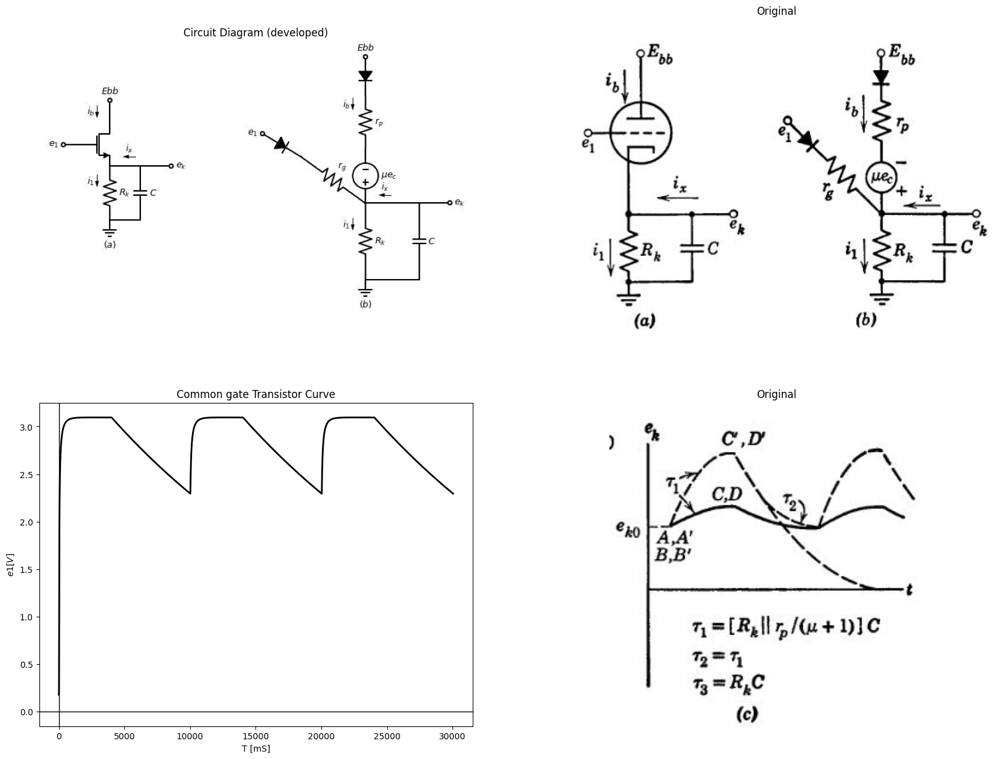

In [74]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().down(d.unit*.7).label('$R_k$', 'bottom').at(M1.source))
l1 = d.add(elm.Line().left(d.unit*.3).at(M1.gate).dot(open=True).label('$e_1$', 'left'))
l2 = d.add(elm.Line().up(d.unit*.3).at(M1.drain).dot(open=True).label('$Ebb$','right'))
G = d.add(elm.Ground().at(R1.end).label('$(a)$','bottom'))
l3 = d.add(elm.Line().right(d.unit*.4).at(M1.source))
d += (C1:=elm.Capacitor().down(d.unit*.7).color('black').label('$C$','bottom').at(l3.end))
l4 = d.add(elm.Line().left(d.unit*.4))
l5 = d.add(elm.Line().right(d.unit*.4).at(l3.end).dot(open=True).label('$e_k$', 'right'))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_b$','top'). at((-.5,.7))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((-.5,-2))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','top'). at((1,-1.3))
l6 = d.add(elm.Line().up(d.unit*.2).at((10,2)).dot(open=True).label('$Ebb$','right'))
D= d.add(elm.Diode(fill=True).down(d.unit*.5))
d += (R1 := elm.Resistor().down(d.unit*.7).label('$r_p$', 'bottom'))
d += elm.SourceV().down(d.unit*.7).label(r'$\mu e_c$', 'bottom') 
l8 = d.add(elm.Line().left(d.unit*0.01))
l9 = d.add(elm.Line().left(d.unit*0.01).at((7.5,-1.3)))
d += (R1 := elm.Resistor().down(d.unit*.7).label('$r_g$', 'top').endpoints(l8.end,l9.end))
l10 = d.add(elm.Line().left(d.unit*0.01).at((6,-.4)).dot(open=True).label('$e_1$', 'left'))
D= d.add(elm.Diode(fill=True).down(d.unit*.5).endpoints(l10.end,l9.end))
d += (R10 := elm.Resistor().down(d.unit*1).label('$R_k$', 'bottom').at(l8.start))
l11 = d.add(elm.Line().right(d.unit*.7).at(R10.start))
d += (C1:=elm.Capacitor().down(d.unit*1).color('black').label('$C$','bottom'))
l12 = d.add(elm.Line().left(d.unit*.7))
G = d.add(elm.Ground().at(R10.end).label('$(b)$','bottom'))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_b$','top'). at((9.5,1))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_1$','top'). at((9.5,-3.7))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_x$','top'). at((11,-2.8))
l5 = d.add(elm.Line().right(d.unit*.4).at(l11.end).dot(open=True).label('$e_k$', 'right'))
d.save('images/8-40-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-40-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-40a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('v-i curve')
circuit.model('2N7000', 'NMOS', L=180E-9, W=2E-6, Kp=0.13, Vto=0.8)
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=1@u_V, pulsed_value=4@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.MOSFET(1, 'Ebb', 'e1', 'ek',circuit.gnd, model='2N7000')
circuit.R(1, 'ek', circuit.gnd, 400@u_Ohm)
circuit.C(1, 'ek', circuit.gnd, 50@u_uF)
circuit.V(2, 'Ebb', circuit.gnd, 5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[1,0].plot(analysis['ek'],'black',linewidth=2)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-40c.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

## Fig.8.40 Cathode follower with parallel RC load

this case , the time constants involved in the $e_k$ Waveform are 


$$ \tau1 = \tau2 = \frac {CR_k(\frac {r_p}{μ +1})}{R_k + (\frac {r_p}{μ +1})}$$    $$(8.46)$$

The effect of shunt capacitance on linear cathode-follower operation can  be seen by inspection of the locus. The vertical rise AB and vertical drop  CD have the effect of greatly decreasing the magnitude of the input  voltage that can be handled by the circuit if linear operation is desired. 
If the input waveform amplitude is increased, the locus expands  (A'B'C'D'); and if $E3 - E1 $is sufficiently large, the tube will be cut off  immediately following the fast drop in input voltage (C'D'). In this  case the time constant of discharge will be $CR_k $until the tube again  begins to conduct. Note, however, that although the time constant is  larger when the tube is cut off, the final value of this exponential is zero  rather than eko. The capacitor will be discharged to a given voltage  more rapidly if the tube is cut off than if it remains conducting. This  fact can be demonstrated by writing the current equation for the  cathode circuit. From Fig. 8.40(a), 

$$ i_x = i_1 - i_b = \frac {e_k}{R_k} - i_b $$   $$(8.47)$$

and $$i_x= -c \frac {de_k}{d_t}$$   $$(8.48)$$


Therefore $$\frac {de_k}{d_t} = - \frac {e_k}{CR_k} + \frac {i_b}{c}$$ $$(8.49)$$

Since is can never be negative, the capacitor will be discharged to a given  voltage most rapidly if $i {b}= 0$; that is, if the tube is cut off.  
The loci shown in Fig. 8.40(d) extend into the positive-grid region if  e₁ is greater than $E_3$. In this case the grid diode closes and the capacitor  is charged by grid current in addition to plate current.  
# 8.30 Grounded-Base Transistor with  Inductive Collector Load 


The methods for determining waveforms and locus of operation for a  triode circuit can be applied to pentode or transistor circuits. For  example, let the p-n-p junction transistor in the grounded-base circuit  of Fig. 8.41 (a) be represented by the ideal-diode model shown in (b).  The shunt diode D. and source $V_z$, shown by dotted lines between  collector and ground, provide the voltage limiting due to the avalanche  effect in the semiconductor. The collector curves (vcd vs. ic) for this  model are shown in (c). The locus of the operating point (ABCDEA)  corresponds to the rectangular waveform of current is shown in (d),  where waveforms of $i_c$ and $v_cb$ are also shown. Intervals $\delta_{1}$and $\delta_{2}$ are  assumed large compared with the time constant$ L/R$.  
The idealization of the transistor model greatly simplifies the locus  and waveform determinations. When the input current switches from A to B, $i_c= i_x$ held at zero instantaneously because of inductance L.  Since $i_c$ remains at zero, the source $ai_e$ closes the collector diode D.;  hence voltage vet switches instantaneously to zero. This voltage remains  zero until i builds up exponentially $(\tau1 = L/R)$ to the value$-V_c/R.$   


Text(0.5, 1.0, 'Original')

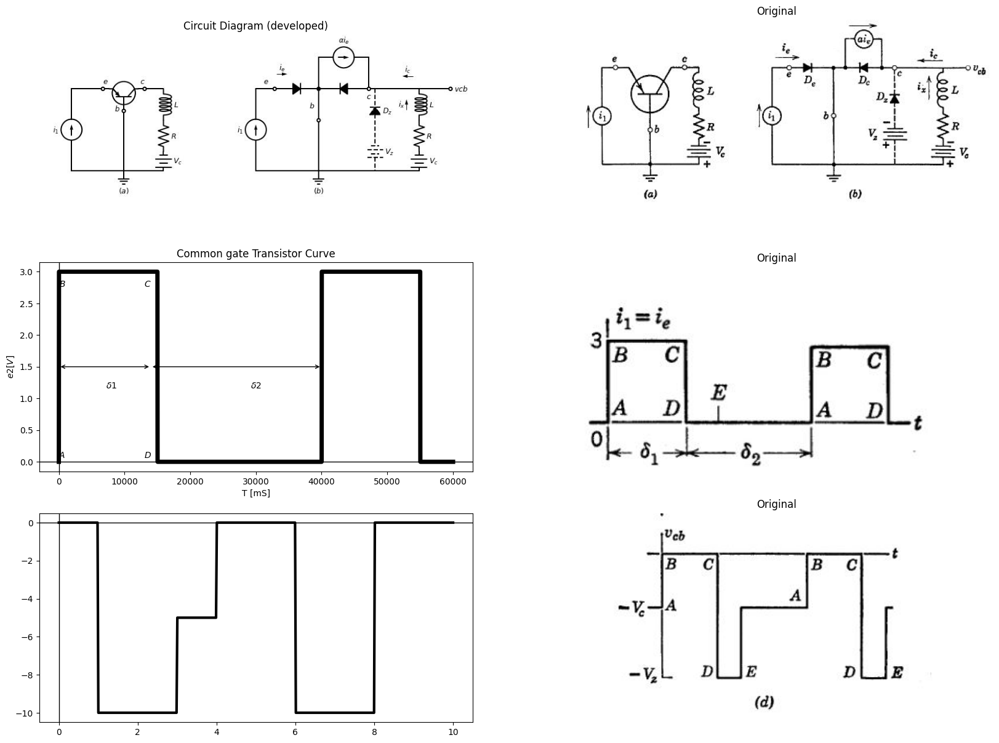

In [53]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.BjtPnp(circle=True).anchor('emitter').theta(90))
l1 = d.add(elm.Line().right(d.unit*.1).at(M1.collector).dot(open=True).label('$c$', 'top'))
l2 = d.add(elm.Line().left(d.unit*.1).at(M1.emitter).dot(open=True).label('$e$', 'top'))
l3 = d.add(elm.Line().down(d.unit*.1).at(M1.base).dot(open=True).label('$b$', 'top'))
l4 = d.add(elm.Line().left(d.unit*.5).at(l2.end))
d += elm.SourceI().down(d.unit*1.3).label('$i_1$', 'top') .reverse()
l5 = d.add(elm.Line().right(d.unit*.83))
l6 = d.add(elm.Line().up(d.unit*0.92))
l7 = d.add(elm.Line().right(d.unit*.3).at(l1.end))
d += (L1:=elm.Inductor2().down(d.unit*.5).color('black').label('$L$','bottom'))
d += (R1 := elm.Resistor().down(d.unit*.5).label('$R$', 'bottom'))
d += elm.Battery().down(d.unit*.3).label('$V_c$', 'bottom') .reverse()
l8 = d.add(elm.Line().left(d.unit*0.85))
I1 =  d.add(elm.SourceI().down(d.unit*1.3).label('$i_1$', 'top') .reverse().at((7,0)))
l9 = d.add(elm.Line().right(d.unit*.3).dot(open=True).label('$e$', 'top').at(I1.start))
D1= d.add(elm.Diode(fill=True).right(d.unit*.7).dot())
l10 = d.add(elm.Line().down(d.unit*.5).dot(open=True).label('$b$', 'top'))
l11 = d.add(elm.Line().down(d.unit*.8))
l12 = d.add(elm.Line().left(d.unit*1))
D2= d.add(elm.Diode(fill=True).right(d.unit*.8).at(D1.end).reverse())
l13 = d.add(elm.Line().up(d.unit*.5).at(D1.end))
I2 =  d.add(elm.SourceI().right(d.unit*.8).label('$α i_e$', 'top'))
l14 = d.add(elm.Line().down(d.unit*.5).dot(open=True).label('$c$', 'left'))
l15 = d.add(elm.Line().right(d.unit*.1))
D3= d.add(elm.Diode(fill=True).down(d.unit*.7).reverse().linestyle('--').label('$D_z$', 'bottom'))
d += elm.Battery().down(d.unit*.6).label('$V_z$', 'bottom') .reverse().linestyle('--')
l16 = d.add(elm.Line().left(d.unit*1))
l17 = d.add(elm.Line().right(d.unit*.7).at(D3.start))
d += (L1:=elm.Inductor2().down(d.unit*.5).color('black').label('$L$','bottom'))
d += (R1 := elm.Resistor().down(d.unit*.5).label('$R$', 'bottom'))
d += elm.Battery().down(d.unit*.3).label('$V_c$', 'bottom') .reverse()
l18 = d.add(elm.Line().left(d.unit*1))
l19 = d.add(elm.Line().right(d.unit*.5).dot(open=True).label('$vcb$', 'right').at(L1.start))
d += elm.Arrow().right().length(.5).linewidth(1).color('black').label('$i_e$','top'). at((8,.7))
d += elm.Arrow().left().length(.5).linewidth(1).color('black').label('$i_c$','top'). at((14.5,.6))
d += elm.Arrow().up().length(.5).linewidth(1).color('black').label('$i_x$','top'). at((14.2,-1))
G = d.add(elm.Ground().at(l11.end).label('$(b)$','bottom'))
G = d.add(elm.Ground().at(l6.start).label('$(a)$','bottom'))
d.save('images/8-41-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-41-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-41a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=3@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e2 [V]$')
axs[1,0].text( 500, 0.1, '$A$', ha='center', va='center')
axs[1,0].text( 13500, 0.1, '$D$', ha='center', va='center')
axs[1,0].text( 500, 2.8, '$B$', ha='center', va='center')
axs[1,0].text( 13500, 2.8, '$C$', ha='center', va='center')
axs[1,0].text( 8000, 1.2, '$δ1$', ha='center', va='center')
axs[1,0].text( 30000, 1.2, '$δ2$', ha='center', va='center')
axs[1,0].annotate('', xy=(0., 1.5), xytext=(14000, 1.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(14000., 1.5), xytext=(40000, 1.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-41b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
# Define time axis
t = np.linspace(0, 10, 500)  # 500 points between 0 and 10

# Define the waveform
v = np.zeros_like(t)
v[(t > 1) & (t <= 2)] = -10        # A to D
v[(t > 2) & (t <= 3)] = -10       # D to E
v[(t > 3) & (t <= 4)] = -5       # E to A
v[(t > 4) & (t <= 5)] = 0        # A to B
v[(t > 5) & (t <= 6)] = 0        # B to C
v[(t > 6) & (t <= 7)] = -10       # C to D
v[(t > 7) & (t <= 8)] = -10       # D to E
v[(t > 8) & (t <= 9)] = 0        # E to B

axs[2,0].plot(t, v, label='Waveform',color='black', linewidth=3)

axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-41=d.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig 8.41 Grounded-base transistor With inductive colloctor Load.

The input transition from C to D reduces $ai_e$, to zero and therefore  opens $D_c$. Now the collector current is zero, but the inductor current $i_x$  tries to remain constant at$ -V_c/R$; hence the voltage $v_cb$ drops to $-V_z$, thus closing $D_z$. The current is now varies exponentially $(\tau1 =\tau2=L/R)$ from $-V_c/R$ toward $+(V_z-V_c)/R.$ When is reaches zero,however the diode $D_z$ opens and permits $v_cb$ to instantaneously from $-V_z$ to $-V_c$ in order to complete the cycle.


Text(0.5, 1.0, 'Original')

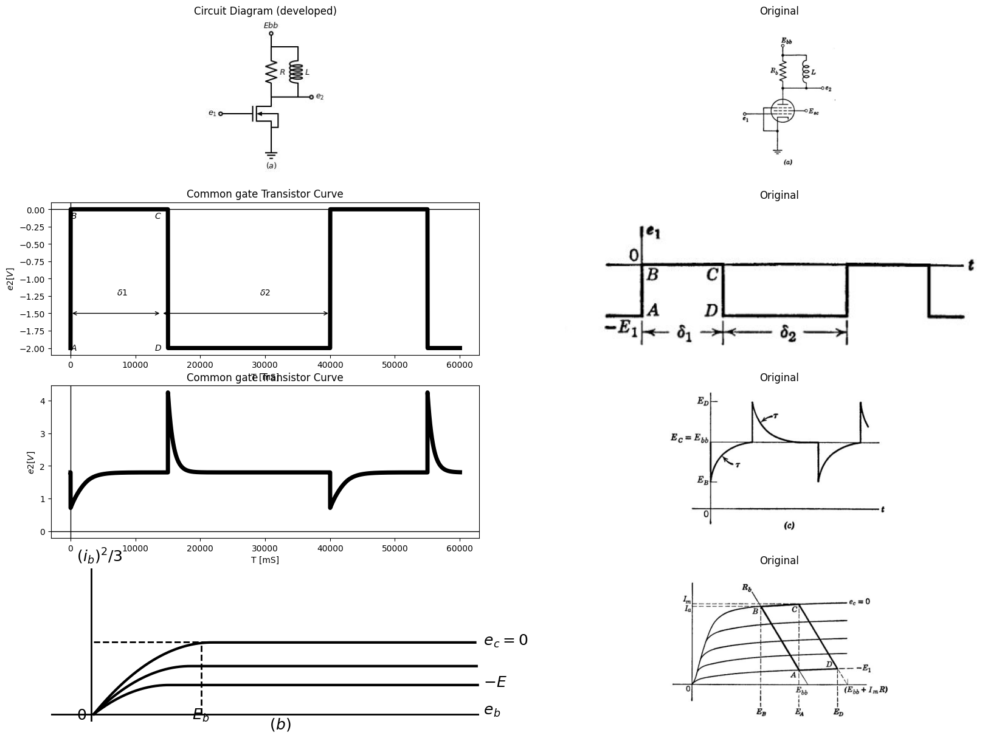

In [37]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.NFet(bulk = True).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.3).dot(open=True).label('$e_1$', 'left').at(M1.gate))
l2 = d.add(elm.Line().down(d.unit*.2).at(M1.source))
l3 = d.add(elm.Line().right(d.unit*.1).at(M1.bulk))
l4 = d.add(elm.Line().down(d.unit*.2))
l5 = d.add(elm.Line().left(d.unit*.1))
G = d.add(elm.Ground().at(l2.end).label('$(a)$','bottom'))
d += (R1 := elm.Resistor().up(d.unit*.75).label('$R$', 'bottom').at(M1.drain))
l6 = d.add(elm.Line().right(d.unit*.4).at(M1.drain))
d += (L1:=elm.Inductor2().up(d.unit*.75).color('black').label('$L$','bottom').at(l6.end))
l7 = d.add(elm.Line().left(d.unit*.4))
l8 = d.add(elm.Line().up(d.unit*.2).dot(open=True).label('$Ebb$','right'))
l9 = d.add(elm.Line().right(d.unit*.2).dot(open=True).label('$e_2$','right').at(L1.start))
d.save('images/8-42-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-42-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-42a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e2 [V]$')
axs[1,0].text( 500, -2, '$A$', ha='center', va='center')
axs[1,0].text( 13500, -2, '$D$', ha='center', va='center')
axs[1,0].text( 500, -.1, '$B$', ha='center', va='center')
axs[1,0].text( 13500, -.1, '$C$', ha='center', va='center')
axs[1,0].text( 8000, -1.2, '$δ1$', ha='center', va='center')
axs[1,0].text( 30000, -1.2, '$δ2$', ha='center', va='center')
axs[1,0].annotate('', xy=(0., -1.5), xytext=(14000, -1.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(14000., -1.5), xytext=(40000, -1.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-42b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=15@u_ms, period=40@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'e2', 'Ebb', 10@u_Ohm)
circuit.L(1, 'e2','Ebb', 8@u_mH)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=60@u_ms)
axs[2,0].plot(analysis['e2'],'black',linewidth=5)
axs[2,0].set_title('Common gate Transistor Curve') 
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$e2 [V]$')

axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-42c.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
x_values = [25, 25]  
y_values = [0, 99000]  

x1_values = [0, 32]  
y1_values = [99000, 99000]

x2_values = [15, 50]  
y2_values = [80000, 155000]

circuit = Circuit('NMOS')
circuit.model('2N7000', 'NMOS', L=100E-6, W=200E-6, Kp=0.13, Vto=2.475)
Vgate = circuit.V('gate','gate',circuit.gnd,   0@u_V)
circuit.R(2, 'drain', '2', 0.01@u_Ohm)
Vi = circuit.V('i', '2', circuit.gnd, 1@u_V)
circuit.MOSFET(1, 'drain', 'gate', circuit.gnd,circuit.gnd, model='2N7000')
for gate_voltage in np.arange(20,35, 5):
    gate_voltage = gate_voltage@u_V
    Vgate.dc_value = gate_voltage
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(0, 90, 0.1))
    axs[3,0].plot(analysis['drain'], u_mA(-analysis.Vi),linewidth=3, color='black')
    
axs[3,0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[3,0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
#axs[3,0].plot(x2_values, y2_values, ls='--', color='black', linewidth=2)
axs[3,0].axhline(10, color='black',linewidth=2, ls='-')
axs[3,0].axvline(-0.63, color='black',linewidth=2, ls='-')
axs[3,0].axis('off')
axs[3,0].text(-5,210000, ' $(i_b)^2/3$ ', fontsize=18)
axs[3,0].text(-5,-7000, ' $0$ ', fontsize=18)
axs[3,0].text(22,-7000, ' $E_b$ ', fontsize=18)
axs[3,0].text(90,0, ' $e_b$ ', fontsize=18)
axs[3,0].text(90,38000, ' $-E$ ', fontsize=18)
axs[3,0].text(90,95000, ' $e_c=0$ ', fontsize=18)
axs[3,0].text(40,-20000, ' $(b)$ ', fontsize=18)
axs[3,0].set_xlim(-10, 90)
axs[3,0].set_ylim(-10000,200000)
img_sample = mpimg.imread('images/8-42d.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig8.42 Pentode With Parallel RL Load ($\delta_{1},\delta_{2}$ > $5\tau$ )

# 8.31 Pentode with parallel RL Load

with the exception of the preceding article , we have used triodes in the single-time-constant circuits analyzed in this chapter. it was convention to use one type of device in order to show the effects of load and  input waveform variations with a minimum of other changes. However,  once we specify a device by means of characteristic curves or a circuit  model, the analysis proceeds in the same manner for any of the devices  we have discussed. By way of illustration, Fig. 8.42 shows a pentode  with parallel $RL$ load. The locus and output waveform should be compared with those in Figs. 8.33 and 8.34. The shape of the locus appears  to be different principally because the pentode is very nearly a voltage- controlled current source, whereas a triode more nearly resembles a  voltage-controlled voltage source.  
Since $R_b$ is much less than the plate resistance of a pentode, the  apparent resistance faced by the inductance is very nearly $R_b$ whether  or not the pentode conducts.  
Another difference that may be important is the magnitude of interelectrode capacitances. The grid-to-plate capacitance of the triode  couples some of the input signal to the output (and vice versa). In the pentode, this capacitance is small enough to be neglected at all but very  high frequencies.  
As in the case of the RC coupling circuit we can approximate the  effects of tube and wiring capacitances fairly readily. If the small  capacitance $(say 10 µµf)$ is assumed to exist between plate and ground  in Fig. 8.41 the load on the pentode is effectively a parallel $RLC$ circuit.  For such a small value of $C$ the waveform of $e_₂$ is only slightly modified.  The instantaneous jumps become finite slopes and the sharp peaks are  slightly rounded.  
# 8.32 Pentode with Parallel RLC Load  
A pentode with a parallel $RLC$ load is shown in Fig. 8.43 (a). For  a typical pentode in the normal region of operation the plate current  is nearly independent of the plate voltage. Thus the rectangular  waveform of plate current shown in Fig. 8.43(d), as determined by the resistive load alone, remains virtually unchanged when the inductance  and capacitance are connected. The behavior, therefore, can be deter mined from the general linear circuit shown in (c). Whether or not  the input waveform causes plate-current cutoff makes relatively little  difference in incremental behavior, since the plate resistance for a  pentode is very large compared with load resistance $R.$ Thus we need  only examine the behavior of the parallel $RLC$ circuit with a rectangular  waveform of current applied as indicated in (d). The differential equation for the circuit is $$ \frac {d^2 v}{dt^2}+ \frac{1}{RC}. \frac{d_v}{d_t}+ \frac {v}{LC} =0$$  $$(8.50)$$


the roots of the characteristic equation are $$ S_1 = - \frac{1}{2RC}+ \sqrt {(\frac {1}{2RC})^2 - \frac{1}{LC}}$$ $$(8.51)$$
$$S_2 = - \frac{1}{2RC} - \sqrt {(\frac {1}{2RC})^2 - \frac{1}{LC}}$$ $$(8.51a)$$ 



the first three of the following modes correspond to positive , zero , and negative values of the radical , for  R positive , * while the fourth or undamped mode occurs for $ R= ∞$

1. Overdamped : $R < \frac {1}{2} \sqrt{\frac {L}{C}}$


2. Critically damped : $R= \frac{1}{2} \sqrt{\frac {L}{C}}$ $(8.52)$



3. Underdamped : $R > \frac{1}{2} \sqrt{\frac {L}{C}}$



4. Undamped   $ R= ∞$


The waveforms in Fig. 8.43 (e) and (f) correspond to underdamped  cases with (e) being near the critically damped case. The locus in (b)  is drawn for the critically damped mode of operation. The locus  corresponding to the waveform in (f) will be like that shown in (b)  except that the horizontal portions will extend nearly equally on both  sides of the vertical line at $Ebb$.  
The expressions for the incremental voltage across the tuned circuit  are given below. Adding $v $to $Ebb$ or subtracting it from $E_bb$ yields $e_2$ in  the two intervals. 

1. Overdamped   $$v = \frac {\frac {I_a}{C}}{S_1 - S_2} [e^(s1t) - e^(s2t)] $$   $$(8.53)$$



 2. Critically damped  $$ v= \frac {I_a}{C}t.e^-t/2RC $$ $$(8.54)$$


* If R is negative there are three negativeely-damped models. these are pertinent to oscillator theory and are treated in Chapter 10.

Text(0.5, 1.0, 'Original')

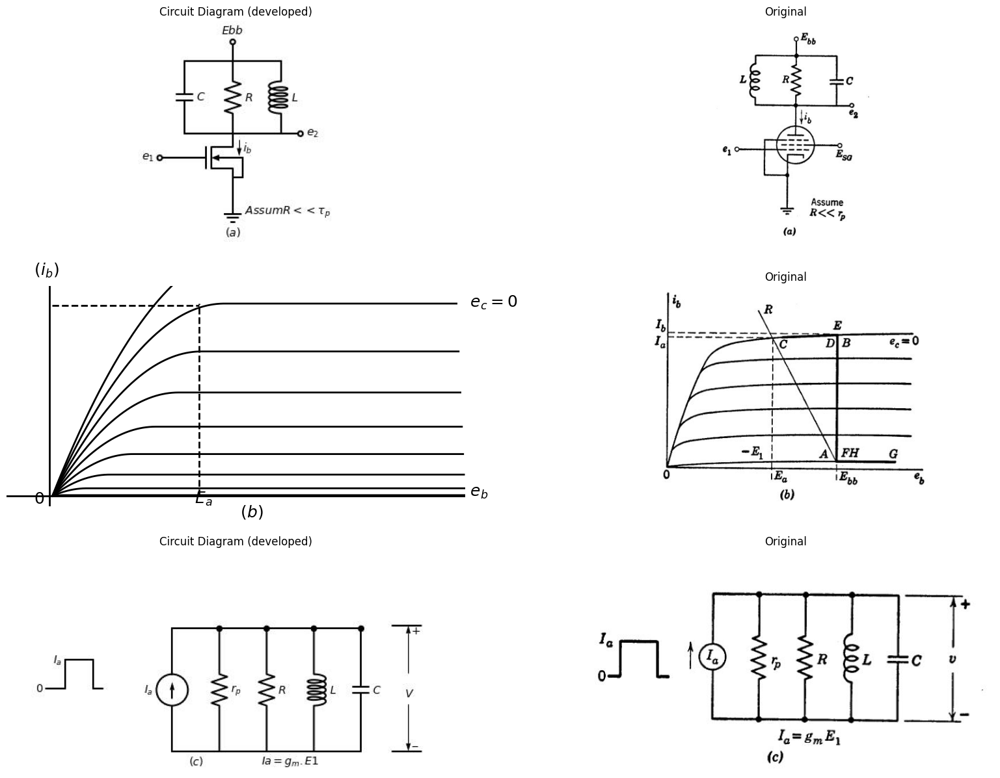

In [48]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.NFet(bulk = True).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.3).dot(open=True).label('$e_1$', 'left').at(M1.gate))
l2 = d.add(elm.Line().down(d.unit*.2).at(M1.source))
l3 = d.add(elm.Line().right(d.unit*.1).at(M1.bulk))
l4 = d.add(elm.Line().down(d.unit*.2))
l5 = d.add(elm.Line().left(d.unit*.1))
G = d.add(elm.Ground().at(l2.end).label('$(a)$','bottom').label(r'$      Assum   R<< τ_p$','right'))
d += (R1 := elm.Resistor().up(d.unit*.75).label('$R$', 'bottom').at(M1.drain))
l6 = d.add(elm.Line().right(d.unit*.5).at(M1.drain))
l7 = d.add(elm.Line().left(d.unit*.5).at(M1.drain))
d += (L1:=elm.Inductor2().up(d.unit*.75).color('black').label('$L$','bottom').at(l6.end))
d += (C1:=elm.Capacitor().up(d.unit*.75).color('black').label('$C$','bottom').at(l7.end))
l9 = d.add(elm.Line().right(d.unit*1))
l10 = d.add(elm.Line().up(d.unit*.2).at(R1.end).dot(open=True).label('$Ebb$','right'))
l11 = d.add(elm.Line().right(d.unit*.2).dot(open=True).label('$e_2$','right').at(L1.start))
d += elm.Arrow().down().length(.5).linewidth(1).color('black').label('$i_b$','bottom'). at((.2,-.2))
d.save('images/8-43-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-43-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-43a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
x_values = [32, 32]  
y_values = [0, 183000]  

x1_values = [0, 32]  
y1_values = [181000, 181000]

x2_values = [32, 56]  
y2_values = [180000, 255000]

circuit = Circuit('NMOS')
circuit.model('2N7000', 'NMOS', L=100E-6, W=200E-6, Kp=0.13, Vto=2.475)
Vgate = circuit.V('gate','gate',circuit.gnd,   0@u_V)
circuit.R(2, 'drain', '2', 0.01@u_Ohm)
Vi = circuit.V('i', '2', circuit.gnd, 1@u_V)
circuit.MOSFET(1, 'drain', 'gate', circuit.gnd,circuit.gnd, model='2N7000')
for gate_voltage in np.arange(0,50, 5):
    gate_voltage = gate_voltage@u_V
    Vgate.dc_value = gate_voltage
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(0, 90, 0.1))
    axs[1,0].plot(analysis['drain'], u_mA(-analysis.Vi),linewidth=2, color='black')
    
axs[1,0].plot(x_values, y_values, ls='--', color='black', linewidth=2)
axs[1,0].plot(x1_values, y1_values, ls='--', color='black', linewidth=2)
#axs[0].plot(x2_values, y2_values, ls='-', color='black', linewidth=3)
axs[1,0].axhline(10, color='black',linewidth=2, ls='-')
axs[1,0].axvline(-0.63, color='black',linewidth=2, ls='-')
axs[1,0].axis('off')
axs[1,0].text(-5,210000, ' $(i_b)$ ', fontsize=18)
axs[1,0].text(-5,-7000, ' $0$ ', fontsize=18)
axs[1,0].text(30,-7000, ' $E_a$ ', fontsize=18)
axs[1,0].text(90,0, ' $e_b$ ', fontsize=18)
axs[1,0].text(90,180000, ' $e_c=0$ ', fontsize=18)
axs[1,0].text(40,-20000, ' $(b)$ ', fontsize=18)
axs[1,0].set_xlim(-10, 90)
axs[1,0].set_ylim(-10000,200000)

img_sample = mpimg.imread('images/8-43b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
# Show the combined plots
d = schemdraw.Drawing()
I1 = d.add(elm.SourceI().up(d.unit*1.3).label('$I_a$', 'top'))
l1 = d.add(elm.Line().right(d.unit*.2).at((-4,2)).label('$0$', 'left'))
l2 = d.add(elm.Line().up(d.unit*.3))
l3 = d.add(elm.Line().right(d.unit*.3).label('$I_a$', 'left'))
l4 = d.add(elm.Line().down(d.unit*.3))
l5 = d.add(elm.Line().right(d.unit*.1))
l6 = d.add(elm.Line().right(d.unit*.5).at(I1.end).dot())
d += (R1 := elm.Resistor(). down(d.unit*1.3).label('$r_p$', 'bottom'))
l7 = d.add(elm.Line().left(d.unit*.5).label('$(c)$', 'bottom'))
l8 = d.add(elm.Line().right(d.unit*.5).at(R1.start).dot())
d += (R2 := elm.Resistor(). down(d.unit*1.3).label('$R$', 'bottom'))
l9 = d.add(elm.Line().left(d.unit*.5))
l10 = d.add(elm.Line().right(d.unit*.5).at(R2.start).dot())
d += (L1:=elm.Inductor2().down(d.unit*1.3).color('black').label('$L$','bottom').at(l10.end))
l11 = d.add(elm.Line().left(d.unit*.5).label('$Ia=g_m.E1$', 'bottom'))
l12 = d.add(elm.Line().right(d.unit*.5).at(L1.start).dot())
d += (C1:=elm.Capacitor().down(d.unit*1.3).color('black').label('$C$','bottom').at(l12.end))
l13 = d.add(elm.Line().left(d.unit*.5))
l14 = d.add(elm.Line().right(d.unit*.3).at((7,0)))
l15 = d.add(elm.Line().right(d.unit*.3).at((7,4)))
d += elm.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-0.1). at((7.5,2.5))
d += elm.Arrow().down().length(1.5).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-0.5, 0.1)). at((7.5,1.5))
d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$V$', loc='start', color='black',ofst=0.3). at((8,2))
d.save('images/8-43-2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-43-2.jpg')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-43c1.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

## Fig 8.43. Rectangular- Wave response of pentode with parallel RLC Load

Text(0.5, 1.0, 'Original')

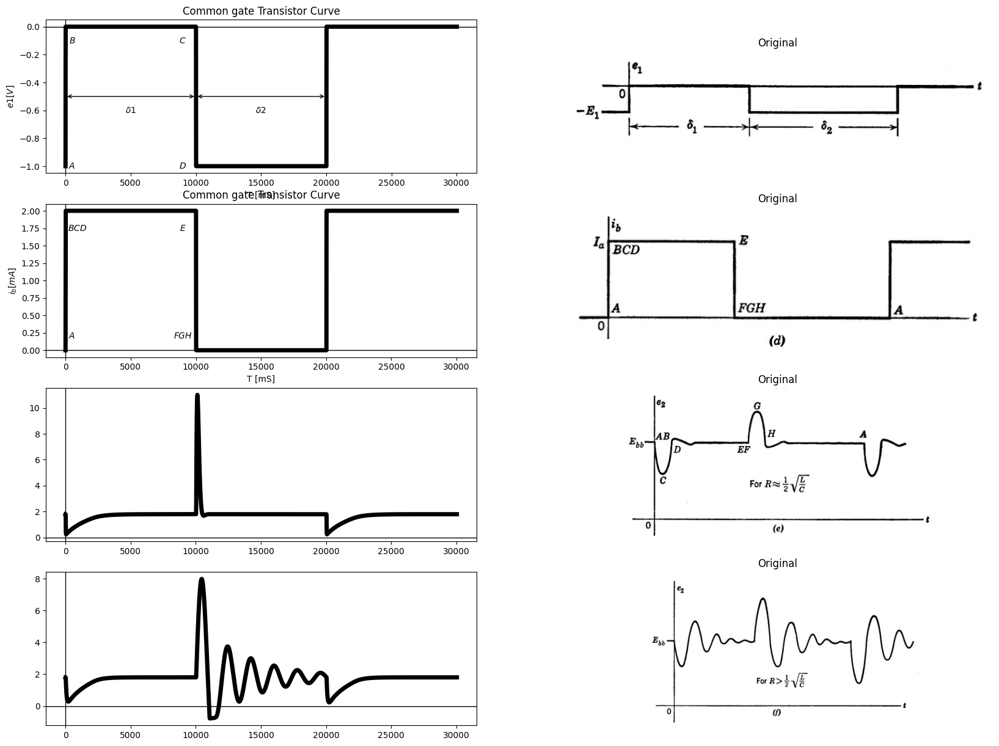

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=0@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[0,0].plot(analysis['e1'],'black',linewidth=5)
axs[0,0].set_title('Common gate Transistor Curve') 
axs[0,0].set_xlabel('T [mS]')
axs[0,0].set_ylabel('$e1 [V]$')
axs[0,0].text( 500, -1, '$A$', ha='center', va='center')
axs[0,0].text( 9000, -1, '$D$', ha='center', va='center')
axs[0,0].text( 500, -.1, '$B$', ha='center', va='center')
axs[0,0].text( 9000, -.1, '$C$', ha='center', va='center')
axs[0,0].text( 5000, -.6, '$δ1$', ha='center', va='center')
axs[0,0].text( 15000, -.6, '$δ2$', ha='center', va='center')
axs[0,0].annotate('', xy=(0., -.5), xytext=(10000, -.5), arrowprops=dict(arrowstyle='<->'))
axs[0,0].annotate('', xy=(10000., -.5), xytext=(20000, -.5), arrowprops=dict(arrowstyle='<->'))
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-44a.JPG')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$i_b [mA]$')
axs[1,0].text( 500, .2, '$A$', ha='center', va='center')
axs[1,0].text( 9000, .2, '$FGH$', ha='center', va='center')
axs[1,0].text( 900, 1.75, '$BCD$', ha='center', va='center')
axs[1,0].text( 9000, 1.75, '$E$', ha='center', va='center')
axs[1,0].text( 5000, -.6, '$δ1$', ha='center', va='center')
axs[1,0].text( 15000, -.6, '$δ2$', ha='center', va='center')
axs[1,0].annotate('', xy=(0., -.5), xytext=(10000, -.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(10000., -.5), xytext=(20000, -.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-44b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'e2', 'Ebb', 55@u_Ohm)
circuit.L(1, 'e2','Ebb', 8@u_mH)
circuit.C(1, 'e2','Ebb', 1@u_uF)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[2,0].plot(analysis['e2'],'black',linewidth=5)
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-44c.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'e2', 'Ebb', 185@u_Ohm)
circuit.L(1, 'e2','Ebb', 8@u_mH)
circuit.C(1, 'e2','Ebb', 10@u_uF)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[3,0].plot(analysis['e2'],'black',linewidth=5)
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/8-44d.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

**pentode With parallel RLC Load**

Text(0.5, 1.0, 'Original')

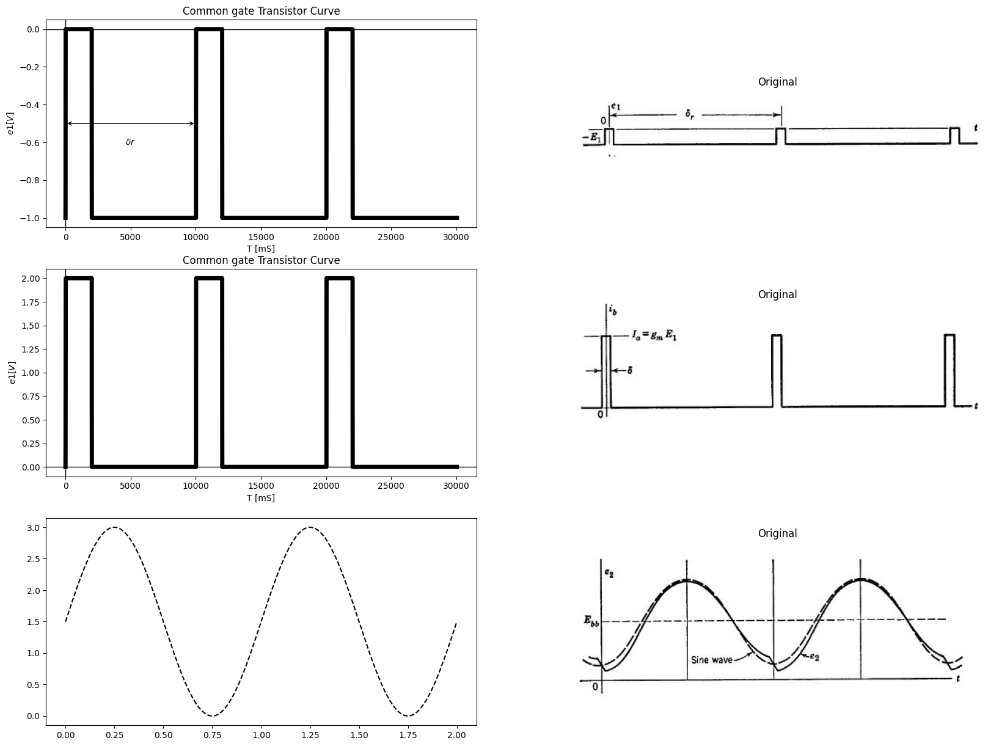

In [14]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=0@u_V, pulse_width=2@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[0,0].plot(analysis['e1'],'black',linewidth=5)
axs[0,0].set_title('Common gate Transistor Curve') 
axs[0,0].set_xlabel('T [mS]')
axs[0,0].set_ylabel('$e1 [V]$')
axs[0,0].text( 5000, -.6, '$δr$', ha='center', va='center')
axs[0,0].annotate('', xy=(0., -.5), xytext=(10000, -.5), arrowprops=dict(arrowstyle='<->'))
#axs[0,0].annotate('', xy=(10000., -.5), xytext=(20000, -.5), arrowprops=dict(arrowstyle='<->'))
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-44gjpg.JPG')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=2@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
axs[1,0].text( 5000, -.6, '$δ1$', ha='center', va='center')
axs[1,0].annotate('', xy=(0., -.5), xytext=(10000, -.5), arrowprops=dict(arrowstyle='<->'))
#axs[0,0].annotate('', xy=(10000., -.5), xytext=(20000, -.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-44h.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
frequency = 1 
amplitude = 3  
duration = 2   
sampling_rate = 1000  

# Generate time array
time = np.linspace(0, duration, sampling_rate * duration)


sine_wave_positive = amplitude * (np.sin(2 * np.pi * frequency * time) + 1) / 2

#axs[2,0].figure(figsize=(10, 6))
axs[2,0].plot(time, sine_wave_positive,linestyle='--',color='black')
#axs[2,0].xlabel("Time (s)")
#axs[2,0].ylabel('$e_2 (V)$')
img_sample = mpimg.imread('images/p8-44j.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

### fig 8-44 pulse response of pentode with RLC load for δr=2π/ω0=1⁄f0

3. Underdamped  $$v= \frac {\frac {Ia}{c} }{β}.{e}^{-αt}  sin⁡βt$$    $$(8.55)$$

where $α= \frac {1}{2RC}$

and $β=\sqrt{\frac {1}{LC}-(\frac{1}{2RC})^{2}}$

4. Undamped $$v=\frac {I_a}{C}.\sqrt{LC}sin\sqrt{\frac{1}{LC}t}$$ $$(8.56)$$

In the nearly-undamped case, the transient lasts a long time. An  important application of the $RLC$ load with relatively small damping  is the tuned, overdriven amplifier used both for power amplification and  
frequency multiplication. A simplified representation of the behavior  of a nonlinear power amplifier is shown in $Fig. 8.44.$ The rectangular  


wave has been replaced by brief pulses and the $LC$ circuit is tuned to a  frequency wo whose period is the same as the repetition interval of the  pulses. If the RLC circuit is nearly undamped, the waveform of $e2$ is 

Text(0.5, 1.0, 'Original')

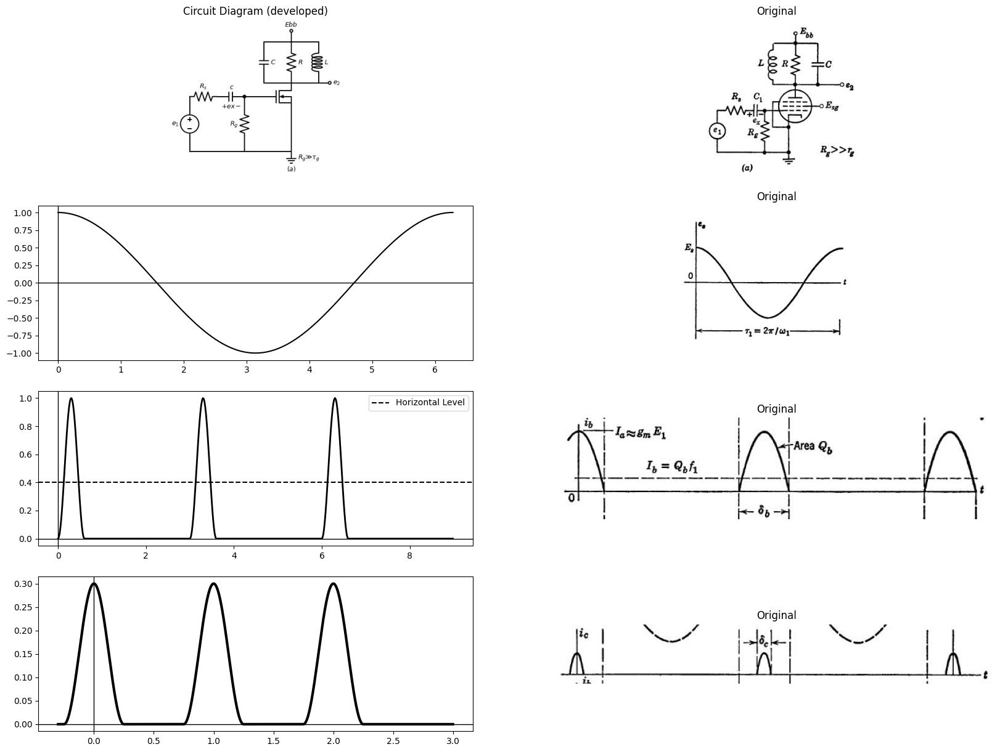

In [46]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
V1 = d.add(elm.SourceV().up(d.unit*1).label('$e_1$', 'top'))
d += (R1 := elm.Resistor(). right(d.unit*.5).label('$R_s$', 'top'))
d += (C1:=elm.Capacitor().right(d.unit*.5).color('black').label('$+  ex -$','bottom').label('$c$','top').dot())
d += (R2 := elm.Resistor(). down(d.unit*1).label('$R_g$', 'top'))
l1 = d.add(elm.Line().left(d.unit*1))
l2 = d.add(elm.Line().right(d.unit*.4).at(C1.end))
d += (M1 := elm.NFet(bulk = True).anchor('gate').theta(0).reverse())
l3 = d.add(elm.Line().down(d.unit*.75).at(M1.source))
l4 = d.add(elm.Line().left(d.unit*1))
l5 = d.add(elm.Line().down(d.unit*.75).at(M1.bulk))
G = d.add(elm.Ground().at(l3.end).label('$(a)$','bottom').label(r'$        R_g ≫ τ_g$','right'))
d += (R1 := elm.Resistor().up(d.unit*.75).label('$R$', 'bottom').at(M1.drain))
l6 = d.add(elm.Line().right(d.unit*.5).at(M1.drain))
l7 = d.add(elm.Line().left(d.unit*.5).at(M1.drain))
d += (L1:=elm.Inductor2().up(d.unit*.75).color('black').label('$L$','bottom').at(l6.end))
d += (C1:=elm.Capacitor().up(d.unit*.75).color('black').label('$C$','bottom').at(l7.end))
l9 = d.add(elm.Line().right(d.unit*1))
l10 = d.add(elm.Line().up(d.unit*.2).at(R1.end).dot(open=True).label('$Ebb$','right'))
l11 = d.add(elm.Line().right(d.unit*.2).dot(open=True).label('$e_2$','right').at(L1.start))
d.save('images/8-45-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-45-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-45a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
import numpy as np
import matplotlib.pyplot as plt

# Generate x values
x = np.linspace(0, 2 * np.pi, 1000)

# Generate the original sine wave
y_original = np.sin(x)

y_shifted = np.sin(x + np.pi/2)
axs[1,0].plot(x, y_shifted,color='black')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-45b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
# Define parameters for the waveform
amplitude = .5   # Amplitude of the waveform
frequency = 1.0   # Frequency of the waveform (cycles per unit time)
duty_cycle = 0.2  # Fraction of the period where the pulse is on
period = 3.0 / frequency  # Calculate the period
pulse_width = duty_cycle * period  # Calculate the pulse width
time = np.linspace(0, 3 * period, 500, endpoint=False)  # Time axis for three periods

# Create the pulse waveform
waveform = np.zeros_like(time)  # Initialize the waveform with zeros

for i, t in enumerate(time):
    # Determine where each pulse should be
    time_within_period = t % period
    if time_within_period < pulse_width:
        waveform[i] = amplitude * (1 - (np.cos(2 * np.pi * time_within_period / pulse_width)))

# Plotting the waveform
axs[2,0].plot(time, waveform, linewidth=2,color='black')  # Plot the waveform
#axs[2,0].ylim(-0.9, amplitude + 0.9)  # Set y-axis limits to include a bit of padding

axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
horizontal_level = 0.4
axs[2,0].axhline(y=horizontal_level, color='black', linestyle='--', label='Horizontal Level')
axs[2,0].legend()  # Show legend for the horizontal level
img_sample = mpimg.imread('images/8-45c.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
# Define parameters
T = 1.0  # Period of the waveform
pulse_width = 0.5  # Width of each pulse
amplitude = .3  # Amplitude of each pulse
sampling_rate = 1000  # Sampling rate for the waveform

# Time vector
t = np.linspace(-.3, 3 * T, 3 * sampling_rate, endpoint=False)

# Generate the waveform
waveform = np.zeros_like(t)
for i in range(3):
    center = i * T
    start = center - pulse_width / 2
    end = center + pulse_width / 2
    pulse = np.where((t >= start) & (t <= end), amplitude * (1 + np.cos(2 * np.pi * (t - center) / pulse_width)) / 2, 0)
    waveform += pulse

axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
axs[3,0].plot(t, waveform,color='black', linewidth=3)
img_sample = mpimg.imread('images/8-45b.JPG')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

### Fig. 8.45. Overdriven sine wave amplifier waveforms $(w1 = ω2= \frac {1}{\sqrt{LC}})$.  

nearly sinusoidal. The brief pulses add charge to the capacitor and  bring the amplitude above the sine wave value. Equilibrium amplitude  occurs when each pulse adds an amount of energy just equal to that 

dissipated in R per cycle. In particular, the voltage across the tuned  circuit $(Eb-es)$ is near its maximum Em and therefore nearly constant  during the plate-current pulse interval. Thus the energy delivered to  the tuned circuit per cycle is $E_mQ_b$, where Qt is the area of one platecurrent pulse. Energy dissipated per cycle is $(Em²/2R)τo$, where  

$τo=2π \sqrt{LC}=2π/ωo.$ Thus $E_mQ_b={E_m}^{2}τo/2R, or E_m=2RI-b$  $$(8.57)$$

where I_b=Qb/τo is the d-c plate current.  
The practical embodiment of these ideas is the tuned, overdriven  amplifier shown in Fig. 8.45. The large amplitude input waveform  tends to drive the grid positive with respect to cathode. If Rg is very  large, the input circuit is basically a clamper and develops a net charge  on C₁ corresponding very nearly to the amplitude of the input waveform.  Thus the positive peaks of the wave e(t) are clamped at zero.  plate-current pulses then produce the output waveform shown qualita- tively in Fig. 8.45. The peak amplitude Em cannot exceed Ebb, because the amplitude of the plate-current pulse decreases markedly if  minimum es falls below the knee of the pentode plate curves. 


With the parallel-resonant circuit tuned to a frequency $wo = nω1$,  where n is an integer, the overdriven amplifier becomes a so-called  ratio-n frequency multiplier. In this case, a current pulse is applied to  the resonating circuit only once every n cycles, so that the average plate  current is now $I_b = Qь/nτo.$  

## 8.33 Frequency Response of Parallel RLC Circuit  

If the input waveform for the circuit in Fig. 8.43 (a) is a sine wave that  varies the grid voltage between zero and E1, the pentode is essentially  linear and the plate current varies sinusoidally with an rms value I.  The admittance of the tuned circuit can be expressed as 

$Y=\frac{1}{R}-\frac {1}{jwL}+jwC=\frac{1}{R} {1+jQ[\frac {w}{w0}-\frac{w0}{w}]}$  $$(8.58)$$

Where the responant frequncy $w0=\frac{1}{LC}$ and the figure of merit* $Q=\frac{R}{\sqrt{\frac{L}{C}}}$

*Figure of merit or quality factor Q for a resonant circuit is defined as $$Q= 2π \frac {Peak stored energy}{Energy dissipated per cycle} $$

C:\Users\pc\AppData\Local\Temp\ipykernel_9296\846914521.py:50: RuntimeWarning: divide by zero encountered in divide
  normalized_impedance = 1 / np.sqrt(1 + (Q**2) * ((frequency_ratio**2 - 1)**2) / frequency_ratio**2)


Text(0.5, 1.0, 'Original')

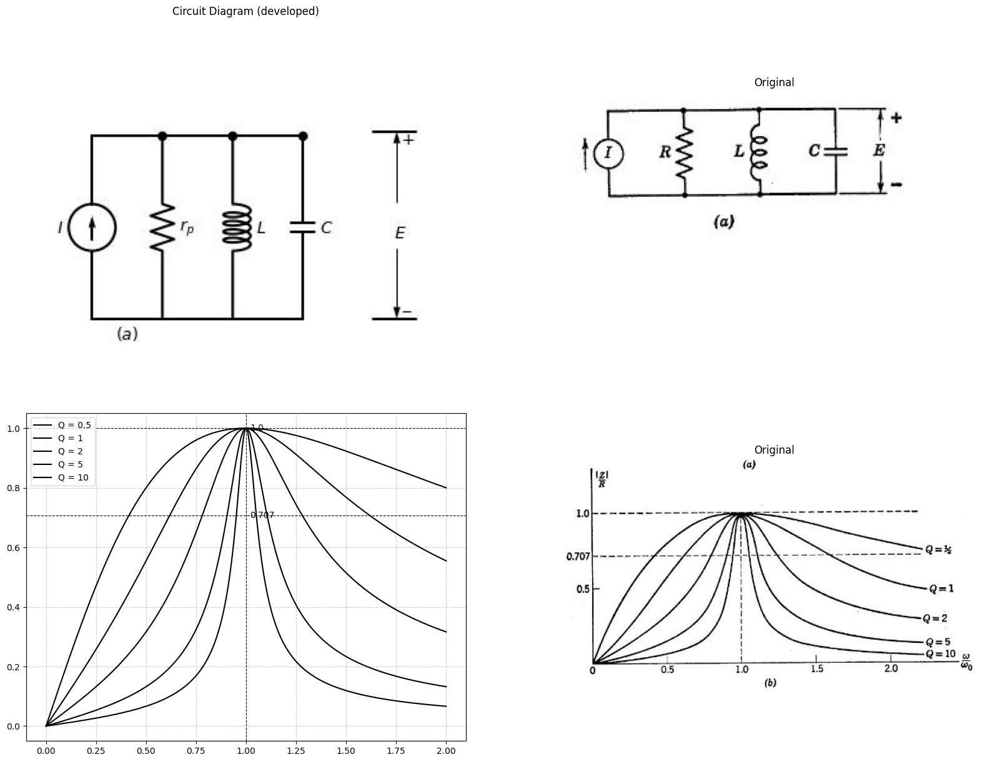

<Figure size 800x600 with 0 Axes>

In [8]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
I1 = d.add(elm.SourceI().up(d.unit*1.3).label('$I$', 'top'))
l6 = d.add(elm.Line().right(d.unit*.5).at(I1.end).dot())
d += (R1 := elm.Resistor(). down(d.unit*1.3).label('$r_p$', 'bottom'))
l7 = d.add(elm.Line().left(d.unit*.5).label('$(a)$', 'bottom'))
l8 = d.add(elm.Line().right(d.unit*.5).at(R1.start).dot())
d += (L1:=elm.Inductor2().down(d.unit*1.3).color('black').label('$L$','bottom').at(l8.end))
l11 = d.add(elm.Line().left(d.unit*.5))
l12 = d.add(elm.Line().right(d.unit*.5).at(L1.start).dot())
d += (C1:=elm.Capacitor().down(d.unit*1.3).color('black').label('$C$','bottom').at(l12.end))
l13 = d.add(elm.Line().left(d.unit*.5))
l14 = d.add(elm.Line().right(d.unit*.3).at((6,0)))
l15 = d.add(elm.Line().right(d.unit*.3).at((6,4)))
d += elm.Arrow().up().length(1.5).linewidth(1).color('black').label('+',loc='end', color='black',ofst=-0.1). at((6.5,2.5))
d += elm.Arrow().down().length(1.5).linewidth(1).color('black').label(r'_', loc='end', color='black',ofst=(-0.5, 0.1)). at((6.5,1.5))
d += elm.Arrow().up().length(4).linewidth(0.6).color('white').label('$E$', loc='start', color='black',ofst=0.3). at((7,2))
d.save('images/8-46j-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-46j-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/8-46a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
# Define the quality factors (Q) and frequency range
Q_values = [0.5, 1, 2, 5, 10]
frequency_ratio = np.linspace(0, 2, 500)

# Create the plot
plt.figure(figsize=(8, 6))

for Q in Q_values:
    # Calculate the normalized impedance |Z|/R
    normalized_impedance = 1 / np.sqrt(1 + (Q**2) * ((frequency_ratio**2 - 1)**2) / frequency_ratio**2)
    axs[1,0].plot(frequency_ratio, normalized_impedance, label=f'Q = {Q}', color='black')

# Add labels, legend, and grid
axs[1,0].axhline(1, color='black', linestyle='--', linewidth=0.8)
axs[1,0].axhline(0.707, color='black', linestyle='--', linewidth=0.8)
axs[1,0].axvline(1, color='black', linestyle='--', linewidth=0.8)
axs[1,0].text(1.02, 1, '1.0', verticalalignment='center')
axs[1,0].text(1.02, 0.707, '0.707', verticalalignment='center')
axs[1,0].legend()
axs[1,0].grid(True, linestyle='--', alpha=0.6)
img_sample = mpimg.imread('images/8-46jb.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

### Fig. 8.46. Frequency response of pentode with parallel RLC load.  

The impedance $(Z = E/I)$ is plotted as a function of w in Fig. 8.46(b)  for several values of Q. The RLC circuit is useful in frequency-selective  amplifiers, since the output voltage $E (w)$ has the same form as $Z(w)$  when the circuit is driven by a current source.  

SUPPLEMENTARY READING  
L. B. Arguimbau and R. B. Adler, Vacuum-Tube Circuits and Transistors, John  Wiley and Sons, Inc., New York, 1956.  
B. Chance, Waveforms, McGraw-Hill, New York, 1948.  
E. A. Guillemin, Introductory Circuit Theory, John Wiley and Sons, New York, 1953.  
L. P. Hunter, editor, Handbook of Semiconductor Electronics, McGraw-Hill, New  York, 1956.  
J. Millman and H. Taub, Pulse and Digital Circuits, McGraw-Hill, New York, 1956.  
J. F. Reintjes and G. T. Coate, Principles of Radar, 3rd edition, McGraw-Hill,  New York, 1952.  
Samuel Seely, Electron-Tube Circuits, McGraw-Hill, New York, 1950.  
G. E. Valley and H. Wallman, Vacuum Tube Amplifiers, McGraw-Hill, New York,  1948.  
V. K. Zworykin and G. A. Morton, Television: The Electronics of Image Trans- mission in Color and Monochrome, 2nd edition, John Wiley and Sons, New York  1954. 


PROBLEMS (See Appendices for device curves)  
8.1. Specify the waveform of Fig. 8.8(c) in terms of a combination of  continuous ramp functions.  


Text(0.5, 1.0, 'Original')

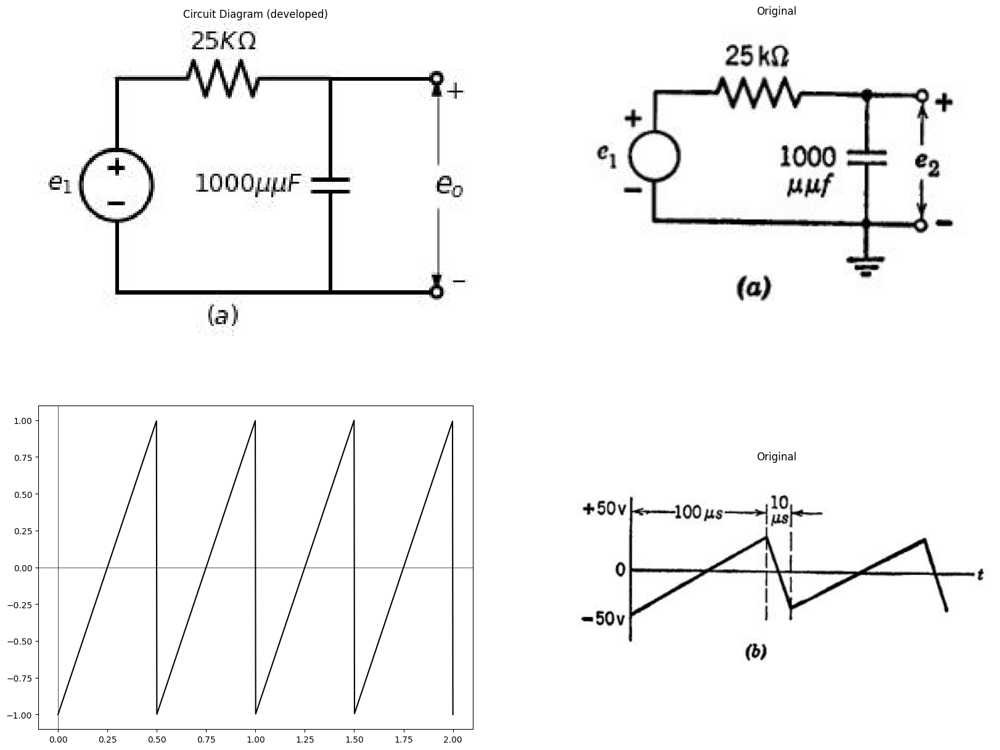

In [28]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
V1 = d.add(elm.SourceV().up(d.unit*1).label('$e_1$', 'top'))
d += (R1 := elm.Resistor(). right(d.unit*1).label('$25KΩ$', 'top'))
d += (C1:=elm.Capacitor().down(d.unit*1).color('black').label('$1000μμF$','top'))
l1 = d.add(elm.Line().left(d.unit*1).label('$(a)$', 'bottom'))
l2 = d.add(elm.Line().right(d.unit*.5).at(C1.start).dot(open=True))
l3 = d.add(elm.Line().right(d.unit*.5).at(C1.end).dot(open=True))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((4.5,1.8))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((4.5,1.2))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((3,0.2))
d.save('images/8-45-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/8-45-1.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-1a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

t = np.linspace(0, 2, 1000)  # 2 seconds duration

sawtooth_wave = signal.sawtooth(2 * np.pi * 2 * t)  # 2 Hz frequency
axs[1,0].plot(t, sawtooth_wave, color='black', linewidth=1.5)
axs[1,0].axhline(0, color='black', linewidth=0.5)
axs[1,0].axvline(0, color='black', linewidth=0.5)
img_sample = mpimg.imread('images/p8-1b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

8.2. For the circuit shown in Fig. P8.1(a), sketch and dimension the wave- form of voltage e1 required to produce the linear sawtooth voltage es shown  in Fig. P8.1(b).  

Text(0.5, 1.0, 'Original')

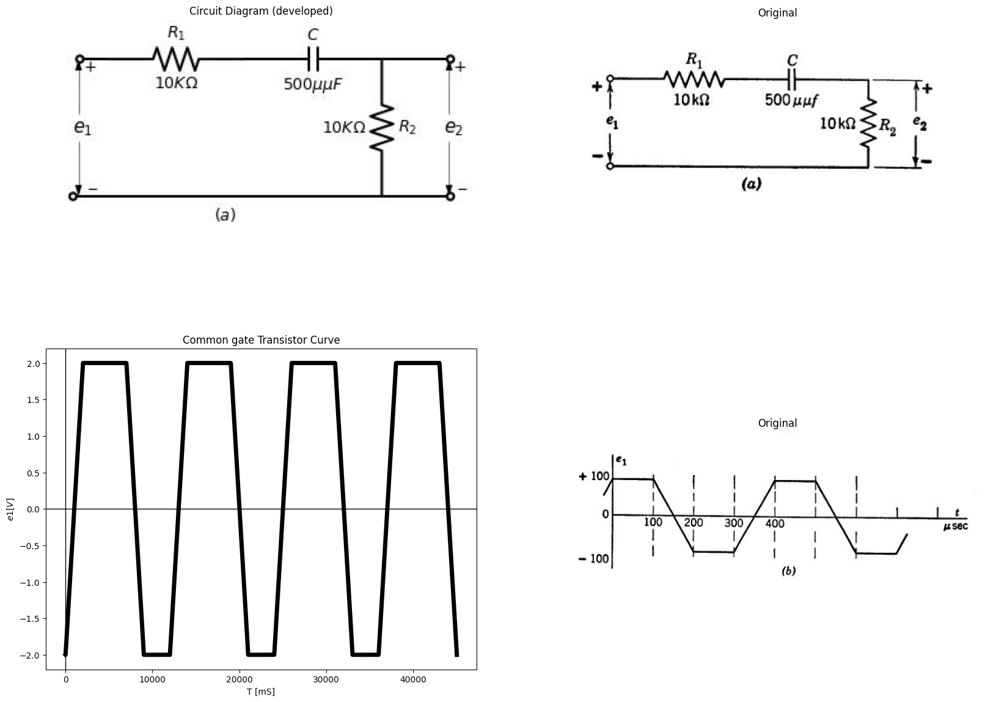

In [16]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
l1 = d.add(elm.Line().right(d.unit*.01).dot(open=True))
l2 = d.add(elm.Line().right(d.unit*.2))
d += (R1 := elm.Resistor(). right(d.unit*1).label('$10KΩ$', 'bottom').label('$R_1$', 'top'))
d += (C1:=elm.Capacitor().right(d.unit*1).color('black').label('$500μμF$','bottom').label('$C$', 'top'))
d += (R2 := elm.Resistor(). down(d.unit*1).label('$10KΩ$', 'top').label('$R_2$', 'bottom'))
l3 = d.add(elm.Line().left(d.unit*2.25).dot(open=True).label('$(a)$', 'bottom'))
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True).at(R2.start))
l5 = d.add(elm.Line().right(d.unit*.5).dot(open=True).at(R2.end))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((8.1,-1.2))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((8.1,-1.8))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6.5,-2.8))
d += elm.Arrow().up().length(1.2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((0,-1.2))
d += elm.Arrow().down().length(1.2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((0,-1.8))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-1.6,-2.8))
d.save('images/p8-2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-2.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-2a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=12@u_ms,rise_time=2@u_ms,fall_time=2@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=45@u_ms)
axs[1,0].plot(analysis['e1'],'black',linewidth=5)
axs[1,0].set_title('Common gate Transistor Curve') 
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$e1 [V]$')
#axs[1,0].annotate('', xy=(0., -.5), xytext=(10000, -.5), arrowprops=dict(arrowstyle='<->'))
#axs[0,0].annotate('', xy=(10000., -.5), xytext=(20000, -.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-4b.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

8.3. Sketch and dimension the waveform of output voltage e₂ from the  circuit of Fig. P8.2(a) for the input waveform shown in Fig. P8.2(b). Repeat  with $R_{1} = 0 $ 
8.4. The pulse transformer in the circuit of Fig. P8.3(a) has a magnetizing  inductance $L_{m} = 80 mh$ referred to the primary winding. Leakage inductances  and stray capacitances may be neglected. Determine the waveform of input  voltage e₁ which produces a single rectangular output pulse e2 $[Fig. P8.3(b)] $ having an amplitude of 20 volts and a duration of 2 microseconds.  
8.5. Sketch and dimension the output e₂(t) for the circuit of Fig. P8.4(a)  with input waveform e₁(t) as shown in Fig. P8.4(6). Let the triode be  piecewise-linear with $\mu = 20$ $r_{p} = 10 kilohms$, and $r_{g} = 1 kilohm.$ 


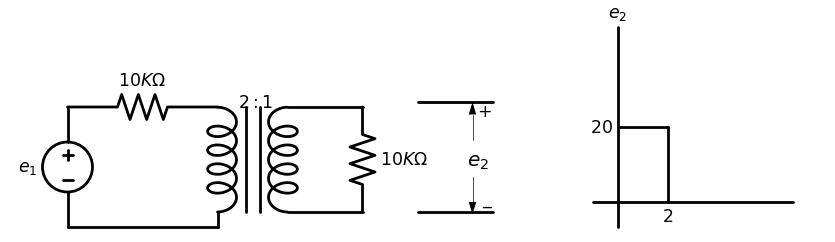

In [24]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    V1 = d.add(elm.SourceV().up(d.unit*1.2).label('$e_1$', 'top'))
    d += (R1 := elm.Resistor(). right(d.unit*1.5).label('$10KΩ$', 'top'))
    x = d.add(elm.Transformer(loop=True).at((3,.3)))
    l1 = d.add(elm.Line().right(d.unit*.75).at((4.4,0.3)))
    l2 = d.add(elm.Line().right(d.unit*.75).at((4.4,2.4)))
    d += (R1 := elm.Resistor(). down(d.unit*1.05).label('$10KΩ$', 'bottom').at(l2.end))
    l3 = d.add(elm.Line().right(d.unit*1.5).at(V1.start))
    l4 = d.add(elm.Line().up(d.unit*.15))
    l5 = d.add(elm.Line().right(d.unit*.75).at((7,0.3)))
    l6 = d.add(elm.Line().right(d.unit*.75).at((7,2.5)))
    d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((8.1,1.75))
    d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((8.1,1))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6.5,.5))
    l7 = d.add(elm.Line().right(d.unit*.15).at((3,2.5)).color('white').label('$2:1$', 'right',color='black'))
    l8 = d.add(elm.Line().right(d.unit*2).at((10.5,.5)))
    l9 = d.add(elm.Line().up(d.unit*2).at((11,0)).label('$e_2$', 'right'))
    l10 = d.add(elm.Line().right(d.unit*.5).at((11,2)).label('$20$', 'left'))
    l11 = d.add(elm.Line().down(d.unit*.75).label('$2$', 'left'))

![](images/p8-33.JPG)

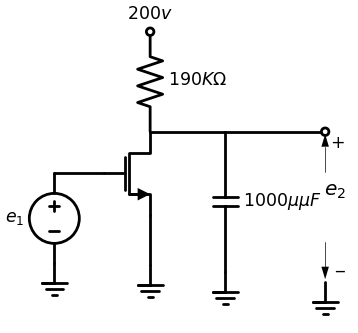

In [25]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (R1 := elm.Resistor(). up(d.unit*1).label('$190KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$200v$', 'right'))
    l1 = d.add(elm.Line().down(d.unit*.5).at(M1.source))
    G = d.add(elm.Ground().at(l1.end))
    l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
    V1 = d.add(elm.SourceV().down(d.unit*.9).label('$e_1$', 'top').at(l2.end).reverse())
    G = d.add(elm.Ground().at(V1.end))
    l3 = d.add(elm.Line().right(d.unit*.75).at(M1.drain))
    d += (C1:=elm.Capacitor().down(d.unit*1.4).color('black').label('$1000μμF$','bottom'))
    G = d.add(elm.Ground().at(C1.end))
    l4 = d.add(elm.Line().right(d.unit*1).at(C1.start).dot(open=True))
    G = d.add(elm.Ground().at((3.5,-3)))
    d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.5,-.8))
    d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.5,-2.2))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2,-2))

![](images/p8-4a.JPG)

Text(0.5, 1.0, 'Original')

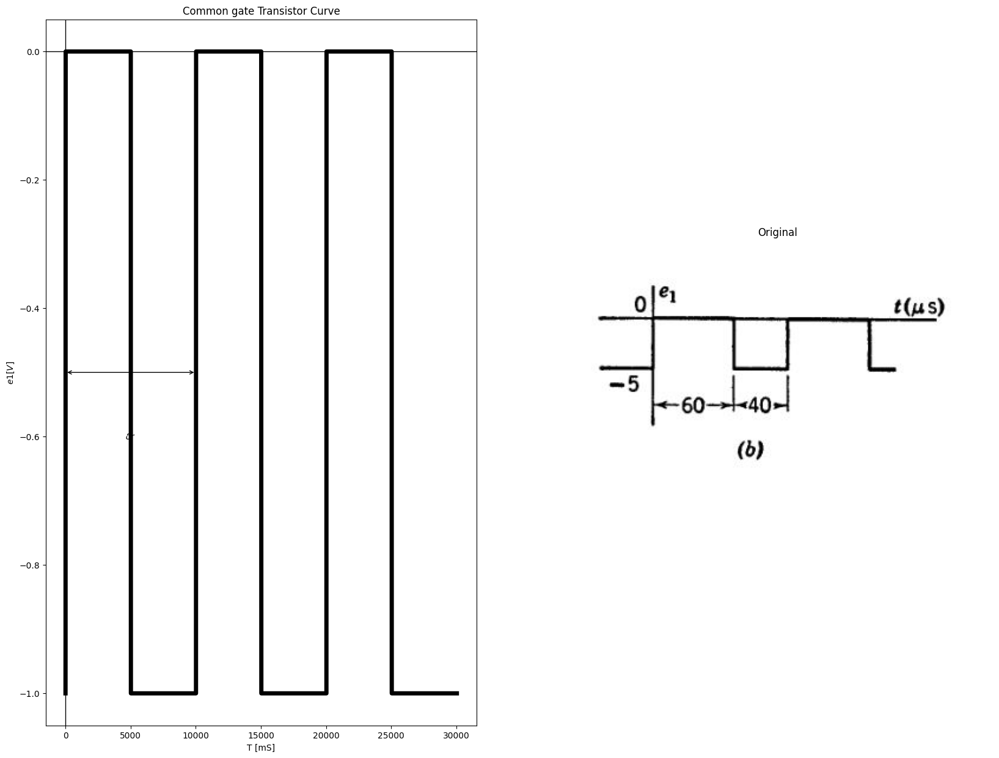

In [26]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-1@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'Ebb', 'e1', 'e2',circuit.gnd, model='2N7000')
circuit.R(1, 'e2', circuit.gnd, 100@u_Ohm)
circuit.L(1, 'e2',circuit.gnd, 1@u_H)
circuit.V(3, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[0].plot(analysis['e1'],'black',linewidth=5)
axs[0].set_title('Common gate Transistor Curve') 
axs[0].set_xlabel('T [mS]')
axs[0].set_ylabel('$e1 [V]$')
axs[0].text( 5000, -.6, '$δr$', ha='center', va='center')
axs[0].annotate('', xy=(0., -.5), xytext=(10000, -.5), arrowprops=dict(arrowstyle='<->'))
#axs[0,0].annotate('', xy=(10000., -.5), xytext=(20000, -.5), arrowprops=dict(arrowstyle='<->'))
axs[0].axhline(0, color='black', linewidth=1)
axs[0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-42b.JPG')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.6. In the circuit of Fig. P8.5 the capacitance C is so large that the ripple  in er is negligible. The input voltage $e{2}$ is an audio-frequency square wave  of amplitude E1. Use a piecewise-linear triode model with $r_{p} = 30 kilohms$,$r{g}=0 $  and $\mu = 50 $ 

Text(0.5, 1.0, 'Original')

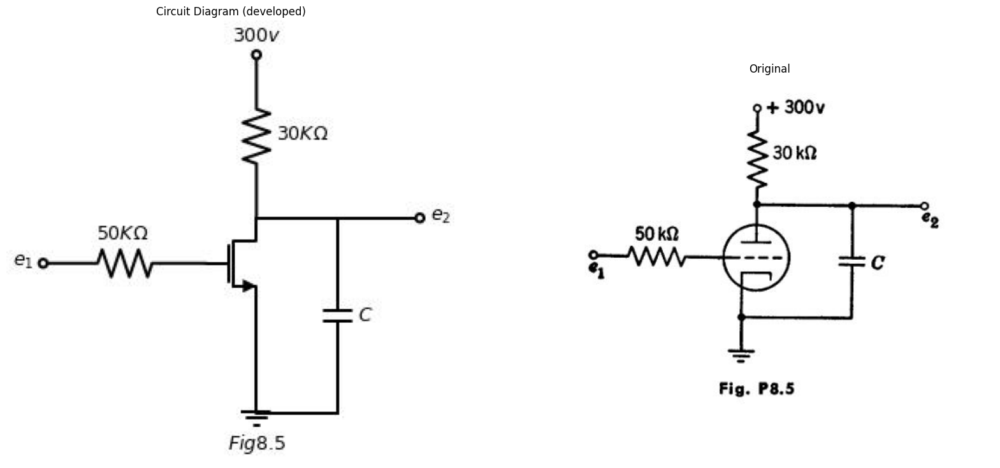

In [28]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$30KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$300v$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.5).at(M1.source))
G = d.add(elm.Ground().at(l1.end).label('$Fig8.5$', 'bottom'))
d += (R1 := elm.Resistor(). left(d.unit*1).label('$50KΩ$', 'top').at(M1.gate).dot(open=True).label('$e_1$', 'left'))
l2 = d.add(elm.Line().right(d.unit*.5).at(M1.drain))
d += (C1:=elm.Capacitor().down(d.unit*1.2).color('black').label('$C$','bottom'))
l3 = d.add(elm.Line().left(d.unit*.5))
l4 = d.add(elm.Line().right(d.unit*.5).dot(open=True).label('$e_2$', 'right').at(l2.end))

d.save('images/p8-5f.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-5f.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-5.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(a) Sketch and dimension the operating path of the tube on the piecewise- linear plate curves.  
(b) Plot the d-c output voltage E2 vs. E1.  
8.7. (a) What is the minimum value of E in Fig. P8.6(6) for which the  tube in Fig. P8.6(a) remains cut off during the interval 0 < t < 0.01 sec.?  
(b) With E equal to the value found in part (a), sketch and dimension the  output voltage waveform, indicating the values of time constants on expo- nentials.  


Text(0.5, 1.0, 'Original')

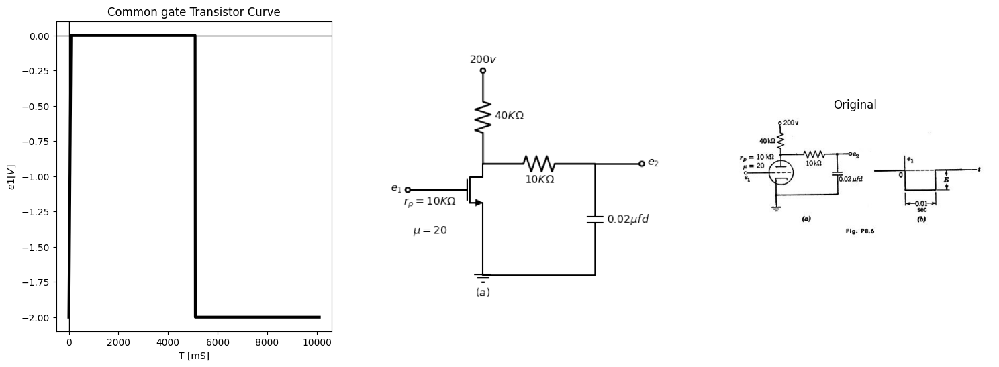

In [29]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1,3, figsize=(18, 6))
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=10@u_ms)

axs[0].plot(analysis['e1'],'black',linewidth=3)
axs[0].set_title('Common gate Transistor Curve') 
axs[0].set_xlabel('T [mS]')
axs[0].set_ylabel('$e1 [V]$')
axs[0].axhline(0, color='black', linewidth=1)
axs[0].axvline(0, color='black', linewidth=1)
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$40KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$200v$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.5).at(M1.source))
G = d.add(elm.Ground().at(l1.end).label('$(a)$', 'bottom'))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate).dot(open=True).label('$e_1$', 'left').label('$r_p=10KΩ$\n\n$μ=20$', 'bottom'))
d += (R1 := elm.Resistor(). right(d.unit*1.2).label('$10KΩ$', 'bottom').at(M1.drain))
d += (C1:=elm.Capacitor().down(d.unit*1.2).color('black').label('$0.02μfd$','bottom'))
l3 = d.add(elm.Line().left(d.unit*1.2))
l4 = d.add(elm.Line().right(d.unit*0.5).dot(open=True).label('$e_2$', 'right').at(C1.start))
d.save('./Drawings/p8-6.png')
d.save('./Drawings/p8-6.svg')

# Load the saved PNG file into the subplot
img = mpimg.imread('./Drawings/p8-6.png')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
img_sample = mpimg.imread('images/p8-6-.JPG')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')

8.8. In the circuit of Fig. P8.7, assume a piecewise-linear triode model  with plate resistance r, and cutoff for$ e{b} + μ
e{c}$ negative. The input voltage en  is zero until a negative step of magnitude E₁ is applied at time zero. 

Text(0.5, 1.0, 'Original')

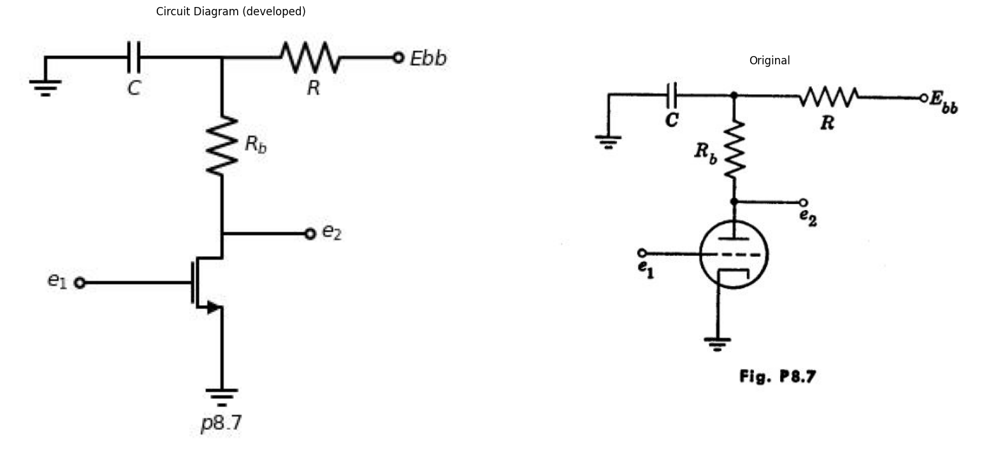

In [27]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$R_b$', 'bottom').at(M1.drain))
l1 = d.add(elm.Line().down(d.unit*.2).at(M1.source))
G = d.add(elm.Ground().at(l1.end).label('$p8.7$', 'bottom'))
l2 = d.add(elm.Line().right(d.unit*0.5).dot(open=True).label('$e_2$', 'right').at(M1.drain))
l3 = d.add(elm.Line().left(d.unit*0.5).dot(open=True).label('$e_1$', 'left').at(M1.gate))
d += (R2 := elm.Resistor().right(d.unit*1).label('$R$', 'bottom').dot(open=True).label('$Ebb$', 'right').at(R1.end))
d += (C1:=elm.Capacitor().left(d.unit*1).color('black').label('$C$','bottom').at(R1.end))
G = d.add(elm.Ground().at(C1.end))
d.save('images/p8-7a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-7a.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-7.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

Text(0.5, 1.0, 'Original')

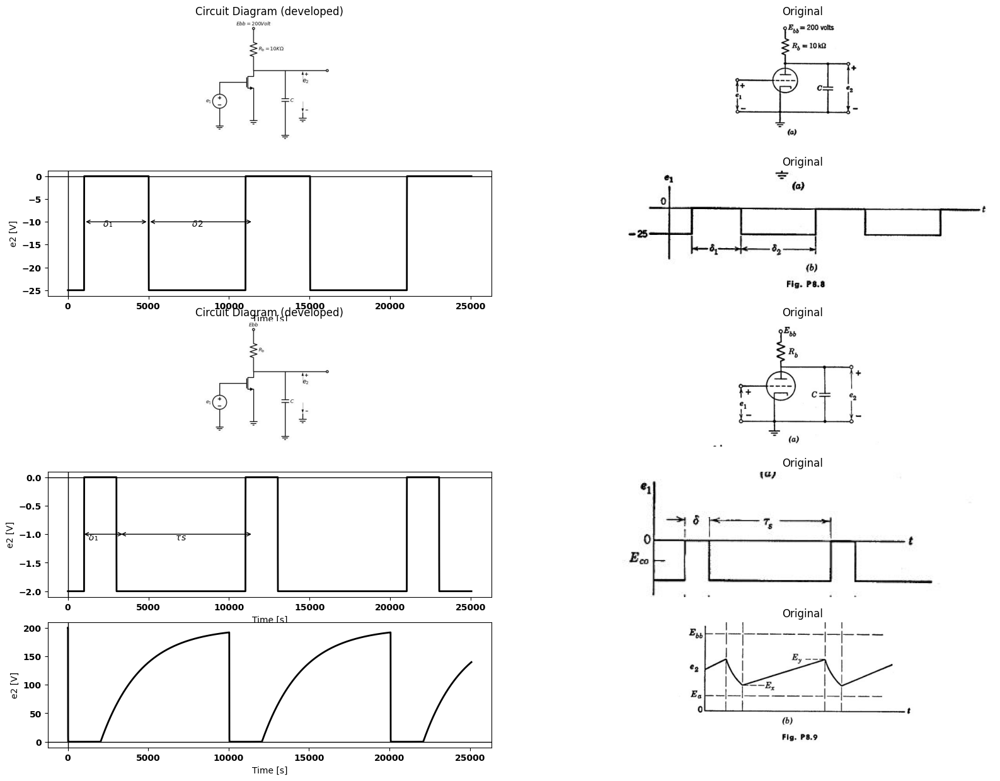

In [48]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$R_b=10KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb=200Volt$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.5).at(M1.source))
G = d.add(elm.Ground().at(l1.end))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*.9).label('$e_1$', 'top').at(l2.end).reverse())
G = d.add(elm.Ground().at(V1.end))
l3 = d.add(elm.Line().right(d.unit*.75).at(M1.drain))
d += (C1:=elm.Capacitor().down(d.unit*1.4).color('black').label('$C$','bottom'))
G = d.add(elm.Ground().at(C1.end))
l4 = d.add(elm.Line().right(d.unit*1).at(C1.start).dot(open=True))
G = d.add(elm.Ground().at((3.5,-3)))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.5,-.8))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.5,-2.2))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2,-2))
d.save('images/pa.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/pa.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-25@u_V, pulsed_value=0@u_V,delay_time=1@u_ms, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].text(2000,-11, ' $δ₁$ ', fontsize=10)
axs[1,0].text(7500,-11, ' $δ2$ ', fontsize=10)
axs[1,0].annotate('', xy=(5000, -10), xytext=(11500,-10), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(1000, -10), xytext=(5000,-10), arrowprops=dict(arrowstyle='<->'))
axs[1,0].set_ylabel('e2 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-8b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$R_b$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.5).at(M1.source))
G = d.add(elm.Ground().at(l1.end))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*.9).label('$e_1$', 'top').at(l2.end).reverse())
G = d.add(elm.Ground().at(V1.end))
l3 = d.add(elm.Line().right(d.unit*.75).at(M1.drain))
d += (C1:=elm.Capacitor().down(d.unit*1.4).color('black').label('$C$','bottom'))
G = d.add(elm.Ground().at(C1.end))
l4 = d.add(elm.Line().right(d.unit*1).at(C1.start).dot(open=True))
G = d.add(elm.Ground().at((3.5,-3)))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.5,-.8))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((3.5,-2.2))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2,-2))
d.save('images/pb.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/pb.jpg')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=0@u_V,delay_time=1@u_ms, pulse_width=2@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[3,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[3,0].set_xlabel('Time [s]')
axs[3,0].text(1100,-1.1, ' $δ₁$ ', fontsize=10)
axs[3,0].text(6500,-1.1, ' $ τs$ ', fontsize=10)
axs[3,0].annotate('', xy=(3200, -1), xytext=(11500,-1), arrowprops=dict(arrowstyle='<->'))
axs[3,0].annotate('', xy=(900, -1), xytext=(3500,-1), arrowprops=dict(arrowstyle='<->'))
axs[3,0].set_ylabel('e2 [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-9b.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', 'e1', circuit.gnd, initial_value=0@u_V, pulsed_value=2@u_V, pulse_width=2@u_ms, period=10@u_ms)
circuit.R(1, 'e2', 'Ebb', 250@u_kOhm)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'e2', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'e2',circuit.gnd,.01@u_uF )
circuit.V(1, 'Ebb', circuit.gnd, 200@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[4,0].plot(analysis['e2'],'black',linestyle='-',linewidth=2) 
axs[4,0].set_xlabel('Time [s]')
axs[4,0].set_ylabel('e2 [V]')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/d.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')


Text(0.5, 1.0, 'Original')

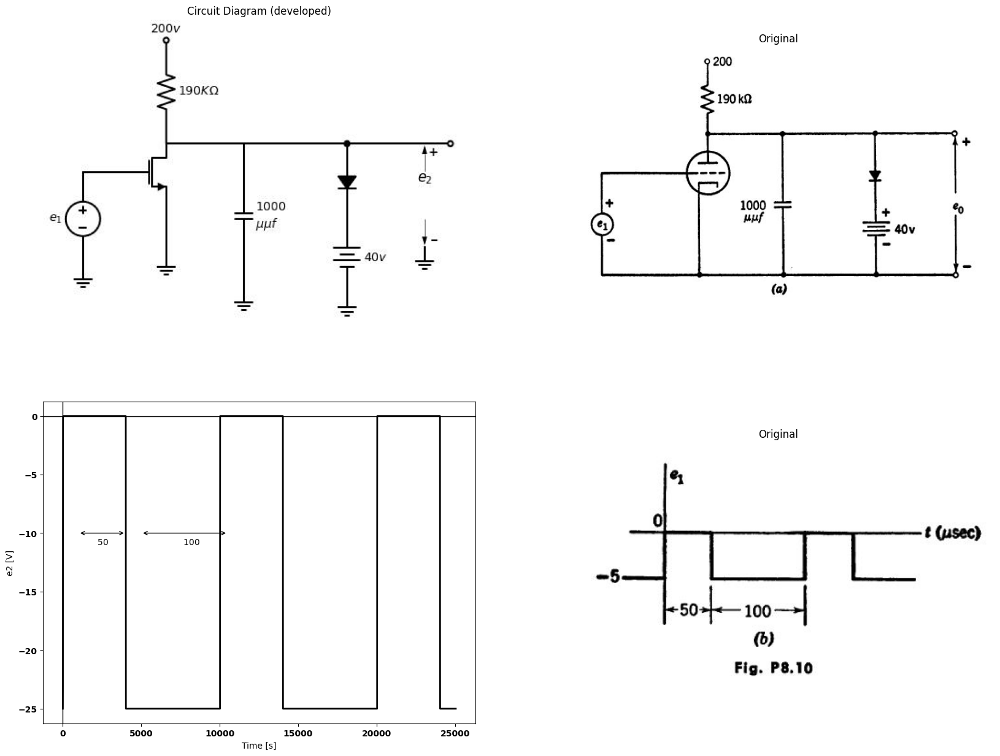

In [60]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$190 KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$200v$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.5).at(M1.source))
G = d.add(elm.Ground().at(l1.end))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*.9).label('$e_1$', 'top').at(l2.end).reverse())
G = d.add(elm.Ground().at(V1.end))
l3 = d.add(elm.Line().right(d.unit*.75).at(M1.drain))
d += (C1:=elm.Capacitor().down(d.unit*1.4).color('black').label('$1000$\n$μμf$','bottom'))
G = d.add(elm.Ground().at(C1.end))
l4 = d.add(elm.Line().right(d.unit*1).at(C1.start).dot())
D1 = d.add(elm.Diode(fill=True).down(d.unit*.75))
V2 = d.add(elm.Battery().down(d.unit*.7).label('$40v$', 'bottom').at(D1.end))
G = d.add(elm.Ground().at(V2.end))
l5 = d.add(elm.Line().right(d.unit*1).at(D1.start).dot(open=True))
G = d.add(elm.Ground().at((7.5,-3)))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((7.5,-.8))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((7.5,-2.2))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5.8,-2.3))
d.save('images/pb2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/pb2.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/a1.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-25@u_V, pulsed_value=0@u_V, pulse_width=4@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].text(2000,-11, ' $50$ ', fontsize=10)
axs[1,0].text(7500,-11, ' $100$ ', fontsize=10)
axs[1,0].annotate('', xy=(5000, -10), xytext=(10500,-10), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(1000, -10), xytext=(4000,-10), arrowprops=dict(arrowstyle='<->'))
axs[1,0].set_ylabel('e2 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/r.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

by a piecewise-linear model with $\mu = 20$ ,$r_{p} = 10 $kilohms, $r_{o} = 1 $kilohm.  Make simplifying approximations but check validity or indicate the  limitations they impose on the accuracy of the solution.  
8.13. The 10 microsecond input pulse for the circuit of Fig. P8.12 has a  repetition frequency of $5 kc$. Sketch and dimension the waveform of output  voltage $e{2}$.  
8.14. The triodes in the circuit of Fig. P8.13(a) can be approximated by a  piecewise-linear model with $\mu = 25$, $r_{p} = 20 $kilohms, and $r_{o} = 1$ kilohm.  The input waveform is as shown in Fig. P8.13(b). In terms of the circuit and  triode parameters, what is the maximum ratio $ δ1⁄δ2$ that permits complete  charging of capacitor C (5 time constants) during $δ2$ while maintaining  

$e{с2}$ < $- Eb/µ $during$ δ1$?  
8.15. Referring to the circuit and input waveform in Fig. P8.13, express  the positive overshoot on $e{c2}$ in terms of circuit parameters.  
8.16. Referring to Problem 8.14, let δ1 = 40 µsec, δ2 = 60 µsec, $R{b1} = 20$  kilohms, $R_{g} = 200$ kilohms and C = 1000 µµf Sketch and dimension the  waveforms $e{b1}(t)$, $ex(t)$ and$ ec2(t)$.  
8.17. For the conditions of Problem 8.16, sketch the locus of the triode  operating point (is vs. es). 


Text(0.5, 1.0, 'Original')

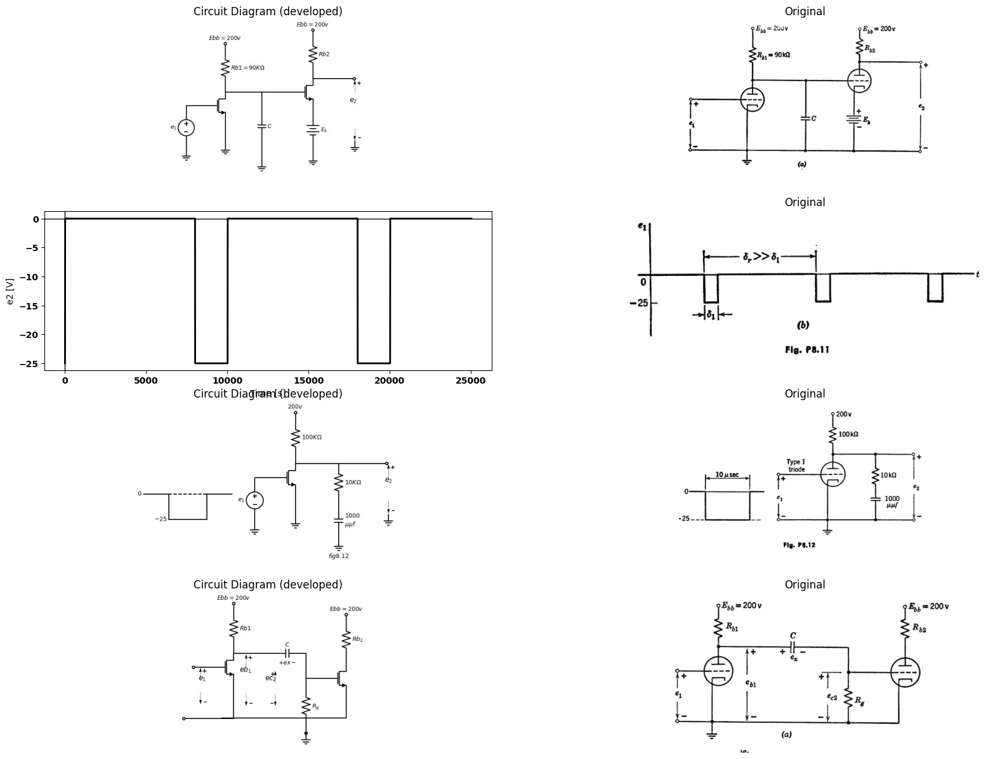

In [81]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$Rb1=90 KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb=200v$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.5).at(M1.source))
G = d.add(elm.Ground().at(l1.end))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*.9).label('$e_1$', 'top').at(l2.end).reverse())
G = d.add(elm.Ground().at(V1.end))
l3 = d.add(elm.Line().right(d.unit*.75).at(M1.drain))
d += (C1:=elm.Capacitor().down(d.unit*1.4).color('black').label('$C$','bottom'))
G = d.add(elm.Ground().at(C1.end))
l4= d.add(elm.Line().right(d.unit*.75).at(C1.start))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse().at(l4.end))
V2 = d.add(elm.Battery().down(d.unit*1).label('$E_k$', 'bottom').at(M2.source))
G = d.add(elm.Ground().at(V2.end))
d += (R2 := elm.Resistor(). up(d.unit*1).label('$Rb2$', 'bottom').at(M2.drain).dot(open=True).label('$Ebb=200v$', 'right'))
l5= d.add(elm.Line().right(d.unit*.85).at(M2.drain).dot(open=True))
G = d.add(elm.Ground().at((8,-3)))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((8,-0))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((8,-2.2))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6.2,-1.8))
d.save('images/p8-11aa.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-11aa.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-11.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-25@u_V, pulsed_value=0@u_V, pulse_width=8@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
#axs[1,0].text(2000,-11, ' $50$ ', fontsize=10)
#axs[1,0].text(7500,-11, ' $100$ ', fontsize=10)
#axs[1,0].annotate('', xy=(5000, -10), xytext=(10500,-10), arrowprops=dict(arrowstyle='<->'))
#axs[1,0].annotate('', xy=(1000, -10), xytext=(4000,-10), arrowprops=dict(arrowstyle='<->'))
axs[1,0].set_ylabel('e2 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-11b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$100 KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$200v$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.5).at(M1.source))
G = d.add(elm.Ground().at(l1.end))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*.9).label('$e_1$', 'top').at(l2.end).reverse())
G = d.add(elm.Ground().at(V1.end))
l3 = d.add(elm.Line().right(d.unit*.85).at(M1.drain))
d += (R2 := elm.Resistor(). down(d.unit*.75).label('$10KΩ$', 'bottom').at(l3.end))
d += (C1:=elm.Capacitor().down(d.unit*0.75).color('black').label('$1000$\n$μμf$','bottom'))
G = d.add(elm.Ground().at(C1.end).label('$fig8.12$', 'bottom'))
l4 = d.add(elm.Line().right(d.unit*.95).at(R2.start).dot(open=True))
G = d.add(elm.Ground().at((5.5,-3)))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.5,-.8))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((5.5,-2.2))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((3.8,-2.3))
l5 = d.add(elm.Line().right(d.unit*.5).at((-9,-1.8)).label('$0$', 'left'))
l6 = d.add(elm.Line().down(d.unit*.5))
l7 = d.add(elm.Line().right(d.unit*.75).label('$-25$', 'left'))
l8 = d.add(elm.Line().up(d.unit*.5))
l9 = d.add(elm.Line().right(d.unit*.5))
l10 = d.add(elm.Line().right(d.unit*1.5).at((-9,-1.8)).linestyle('--'))
d.save('images/p8-12aa.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-12aa.jpg')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-12.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$Rb1$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb=200v$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.75).at(M1.source))
l2 = d.add(elm.Line().left(d.unit*1).dot(open=True))
l3 = d.add(elm.Line().left(d.unit*.5).dot(open=True).at(M1.gate))
l4 = d.add(elm.Line().right(d.unit*.7).at(M1.drain))
d += (C1:=elm.Capacitor().right(d.unit*0.75).color('black').label('$C$','top').label('$+  ex -$','bottom'))
l5 = d.add(elm.Line().down(d.unit*.5))
d += (R2 := elm.Resistor(). down(d.unit*1.1).label('$R_g$', 'bottom').dot())
l6 = d.add(elm.Line().right(d.unit*.5).at(l5.end))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse().at(l6.end))
l7 = d.add(elm.Line().down(d.unit*.52).at(M2.source))
l8 = d.add(elm.Line().left(d.unit*2.5).at(l7.end))
G = d.add(elm.Ground().at(R2.end))
d += (R3 := elm.Resistor(). up(d.unit*1).label('$Rb_2$', 'bottom').at(M2.drain).dot(open=True).label('$Ebb=200v$', 'right'))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((-2,-1.6))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((-2,-2.3))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-3.6,-2.8))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((.75,-.8))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((.75,-2.4))
d += elm.Gap().up().label(  '$eb_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-1,-2.2))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=.3). at((2.5,-1.8))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, -.3)). at((2.5,-2.4))
d += elm.Gap().up().label(  '$ec_2$' , ofst=-1.7 , fontsize = 16).color('black').at((.5,-2.8))
d.save('images/p8-13aa.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-13aa.jpg')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-13.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

Text(0.5, 1.0, 'Original')

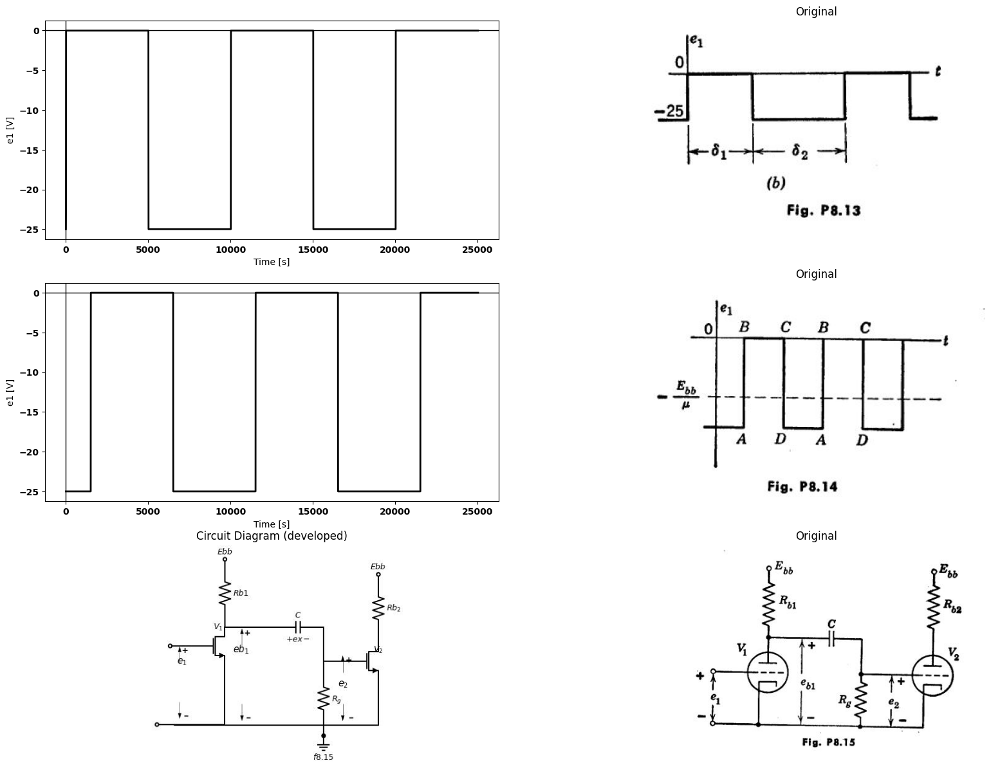

In [106]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-25@u_V, pulsed_value=0@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[0,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[0,0].set_xlabel('Time [s]')
axs[0,0].set_ylabel('e1 [V]')
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-13a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-25@u_V, pulsed_value=0@u_V,delay_time=1.5@u_ms, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-14.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$Rb1$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
l1 = d.add(elm.Line().down(d.unit*.88).at(M1.source))
l2 = d.add(elm.Line().left(d.unit*1).dot(open=True))
l3 = d.add(elm.Line().left(d.unit*.5).dot(open=True).at(M1.gate))
l4 = d.add(elm.Line().right(d.unit*.7).at(M1.drain).label('$V_1$','left'))
d += (C1:=elm.Capacitor().right(d.unit*0.75).color('black').label('$C$','top').label('$+  ex -$','bottom'))
l5 = d.add(elm.Line().down(d.unit*.5))
d += (R2 := elm.Resistor(). down(d.unit*1.1).label('$R_g$', 'bottom').dot())
l6 = d.add(elm.Line().right(d.unit*.5).at(l5.end))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse().at(l6.end))
l7 = d.add(elm.Line().down(d.unit*.67).at(M2.source))
l8 = d.add(elm.Line().left(d.unit*3).at(l7.end))
G = d.add(elm.Ground().at(R2.end).label('$f8.15$','bottom'))
d += (R3 := elm.Resistor(). up(d.unit*1).label('$Rb_2$', 'bottom').at(M2.drain).dot(open=True).label('$Ebb$', 'right').label('$V_2$','left'))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((-2,-1.6))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((-2,-3.3))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-3.6,-2.8))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((.75,-.8))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .2)). at((.75,-3.4))
d += elm.Gap().up().label(  '$eb_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-1,-2.2))
d += elm.Arrow().up().length(.75).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.2,-2))
d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.2,-3.4))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((3.5,-3.8))
d.save('images/p8-15a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-15a.jpg')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-15`a.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

8.18. The four-segment path in Fig. P8.16 is the locus of the operating  point of triode V₁ in the is vs. eb plane when the periodic waveform e₁ (t) shown  in Fig. P8.14 is applied between the grid and cathode. The intervals BC and  DA are both long compared with the time constants of the circuit of Fig. P8.15.  

Text(0.5, 1.0, 'Original')

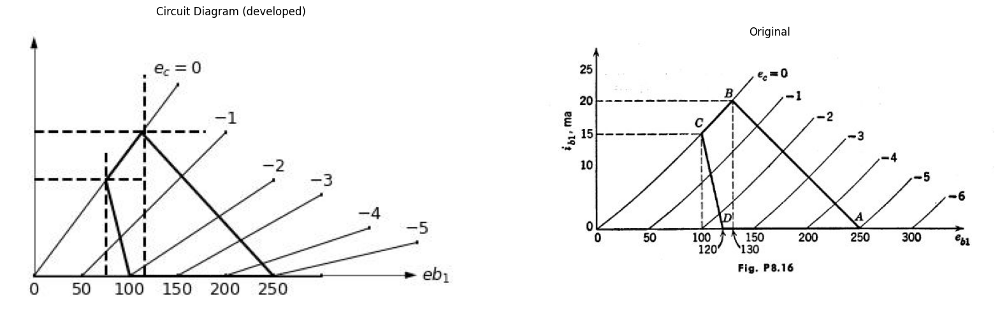

In [111]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += elm.Arrow().up().length(5).linewidth(0.6).color('black'). at((0,0))
d += elm.Arrow().right().length(8).linewidth(0.6).color('black'). at((0,0)).label('$eb_1$', 'right')
l1 = d.add(elm.Line().down(d.unit*.005).at((3,4)).label('$e_c=0$', 'right'))
l2 = d.add(elm.Line().down(d.unit*.005).at((4,3)).label('$-1$', 'right'))
l3 = d.add(elm.Line().down(d.unit*.005).at((5,2)).label('$-2$', 'right'))
l4 = d.add(elm.Line().down(d.unit*.005).at((6,1.7)).label('$-3$', 'right'))
l5 = d.add(elm.Line().down(d.unit*.005).at((7,1)).label('$-4$', 'right'))
l6 = d.add(elm.Line().down(d.unit*.005).at((8,.7)).label('$-5$', 'right'))
l7 = d.add(elm.Line().down(d.unit*.005).at((0,0)).label('$0$', 'left'))
l8 = d.add(elm.Line().down(d.unit*.005).at((1,0)).label('$50$', 'left'))
l9 = d.add(elm.Line().down(d.unit*.005).at((2,0)).label('$100$', 'left'))
l10 = d.add(elm.Line().down(d.unit*.005).at((3,0)).label('$150$', 'left'))
l11 = d.add(elm.Line().down(d.unit*.005).at((4,0)).label('$200$', 'left'))
l12 = d.add(elm.Line().down(d.unit*.005).at((5,0)).label('$250$', 'left'))
l13 = d.add(elm.Line().down(d.unit*.005).at((6,0)))
l14 = d.add(elm.Line().down(d.unit*.005).at((2.25,3)))
l15 = d.add(elm.Line().down(d.unit*.005).endpoints(l1.end,l7.end).linewidth(1))
l16 = d.add(elm.Line().down(d.unit*.005).endpoints(l2.end,l8.end).linewidth(1))
l17 = d.add(elm.Line().down(d.unit*.005).endpoints(l3.end,l9.end).linewidth(1))
l18 = d.add(elm.Line().down(d.unit*.005).endpoints(l4.end,l10.end).linewidth(1))
l19 = d.add(elm.Line().down(d.unit*.005).endpoints(l5.end,l11.end).linewidth(1))
l20 = d.add(elm.Line().down(d.unit*.005).endpoints(l6.end,l12.end).linewidth(1))
l21 = d.add(elm.Line().down(d.unit*.005).endpoints(l7.end,l13.end).linewidth(1))
l22 = d.add(elm.Line().down(d.unit*.005).at((1.5,2)))
l211 = d.add(elm.Line().down(d.unit*.005).endpoints(l14.end,l22.end).linewidth(2))
l211 = d.add(elm.Line().down(d.unit*.005).endpoints(l9.end,l22.end).linewidth(2))
l211 = d.add(elm.Line().down(d.unit*.005).endpoints(l9.end,l12.end).linewidth(2))
l211 = d.add(elm.Line().down(d.unit*.005).endpoints(l12.end,l14.end).linewidth(2))
l133 = d.add(elm.Line().right(d.unit*.75).at((0,2)).linestyle('--'))
l133 = d.add(elm.Line().right(d.unit*1.2).at((0,3)).linestyle('--'))
l133 = d.add(elm.Line().up(d.unit*.85).at((1.5,0)).linestyle('--'))
l133 = d.add(elm.Line().up(d.unit*1.4).at((2.3,0)).linestyle('--'))
d.save('images/p8-16ba.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-16ba.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/zz.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(a) What is the value of $R{b}$ in ohms?  
(b) What is the value of $R{g}$ in ohms?  
(c) During which segment of the locus is capacitor C charging?  
(d) By what voltage does the voltage on capacitor C change during locus  segment CD?  
(e) What is the resistance in ohms which determines the charging time  constant?  


Text(0.5, 1.0, 'Original')

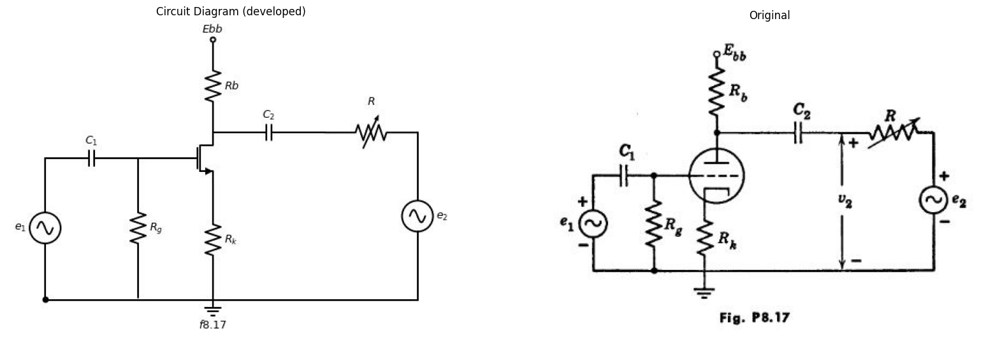

In [115]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor(). up(d.unit*1).label('$Rb$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
d += (R2 := elm.Resistor().down(d.unit*1.2).label('$R_k$', 'bottom').at(M1.source))
l1 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
d += (R3 := elm.Resistor().down(d.unit*1.5).label('$R_g$', 'bottom').at(l1.end))
d += (C1:=elm.Capacitor().left(d.unit*1).color('black').label('$C_1$','top').at(R3.start))
V1 = d.add(elm.SourceSin().down(d.unit*1.5).label('$e_1$', 'top').at(C1.end).reverse())
d += (C2:=elm.Capacitor().right(d.unit*1.2).color('black').label('$C_2$','top').at(M1.drain))
d += (R4 := elm.ResistorVarIEEE().right(d.unit*1).label('$R$', 'top').at(C2.end))
V2 = d.add(elm.SourceSin().down(d.unit*1.8).label('$e_2$', 'bottom').at(R4.end).reverse())
l2 = d.add(elm.Line().left(d.unit*4).dot())
G = d.add(elm.Ground().at(R2.end).label('$f8.17$','bottom'))
d.save('images/p8-16bb.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-16bb.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-17.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.19. With the a-c sources e₁ and es both set equal to zero, the triode circuit  shown in Fig. P8.17 operates at certain d-e values of es and is. Show how  you would find these d-c values  
(a) From the approximate piecewise-linear triode model, and  
(b) By graphical construction on the $Type III$ triode curves. Let $r{p}$ and $\mu$  be the constants of the linear incremental triode model valid in the neighbor- hood of the d-c operating point. 


c) With e₁ a small fixed-amplitude a-c signal and with e2 set equal to zero,  suppose that R is adjusted to make v₂ (as measured by an a-c voltmeter) take  exactly half of its open-circuit (infinite-R) value. Find this value of R in  terms of u, rp, Rs, and Re. Assume that the frequency of ex(t) is high enough  to give negligible ripple voltage across C₁ and C2, but not so high as to make  tube and stray wiring capacitances important.  
(d) With e1 set equal to zero and with ez a small fixed-amplitude a-c signal  at the same frequency as in part (c), suppose that R is adjusted to make v₂  take exactly half of its short-circuit (zero-R) value. Find this value of R in  terms of u, rp, Rb, and Rk.  
(e) How are the values of R found in (c) and  incremental output resistance of the amplifier?  
(d) related to the so-called  
(f) Repeat with the left-hand terminal of capacitor C₂ connected to the  cathode instead of the plate


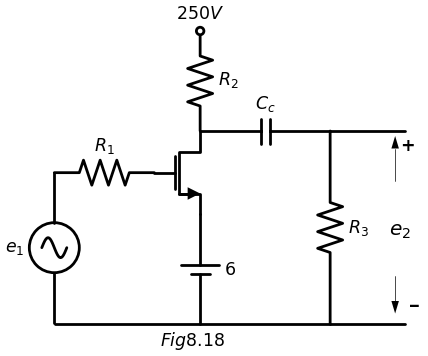

In [121]:
import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
import matplotlib.pyplot as plt
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (R1 := elm.Resistor(). up(d.unit*1).label('$R_2$', 'bottom').at(M1.drain).dot(open=True).label('$250V$', 'right'))
    V1 = d.add(elm.BatteryCell().down(d.unit*1.1).label('$6$', 'bottom').at(M1.source))
    d += (R2 := elm.Resistor(). left(d.unit*1).label('$R_1$', 'top').at(M1.gate))
    V1 = d.add(elm.SourceSin().down(d.unit*1.5).label('$e_1$', 'top').at(R2.end).reverse())
    d += (C1:=elm.Capacitor().right(d.unit*1.3).color('black').label('$C_c$','top').at(M1.drain))
    d += (R3 := elm.Resistor(). down(d.unit*1.93).label('$R_3$', 'bottom').at(C1.end))
    l1 = d.add(elm.Line().left(d.unit*2.75).at(R3.end).label('$Fig8.18$', 'bottom'))
    l2 = d.add(elm.Line().right(d.unit*.75).at(R3.end))
    l3 = d.add(elm.Line().right(d.unit*.75).at(R3.start))
    d += elm.Arrow().up().length(.9).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.9,-1))
    d += elm.Arrow().down().length(.75).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((3.9,-2.9))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.3,-2.8))

![](images/p8-18`a.JPG)

8.20. In Fig. P8.18 assume that the grid-cathode capacitance including  wiring is 12 µµf. The grid-plate capacitance including wiring is 8 μμf. Neglect  the plate-cathode capacitance.  
(a) Using the Type I triode plate characteristics, find $\mu$, gm, and $r{p}$ at the  quiescent operating point for R2 = 20 kn.  
(b) Calculate the effective grid-to-ground capacitance assuming R₁ and R3 large. 


Text(0.5, 1.0, 'Original')

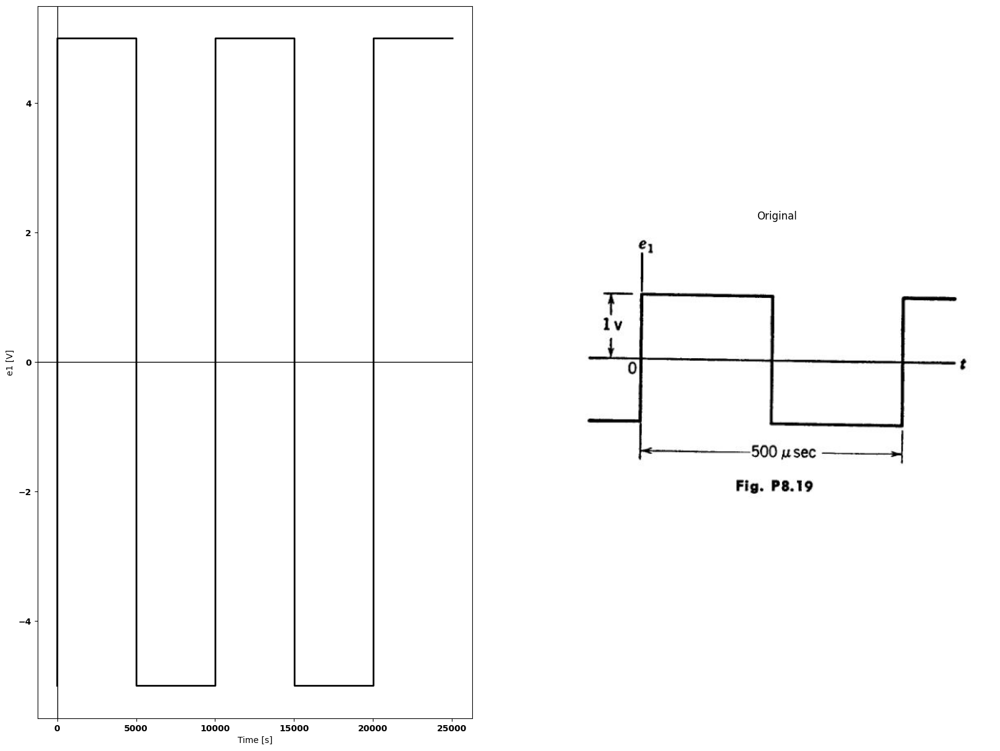

In [126]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-5@u_V, pulsed_value=5@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[0].set_xlabel('Time [s]')
axs[0].set_ylabel('e1 [V]')
axs[0].axhline(0, color='black', linewidth=1)
axs[0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-19.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(c) With ex a periodic square wave, as shown in Fig. P8.19, plot the output  waveform es, assuming that Ce is infinite and C, has the value calculated in (6).  

(d) With e₁ as in Fig. P8.19, plot the output waveform es, assuming that  C, is zero and C. = 0.015 μf.  
(e) Sketch the waveform of 62 if C, has the value in (b) and C. = 0.015 μf.  
(f) Show on the plate characteristics the operating locus of the tube.  
8.21. Using the same circuit as in Problem 8.20, apply an input voltage  = 2 cos wt.  
(a) On semi-log paper plot the voltage gain in decibels as a function of  frequency relative to the midband gain. What is the upper half-power  frequency? What is the lower half-power frequency?  
Plot on the same coordinates the phase characteristics as a function of  frequency.  
(b) Plot on polar coordinates the complex locus of the voltage gain. Show  the location of points corresponding to the midband frequency, the lower half- power frequency, the upper half-power frequency. 


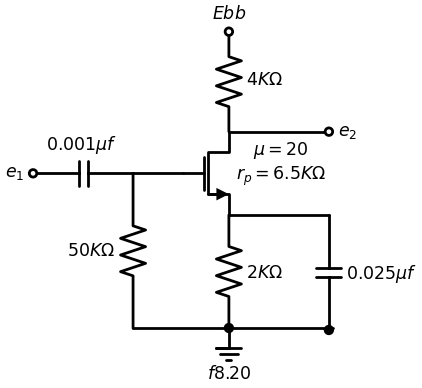

In [127]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (R1 := elm.Resistor(). up(d.unit*1).label('$4KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
    d += (R2 := elm.Resistor(). down(d.unit*1.13).label('$2KΩ$', 'bottom').at(M1.source).dot())
    l1 = d.add(elm.Line().right(d.unit*1).at(M1.source))
    d += (C1:=elm.Capacitor().down(d.unit*1.15).color('black').label('$0.025μf$','bottom').at(l1.end).dot())
    l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
    d += (R3 := elm.Resistor(). down(d.unit*1.55).label('$50KΩ$', 'top').at(l2.end))
    d += (C2:=elm.Capacitor().left(d.unit*1).color('black').label('$0.001μf$','top').at(l2.end).dot(open=True).label('$e_1$','left'))
    l3 = d.add(elm.Line().right(d.unit*2).at(R3.end))
    G = d.add(elm.Ground().at(R2.end).label('$f8.20$','bottom'))
    l4 = d.add(elm.Line().right(d.unit*1).at(M1.drain).dot(open=True).label('$e_2$','right').label('$μ=20$\n$r_p=6.5KΩ$','bottom'))

![](images/p8-20.JPG)

8.22. From the circuit of Fig. P8.20, sketch and dimension:  
(a) the response curve A (jw);  
(b) the transient response to a 1-volt step.  
8.23. Using an appropriate linear incremental circuit model, calculate  the small-signal a-c voltage amplification Aco٫61 of the circuit shown in  Fig. P8.21. Assume that capacitances C₁ and Ck are large.  
8.24. With the circuit of Fig. P8.21 initially at rest, a negative pulse of  magnitude E₁ and short duration T is applied at the input terminals. Plot  the magnitude of the output voltage pulse Eo as a function of E1.  
8.25. In Fig. P8.21 all parameters except Ess and Ra are to remain as given.  Es and Re are to be determined for the following operating conditions.  
A periodic square wave having a peak-to-peak amplitude of 16 volts is to  be applied to the input of the amplifier. Under steady-state conditions, the  minimum allowable plate current is specified as is 2 ma and the maximum  allowable grid voltage is specified as 60 volts to avoid cutoff and grid  current.  


Find the peak-to-peak amplitude of the output voltage waveform and the 
required values of Re and Ebb.  


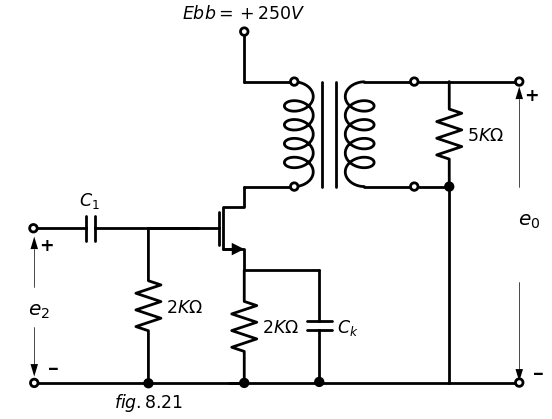

In [128]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (R1 := elm.Resistor(). down(d.unit*1.13).label('$2KΩ$', 'bottom').at(M1.source).dot())
    l1 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
    d += (R2 := elm.Resistor(). down(d.unit*1.55).label('$2KΩ$', 'bottom').at(l1.end).dot().label('$fig.8.21$', 'left'))
    d += (C1:=elm.Capacitor().left(d.unit*1.15).color('black').label('$C_1$','top').at(R2.start).dot(open=True))
    l2 = d.add(elm.Line().left(d.unit*2.1).at(R1.end).dot(open=True))
    l3 = d.add(elm.Line().right(d.unit*.5).at(M1.drain).dot(open=True))
    x = d.add(elm.Transformer(loop=True).at(l3.end))
    l4 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
    l5 = d.add(elm.Line().right(d.unit*.5).at((0,2.1)).dot(open=True))
    l6 = d.add(elm.Line().up(d.unit*.5).at(l5.start).dot(open=True).label('$Ebb=+250V$','right'))
    l7 = d.add(elm.Line().right(d.unit*.5).at((2.4,2.1)).dot(open=True))
    l8 = d.add(elm.Line().right(d.unit*.5).at((2.4,0)).dot(open=True))
    l9 = d.add(elm.Line().right(d.unit*.3).at((3.5,2.1)))
    l10 = d.add(elm.Line().right(d.unit*.3).at((3.5,0)))
    d += (R3 := elm.Resistor().down(d.unit*1.05).label('$5KΩ$', 'bottom').at(l9.end).dot())
    l11 = d.add(elm.Line().down(d.unit*1.96).at(R3.end))
    l12 = d.add(elm.Line().left(d.unit*2.2))
    l13 = d.add(elm.Line().right(d.unit*.7).at(R3.start).dot(open=True))
    l14 = d.add(elm.Line().right(d.unit*.7).at(l11.end).dot(open=True))
    l15 = d.add(elm.Line().right(d.unit*.75).at(M1.source))
    d += (C1:=elm.Capacitor().down(d.unit*1.12).color('black').label('$C_k$','bottom').at(l15.end).dot())
    d += elm.Arrow().up().length(2).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.5,0))
    d += elm.Arrow().down().length(2).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.5,-1.9))
    d += elm.Gap().up().label(  '$e_0$' , ofst=-1.7 , fontsize = 16).color('black').at((4,-1.5))
    d += elm.Arrow().up().length(1).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((-4.2,-2))
    d += elm.Arrow().down().length(1).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-4.2,-2.8))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((-5.8,-3.3))

![](images/p8-21.JPG)

8.26. For the circuit and input waveform shown in Figs. P8.22(a) and (b),  sketch and dimension the output waveform, using a Type IV triode. Compare  the results with those obtained when a Type V triode is used.  

Text(0.5, 1.0, 'Original')

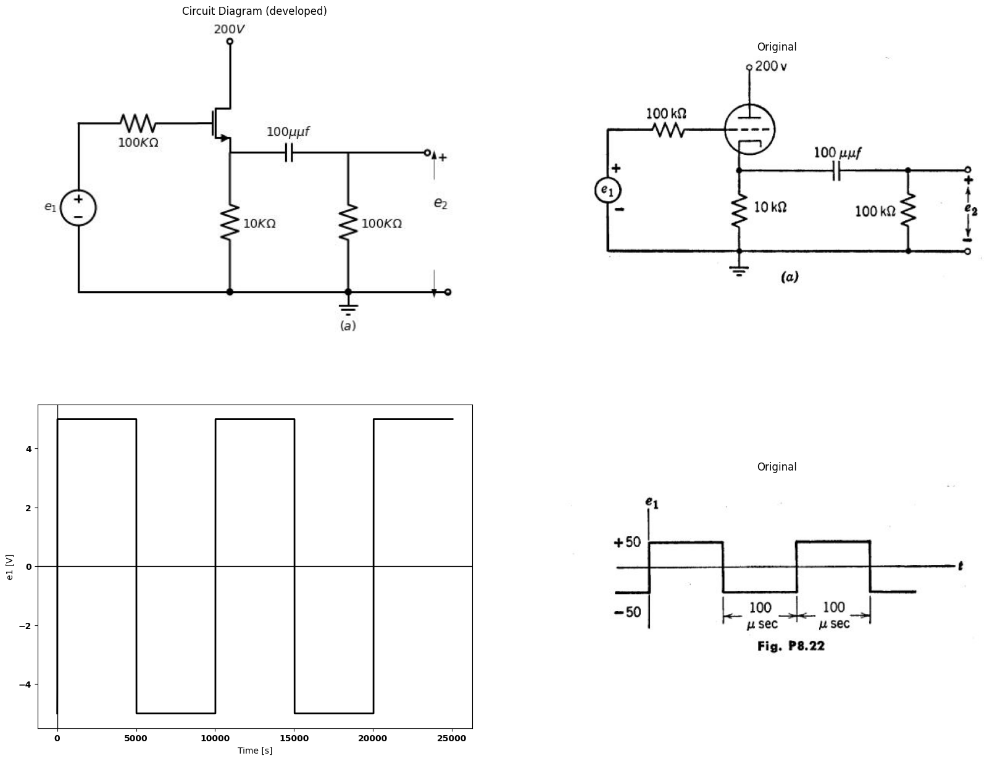

In [140]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$200V$','right'))
d += (R1 := elm.Resistor(). left(d.unit*1.13).label('$100KΩ$', 'bottom').at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.6).label('$e_1$', 'top').at(R1.end).reverse())
d += (R1 := elm.Resistor().down(d.unit*1.32).label('$10KΩ$', 'bottom').at(M1.source).dot())
d += (C1:=elm.Capacitor().right(d.unit*1.12).color('black').label('$100μμf$','top').at(M1.source))
d += (R2 := elm.Resistor().down(d.unit*1.32).label('$100KΩ$', 'bottom').dot())
l2 = d.add(elm.Line().right(d.unit*3.5).at(V1.end).dot(open=True))
l3 = d.add(elm.Line().right(d.unit*.75).at(R2.start).dot(open=True))
d += elm.Arrow().up().length(.8).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.8,-2.4))
d += elm.Arrow().down().length(.8).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.8,-5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4.3,-4.4))
G = d.add(elm.Ground().at(R2.end).label('$(a)$','bottom'))
d.save('images/p8-22b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-22b.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-22a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-5@u_V, pulsed_value=5@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=25@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-22c.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

8.27. Using the Type II triode characteristics, plot the locus of the operating  point for the circuit and input waveform shown in Fig. P8.23. 

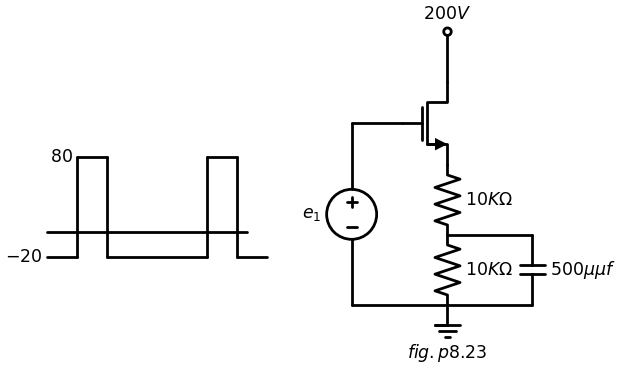

In [141]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$200V$','right'))
    d += (R1 := elm.Resistor().down(d.unit*.7).label('$10KΩ$', 'bottom').at(M1.source))
    d += (R2 := elm.Resistor().down(d.unit*.7).label('$10KΩ$', 'bottom'))
    l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
    V1 = d.add(elm.SourceV().down(d.unit*1.82).label('$e_1$', 'top').at(l2.end).reverse())
    l3 = d.add(elm.Line().right(d.unit*.85).at(R2.start))
    d += (C1:=elm.Capacitor().down(d.unit*.7).color('black').label('$500μμf$','bottom').at(l3.end))
    l4 = d.add(elm.Line().left(d.unit*1.8).at(C1.end))
    G = d.add(elm.Ground().at(R2.end).label('$fig.p8.23$','bottom'))
    l5 = d.add(elm.Line().right(d.unit*2).at((-8,-3)))
    l6 = d.add(elm.Line().right(d.unit*.3).at((-8,-3.5)).label('$-20$','left'))
    l7 = d.add(elm.Line().up(d.unit*1))
    l8 = d.add(elm.Line().right(d.unit*.3).label('$80$','left'))
    l9 = d.add(elm.Line().down(d.unit*1))
    l10 = d.add(elm.Line().right(d.unit*1))
    l7 = d.add(elm.Line().up(d.unit*1))
    l8 = d.add(elm.Line().right(d.unit*.3))
    l9 = d.add(elm.Line().down(d.unit*1))
    l10 = d.add(elm.Line().right(d.unit*.3))

![](images/p8-23.JPG)

8.28. The triode in the cathode-follower circuit shown in Fig. P8.24 is  (a) With e.0, graphically determine the quiescent operating point.  
(b) Determine the values of u, rp, and gm at the operating point of part (a).  


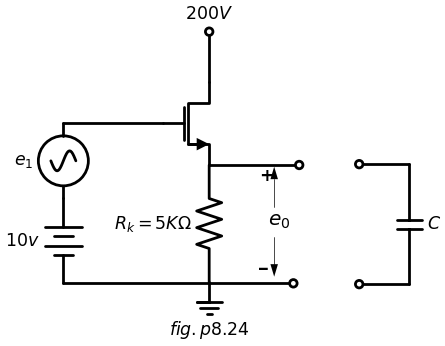

In [143]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$200V$','right'))
    d += (R1 := elm.Resistor().down(d.unit*1.17).label('$R_k=5KΩ$', 'top').at(M1.source))
    l2 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
    V1 = d.add(elm.SourceSin().down(d.unit*.75).label('$e_1$', 'top'))
    V2 = d.add(elm.Battery().down(d.unit*.85).label('$10v$', 'top'))
    l3 = d.add(elm.Line().right(d.unit*2.3).dot(open=True))
    l4 = d.add(elm.Line().right(d.unit*.9).dot(open=True).at(M1.source))
    l5 = d.add(elm.Line().left(d.unit*.5).dot(open=True).at((4,-1.65)))
    d += (C1 := elm.Capacitor().down(d.unit*1.2).label('$C$', 'bottom').at(l5.start))
    l5 = d.add(elm.Line().left(d.unit*.5).dot(open=True))
    d += elm.Arrow().up().length(.8).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=.3). at((1.3,-2.5))
    d += elm.Arrow().down().length(.8).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, -.3)). at((1.3,-3.1))
    d += elm.Gap().up().label(  '$e_0$' , ofst=-1.7 , fontsize = 16).color('black').at((-.3,-3.6))
    G = d.add(elm.Ground().at(R1.end).label('$fig.p8.24$','bottom'))

![](images/p8-24a.JPG)

(c) Derive the expression for the incremental voltage gain Des٫Ae, in terms  (d) Determine the expression for complex voltage gain if a capacitor C is  now connected across Rk.  
8.29. Assume a piecewise-linear triode model in the circuit of Fig. P8.25  with R very much larger than r, and wRC very much larger than unity.  
(a) Sketch a qualitative curve of steady-state d-c output voltage E2 vs.  the amplitude E1 of the a-c input signal.  
(6) Sketch and dimension a quantitative curve of E₂ vs. E1 based upon  the piecewise-linear triode model.  
(c) How would you expect an experimental curve to differ from that of  part (b)?  


Text(0.5, 1.0, 'Original')

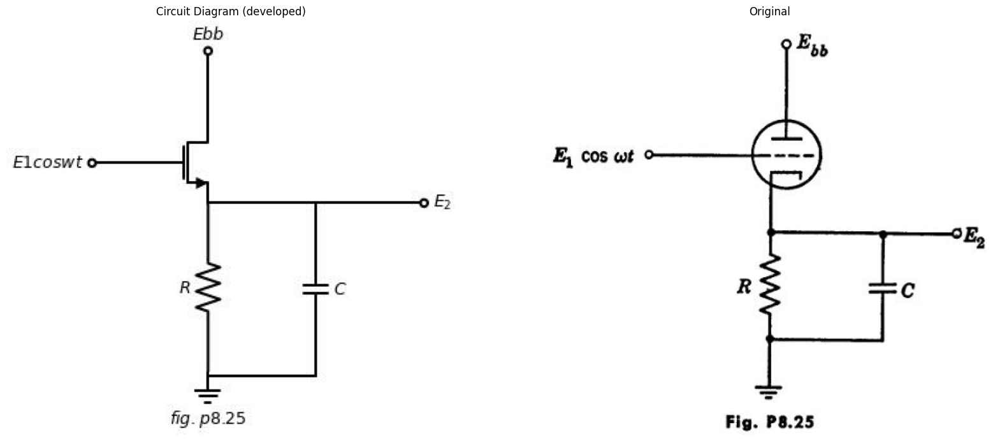

In [145]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$Ebb$','right'))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate).dot(open=True).label('$E1 cos wt$','left'))
d += (R1 := elm.Resistor().down(d.unit*1.17).label('$R$', 'top').at(M1.source))
l3 = d.add(elm.Line().right(d.unit*.75).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.2).label('$C$', 'bottom'))
l3 = d.add(elm.Line().left(d.unit*.75))
G = d.add(elm.Ground().at(R1.end).label('$fig.p8.25$','bottom'))
l3 = d.add(elm.Line().right(d.unit*.75).dot(open=True).label('$E_2 $','right').at(C1.start))
d.save('images/p8-25b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-25b.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-25.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.30. The tube represented by the linearized characteristics of Fig. P8.26  is used as an "infinite-impedance" detector in the circuit shown in Fig. P8.27.  With the circuit at rest, the two pulses shown in Fig. P8.28 are applied to  the input.  
(a) Plot carefully the output voltage over the time interval 0 < t < 100  usec. 


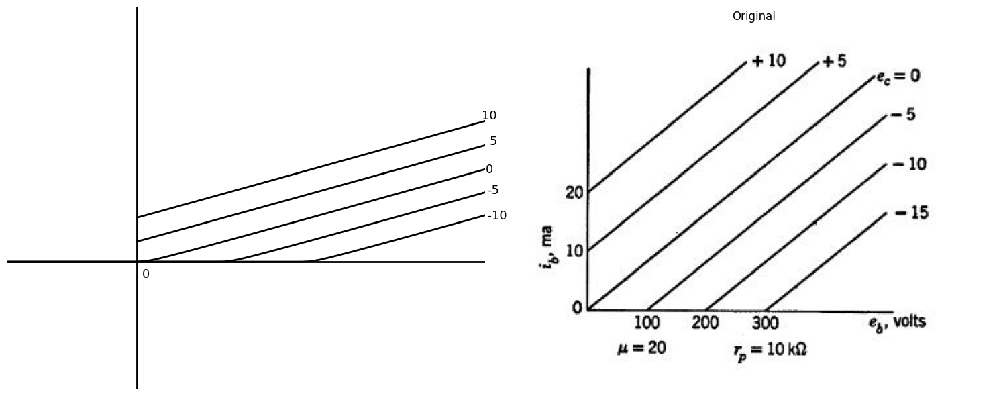

In [5]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

import schemdraw
import schemdraw.elements as elm
import schemdraw as schem
from schemdraw import dsp

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 0@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-3, 10, 0.2))
axs[0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, -2@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, -4@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 2@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-3, 10, 0.2))
axs[0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 4@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

axs[0].text(8.2, 0.28, '-5', ha='center', va='center', fontsize = 13)
axs[0].text(8.2, 0.18, '  -10', ha='center', va='center', fontsize = 13)
axs[0].text(8.1, 0.36, '0', ha='center', va='center', fontsize = 13)
axs[0].text(8.2, 0.47, '5', ha='center', va='center', fontsize = 13)
axs[0].text(8.1, 0.57, '10', ha='center', va='center', fontsize = 13)
axs[0].text(0.2, -0.05, '0', ha='center', va='center', fontsize = 13)
#axs[1].text(-1, 0.15, 'i=0', ha='center', va='center', fontsize = 13)
#axs[1].text(-1, 0.1, 'for', ha='center', va='center', fontsize = 13)
#axs[1].text(-1, 0.05, 'v<0', ha='center', va='center', fontsize = 13)
#axs[1].text(-0.2, 1, 'i', ha='center', va='center', fontsize = 18)
#axs[1].text(8.5, 0.02, 'v', ha='center', va='center', fontsize = 18)
#axs[1].text(0.8, -0.32, '(d)', ha='center', va='center', fontsize=15)

axs[0].axhline(0, color='black',linewidth=2, ls='-')
axs[0].axvline(0, color='black',linewidth=2, ls='-')
axs[0].set_xlim(-3, 8)
axs[0].set_ylim(-0.5, 1)
axs[0].axis('off')  # Hide axes for image display

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-26.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')
# Show the combined plots
plt.tight_layout()
plt.show() 

(6) Sketch the tube characteristics and indicate the operating locus for the  tube during the interval 20 < t < 55 µsec. Locate, on the path, points corre- 
sponding to the times t = 20-, 20+, 40-, 40c+, 50- µsec. (Show an enlarged  
section of the characteristics, if necessary.)  
8.31. The circuit shown in Fig. P8.29(a) has the negative-step input  indicated in Fig. P8.29(b).  
(a) Justify the piecewise-linear model given in Fig. P8.29(c).  
(b) Using this model, sketch and dimension e₂(t) for E1 less than V٫μ.  
(c) Repeat part (b) for E₁ greater than V٫µ. Try to deduce the answers  directly from the circuit model. 


Text(0.5, 1.0, 'Original')

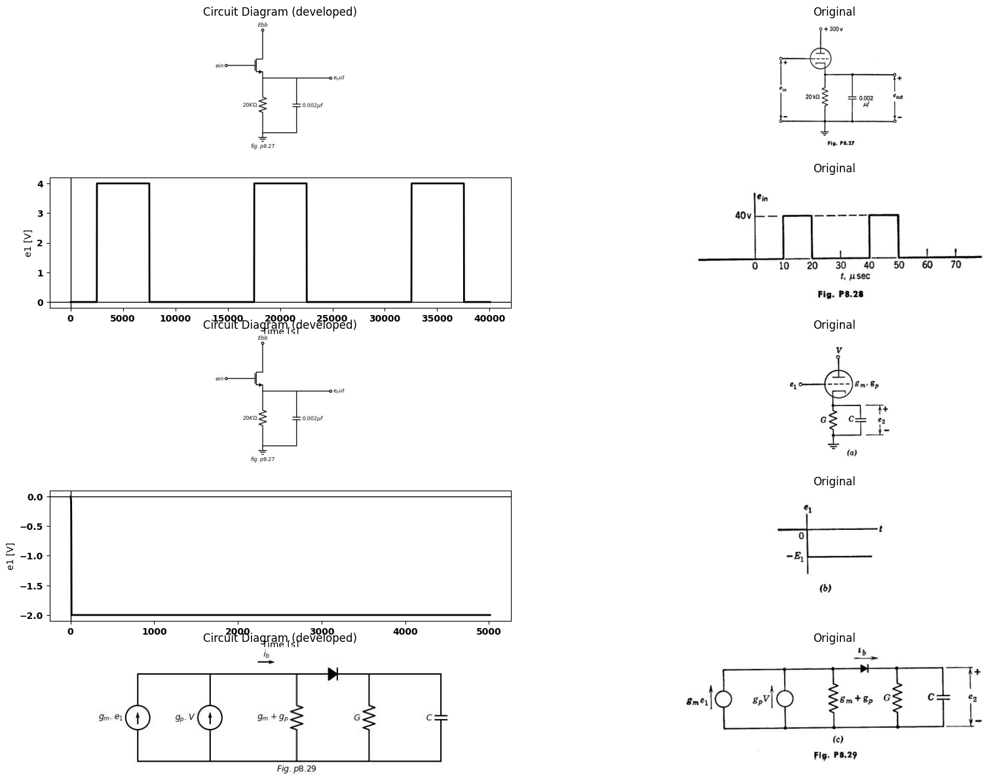

In [24]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$Ebb$','right'))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate).dot(open=True).label('$ein$','left'))
d += (R1 := elm.Resistor().down(d.unit*1.17).label('$20KΩ$', 'top').at(M1.source))
l3 = d.add(elm.Line().right(d.unit*.75).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.2).label('$0.002μf$', 'bottom'))
l3 = d.add(elm.Line().left(d.unit*.75))
G = d.add(elm.Ground().at(R1.end).label('$fig.p8.27$','bottom'))
l3 = d.add(elm.Line().right(d.unit*.75).dot(open=True).label('$e_out $','right').at(C1.start))
d.save('images/p8-27b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-27b.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-27.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=4@u_V,delay_time=2.5@u_ms, pulse_width=5@u_ms, period=15@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-28.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$Ebb$','right'))
l2 = d.add(elm.Line().left(d.unit*.5).at(M1.gate).dot(open=True).label('$ein$','left'))
d += (R1 := elm.Resistor().down(d.unit*1.17).label('$20KΩ$', 'top').at(M1.source))
l3 = d.add(elm.Line().right(d.unit*.75).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.2).label('$0.002μf$', 'bottom'))
l3 = d.add(elm.Line().left(d.unit*.75))
G = d.add(elm.Ground().at(R1.end).label('$fig.p8.27$','bottom'))
l3 = d.add(elm.Line().right(d.unit*.75).dot(open=True).label('$e_out $','right').at(C1.start))
d.save('images/p8-299b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-299b.jpg')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-29a.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=0@u_V, pulsed_value=-2@u_V, pulse_width=5@u_ms, period=6@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=5@u_ms)
axs[3,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[3,0].set_xlabel('Time [s]')
axs[3,0].set_ylabel('e1 [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-29b.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
d = schemdraw.Drawing()
I1 = d.add(elm.SourceI().down(d.unit*1.2).label('$g_m.e_1$', 'top').reverse())
l1 = d.add(elm.Line().right(d.unit*1))
I2 = d.add(elm.SourceI().up(d.unit*1.2).label('$g_p.V$', 'top'))
l2 = d.add(elm.Line().left(d.unit*1))
l3 = d.add(elm.Line().right(d.unit*1.2).at(l2.start))
d += (R1 := elm.Resistor().down(d.unit*1.2).label('$g_m+g_p$', 'top').label('$Fig.p8.29$', 'left'))
l4 = d.add(elm.Line().left(d.unit*1.2))
D1 = d.add(elm.Diode(fill=True).right(d.unit*1).at(R1.start))
d += (R2 := elm.Resistor().down(d.unit*1.2).label('$G$', 'top'))
l5 = d.add(elm.Line().left(d.unit*1))
l6 = d.add(elm.Line().right(d.unit*1).at(R2.start))
d += (C1 := elm.Capacitor().down(d.unit*1.2).label('$C$', 'top'))
l5 = d.add(elm.Line().left(d.unit*1))
d += elm.Arrow().right().length(.7).color('black').label('$i_b$', loc='top', color='black'). at((5,.5))
d.save('images/p8-299b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-299b.jpg')
axs[4,0].imshow(img)
axs[4,0].axis('off')  # Hide axes for image display
axs[4,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-29.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

8.32. A cathode follower is used to couple pulses from a source to a capacitive  load. The present design, shown in Fig. P8.30(a), yields a satisfactory rise  time but the output fall time is too large. The circuit shown in Fig. P8.30(b)  has been proposed as one with better response for this application. Sketch  and dimension the waveform e₂(t) for each of the two circuits.  

Text(0.5, 1.0, 'Original')

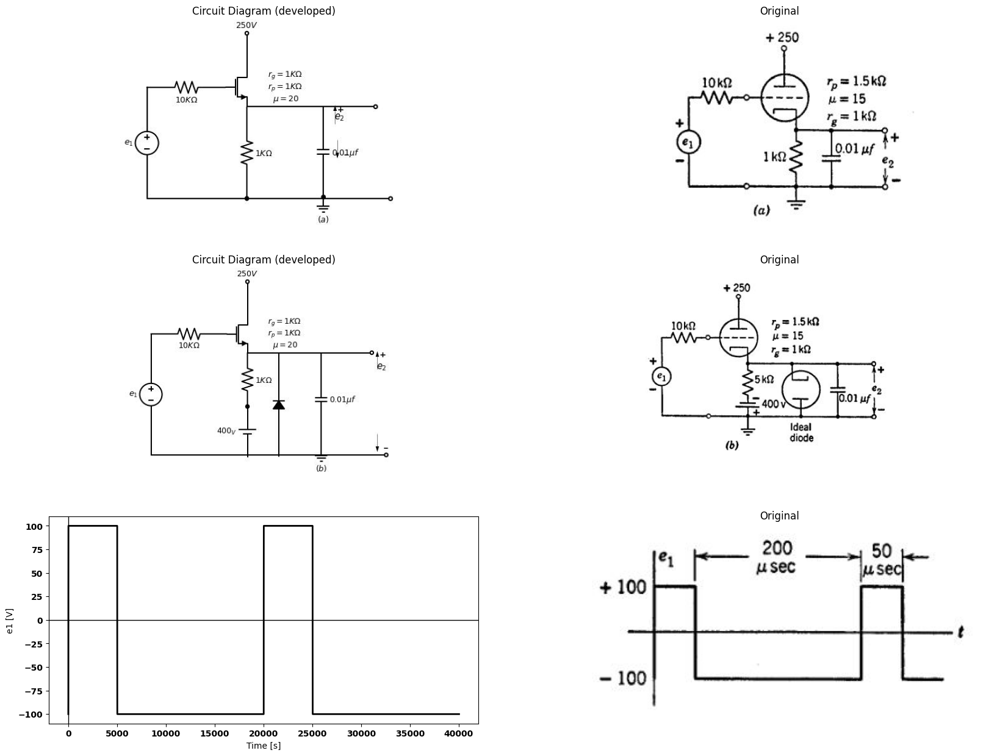

In [40]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$250V$','right'))
d += (R1 := elm.Resistor(). left(d.unit*1.13).label('$10KΩ$', 'bottom').at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.6).label('$e_1$', 'top').at(R1.end).reverse())
d += (R1 := elm.Resistor().down(d.unit*1.32).label('$1KΩ$', 'bottom').at(M1.source).dot())
l1 = d.add(elm.Line().right(d.unit*1.1).at(M1.source).label('$r_g=1KΩ$ \n$r_p=1KΩ$ \n $μ=20$ ', 'top'))
d += (C2 := elm.Capacitor().down(d.unit*1.3).label('$0.01μf$', 'bottom').dot())
l2 = d.add(elm.Line().right(d.unit*3.5).at(V1.end).dot(open=True))
l3 = d.add(elm.Line().right(d.unit*.75).at(C2.start).dot(open=True))
d += elm.Arrow().up().length(.8).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.8,-2.4))
d += elm.Arrow().down().length(.8).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((3.9,-3.1))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2.3,-3.4))
G = d.add(elm.Ground().at(C2.end).label('$(a)$','bottom'))
d.save('images/p8-30b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-30b.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-30a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$250V$','right'))
d += (R1 := elm.Resistor(). left(d.unit*1.13).label('$10KΩ$', 'bottom').at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.8).label('$e_1$', 'top').at(R1.end).reverse())
d += (R1 := elm.Resistor().down(d.unit*0.8).label('$1KΩ$', 'bottom').at(M1.source).dot())
l1 = d.add(elm.Line().right(d.unit*1.1).at(M1.source).label('$r_g=1KΩ$ \n$r_p=1KΩ$ \n $μ=20$ ', 'top'))
d += (C2 := elm.Capacitor().down(d.unit*1.4).label('$0.01μf$', 'bottom'))
l2 = d.add(elm.Line().right(d.unit*3.5).at(V1.end).dot(open=True))
l3 = d.add(elm.Line().right(d.unit*.75).at(C2.start).dot(open=True))
d += elm.Arrow().up().length(.8).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.8,-2.4))
d += elm.Arrow().down().length(.8).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.8,-5.3))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4.3,-3.6))
G = d.add(elm.Ground().at(C2.end).label('$(b)$','bottom'))
V2 = d.add(elm.BatteryCell().down(d.unit*.75).label('$400_V$', 'top').at(R1.end))
D1 = d.add(elm.Diode(fill=True).down(d.unit*1.53).at((1.4,-1.7)).reverse())
d.save('images/p8-30`a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-30`a.jpg')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-30bb.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-100@u_V, pulsed_value=100@u_V, pulse_width=5@u_ms, period=20@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[2,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[2,0].set_xlabel('Time [s]')
axs[2,0].set_ylabel('e1 [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-30v.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

8.33. A triode is operated as a cathode follower with a supply voltage  Ebb 250 volts. The circuit is used to drive a coaxial transmission line which  can be represented here as a resistance $R_{k} = 2$ kilohms in parallel with a  capacitance $C_{k}$ = 100$\mu$$\mu$f the parallel combination being connected between  cathode and ground. Other capacitances in the circuit are negligible. The  input voltage e₁ (from grid to ground) is originally zero and the system is at  rest when a negative step of height E₁ is applied t = 0 Assume that the  tube is piecewise-linear with r_{p} = 10 kilohms and $\mu$ = 20  
(a) Sketch and dimension cathode voltage etfor $E_{1}$ = 1 volt.  
(b) Repeat for $E_{1} $= 20 volts.  
(c) What is the greatest initial rate of decrease (volts٫sec) of ex(t) obtain- able with this circuit for any value of E₁?  
8.34. In the circuit of Fig. P8.31, the input voltage e₁(t) is zero for negative  time and minus one-tenth volt for positive time. Choose a suitable circuit  model to represent the operation of the triode in this problem and explain  how to determine suitable values for the parameters in the model. Calculate  the output voltage e(t) for Re not equal to zero, and Re equal to zero.  
8.35. A small negative step voltage of height E₁ is applied to the input  terminal of the amplifier shown in Fig. P8.32. The input voltage is zero  (ground) before the step is applied. 


(a) Sketch and dimension the total output voltage e₂(t) as a function of  time. Assume that triode plate curves are available and that capacitor C is  the only important energy-storage element in the circuit.  
(b) Sketch and dimension the log-log plot of E₂ versus frequency when en  
is a sinusoid of small fixed amplitude and E: is the amplitude of the sinusoidal  component of the output voltage.  


Text(0.5, 1.0, 'Original')

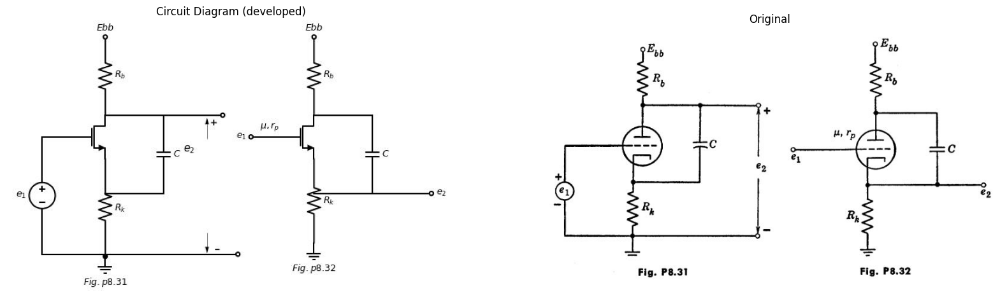

In [48]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().up(d.unit*1).label('$R_b$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
d += (R2 := elm.Resistor().down(d.unit*1.25).label('$R_k$', 'bottom').at(M1.source).dot())
l1 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').at(l1.end).reverse())
l2 = d.add(elm.Line().right(d.unit*2.5).at(V1.end).dot(open=True))
l3 = d.add(elm.Line().right(d.unit*.75).at(M1.drain))
d += (C1 := elm.Capacitor().down(d.unit*1).label('$C$', 'bottom'))
l4 = d.add(elm.Line().left(d.unit*.75))
l5 = d.add(elm.Line().right(d.unit*.75).at(C1.start).dot(open=True))
G = d.add(elm.Ground().at(R2.end).label('$Fig.p8.31$','bottom'))
d += elm.Arrow().up().length(.8).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.9,-.9))
d += elm.Arrow().down().length(.8).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((3.9,-4.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((1.5,-2.6))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().at((8,0)))
l6 = d.add(elm.Line().left(d.unit*.5).at(M2.gate).dot(open=True).label('$e_1$', 'left').label('$μ,r_p$', 'top'))
d += (R3 := elm.Resistor().down(d.unit*1.08).label('$R_k$', 'bottom').at(M2.source))
G = d.add(elm.Ground().at(R3.end).label('$Fig.p8.32$','bottom'))
d += (R4 := elm.Resistor().up(d.unit*1).label('$R_b$', 'bottom').at(M2.drain).dot(open=True).label('$Ebb$', 'right'))
l7 = d.add(elm.Line().right(d.unit*.75).at(M2.drain))
d += (C2 := elm.Capacitor().down(d.unit*1).label('$C$', 'bottom'))
l8 = d.add(elm.Line().left(d.unit*.75))
l9 = d.add(elm.Line().right(d.unit*.75).dot(open=True).label('$e_2$', 'right').at(l8.start))
d.save('images/p8-32b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-32b.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-32.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(c) Sketch and dimension e₂(t) for a small negative step applied at e1,  using a piecewise-linear triode model instead of the nonlinear plate curves and  with capacitor C replaced by an ideal inductor L.  

Text(0.5, 1.0, 'Original')

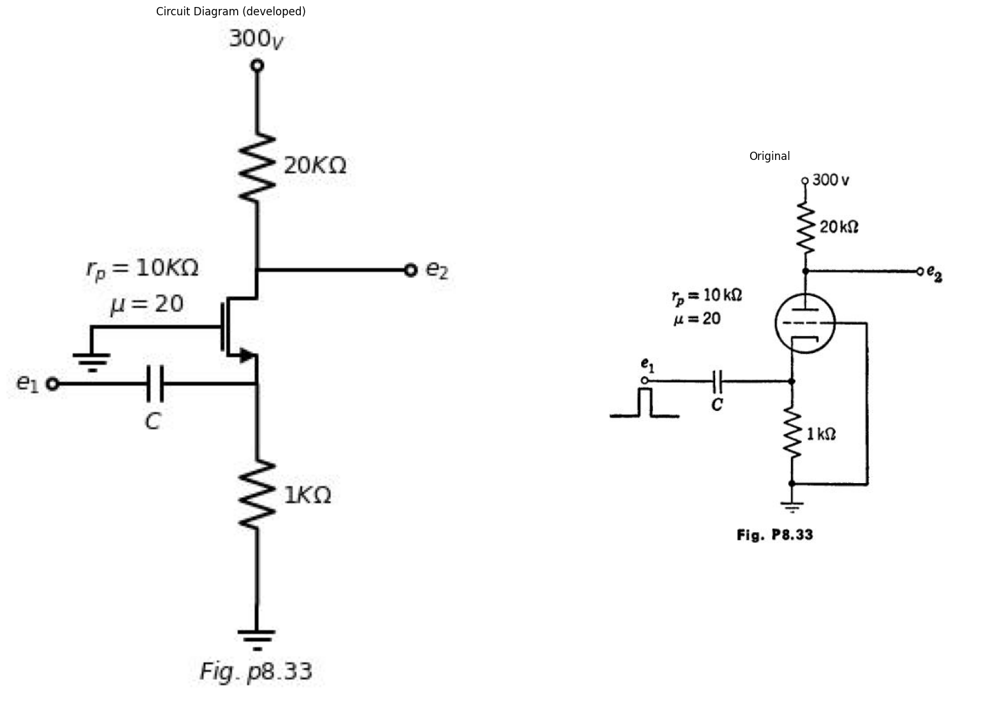

In [49]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().up(d.unit*1).label('$20KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$300_V$', 'right'))
d += (R2 := elm.Resistor().down(d.unit*1.08).label('$1KΩ$', 'bottom').at(M1.source))
G = d.add(elm.Ground().at(R2.end).label('$Fig.p8.33$','bottom'))
l1 = d.add(elm.Line().left(d.unit*.5).at(M1.gate).label('$r_p=10KΩ$ \n $μ=20$', 'top'))
G = d.add(elm.Ground().at(l1.end))
d += (C1 := elm.Capacitor().left(d.unit*1).label('$C$', 'bottom').dot(open=True).label('$e_1$', 'left').at(M1.source))
l2 = d.add(elm.Line().right(d.unit*.75).at(M1.drain).label('$e_2$', 'right').dot(open=True))
d.save('images/p8-33b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-33b.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-33a.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.36. A single 0.1-volt pulse of 100 usec duration is applied at en in the  circuit of Fig. P8.33. Sketch and dimension:  
(a) The cathode voltage ex(t).  
(b) The output voltage e₂(t), for a value of C which makes the time constant  five times the pulse duration. What is the value of C? What is the qualita- tive effect of plate-to-cathode capacitance?  
8.37. (a) In discussing the response e₂(t) of the circuit in Fig. P8.34(a) to  the input wave e₁(t) shown in Fig. P8.34(6), what time constant is relevant,  assuming that T is large enough so that interelectrode capacitances may be  neglected, and that E is such that the tube operates in the linear region of  
its characteristics? Express in terms of R1, R2, C, μ, rρ. 


Text(0.5, 1.0, 'Original')

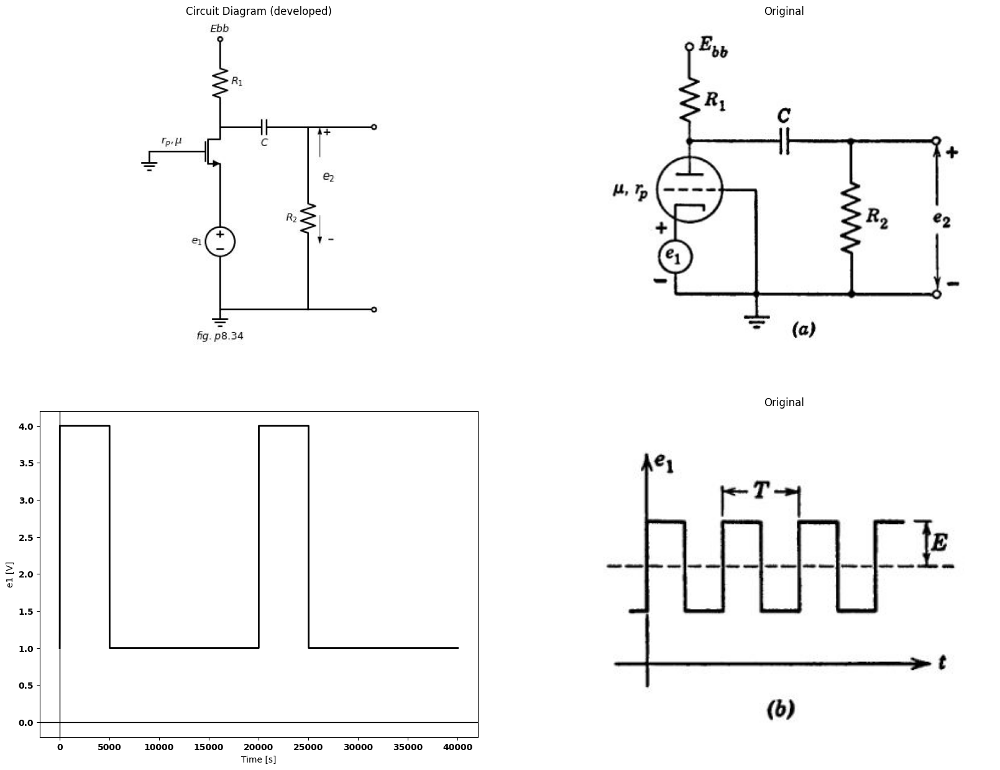

In [54]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').at(M1.source).reverse())
G = d.add(elm.Ground().at(V1.end).label('$fig.p8.34$', 'bottom'))
l1 = d.add(elm.Line().left(d.unit*.5).at(M1.gate).label('$r_p,μ$', 'top'))
G = d.add(elm.Ground().at(l1.end))
d += (R1 := elm.Resistor().up(d.unit*1).label('$R_1$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
d += (C1 := elm.Capacitor().right(d.unit*1).label('$C$', 'bottom').at(M1.drain))
d += (R2 := elm.Resistor().down(d.unit*2.08).label('$R_2$', 'top').at(C1.end))
l2 = d.add(elm.Line().left(d.unit*1).at(R2.end))
l3 = d.add(elm.Line().right(d.unit*.75).at(R2.end).dot(open=True))
l4 = d.add(elm.Line().right(d.unit*.75).at(R2.start).dot(open=True))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((3.4,-1))
d += elm.Arrow().down().length(1).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((3.4,-3))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((2,-3))
d.save('images/p8-341b.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-341b.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-34a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=1@u_V, pulsed_value=4@u_V, pulse_width=5@u_ms, period=20@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-34b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

(b) If tau = 100T i.e., if we can assume ideal coupling, sketch and dimension  the output wave e₂(t). Consider e₁(t) to have been on for a long time so that  the circuit is in the steady state.  
8.38. A triode is operated as a grounded-cathode amplifier with a plate load $ R_{b} $= 20 kilohms. Assume linear operation with $r_{p} = 20$ kilohms and  $\mu = 40$ Use the linear incremental equivalent circuit. A capacitance  $Cgp = 100$ μμf is purposely connected between the grid and plate terminals  and a small input step voltage of height E1 is suddenly applied at the grid.  Other capacitances may be ignored. Sketch and dimension the input current  $i{1}(t)$ drawn from the input voltage source. On the basis of this waveform  deduce an equivalent passive RC circuit which would draw the same input  current as the actual tube circuit. Evaluate the constants of this circuit both  literally (in terms of rp, µ, Rb, Cop) and numerically. How much larger than  Cop is the capacitance appearing in the equivalent input circuit? (This  aggrandization of capacitance is called the Miller effect.) 


Text(0.5, 1.0, 'Original')

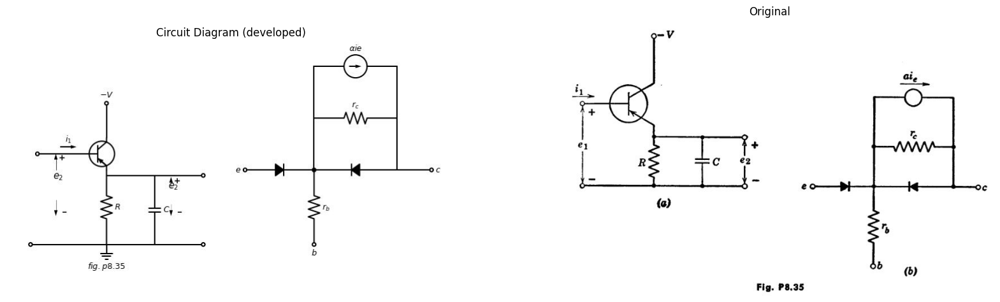

In [56]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.BjtPnp(circle=True).anchor('emitter').theta(180).reverse())
l1 = d.add(elm.Line().up(d.unit*.5).at(M1.collector).label('$-V$', 'right').dot(open=True))
l2 = d.add(elm.Line().left(d.unit*.75).at(M1.base).dot(open=True))
d += (R1 := elm.Resistor().down(d.unit*1.08).label('$R$', 'bottom').at(M1.emitter))
l3 = d.add(elm.Line().left(d.unit*1.1).at(R1.end).dot(open=True))
G = d.add(elm.Ground().at(R1.end).label('$fig.p8.35$', 'bottom'))
l4 = d.add(elm.Line().right(d.unit*.7).at(R1.end))
d += (C1 := elm.Capacitor().up(d.unit*1).label('$C$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*.7))
l6 = d.add(elm.Line().right(d.unit*.7).at(l5.start).dot(open=True))
l7 = d.add(elm.Line().right(d.unit*.7).at(l4.end).dot(open=True))
d += elm.Arrow().right().length(.7).color('black').label('$i_1$', loc='top', color='black'). at((-2,1))
d += elm.Arrow().up().length(.5).linewidth(.3).color('black').label('+',loc='end', color='black',ofst=-.1). at((2.8,-.8))
d += elm.Arrow().down().length(.5).linewidth(.3).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((2.8,-1.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((1.2,-2))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((-2.2,0))
d += elm.Arrow().down().length(.7).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-2.2,-1.3))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((-3.8,-1.6))
l8 = d.add(elm.Line().right(d.unit*.007).at((6,0)).dot(open=True).label('$e$', 'left'))
D1 = d.add(elm.Diode(fill=True).right().dot())
d += (R2 := elm.Resistor().down(d.unit*1.08).label('$r_b$', 'bottom').dot(open=True).label('$b$', 'left'))
l9 = d.add(elm.Line().up(d.unit*.75).at(D1.end))
d += (R3 := elm.Resistor().right(d.unit*1.2).label('$r_c$', 'top'))
l10 = d.add(elm.Line().down(d.unit*.75))
D2 = d.add(elm.Diode(fill=True).left(d.unit*1.2))
l11 = d.add(elm.Line().up(d.unit*.75).at(R3.start))
I1 = d.add(elm.SourceI().right(d.unit*1.2).label('$αie$', 'top'))
l12 = d.add(elm.Line().down(d.unit*.75))
l13 = d.add(elm.Line().right(d.unit*.5).dot(open=True).label('$c$', 'right').at(D2.start))
d.save('images/p8-35f.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-35f.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-35.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.39. A transistor is to be used as a common-collector amplifier to drive a  capacitive load, as shown in Fig. P8.35 (a). If energy storage in the transistor  is neglected:  
(a) What is the emitter voltage waveform for a small negative step of base  current i₁?  
(b) What is the small-signal frequency response?  


Text(0.5, 1.0, 'Original')

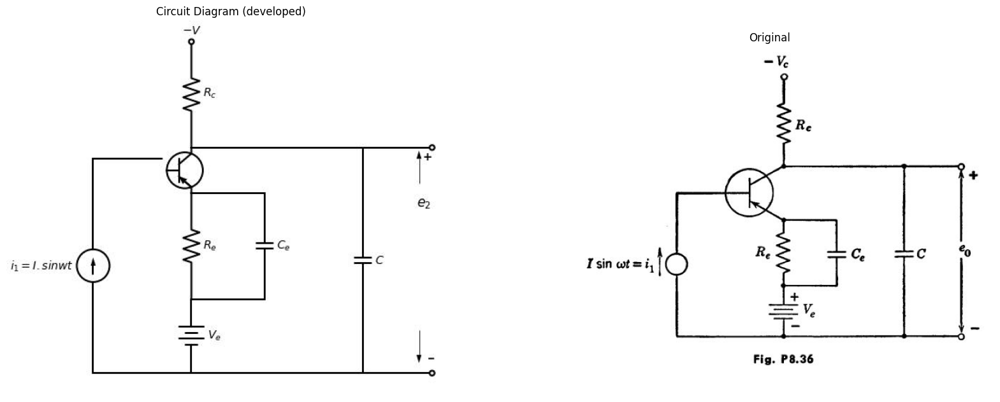

In [64]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.BjtPnp(circle=True).anchor('emitter').theta(180).reverse())
d += (R1 := elm.Resistor().up(d.unit*1.08).label('$R_c$', 'bottom').at(M1.collector).dot(open=True).label('$-V$', 'right'))
d += (R2 := elm.Resistor().down(d.unit*1.08).label('$R_e$', 'bottom').at(M1.emitter))
l1 = d.add(elm.Line().right(d.unit*.75).at(M1.emitter))
d += (C1 := elm.Capacitor().down(d.unit*1.08).label('$C_e$', 'bottom'))
l2 = d.add(elm.Line().left(d.unit*.75))
V1 = d.add(elm.Battery().down(d.unit*.75).label('$V_e$', 'bottom').at(l2.end))
l3 = d.add(elm.Line().left(d.unit*1))
I1 = d.add(elm.SourceI().up(d.unit*2.18).label('$i_1=I.sinwt$', 'top'))
l4 = d.add(elm.Line().right(d.unit*.7))
l5 = d.add(elm.Line().right(d.unit*1.75).at(M1.collector))
d += (C2 := elm.Capacitor().down(d.unit*2.3).label('$C$', 'bottom'))
l6 = d.add(elm.Line().left(d.unit*2))
l7 = d.add(elm.Line().right(d.unit*.7).at(l5.end).dot(open=True))
l8 = d.add(elm.Line().right(d.unit*.7).at(l6.start).dot(open=True))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((6.95,.3))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.95,-4.2))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5.4,-1.6))
d.save('images/p8-36j.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-36j.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-36.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.40. From the circuit shown in Fig. P8.36, find the frequency at which the  output voltage drops to 0.707 of its midband value (that is, its value when  capacitor C can be neglected), in terms of $r{e}$,$ r{b}$, $r{c}$, a and the circuit parameters.  Assume C. is large enough to be considered an a-c short circuit for all frequen- cies being considered.  

Text(0.5, 1.0, 'Original')

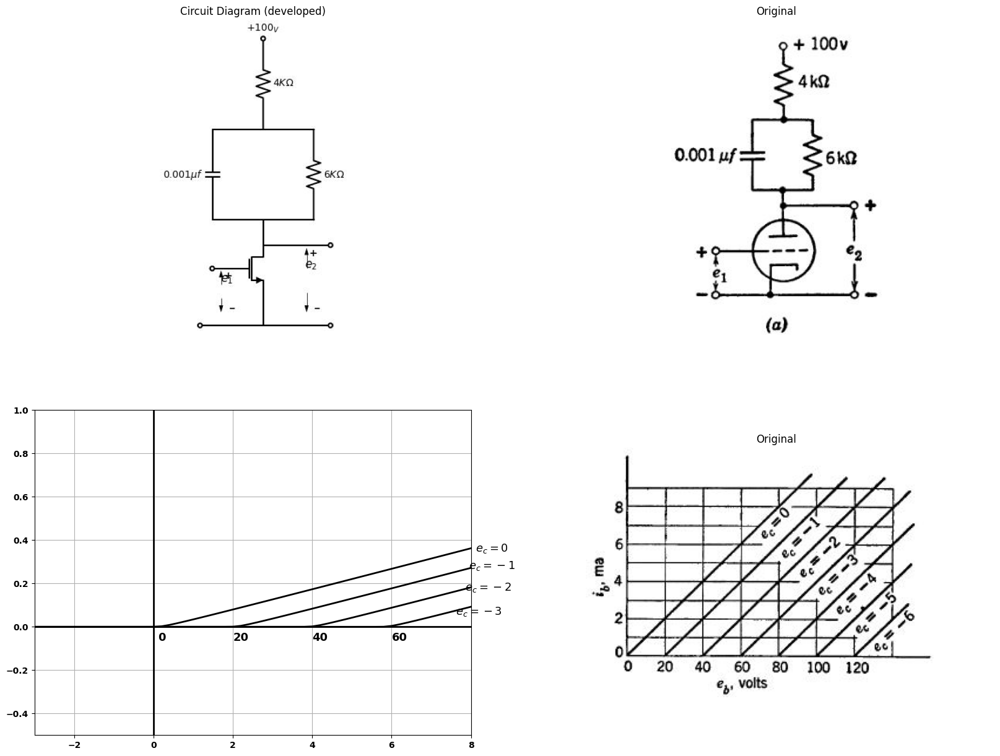

In [67]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().down(d.unit*.4).at(M1.source))
l2 = d.add(elm.Line().left(d.unit*.75).dot(open=True))
l3 = d.add(elm.Line().left(d.unit*.3).at(M1.gate).dot(open=True))
l4 = d.add(elm.Line().right(d.unit*.8).at(l2.start).dot(open=True))
l5 = d.add(elm.Line().right(d.unit*.8).at(M1.drain).dot(open=True))
l6 = d.add(elm.Line().up(d.unit*.3).at(M1.drain))
l7 = d.add(elm.Line().left(d.unit*.6).at(l6.end))
d += (C1 := elm.Capacitor().up(d.unit*1.08).label('$0.001μf$', 'top'))
l8 = d.add(elm.Line().right(d.unit*.6))
d += (R1 := elm.Resistor().up(d.unit*1.08).label('$4KΩ$', 'bottom').dot(open=True).label('$+100_V$', 'right'))
l9 = d.add(elm.Line().right(d.unit*.6).at(l8.end))
d += (R1 := elm.Resistor().down(d.unit*1.08).label('$6KΩ$', 'bottom'))
l10 = d.add(elm.Line().left(d.unit*.6))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((1.55,-.8))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((1.55,-1.7))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((0,-2))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((-1.5,-1.4))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-1.5,-1.9))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-3,-2.5))
d.save('images/p8-37.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-37.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-37`a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 0@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-3, 10, 0.2))
axs[1,0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, -2@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
#axs[0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 6@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-3, 10, 0.2))
axs[1,0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 2@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(-3, 10, 0.2))
axs[1,0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

circuit = Circuit('Control Vaves') 
circuit.model('BAV21','D' ,IS = 100@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 20@u_Ohm ,TT = 3.48E-9)
Vth = circuit.V('th', '1', circuit.gnd, 0@u_V)
circuit.D(1,'1' ,'2', model = 'BAV21')
circuit.R(1, '2', '3', 1@u_Ohm)
circuit.V('fixed', '3', circuit.gnd, 4@u_V)
circuit.D(2,'2' ,circuit.gnd, model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vth=slice(0, 10, 0.2))
axs[1,0].plot(analysis['1'], u_A(-analysis.Vth),'black',linestyle='-',linewidth=2)

axs[1,0].text(8.2, 0.28, '       $e_c =-1$', ha='center', va='center', fontsize = 13)
axs[1,0].text(8.2, 0.18, '     $e_c =-2$', ha='center', va='center', fontsize = 13)
axs[1,0].text(8.1, 0.36, '         $e_c =0$', ha='center', va='center', fontsize = 13)
axs[1,0].text(8.2, 0.07, '$e_c =-3$', ha='center', va='center', fontsize = 13)
#axs[0].text(8.1, 0.57, '10', ha='center', va='center', fontsize = 13)
axs[1,0].text(0.2, -0.05, '0', ha='center', va='center', fontsize = 13)
axs[1,0].text(2.2, -0.05, '20', ha='center', va='center', fontsize = 13)
axs[1,0].text(4.2, -0.05, '40', ha='center', va='center', fontsize = 13)
axs[1,0].text(6.2, -0.05, '60', ha='center', va='center', fontsize = 13)
#axs[1].text(-0.2, 1, 'i', ha='center', va='center', fontsize = 18)
#axs[1].text(8.5, 0.02, 'v', ha='center', va='center', fontsize = 18)
#axs[1].text(0.8, -0.32, '(d)', ha='center', va='center', fontsize=15)

axs[1,0].axhline(0, color='black',linewidth=2, ls='-')
axs[1,0].axvline(0, color='black',linewidth=2, ls='-')
axs[1,0].set_xlim(-3, 8)
axs[1,0].set_ylim(-0.5, 1)
#axs[0].axis('off')  # Hide axes for image display
axs[1,0].grid(True)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-37-b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

8.41. The plate characteristics of the tube used in the circuit of Fig.  P8.37 (a) are shown in Fig. P8.37 (b). A-4 volt step is applied at e₁ at t = 0.  
(a) Sketch the operating path of the tube on the plate characteristics.  
(b) Sketch and dimension in voltage and time the response e₂(t).  


8.42. A Type I triode is used in the amplifier circuit shown in Fig. P8.38.  The tube is shunt fed and load is capacity coupled to the plate. A cathode re- sistor is used to obtain self bias. Determine the operating point for the tube  under zero signal conditions. 

Text(0.5, 1.0, 'Original')

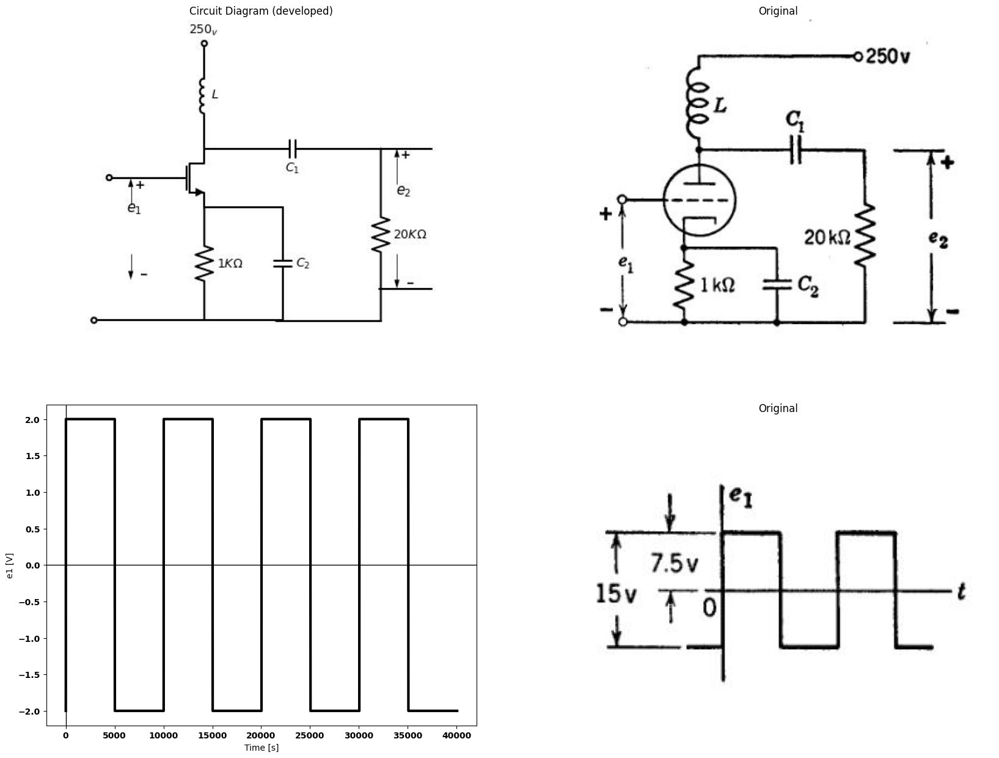

In [75]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().down(d.unit*1.08).label('$1KΩ$', 'bottom').at(M1.source))
l1 = d.add(elm.Line().right(d.unit*.75).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.08).label('$C_2$', 'bottom'))
l2 = d.add(elm.Line().left(d.unit*1.8).dot(open=True))
l3 = d.add(elm.Line().left(d.unit*.6).at(M1.gate).dot(open=True))
d += (C2 := elm.Capacitor().right(d.unit*1.68).label('$C_1$', 'bottom').at(M1.drain))
d += (R2 := elm.Resistor().down(d.unit*1.64).label('$20KΩ$', 'bottom'))
l4 = d.add(elm.Line().left(d.unit*1))
d += (L1 := elm.Inductor().up(d.unit*1.).label('$L$', 'bottom').label('$250_v$', 'right').at(M1.drain).dot(open=True))
l5 = d.add(elm.Line().right(d.unit*.5).at((5,0)))
l6 = d.add(elm.Line().right(d.unit*.5).at((5,-4)))
d += elm.Arrow().up().length(.75).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((-2.1,-1.6))
d += elm.Arrow().down().length(.75).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-2.1,-3))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-3.7,-3))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.5,-1))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.5,-3))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4,-2.5))
d.save('images/p8-38.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-38.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-38`a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=3) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-38b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

Application of a large grid signal causes the operating point to shift from  its quiescent value. Find the new operating point when a square wave of  15 volts peak-to-peak amplitude is applied to the grid. It may be assumed  that C₁ and C₂ are sufficiently large so that there is no variation in voltage  across their terminals during the signal cycle. Similarly, L is so large that there  is no current variation in the inductor during the signal cycle.  

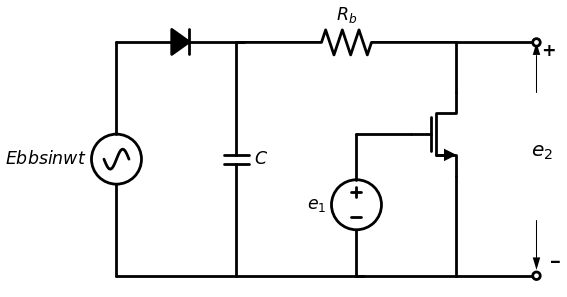

In [81]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().down(d.unit*1).at(M1.source))
    l2 = d.add(elm.Line().left(d.unit*1))
    V1 = d.add(elm.SourceV().up(d.unit*1.42).label('$e_1$', 'top'))
    l3 = d.add(elm.Line().right(d.unit*.55))
    l4 = d.add(elm.Line().up(d.unit*.5).at(M1.drain))
    d += (R1 := elm.Resistor().left(d.unit*2.2).label('$R_b$', 'top'))
    d += (C1 := elm.Capacitor().down(d.unit*2.34).label('$C$', 'bottom'))
    l5 = d.add(elm.Line().right(d.unit*1.28))
    l6 = d.add(elm.Line().left(d.unit*1.2).at(l5.start))
    V1 = d.add(elm.SourceSin().up(d.unit*2.345).label('$Ebb sin wt$', 'top'))
    l7 = d.add(elm.Diode(fill=True).right(d.unit*1.28))
    l8 = d.add(elm.Line().right(d.unit*.8).at(l4.end).dot(open=True))
    l9 = d.add(elm.Line().right(d.unit*.8).at(l1.end).dot(open=True))
    d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((1.6,0))
    d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((1.6,-2.55))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((0,-2))

![](images/p8-39.JPG)

8.43. A triode d-c amplifier has a plate supply voltage generated by a simple  rectifier as shown in Fig. P8.39. Use a piecewise-linear triode model.  
(a) Calculate the approximate peak-to-peak value of the ripple appearing  at the output e2. Notice that the amplitude of this hum or ripple will depend  upon the value of the d-c input voltage e1. Assume that C is large enough so that the diode conducts during a very small portion of the cycle.    
(b) For Ebb300 v, Rs 20 kilohms, rp = 10 kilohms, and w٫2 = 60  cycles, what capacitance would you use to keep the ripple below one-tenth  volt over the entire range of amplifier operation lying between cutoff and grid  current?  
(c) Where in the circuit would you insert an additional R and Cor an  additional L and C in order to obtain appreciable ripple reduction (or the same  ripple with smaller total capacitance)?  
8.44. In the circuit of Fig. P8.40, e1(t) is a square wave of period T, maximum value 0, and minimum value-2 volts. Sketch the operating path in the is vs. es plane and indicate the rates at which the instantaneous operating  point moves about on this locus. Assume that the period T is equal to twice  the time constant associated with C. and twenty times as large as the time   


Text(0.5, 1.0, 'Original')

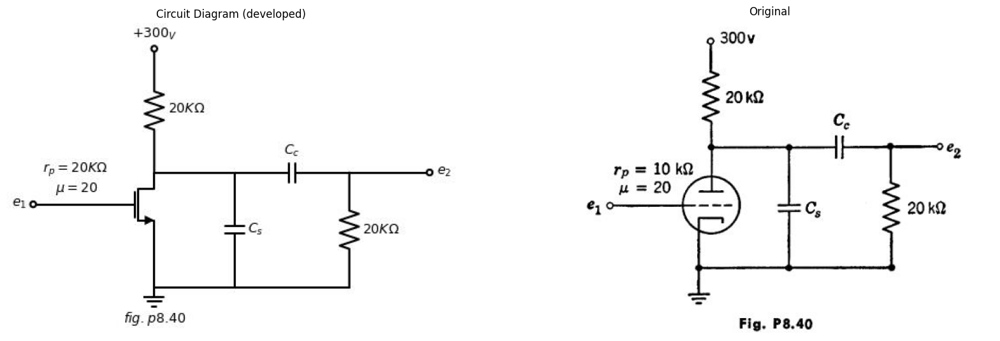

In [84]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().down(d.unit*.4).at(M1.source))
G = d.add(elm.Ground().at(l1.end).label('$fig.p8.40$', 'bottom'))
d += (R1 := elm.Resistor().up(d.unit*1.08).label('$20KΩ$', 'bottom').dot(open=True).label('$+300_V$', 'right').at(M1.drain))
l2 = d.add(elm.Line().left(d.unit*.75).at(M1.gate).label('$e_1$', 'left').dot(open=True).label('$r_p=20KΩ$\n $μ=20$', 'top'))
l3 = d.add(elm.Line().right(d.unit*.7).at(M1.drain))
d += (C1 := elm.Capacitor().down(d.unit*1).label('$C_s$', 'bottom'))
l4 = d.add(elm.Line().left(d.unit*.7))
d += (C2 := elm.Capacitor().right(d.unit*1).label('$C_c$', 'top').at(C1.start))
d += (R2 := elm.Resistor().down(d.unit*1).label('$20KΩ$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*1))
l6 = d.add(elm.Line().right(d.unit*.7).dot(open=True).label('$e_2$', 'right').at(R2.start))
d.save('images/p8-40;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-40;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-40.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

constant due to $C{8}$. Also sketch the actual a-c waveforms of es(t) and e₂(t)  superimposed upon the idealized waveform which would result for $C{c} = ∞$  and $C{8} = 0.$  
8.45. In Fig. P8.41:  
(a) How large must E be in order to cut off the tube during the pulse shown  in Fig. P8.42?  


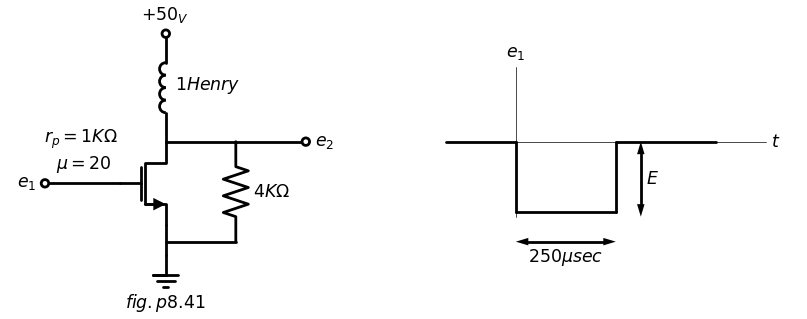

In [85]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().down(d.unit*.3).at(M1.source))
    G = d.add(elm.Ground().at(l1.end).label('$fig.p8.41$', 'bottom'))
    d += (R1 := elm.Inductor().up(d.unit*1.08).label('$1 Henry$', 'bottom').dot(open=True).label('$+50_V$', 'right').at(M1.drain))
    l2 = d.add(elm.Line().left(d.unit*.75).at(M1.gate).label('$e_1$', 'left').dot(open=True).label('$r_p=1KΩ$\n $μ=20$', 'top'))
    l3 = d.add(elm.Line().right(d.unit*.7).at(M1.drain))
    d += (R2 := elm.Resistor().down(d.unit*1).label('$4KΩ$', 'bottom'))
    l4 = d.add(elm.Line().left(d.unit*.7))
    l5 = d.add(elm.Line().right(d.unit*.7).dot(open=True).label('$e_2$', 'right').at(R2.start))
    l6 = d.add(elm.Line().right(d.unit*3).linewidth(.5).at((6,0)).label('$t$', 'right'))
    l7 = d.add(elm.Line().up(d.unit*1.5).linewidth(.5).at((7,-1.5)).label('$e_1$', 'right'))
    l8 = d.add(elm.Line().right(d.unit*.7).at((5.6,0)))
    l9 = d.add(elm.Line().down(d.unit*.7))
    l10 = d.add(elm.Line().right(d.unit*1))
    l11 = d.add(elm.Line().up(d.unit*.7))
    l12 = d.add(elm.Line().right(d.unit*1))
    d += elm.Arrow(double=True).right().length(2).color('black').label('$250 μ sec$', loc='bottom', color='black'). at((7,-2))
    d += elm.Arrow(double=True).up().length(1.5).color('black').label('$E$', loc='bottom', color='black'). at((9.5,-1.5))

![](images/p8-42.JPG)

(b) With E equal to or greater than the value found in part (a), sketch and  dimension the output voltage waveform.  
8.46. From Fig. P8.43, determine the amplification e2٫e1 in terms of the  circuit parameters. Neglect C. and the biasing filter (R&C) but not R2.  
8.47. Figure P8.44 shows an amplifier whose input is a negative 2-volt step.  
(a) Derive an incremental expression for the transient of eo.  
(b) By graphical construction determine the initial and final values for the  variation of e, and superimpose these on the solution to part (a).  
8.48. The amplifier in Fig. P8.45 is to deliver watt to the load. The  constraints are as given on page 414. 


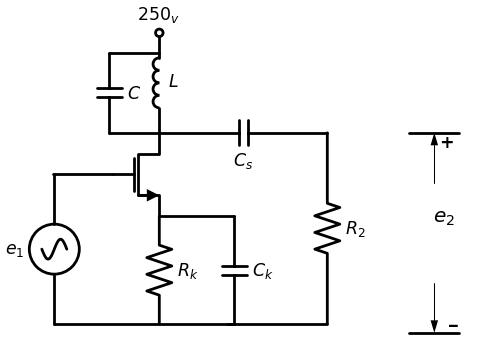

In [87]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (R1 := elm.Resistor().down(d.unit*1.08).label('$R_k$', 'bottom').at(M1.source))
    l1 = d.add(elm.Line().right(d.unit*.75).at(M1.source))
    d += (C1 := elm.Capacitor().down(d.unit*1.08).label('$C_k$', 'bottom'))
    l2 = d.add(elm.Line().left(d.unit*1.8))
    l3 = d.add(elm.Line().left(d.unit*.6).at(M1.gate))
    d += (C2 := elm.Capacitor().right(d.unit*1.68).label('$C_s$', 'bottom').at(M1.drain))
    d += (R2 := elm.Resistor().down(d.unit*1.91).label('$R_2$', 'bottom'))
    l4 = d.add(elm.Line().left(d.unit*1))
    d += (L1 := elm.Inductor().up(d.unit*1.).label('$L$', 'bottom').label('$250_v$', 'right').at(M1.drain).dot(open=True))
    l5 = d.add(elm.Line().right(d.unit*.5).at((5,0)))
    l6 = d.add(elm.Line().right(d.unit*.5).at((5,-4)))
    d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.5,-1))
    d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.5,-3))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4,-2.5))
    l7 = d.add(elm.Line().left(d.unit*.5).at(M1.drain))
    d += (C1 := elm.Capacitor().up(d.unit*.8).label('$C$', 'bottom'))
    l8 = d.add(elm.Line().right(d.unit*.5))
    V1 = d.add(elm.SourceSin().up(d.unit*1.5).label('$e_1$', 'top').at(l2.end))

![](images/p8-43.JPG)

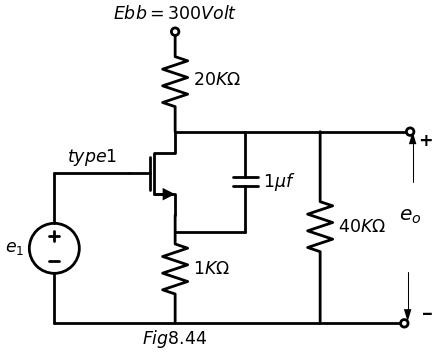

In [88]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (R1 := elm.Resistor().down(d.unit*1.08).label('$1KΩ$', 'bottom').at(M1.source).label('$Fig8.44$', 'left'))
    l1 = d.add(elm.Line().left(d.unit*.75).at(M1.gate).label('$type 1$', 'top'))
    V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').reverse())
    l2 = d.add(elm.Line().right(d.unit*3.5).dot(open=True))
    d += (R1 := elm.Resistor(). up(d.unit*1).label('$20KΩ$', 'bottom').at(M1.drain).dot(open=True).label('$Ebb=300Volt$', 'right'))
    l3 = d.add(elm.Line().right(d.unit*.7).at(M1.drain))
    d += (C1 := elm.Capacitor().down(d.unit*1).label('$1μf$', 'bottom'))
    l4 = d.add(elm.Line().left(d.unit*.7))
    l5 = d.add(elm.Line().right(d.unit*.75).at(C1.start))
    d += (R3 := elm.Resistor().down(d.unit*1.9).label('$40KΩ$', 'bottom'))
    l6 = d.add(elm.Line().right(d.unit*.9).dot(open=True).at(R3.start))
    d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((4.75,-1))
    d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4.65,-2.8))
    d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((3,-2.5))

![](images/p8-44.JPG)

(a) No grid current.  
(b) A minimum plate current of 3 ma.  
(c) A maximum d-c plate power dissipation of 2 watts.  
Determine E bb and n.  
8.49. Using a piecewise-linear model for the triode in the circuit shown in  Fig. P8.46 with $\mu = 25$ $r_{p} = 10$ kilohms, determine the operating point.  The signal source yields a sinusoidal voltage$ v {s} =6 cos wt$. Find the following:  
(a) The amplitude of the sinusoidal component of the anode voltage (the  so-called anode voltage swing).  
(b) The amplitude of the anode current swing.  


Text(0.5, 1.0, 'Original')

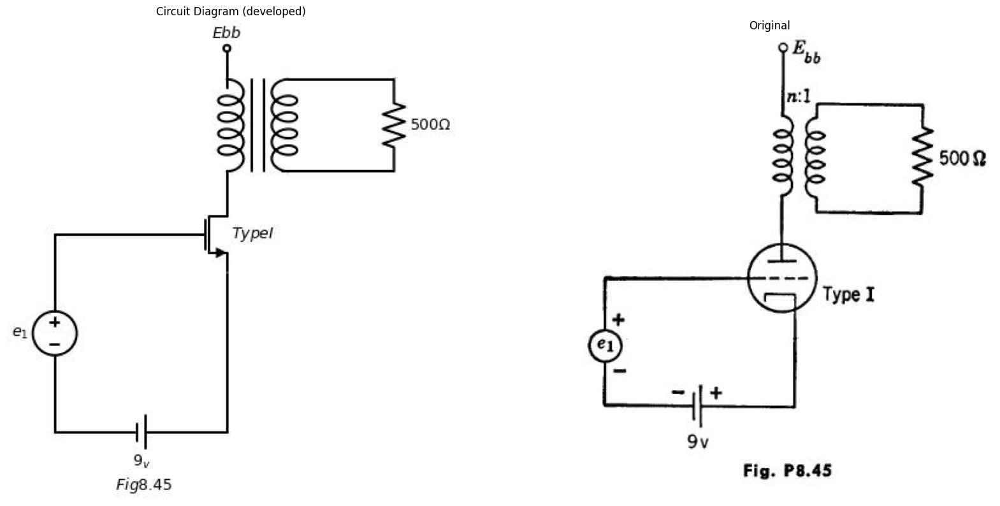

In [97]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$Type I$', 'right'))
l1 = d.add(elm.Line().up(d.unit*.2).at(M1.drain))
x = d.add(elm.Transformer(loop=True).at(l1.end).theta(0))
l2 = d.add(elm.Line().up(d.unit*.3).at((0,2.5)).dot(open=True).label('$Ebb$', 'right'))
l3 = d.add(elm.Line().right(d.unit*.8).at((1.4,2.7)))
d += (R1 := elm.Resistor().down(d.unit*.7).label('$500Ω$', 'bottom'))
l4 = d.add(elm.Line().left(d.unit*.85))
l5 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').reverse())
V2 = d.add(elm.BatteryCell().right(d.unit*1.31).label('$9_v$\n $Fig 8.45$', 'bottom').reverse())
l6 = d.add(elm.Line().up(d.unit*1.2))
d.save('images/p8-45f.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-45f.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-45.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(c) The signal power $P_{f}$ dissipated in $R_{a} $ 
(d) The total power dissipated in $R_{a}$  
(e) The total power $P_{t}$ delivered by the plate supply.  
(f) The power dissipated in the tube.  
(g) The efficiency$ P{s} /P{ t }$.  


Text(0.5, 1.0, 'Original')

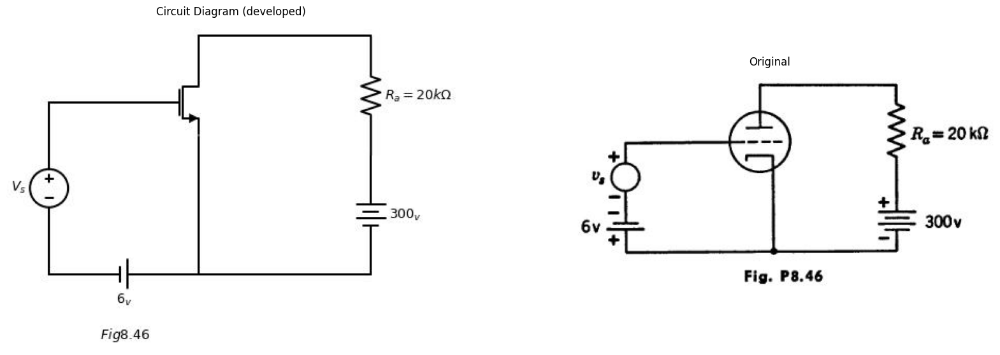

In [102]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$V_s$', 'top').reverse())
V2 = d.add(elm.BatteryCell().right(d.unit*1.3).label('$6_v$\n\n $Fig 8.46$', 'bottom').reverse())
l2 = d.add(elm.Line().up(d.unit*1.2))
l3 = d.add(elm.Line().up(d.unit*.3).at(M1.drain))
l4 = d.add(elm.Line().right(d.unit*1.5))
d += (R1 := elm.Resistor().down(d.unit*1.04).label('$R_a=20kΩ$', 'bottom'))
V3 = d.add(elm.Battery().down(d.unit*1.04).label('$300_v$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*1.5))
d.save('images/p8-46j.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-46j.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-46.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.50. The triode of Prob. 8.49 is coupled to the load by means of an ideal 1:1  transformer, as in Fig. P8.47. The value of $E {bb}$ is chosen so that the tube has  the same d - c operating point as in Prob. 8.49. Find, for the same $v_{a}$  
(a) The amplitude of the anode voltage swing.  
(b) The amplitude of the anode current swing.  
(c) The (a - c) power $P {s}$ dissipated in R. 


Text(0.5, 1.0, 'Original')

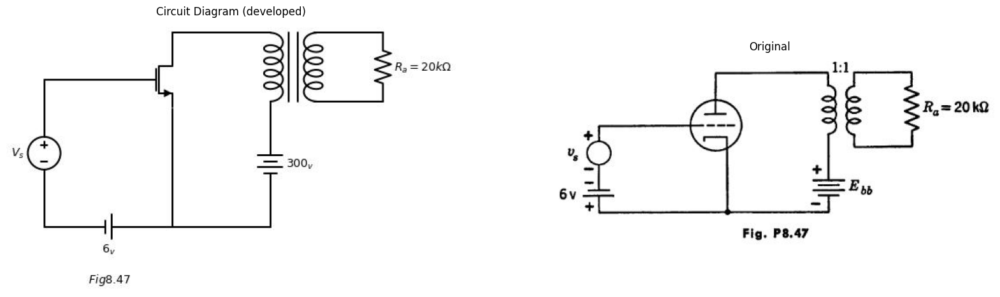

In [113]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$V_s$', 'top').reverse())
V2 = d.add(elm.BatteryCell().right(d.unit*1.31).label('$6_v$\n\n $Fig 8.47$', 'bottom').reverse())
l2 = d.add(elm.Line().up(d.unit*1.2))
l3 = d.add(elm.Line().up(d.unit*.2).at(M1.drain))
l4 = d.add(elm.Line().right(d.unit*1))
x = d.add(elm.Transformer(loop=True).at((3.01,-1.5)).theta(0))
V3 = d.add(elm.Battery().down(d.unit*1.28).label('$300_v$', 'bottom').at((3.01,-1.5)))
l5 = d.add(elm.Line().left(d.unit*1.5))
l6 = d.add(elm.Line().right(d.unit*.7).at((4.35,-1.5)))
d += (R1 := elm.Resistor().up(d.unit*.7).label('$R_a=20kΩ$', 'bottom'))
l7 = d.add(elm.Line().left(d.unit*.7))
d.save('images/p8-47j.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-47j.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-47.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(d) The power P. delivered by the plate supply.  
(e) The power dissipated in the tube.  
(f) The efficiency, $P{s}/Pt$.  


Text(0.5, 1.0, 'Original')

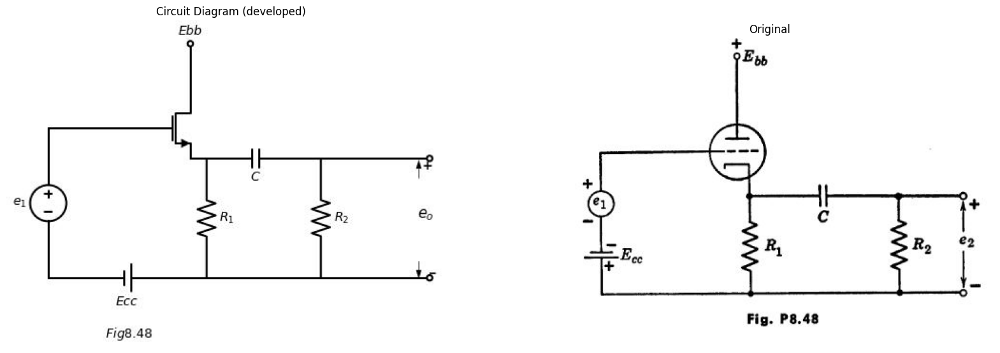

In [122]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.38).label('$e_1$', 'top').reverse())
V2 = d.add(elm.BatteryCell().right(d.unit*1.455).label('$Ecc$\n\n $Fig 8.48$', 'bottom').reverse())
d += (R1 := elm.Resistor().up(d.unit*1.1).label('$R_1$', 'bottom'))
d += (C1 := elm.Capacitor().right(d.unit*1.2).label('$C$', 'bottom').at(M1.source))
d += (R2 := elm.Resistor().down(d.unit*1.1).label('$R_2$', 'bottom'))
l2 = d.add(elm.Line().left(d.unit*1.2))
l3 = d.add(elm.Line().right(d.unit*1).at(R2.start).dot(open=True))
l4 = d.add(elm.Line().right(d.unit*1).at(R2.end).dot(open=True))
l5 = d.add(elm.Line().up(d.unit*.5).at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((6.3,-2.2))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.3,-4.5))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((4.8,-4.5))
d.save('images/p8-48j.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-48j.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-48.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.51. The triode shown in Fig. P8.48 is to be represented by an incremental  model. Operating conditions are such as to prevent flow of grid current.  
(a) Assume R. Calculate the incremental gain ez٫e, in terms of u,  
gm, and R1.  
(b) Find the value of R2 for which the gain e2٫61 is half of the value found  in (a).  
(c) From these results, find the internal resistance of the cathode-follower  circuit facing C and R2.  
(d) Check this value with the equivalent resistance of R₁ and$ r{p}/(\mu + 1)$ in  parallel. Neglect the effect of C.  


Text(0.5, 1.0, 'Original')

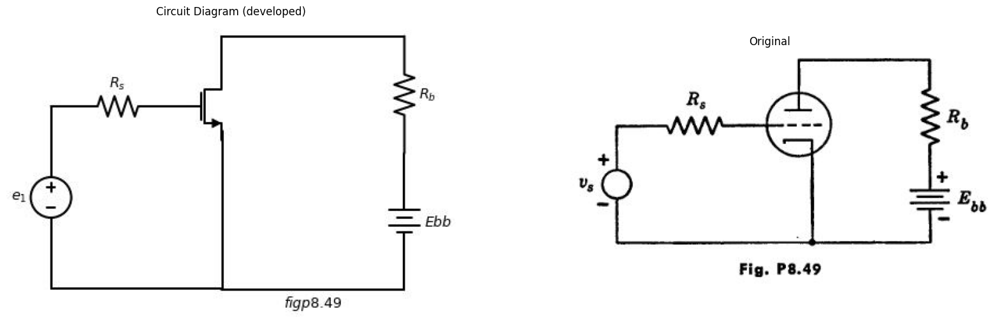

In [132]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().left(d.unit*1.1).label('$R_s$', 'top').at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').reverse())
l1 = d.add(elm.Line().right(d.unit*1.41))
l2 = d.add(elm.Line().up(d.unit*1.3))
l3 = d.add(elm.Line().up(d.unit*.3).at(M1.drain))
l4 = d.add(elm.Line().right(d.unit*1.5))
d += (R2 := elm.Resistor().down(d.unit*.965).label('$R_b$', 'bottom'))
V2 = d.add(elm.Battery().down(d.unit*1.12).label('$Ebb$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*1.5).label('$figp8.49$', 'bottom'))
d.save('images/p8-49j.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-49j.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-49.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.52. The triode shown in Fig. P8.49 has zero d-c bias at the grid. It is to  be represented by a piecewise-linear model. The value of R, is equal to ro  for the model. Sketch the anode voltage when the grid circuit is driven by a  sinusoidal voltage $v{s}$.  
8.53. From Fig. P8.50, sketch es as a function of time, when er is a sinusoidal  voltage. No grid current flows and the time constant RC is considerably  larger than the period of the input signal.  
8.54. In the circuit of Fig. P8.51 the triodes are Type I and the input wave- form is repetitive. Assume $r{g} $=1 kilohm for ec > 0. 


Text(0.5, 1.0, 'Original')

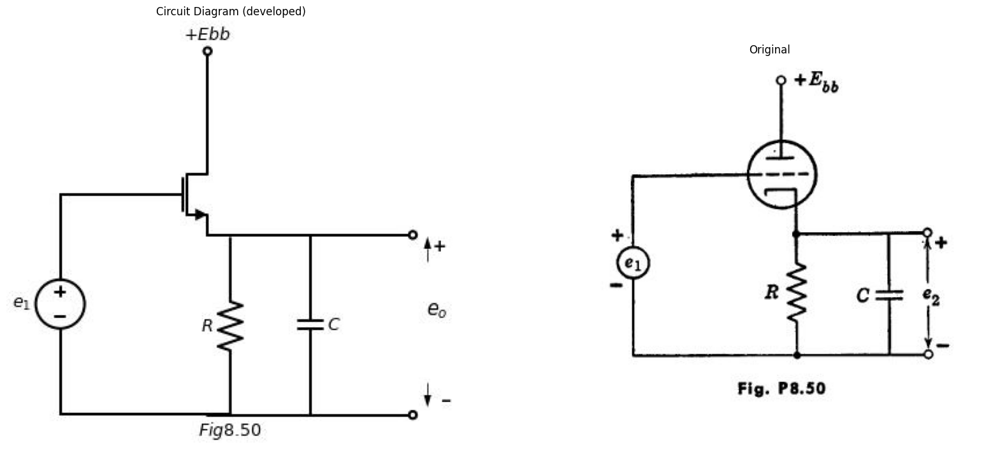

In [140]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().up(d.unit*.7).at(M1.drain).label('$+Ebb$', 'right').dot(open=True))
l2 = d.add(elm.Line().left(d.unit*.7).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').reverse())
l3 = d.add(elm.Line().right(d.unit*1.16))
d += (R1 := elm.Resistor().up(d.unit*1.2).label('$R$', 'top').label('$Fig8.50$', 'left'))
l4 = d.add(elm.Line().right(d.unit*.7).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.23).label('$C$', 'bottom'))
l5 = d.add(elm.Line().left(d.unit*.7))
l6 = d.add(elm.Line().right(d.unit*.7).at(C1.end).dot(open=True))
l7 = d.add(elm.Line().right(d.unit*.7).at(C1.start).dot(open=True))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((4.5,-2.2))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4.5,-4.7))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((3,-4.5))
d.save('images/p8-50;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-50;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-50.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(a) Determine the minimum value of Co that will maintain plate-current  cutoff in the first triode during interval $δ{s}$.  
(6) Determine values for $E{k}$ and C to cause the second triode to be driven  from plate-current cutoff to the grid-current point during the interval  $δ{s}$.     


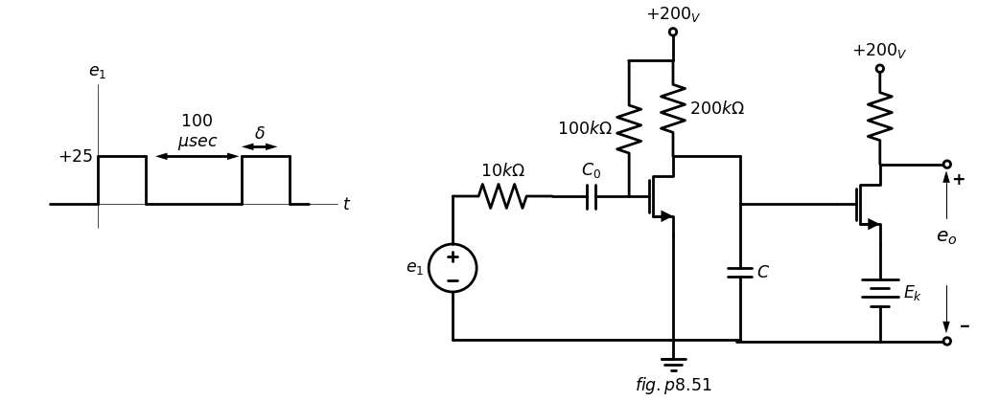

In [141]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (C1 := elm.Capacitor().left(d.unit*.8).label('$C_0$', 'top').at(M1.gate))
    d += (R1 := elm.Resistor().left(d.unit*1.04).label('$10kΩ$', 'top'))
    V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').reverse())
    l1 = d.add(elm.Line().right(d.unit*2.3))
    l2 = d.add(elm.Line().up(d.unit*1.1))
    G = d.add(elm.Ground().at(l2.start).label('$fig.p8.51$','bottom'))
    d += (R2 := elm.Resistor().up(d.unit*1.4).label('$100kΩ$', 'top').at(M1.gate))
    d += (R3 := elm.Resistor().up(d.unit*1).label('$200kΩ$', 'bottom').at(M1.drain))
    l3 = d.add(elm.Line().left(d.unit*.47))
    l4 = d.add(elm.Line().up(d.unit*.3).dot(open=True).label('$+200_V$', 'right').at(R3.end))
    l5 = d.add(elm.Line().right(d.unit*.7).at(M1.drain))
    l6 = d.add(elm.Line().down(d.unit*.5))
    d += (C1 := elm.Capacitor().down(d.unit*1.42).label('$C$', 'bottom'))
    l7 = d.add(elm.Line().left(d.unit*.75))
    l8 = d.add(elm.Line().right(d.unit*1).at(l6.end))
    d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    V2 = d.add(elm.Battery().down(d.unit*1.015).label('$E_k$', 'bottom').at(M2.source))
    l9 = d.add(elm.Line().left(d.unit*1.5))
    l10 = d.add(elm.Line().right(d.unit*.7).dot(open=True).at(V2.end))
    l11 = d.add(elm.Line().right(d.unit*.7).dot(open=True).at(M2.drain))
    d += (R4 := elm.Resistor().up(d.unit*1).label('$+200_V$', 'right').at(M2.drain).dot(open=True))
    d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.7,-1.3))
    d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.7,-2.7))
    d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((4,-2.5))
    l12 = d.add(elm.Line().right(d.unit*3).linewidth(.5).at((-13,-1)).label('$t$', 'right'))
    l13 = d.add(elm.Line().up(d.unit*1.5).linewidth(.5).at((-12,-1.5)).label('$e_1$', 'right'))
    l14 = d.add(elm.Line().right(d.unit*.5).at((-13,-1)))
    l15 = d.add(elm.Line().up(d.unit*.5))
    l16 = d.add(elm.Line().right(d.unit*.5).label('$+25$', 'left'))
    l17 = d.add(elm.Line().down(d.unit*.5))
    l18 = d.add(elm.Line().right(d.unit*1))
    l19 = d.add(elm.Line().up(d.unit*.5))
    l20 = d.add(elm.Line().right(d.unit*.5))
    l21 = d.add(elm.Line().down(d.unit*.5))
    l22 = d.add(elm.Line().right(d.unit*.2))
    d += elm.Arrow(double=True).right().length(1.75).color('black').label('$100$ \n$μ sec$', loc='top', color='black'). at((-10.8,0))
    d += elm.Arrow(double=True).right().length(.75).color('black').label('$\delta$', loc='top', color='black'). at((-9,.2))

![](images/p8-51.JPG)

assuming the capacitor C discharges essentially completely during the interval δ.


(c) What is the minimum value of 8 that will yield this condition?  
(d) Estimate the deviation from linearity of e(t) during the interval δ..  
8.55. A small-amplitude input signal $e1=d E1 cos wt$ is applied to the circuit  of Fig. P8.52. Assume that wR₂C and wL/R are very large. Sketch the  operating path in the is vs. es plane.  
8.56. In the circuit of Fig. P8.53 assume that the susceptances of stray and  interelectrode capacitances and the reactances of the large coupling capaci- tances C1, C2, and Ce are negligibly small. Use a piecewise-linear triode  model with$r{p}=d 10$ kilohms,$r{g}= 2 $kilohms, and gm 2000 microhms.  The input voltage en is a square wave of amplitude E1. The resulting output  voltage, under the above assumptions, is also a square wave, of amplitude E2.  
(a) For E10, show that the static operating point lies at the intersection  


Text(0.5, 1.0, 'Original')

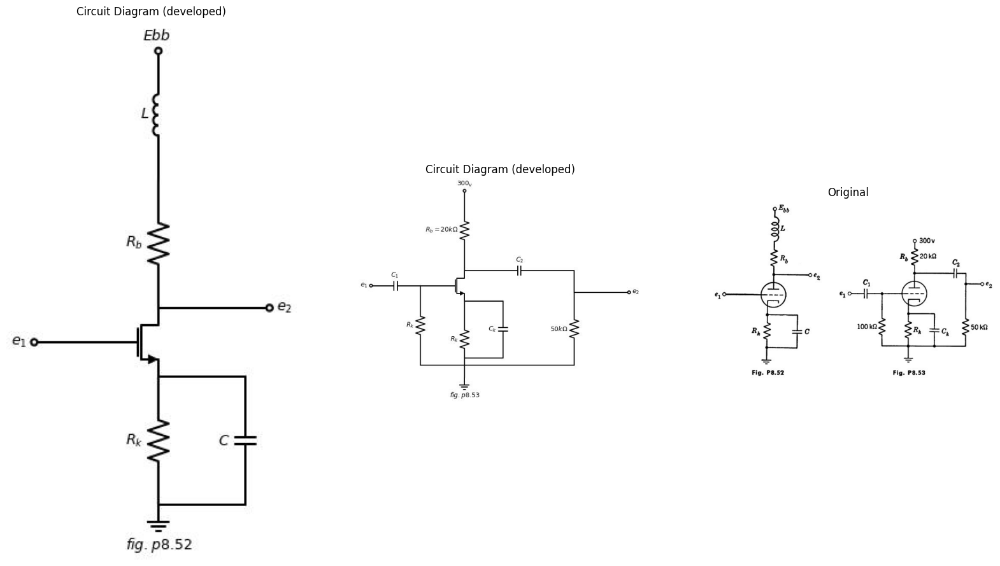

In [156]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 3, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().up(d.unit*1.04).label('$R_b$', 'top').at(M1.drain))
d += (L1 := elm.Inductor().up(d.unit*1.04).label('$L$', 'top').dot(open=True).label('$Ebb$', 'right'))
l1 = d.add(elm.Line().left(d.unit*.7).dot(open=True).label('$e_1$', 'left').at(M1.gate))
l2 = d.add(elm.Line().right(d.unit*.9).dot(open=True).label('$e_2$', 'right').at(M1.drain))
d += (R2 := elm.Resistor().down(d.unit*1.04).label('$R_k$', 'top').at(M1.source))
G = d.add(elm.Ground().at(R2.end).label('$fig.p8.52$','bottom'))
l3 = d.add(elm.Line().right(d.unit*.7).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.04).label('$C$', 'top').at(l3.end))
l4 = d.add(elm.Line().left(d.unit*.7))
d.save('images/p8-52;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-52;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().down(d.unit*1.4).label('$R_k$', 'top').at(M1.source))
G = d.add(elm.Ground().at(R1.end).label('$fig.p8.53$','bottom'))
l1 = d.add(elm.Line().right(d.unit*.7).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.04).label('$C_k$', 'top').at(l1.end))
l2 = d.add(elm.Line().left(d.unit*.7))
l3 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
d += (R2 := elm.Resistor().down(d.unit*1.45).label('$R_k$', 'top'))
l4 = d.add(elm.Line().right(d.unit*1))
d += (C2 := elm.Capacitor().left(d.unit*.9).label('$C_1$', 'top').at(R2.start).dot(open=True).label('$e_1$', 'left'))
d += (R3 := elm.Resistor().up(d.unit*1.45).label('$R_b=20kΩ$', 'top').dot(open=True).label('$300_v$', 'right').at(M1.drain))
d += (C3 := elm.Capacitor().right(d.unit*2).label('$C_2$', 'top').at(M1.drain))
l5 = d.add(elm.Line().down(d.unit*.4))
l6 = d.add(elm.Line().right(d.unit*1).dot(open=True).label('$e_2$', 'right'))
d += (R3 := elm.Resistor().down(d.unit*1.33).label('$50kΩ$', 'top').at(l6.start))
l7 = d.add(elm.Line().left(d.unit*1.85))
d.save('images/p8-53`a;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-53`a;.jpg')
axs[1].imshow(img)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-53.jpg')  # Load the PNG file
axs[2].imshow(img_sample)
axs[2].axis('off')  # Hide axes for image display
axs[2].set_title('Original')

of the d-c load line Esses (20+R)is and the d-e bias curve e + Rais =  
0. On the piecewise-linear plate curves, what is the slope of the bias curve in  terms of rp, u, and R?  
(b) Choose Rk so that the tube will reach cutoff and grid current for the  same value of E1. What is this value of E₁? Sketch and dimension the operat- ing path of the tube on the piecewise-linear plate curves.  
(c) Using the a-c incremental model, find the gain A = E2/E1.  
(d) With $R{k}$, plot E2 vs. E1. The grid circuit now acts as a rectifier.  Carry the plot beyond the value of E₁ for which cutoff occurs during the cycle. 


Text(0.5, 1.0, 'Original')

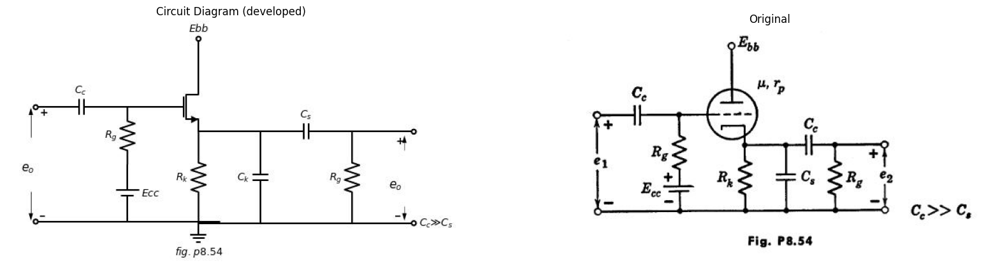

In [172]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().down(d.unit*1.04).label('$R_k$', 'top').at(M1.source))
G = d.add(elm.Ground().at(R1.end).label('$fig.p8.54$','bottom'))
l1 = d.add(elm.Line().right(d.unit*.7).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.04).label('$C_k$', 'top').at(l1.end))
l2 = d.add(elm.Line().left(d.unit*.7))
d += (C2 := elm.Capacitor().right(d.unit*1.04).label('$C_s$', 'top').at(l1.end))
d += (R2 := elm.Resistor().down(d.unit*1.04).label('$R_g$', 'top'))
l3 = d.add(elm.Line().left(d.unit*1.04))
l4 = d.add(elm.Line().right(d.unit*.7).dot(open=True).at(R2.start))
l5 = d.add(elm.Line().right(d.unit*.7).dot(open=True).at(R2.end).label('$C_c ≫ C_s$', 'right'))
l6 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
d += (R3 := elm.Resistor().down(d.unit*.65).label('$R_g$', 'top'))
V1 = d.add(elm.BatteryCell().down(d.unit*.65).label('$Ecc$', 'bottom'))
l7 = d.add(elm.Line().right(d.unit*1.04))
d += (C3 := elm.Capacitor().left(d.unit*1.04).label('$C_c$', 'top').at(R3.start).dot(open=True))
l8 = d.add(elm.Line().left(d.unit*1.04).dot(open=True).at(V1.end))
l8 = d.add(elm.Line().up(d.unit*.5).dot(open=True).at(M1.drain).label('$Ebb$', 'right'))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((-5.7,-1.85))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-5.7,-3.7))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((-7.5,-4.2))
d += elm.Arrow().up().length(.5).linewidth(.5).color('black').label('+',loc='end', color='black',ofst=.3). at((7,-2.3))
d += elm.Arrow().down().length(.5).linewidth(.5).color('black').label(r'_', loc='end', color='black',ofst=(-.5, -.3)). at((7,-4.2))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((5,-4.8))
d.save('images/p8-54;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-54;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-54.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.57. The circuit of Fig. P8.54 is a cathode-follower amplifier with a total  effective shunt capacitance $C_s$.  
(a) What is the midband gain De₂/Ae1?  
(b) What is the lower half-power frequency w₁?  
(c) What is the upper half-power frequency w2?
(d) Sketch and dimension log |E2/E1| vs. log w over the region of interest.  
8.58. Find the operating point for the Type II triode in the circuit of Fig.  P8.55. Find the incremental parameters of the tube at this operating point.  


Use the incremental parameters to find the amplitude and phase of the a-c  
components of is, es, and ex that are developed when a small sinusoidal signal  


Text(0.5, 1.0, 'Original')

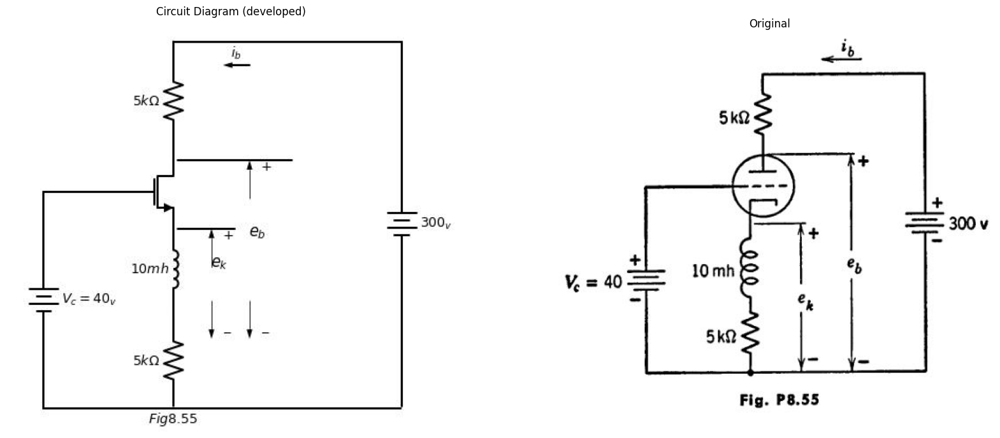

In [13]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
d += (R1 := elm.Resistor().up(d.unit*1.04).label('$5kΩ$', 'top').at(M1.drain))
d += (L1 := elm.Inductor().down(d.unit*.8).label('$10mh$', 'top').at(M1.source))
d += (R2 := elm.Resistor().down(d.unit*.8).label('$5kΩ$', 'top').label('$Fig8.55$', 'left'))
l1 = d.add(elm.Line().left(d.unit*.83).at(M1.gate))
V1 = d.add(elm.Battery().down(d.unit*1.9).label('$V_c=40_v$', 'bottom'))
l2 = d.add(elm.Line().right(d.unit*3.13))
l3 = d.add(elm.Line().right(d.unit*2).at(R1.end))
V = d.add(elm.Battery().down(d.unit*3.2).label('$300_v$', 'bottom'))
d += elm.Arrow().left().length(.7).color('black').label('$i_b$', loc='top', color='black'). at((2,2.5))
l4 = d.add(elm.Line().right(d.unit*1).at((0.1,0)))
l5 = d.add(elm.Line().right(d.unit*.5).at((0.1,-1.8)))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((2,-1))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((2,-3.7))
d += elm.Gap().up().label(  '$e_b$' , ofst=-1.7 , fontsize = 16).color('black').at((.5,-3.2))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((1,-2.8))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((1,-3.7))
d += elm.Gap().up().label(  '$e_k$' , ofst=-1.7 , fontsize = 16).color('black').at((-.5,-4))
d.save('images/p8-55f;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-55f;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-55.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

$ e_0 $ sin wt is connected in series with the voltage source$ V{c}$. Summarize your  results by drawing an appropriate vector diagram.  
The sinusoidal signal connected in series with V. is replaced by a step  function generator which produces a one-volt step at 10. Employing  incremental analysis, find the expression for es as a function of time. 


Text(0.5, 1.0, 'Original')

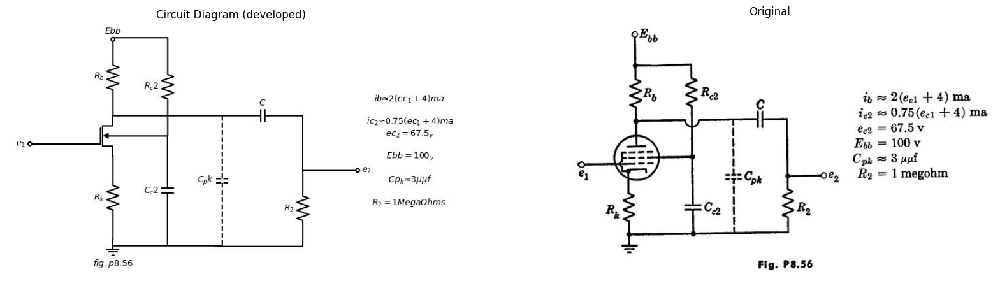

In [29]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(bulk=True).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.83).at(M1.gate).dot(open=True).label('$e_1$', 'left'))
d += (R1 := elm.Resistor().down(d.unit*1.14).label('$R_k$', 'top').at(M1.source))
G = d.add(elm.Ground().at(R1.end).label('$fig.p8.56$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.75).at(M1.bulk))
d += (C1 := elm.Capacitor().down(d.unit*1.5).label('$C_c2$', 'top'))
l3 = d.add(elm.Line().left(d.unit*.75))
d += (R2 := elm.Resistor().up(d.unit*1.04).label('$R_b$', 'top').at(M1.drain).dot(open=True).label('$Ebb$', 'right'))
d += (R3 := elm.Resistor().up(d.unit*1.34).label('$R_c2$', 'top').at(C1.start))
l4 = d.add(elm.Line().left(d.unit*.75))
l5 = d.add(elm.Line().right(d.unit*1.5).at(M1.drain))
d += (C2 := elm.Capacitor().down(d.unit*1.78).label('$C_pk$', 'top').linestyle('--'))
l6 = d.add(elm.Line().left(d.unit*.75))
d += (C3 := elm.Capacitor().right(d.unit*1.1).label('$C$', 'top').at(C2.start))
l7 = d.add(elm.Line().down(d.unit*.75))
l8 = d.add(elm.Line().right(d.unit*.75).dot(open=True).label('$e_2$', 'right'))
d += (R4 := elm.Resistor().down(d.unit*1.04).label('$R_2$', 'top').at(l8.start))
l9 = d.add(elm.Line().left(d.unit*1.2))
l10 = d.add(elm.Line().right(d.unit*.1).at((12,1)).color('white').label('$ib≈2(ec_1+4)ma$\n\n $ic_2≈ 0.75(ec_1 + 4)ma$\n $ec_2=67.5_v$\n\n $Ebb=100_v$\n\n $Cp_k≈ 3μμf$\n\n$R_2=1Mega Ohms$', 'bottom',color='black'))
d.save('images/p8-56j;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-56j;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-56.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.59. The pentode circuit shown in Fig. P8.56 is to be used to amplify  rectangular pulses of duration T and height E1. Choose Rk and Re2 so that  the quiescent operating point (e1 = 0) lies halfway between ec1  cutoff and so that ec1 = 67.5 volts.  
(a) With Ce2 and C assumed arbitrarily large, the output voltage e₂ rises  with a time constant 7, toward a value E2, in response to the leading edge of  a negative pulse of height E1. Discuss the choice of Rs for maximum gain  


A=E2/E1 and minimum rise time $\tau {r}$. For a gain of 12.5, what are $R{b}$ and  T? What are the quiescent values of plate voltage and plate current? What  is the minimum pulse length T which can be amplified with reasonable fidelity?  (b) Still assuming Ce2 arbitrarily large, but ignoring Cpk, explain the effect  of C upon the shape of the output voltage response when a very long pulse  is applied. Suggest approximate values for Ce2 and C such that a pulse 100 µsec  in length shall not droop by more than 20 per cent.  

Text(0.5, 1.0, 'Original')

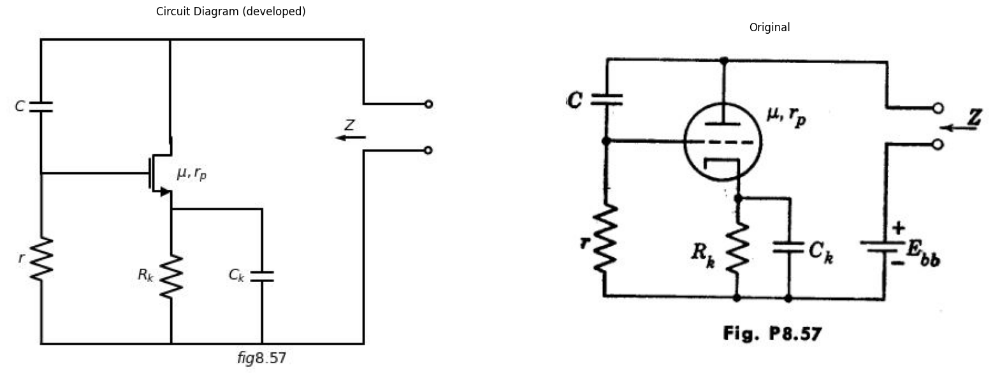

In [49]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse().label('$μ,r_p$', 'right'))
d += (R1 := elm.Resistor().down(d.unit*1.04).label('$R_k$', 'top').at(M1.source))
l1 = d.add(elm.Line().right(d.unit*.7).at(M1.source))
d += (C1 := elm.Capacitor().down(d.unit*1.04).label('$C_k$', 'top').at(l1.end).label('$fig8.57$', 'left'))
l2 = d.add(elm.Line().left(d.unit*.7))
l3 = d.add(elm.Line().left(d.unit*.7).at(M1.gate))
d += (R2 := elm.Resistor().down(d.unit*1.32).label('$r$', 'top'))
l4 = d.add(elm.Line().right(d.unit*1.2))
d += (C2 := elm.Capacitor().up(d.unit*1.04).label('$C$', 'top').at(R2.start))
l5 = d.add(elm.Line().right(d.unit*1))
l6 = d.add(elm.Line().down(d.unit*.8))
l7= d.add(elm.Line().right(d.unit*1.5).at(l6.start))
l8 = d.add(elm.Line().down(d.unit*.5))
l9 = d.add(elm.Line().right(d.unit*.5).dot(open=True))
l10 = d.add(elm.Line().right(d.unit*.79).at(C1.end))
l11 = d.add(elm.Line().up(d.unit*1.5))
l12 = d.add(elm.Line().right(d.unit*.5).dot(open=True))
d += elm.Arrow().left().length(.7).color('black').label('$Z$', loc='top', color='black'). at((4.5,0))
d.save('images/p8-57j;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-57j;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-57.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

8.60. Determine the incremental impedance Z for Fig. P8.57. Neglect the  bias filter $RkCk$. 

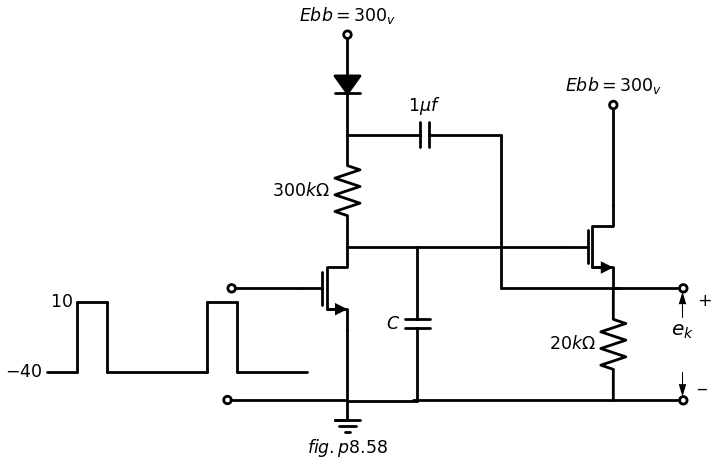

In [50]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().down(d.unit*.7).at(M1.source))
    l2 = d.add(elm.Line().left(d.unit*.7).at(M1.gate).dot(open=True))
    l3 = d.add(elm.Line().left(d.unit*1.2).dot(open=True).at(l1.end))
    G = d.add(elm.Ground().at(l1.end).label('$fig.p8.58$','bottom'))
    l4 = d.add(elm.Line().right(d.unit*.7).at(M1.drain))
    d += (C1 := elm.Capacitor().down(d.unit*1.54).label('$C$', 'top'))
    l5 = d.add(elm.Line().left(d.unit*.7))
    l6 = d.add(elm.Line().right(d.unit*1.5).at(C1.start))
    d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    d += (R1 := elm.Resistor().down(d.unit*1.12).label('$20kΩ$', 'top').at(M2.source))
    l7 = d.add(elm.Line().left(d.unit*2))
    l8 = d.add(elm.Line().right(d.unit*.7).dot(open=True).at(R1.start))
    l9 = d.add(elm.Line().right(d.unit*.7).dot(open=True).at(R1.end))
    d += (R2 := elm.Resistor().up(d.unit*1.12).label('$300kΩ$', 'top').at(M1.drain))
    d += (C2 := elm.Capacitor().right(d.unit*1.54).label('$1μf$', 'top'))
    l10 = d.add(elm.Line().down(d.unit*1.53))
    l11 = d.add(elm.Line().right(d.unit*1.2))
    D1 = d.add(elm.Diode(fill=True).up().reverse().at(R2.end).dot(open=True).label('$Ebb=300_v$','right'))
    l12 = d.add(elm.Line().up(d.unit*1).dot(open=True).label('$Ebb=300_v$','right').at(M2.drain))
    l13 = d.add(elm.Line().right(d.unit*.3).at((-6,-2.5)).label('$-40$','left'))
    l14 = d.add(elm.Line().up(d.unit*.7))
    l15 = d.add(elm.Line().right(d.unit*.3).label('$10$','left'))
    l16 = d.add(elm.Line().down(d.unit*.7))
    l17 = d.add(elm.Line().right(d.unit*1))
    l18 = d.add(elm.Line().up(d.unit*.7))
    l19 = d.add(elm.Line().right(d.unit*.3))
    l20 = d.add(elm.Line().down(d.unit*.7))
    l21 = d.add(elm.Line().right(d.unit*.7))
    d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6.7,-1.4))
    d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.7,-2.5))
    d += elm.Gap().up().label(  '$e_k$' , ofst=-1.7 , fontsize = 16).color('black').at((5,-2.5))

![](images/p8-58.JPG)

8.61. The circuit of Fig. P8.58 is expected to yield a nearly linear sweep  voltage during the interval 8, 100 usec.  by a piecewise-linear model with μ = 20, 7,  
(a) What is the maximum linear sweep  output terminals?  
(6) What value of C will yield this amplitude E, in the interval 8. = 100  usec?  
(c) What is the sweep linearity? (Ratio of slope att 8, to slope at t = 0.)  
8.62. The circuit shown in Fig. P8.59 is to be used as a frequency meter.  Input voltage consists of a square wave that alternately drives the grid voltage  to zero and beyond plate-current cutoff. The diodes have a resistance of  1 kilohm when conducting. The milliammeter may be assumed to indicate   average current and the meter resistance is included in the 1-kilohm resistor  shown. The effects of tube and wiring capacitances may be neglected.  


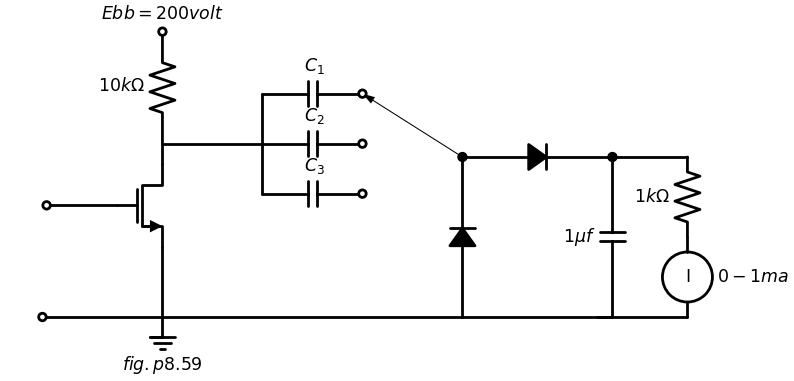

In [53]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().down(d.unit*.7).at(M1.source))
    l2 = d.add(elm.Line().left(d.unit*.7).at(M1.gate).dot(open=True))
    l3 = d.add(elm.Line().left(d.unit*1.2).at(l1.end).dot(open=True))
    G = d.add(elm.Ground().at(l1.end).label('$fig.p8.59$','bottom'))
    l4 = d.add(elm.Line().up(d.unit*.2).at(M1.drain))
    d += (R1 := elm.Resistor().up(d.unit*1.12).label('$10kΩ$', 'top').at(l4.end).dot(open=True).label('$Ebb=200volt$','right'))
    l5 = d.add(elm.Line().right(d.unit*1).at(l4.end))
    l6 = d.add(elm.Line().up(d.unit*.5))
    l7 = d.add(elm.Line().down(d.unit*.5).at(l6.start))
    d += (C1 := elm.Capacitor().right(d.unit*1).label('$C_2$', 'top').at(l5.end).dot(open=True))
    d += (C2 := elm.Capacitor().right(d.unit*1).label('$C_1$', 'top').at(l6.end).dot(open=True))
    d += (C3 := elm.Capacitor().right(d.unit*1).label('$C_3$', 'top').at(l7.end).dot(open=True))
    l8 = d.add(elm.Line().right(d.unit*3).at(l1.end))
    D1 = d.add(elm.Diode(fill=True).up(d.unit*1.6).dot())
    d += elm.Arrow().up().length(.5).linewidth(.75).color('black').endpoints(D1.end,C2.end)
    D2 = d.add(elm.Diode(fill=True).right(d.unit*1.5).dot().at(D1.end))
    d += (C4 := elm.Capacitor().down(d.unit*1.6).label('$1μf$', 'top'))
    l9 = d.add(elm.Line().left(d.unit*1.5))
    l10 = d.add(elm.Line().right(d.unit*.75).at(C4.start))
    d += (R2 := elm.Resistor().down(d.unit*.8).label('$1kΩ$', 'top'))
    V = d.add(elm.MeterI().down(d.unit*.8).label('$0-1 ma$', 'bottom'))
    l11 = d.add(elm.Line().left(d.unit*.9))

![](images/p8-59.JPG)

Determine the values of C1, C2, and C3 required to yield full-scale meter  deflection for input frequencies of 105, 104, and 103 cps, respectively.  
8.63. Referring to Problem 8.62, assume the milliammeter to be linear and  to have a scale that can be read to within 0.5 per cent of the full scale reading.  
Determine the maximum percentage error in frequency determination resulting from an assumed linear relationship between frequency and meter current.  
Determine and plot a correction curve (deviation from linearity versus per  cent of full scale deflection) for the high-frequency scale. Is the same curve  applicable to the other two scales.  
8.64. The triodes in the circuit of Fig. P8.60 are Type I. Sketch and dimen- sion the waveform of voltage es for input waveforms e₁ and e₂ as shown. The  diodes may be assumed to have 1-kilohm forward resistance and infinite back  resistance.  
8.65. The 2:1 step-down transformer in the circuit of Fig. P8.61 has a  magnetizing inductance L_{m} = 100 mh referred to the primary winding.  Neglecting the effects of leakage inductance and stray capacitances, sketch  and dimension the waveform of output voltage e2. The 2-usec input pulses  occur at a repetition frequency of 500 per second.  
8.66. The triode in the circuit of Fig. P8.62(a) can be represented by a  simple piecewise-linear model with mu = 20 r_{p} = 10 kilohms, and r_{g} = 1 kil- ohm. The 2:1 turns-ratio pulse transformer magnetizing inductance  L_{m} = 100 mh referred to the primary winding. Leakage inductance and  stray capacitance can be neglected.  
The desired output is the repetitive flat-topped waveform shown in Fig.  P8.62(b).  
(a) Sketch and dimension a suitable input waveform to yield the flat- topped output pulse.  
(b) Determine the amplitude and time constant of the negative overshoot  on the output waveform, 
 


Text(0.5, 1.0, 'Original')

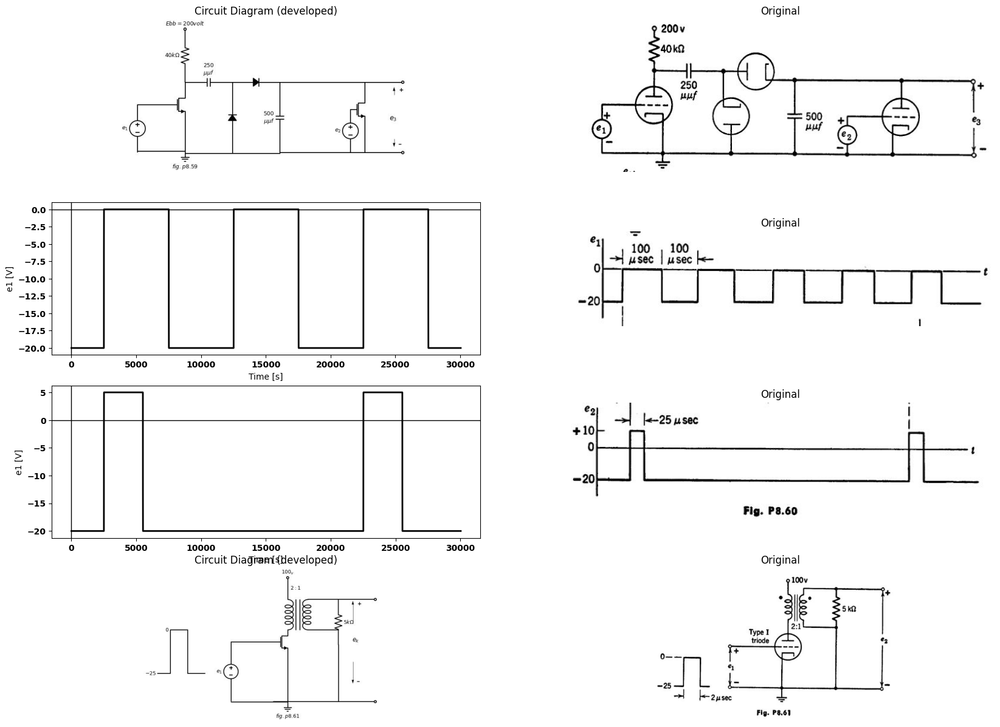

In [82]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().down(d.unit*.7).at(M1.source))
l2 = d.add(elm.Line().left(d.unit*.7).at(M1.gate))
l3 = d.add(elm.Line().left(d.unit*1).at(l1.end))
G = d.add(elm.Ground().at(l1.end).label('$fig.p8.59$','bottom'))
l4 = d.add(elm.Line().up(d.unit*.2).at(M1.drain))
d += (R1 := elm.Resistor().up(d.unit*1.12).label('$40kΩ$', 'top').at(l4.end).dot(open=True).label('$Ebb=200volt$','right'))
d += (C1 := elm.Capacitor().right(d.unit*1).label('$250$\n$μμf$', 'top').at(l4.end))
V1 = d.add(elm.SourceV().down(d.unit*1).label('$e_1$', 'top').reverse().at(l2.end))
D1 = d.add(elm.Diode(fill=True).right(d.unit*1).at(C1.end))
D2 = d.add(elm.Diode(fill=True).down(d.unit*1.5).at(C1.end).reverse())
l5 = d.add(elm.Line().left(d.unit*1))
d += (C2 := elm.Capacitor().down(d.unit*1.5).label('$500$\n$μμf$', 'top').at(D1.end))
l6 = d.add(elm.Line().left(d.unit*1))
l7 = d.add(elm.Line().right(d.unit*1.8).at(C2.start))
l8 = d.add(elm.Line().down(d.unit*.3))
d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l9 = d.add(elm.Line().down(d.unit*.63).at(M2.source))
l10 = d.add(elm.Line().left(d.unit*1.8))
V2 = d.add(elm.SourceV().down(d.unit*.9).label('$e_2$', 'top').reverse().at(M2.gate))
l11 = d.add(elm.Line().right(d.unit*.8).dot(open=True).at(l7.end))
l12 = d.add(elm.Line().right(d.unit*.8).dot(open=True).at(l9.end))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((13.25,-.2))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((13.25,-3))
d += elm.Gap().up().label(  '$e_3$' , ofst=-1.7 , fontsize = 16).color('black').at((11.5,-3))
d.save('images/p8-60j;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-60j;.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-60.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-20@u_V, pulsed_value=0@u_V,delay_time=2.5@u_ms, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-60b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-20@u_V, pulsed_value=5@u_V,delay_time=2.5@u_ms, pulse_width=3@u_ms, period=20@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[2,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[2,0].set_xlabel('Time [s]')
axs[2,0].set_ylabel('e1 [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p8-60c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.36).label('$e_1$', 'top').reverse())
l2 = d.add(elm.Line().down(d.unit*1.1).at(M1.source))
l3 = d.add(elm.Line().left(d.unit*1.3))
l4 = d.add(elm.Line().up(d.unit*.5).dot(open=True).at((0,2.1)).label('$100_v$','right').label('$   2:1$','bottom'))
x = d.add(elm.Transformer(loop=True).at((.01,0)).theta(0))
l5 = d.add(elm.Line().right(d.unit*.7).at((1.4,0)))
l6 = d.add(elm.Line().right(d.unit*.7).at((1.4,2.1)))
d += (R1 := elm.Resistor().down(d.unit*1.04).label('$5kΩ$', 'bottom').at(l6.end))
l7 = d.add(elm.Line().down(d.unit*1.31).at(R1.end))
l8 = d.add(elm.Line().left(d.unit*1.5))
l9 = d.add(elm.Line().right(d.unit*.85).at(R1.start).dot(open=True))
l10 = d.add(elm.Line().right(d.unit*.85).at(l7.end).dot(open=True))
d += elm.Arrow().up().length(1.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((4.5,0.5))
d += elm.Arrow().down().length(1.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4.5,-2.2))
d += elm.Gap().up().label(  '$e_k$' , ofst=-1.7 , fontsize = 16).color('black').at((3,-2))
G = d.add(elm.Ground().at(l2.end).label('$fig.p8.61$','bottom'))
l11 = d.add(elm.Line().right(d.unit*.3).at((-9,-3)).label('$-25$', 'left'))
l12 = d.add(elm.Line().up(d.unit*1))
l13 = d.add(elm.Line().right(d.unit*.4).label('$0$', 'left'))
l14 = d.add(elm.Line().down(d.unit*1))
l15 = d.add(elm.Line().right(d.unit*.4))
d.save('images/p8-60j;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-60j;.jpg')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-61.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

Text(0.5, 1.0, 'Original')

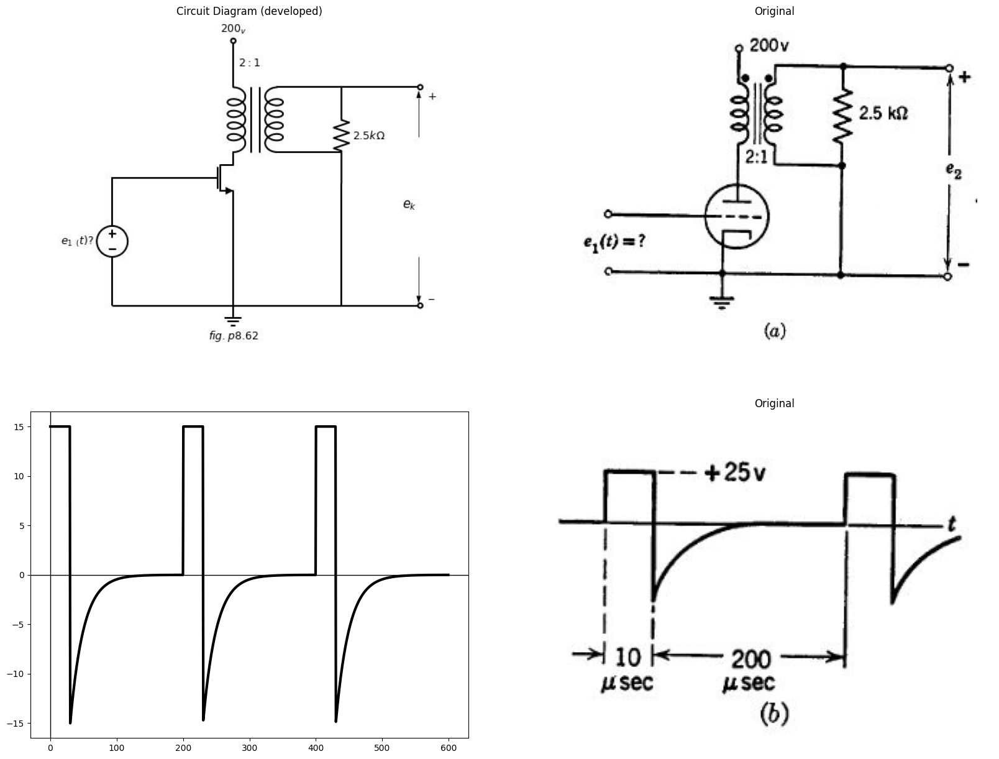

In [8]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
V1 = d.add(elm.SourceV().down(d.unit*1.37).label('$e_1$ $_(t)?$', 'top').reverse())
l2 = d.add(elm.Line().down(d.unit*1.1).at(M1.source))
l3 = d.add(elm.Line().left(d.unit*1.3))
l4 = d.add(elm.Line().up(d.unit*.5).dot(open=True).at((0,2.1)).label('$200_v$','right').label('$   2:1$','bottom'))
x = d.add(elm.Transformer(loop=True).at((.01,0)).theta(0))
l5 = d.add(elm.Line().right(d.unit*.7).at((1.4,0)))
l6 = d.add(elm.Line().right(d.unit*.7).at((1.4,2.1)))
d += (R1 := elm.Resistor().down(d.unit*1.04).label('$2.5kΩ$', 'bottom').at(l6.end))
l7 = d.add(elm.Line().down(d.unit*1.315).at(R1.end))
l8 = d.add(elm.Line().left(d.unit*1.5))
l9 = d.add(elm.Line().right(d.unit*.85).at(R1.start).dot(open=True))
l10 = d.add(elm.Line().right(d.unit*.85).at(l7.end).dot(open=True))
d += elm.Arrow().up().length(1.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6,0.5))
d += elm.Arrow().down().length(1.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6,-3.4))
d += elm.Gap().up().label(  '$e_k$' , ofst=-1.7 , fontsize = 16).color('black').at((4,-3))
G = d.add(elm.Ground().at(l2.end).label('$fig.p8.62$','bottom'))
d.save('images/p8-62j;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-62j;.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-62a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')

# Parameters
pulse_width = 30  # microseconds
period = 200  # microseconds
amplitude = 15  # Volts
time_constant = 20 # microseconds (example value, adjust as needed)
decay_start = pulse_width

# Time array
t = np.linspace(0, 3 * period, 1000, endpoint=False)  # Plotting three periods

# Waveform generation
waveform = np.zeros_like(t)

for i in range(3):  # Repeat for three periods
    # Pulse
    waveform[(t >= i * period) & (t < i * period + pulse_width)] = amplitude

    # Exponential decay
    decay_indices = (t >= i * period + decay_start) & (t < (i + 1) * period)
    time_since_decay = t[decay_indices] - (i * period + decay_start)
    waveform[decay_indices] = -amplitude * np.exp(-time_since_decay / time_constant)

axs[1,0].plot(t, waveform,color='black', linewidth=3)
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-62bb.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

8.67. Using the Type I triode curves, plot the locus of the operating point  in the $i{b}$ vs.$ e{b}$ plane of the first stage of the circuit shown in Fig. P8.63.  Assume $L{m} =100 mh$ as seen from the primary of the $2:1$ pulse transformer.  

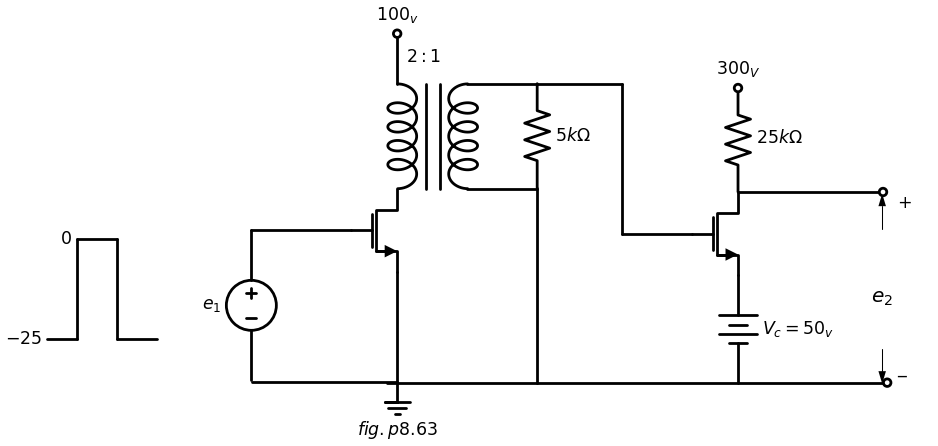

In [11]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
    V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').reverse())
    l2 = d.add(elm.Line().down(d.unit*1.1).at(M1.source))
    l3 = d.add(elm.Line().left(d.unit*1.45))
    l4 = d.add(elm.Line().up(d.unit*.5).dot(open=True).at((0,2.1)).label('$100_v$','right').label('$   2:1$','bottom'))
    x = d.add(elm.Transformer(loop=True).at((.01,0)).theta(0))
    l5 = d.add(elm.Line().right(d.unit*.7).at((1.4,0)))
    l6 = d.add(elm.Line().right(d.unit*.7).at((1.4,2.1)))
    d += (R1 := elm.Resistor().down(d.unit*1.04).label('$5kΩ$', 'bottom').at(l6.end))
    l7 = d.add(elm.Line().down(d.unit*1.95).at(R1.end))
    l8 = d.add(elm.Line().left(d.unit*1.5))
    l9 = d.add(elm.Line().right(d.unit*.85).at(R1.start))
    l10 = d.add(elm.Line().right(d.unit*3.5).at(l7.end).dot(open=True))
    d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((9.7,-0.8))
    d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((9.7,-3.2))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((8,-3))
    G = d.add(elm.Ground().at(l2.end).label('$fig.p8.63$','bottom'))
    l11 = d.add(elm.Line().right(d.unit*.3).at((-7,-3)).label('$-25$', 'left'))
    l12 = d.add(elm.Line().up(d.unit*1))
    l13 = d.add(elm.Line().right(d.unit*.4).label('$0$', 'left'))
    l14 = d.add(elm.Line().down(d.unit*1))
    l15 = d.add(elm.Line().right(d.unit*.4))
    l16 = d.add(elm.Line().down(d.unit*1.5).at(l9.end))
    l17 = d.add(elm.Line().right(d.unit*.7))
    d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    V1 = d.add(elm.Battery().down(d.unit*1.08).label('$V_c=50_v$', 'bottom').at(M2.source))
    d += (R2 := elm.Resistor().up(d.unit*1.04).label('$25kΩ$', 'bottom').at(M2.drain).dot(open=True).label('$300_V$', 'right'))
    l18 = d.add(elm.Line().right(d.unit*1.45).at(M2.drain).dot(open=True))

![](images/p8-63.JPG)

Neglect leakage inductances and stray capacitances. The input waveform  shown has a repetition rate of 1000 per second. Assume $r{g}= 1$ kilohm for  $ec ≥ 0.$  
8.68. The input voltage en for the circuit of Fig. P8.64 cuts off T', for an  interval $r{s} = 100$ usec and during the remainder of the 1000 $\mu$ sec repetition  interval T₁ conducts with grid-cathode voltage equal to zero. The push-pull  output, direct-coupled to the cathode-ray tube deflection plates, is required  to produce a properly centered 4-inch sweep deflection. (Deflection factor  is 50 volts per inch.) Using the Type I triode characteristics determine  graphically the required value of Es and calculate the value of C required.  
8.69. The ringing circuit shown in Fig. P8.65 is coupled to a cathode follower  to minimize loading of the tuned circuit. The rectangular input wave en has  a repetition frequency of 5000 cycles per second. Type I triodes are used. 


(a) Determine the values of L and C required to produce a ringing oscilla- tion which has a frequency of 100 kc and a peak-to-peak amplitude of 100 volts  (neglecting damping) at the output e2.  
(b) Determine the proper position for the bias tap on the cathode follower  load resistor (total Rx 10 kilohms) to avoid clipping.  
(c) Determine the minimum amplitude E required of the input pulse.  
(d) Determine the additional circuit elements required to provide the  ringing tube plate voltage (100 volts) from a 200-volt supply.  


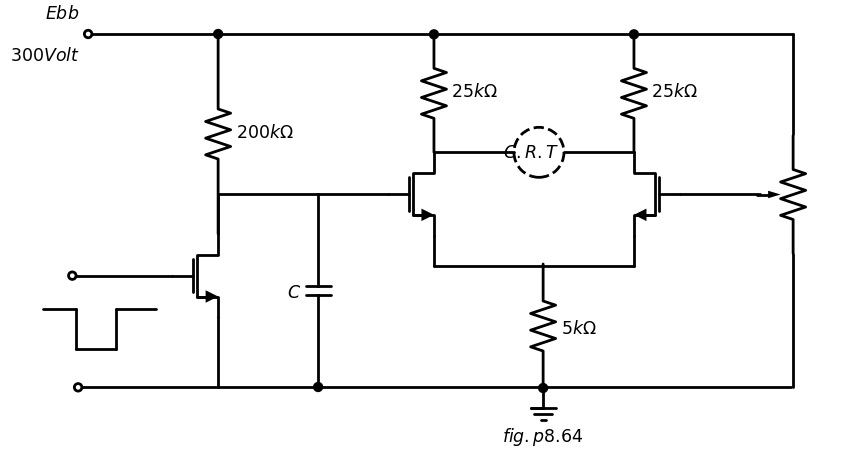

In [13]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().left(d.unit*1).at(M1.gate).dot(open=True))
    l2 = d.add(elm.Line().down(d.unit*.7).at(M1.source))
    l3 = d.add(elm.Line().left(d.unit*1.4).dot(open=True))
    l4 = d.add(elm.Line().up(d.unit*.4).at(M1.drain))
    l5 = d.add(elm.Line().right(d.unit*1))
    d += (C1 := elm.Capacitor().down(d.unit*1.93).label('$C$', 'top').dot())
    l6 = d.add(elm.Line().right(d.unit*5.73).at(l2.end))
    l7 = d.add(elm.Line().right(d.unit*.7).at(l5.end))
    d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    l8 = d.add(elm.Line().down(d.unit*.3).at(M2.source))
    l9 = d.add(elm.Line().right(d.unit*2))
    l10 = d.add(elm.Line().up(d.unit*.3))
    d += (M3 := elm.AnalogNFet(offset_gate = False).anchor('source').theta(0))
    d += (R1 := elm.Resistor().down(d.unit*1.24).label('$5kΩ$', 'bottom').at((6.5,-.6)).dot())
    l11 = d.add(elm.Line().right(d.unit*.8).at(M2.drain))
    V1 = d.add(elm.Source().right(d.unit*.3).linestyle('--'))
    l12 = d.add(elm.Line().left(d.unit*.7).at(M3.drain).label('$C.R.T$','left'))
    d += (R2 := elm.Resistor().up(d.unit*2).label('$200kΩ$', 'bottom').at(M1.drain).dot())
    d += (R3 := elm.Resistor().up(d.unit*1.18).label('$25kΩ$', 'bottom').at(M2.drain).dot())
    d += (R4 := elm.Resistor().up(d.unit*1.18).label('$25kΩ$', 'bottom').at(M3.drain).dot())
    l13 = d.add(elm.Line().left(d.unit*1.3).at(R2.end).label('$Ebb$\n\n$300Volt$','left').dot(open=True))
    l14 = d.add(elm.Line().right(d.unit*5.75).at(R2.end))
    l15 = d.add(elm.Line().right(d.unit*.8).at(M3.gate))
    d += (R5 := elm.PotentiometerIEEE().up(d.unit*1.18).at((11.5,-.39)))
    l16 = d.add(elm.Line().down(d.unit*1).at(l14.end))
    l17 = d.add(elm.Line().down(d.unit*1.33).at(R5.start))
    l18 = d.add(elm.Line().right(d.unit*.33).at((-3.5,-1.5)))
    l19 = d.add(elm.Line().down(d.unit*.4))
    l20 = d.add(elm.Line().right(d.unit*.4))
    l21 = d.add(elm.Line().up(d.unit*.4))
    l22 = d.add(elm.Line().right(d.unit*.4))
    G = d.add(elm.Ground().at(R1.end).label('$fig.p8.64$','bottom'))

![](images/p8-64.JPG)

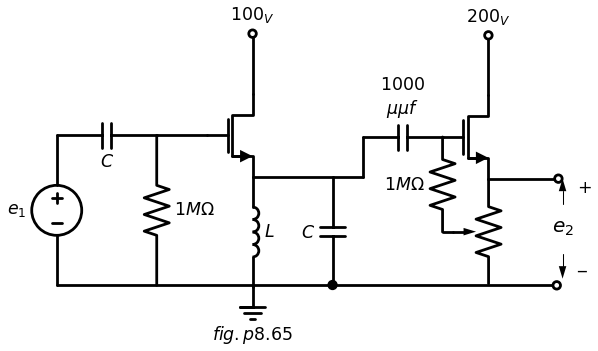

In [19]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (L1 := elm.Inductor().down(d.unit*1.1).label('$L$', 'bottom').at(M1.source))
    l1 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
    d += (R1 := elm.Resistor().down(d.unit*1.5).label('$1MΩ$', 'bottom').at(l1.end))
    d += (C1 := elm.Capacitor().left(d.unit*1).label('$C$', 'bottom').at(R1.start))
    V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').reverse())
    l2 = d.add(elm.Line().right(d.unit*5).at(V1.end).dot(open=True))
    l3 = d.add(elm.Line().up(d.unit*.6).at(M1.drain).label('$100_V$', 'right').dot(open=True))
    l4 = d.add(elm.Line().right(d.unit*.8).at(M1.source))
    d += (C1 := elm.Capacitor().down(d.unit*1.08).label('$C$', 'top').dot())
    l5 = d.add(elm.Line().right(d.unit*.3).at(C1.start))
    l6 = d.add(elm.Line().up(d.unit*.4))
    C1 = d.add(elm.Capacitor().right(d.unit*.8).label('$1000$\n$μμf$', 'top'))
    d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    d += (R4 := elm.Resistor().down(d.unit*.95).label('$1MΩ$', 'top').at(M2.gate))
    d += (R3 := elm.PotentiometerIEEE().up(d.unit*1.04).at((4.72,-3.8)))
    l7 = d.add(elm.Line().right(d.unit*.1).at(R4.end))
    l8 = d.add(elm.Line().up(d.unit*.6).at(M2.drain).label('$200_V$', 'right').dot(open=True))
    l9 = d.add(elm.Line().right(d.unit*.7).at(M2.source).dot(open=True))
    d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6.2,-2.2))
    d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.2,-3.2))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4.5,-3.5))
    G = d.add(elm.Ground().at(L1.end).label('$fig.p8.65$','bottom'))

![](images/p8-65.JPG)

8.70. Assume the diode in the circuit of Fig. P8.66 to be ideal (forward  resistance zero and back resistance infinite). At $t =0$, current in the induct- ance Lis I, and capacitor voltages are zero. Sketch and dimension the wave- forms of e1 and e₂ for t > 0.  
8.71. The 100-µsec rectangular input pulse for the ringing circuit shown in  Fig. P8.67 has a repetition frequency of 2000 cps. The output voltage is  to be squared and peaked to form timing markers from the positive-going  edge of each ringing cycle.  


Text(0.5, 1.0, 'Original')

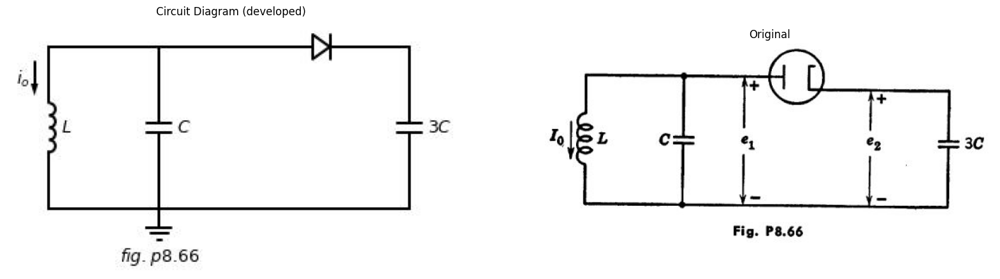

In [21]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (L1 := elm.Inductor().down(d.unit*1.1).label('$L$', 'bottom'))
l1 = d.add(elm.Line().right(d.unit*.75).at(L1.start))
d += (C1 := elm.Capacitor().down(d.unit*1.1).label('$C$', 'bottom'))
l2 = d.add(elm.Line().left(d.unit*.75))
l3 = d.add(elm.Line().right(d.unit*.5).at(l1.end))
d += (D1 := elm.Diode().right(d.unit*1.2))
d += (C2 := elm.Capacitor().down(d.unit*1.1).label('$3C$', 'bottom'))
l4 = d.add(elm.Line().left(d.unit*2))
d += elm.Arrow().down().length(0.7).at((-0.3, -0.3)).color('black').label('$i_o$','top')
G = d.add(elm.Ground().at(C1.end).label('$fig.p8.66$','bottom'))
d.save('images/p8-66j;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-66j;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-66.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

(a) What value of C is required to produce pulses at 10- $\mu$sec intervals?  
(b) What is the minimum value of input pulse amplitude E necessary for  satisfactory operation? 


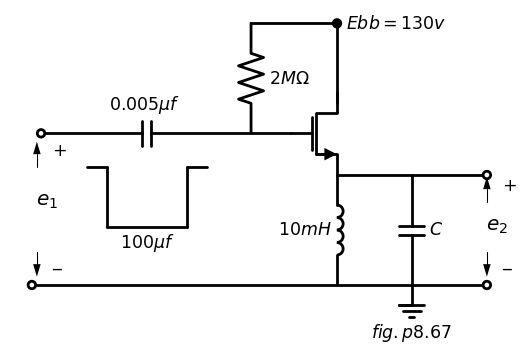

In [23]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (L1 := elm.Inductor().down(d.unit*1.1).label('$10 mH$', 'top').at(M1.source))
    l1 = d.add(elm.Line().right(d.unit*.75).at(L1.start))
    d += (C1 := elm.Capacitor().down(d.unit*1.1).label('$C$', 'bottom').at(l1.end))
    l2 = d.add(elm.Line().left(d.unit*3.8).dot(open=True))
    l3 = d.add(elm.Line().left(d.unit*.4).at(M1.gate))
    d += (C2 := elm.Capacitor().left(d.unit*2.1).label('$0.005μf$', 'top').at(l3.end).dot(open=True))
    d += (R1 := elm.Resistor().up(d.unit*1.1).label('$2MΩ$', 'bottom').at(l3.end))
    l4 = d.add(elm.Line().right(d.unit*.86).dot().label('$Ebb=130v$', 'right'))
    l5 = d.add(elm.Line().down(d.unit*.8))
    d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((-6,-1.5))
    d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-6,-3.2))
    d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-7.5,-3))
    l6 = d.add(elm.Line().right(d.unit*.2).at((-5,-1.5)))
    l7 = d.add(elm.Line().down(d.unit*.6))
    l8 = d.add(elm.Line().right(d.unit*.8).label('$100μf$', 'bottom'))
    l9 = d.add(elm.Line().up(d.unit*.6))
    l10 = d.add(elm.Line().right(d.unit*.2))
    l11 = d.add(elm.Line().right(d.unit*.75).dot(open=True).at(C1.start))
    l12 = d.add(elm.Line().right(d.unit*.75).dot(open=True).at(C1.end))
    d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((3,-2.2))
    d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((3,-3.2))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((1.5,-3.5))
    G = d.add(elm.Ground().at(C1.end).label('$fig.p8.67$','bottom'))

![](images/p8-67.JPG)

8.72. In the circuit shown in Fig. P8.68, current through the deflection coil is  required to vary linearly with time from 10 ma to 110 ma during the interval  
= 100 usec. The repetition interval is Tr = 1000 µsec.  
Using the Type I triode and Type II pentode characteristics, determine the  values of R and C required in the sweep generator circuit.  
8.73. Sketch and dimension the output voltage waveform e₂(t) for the circuit  shown in Fig. P8.69. Magnetizing inductance seen from the primary of trans- former T1 is Lm 100 mh. Neglect leakage inductances and stray capaci- tances. Assumer, 1 kilohm for ec>0. The diode has 1 kilohm forward  resistance and infinite back resistance.  
8.74. From the circuit given in Fig. P8.70, find, for the curve |A (jw)|,  
(a) resonant frequency (cps);  
(b) Q;  
(c) bandwidth (cps);  
(d) A at resonance.  
8.75. An inductor is representable by a pure inductance L in series with a  resistance RL. Consider the impedance Z (jw) of the parallel combination of  the inductor, a pure capacitance C, and a resistance Rc. Let $w{o}=\frac {1}{\sqrt {LC}}  $



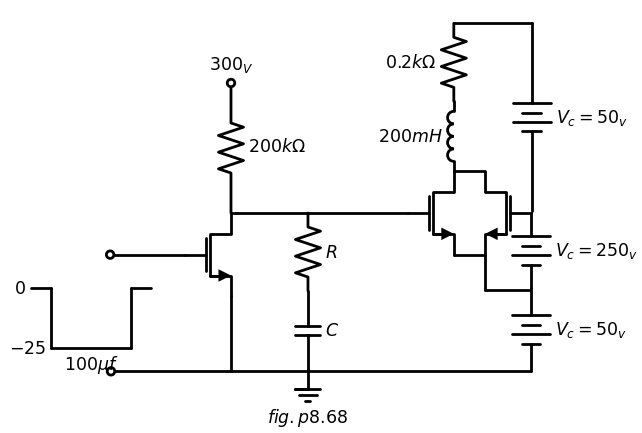

In [24]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().left(d.unit*.75).at(M1.gate).dot(open=True))
    l2 = d.add(elm.Line().down(d.unit*.75).at(M1.source))
    l3 = d.add(elm.Line().left(d.unit*1.2).dot(open=True))
    d += (R1 := elm.Resistor().up(d.unit*1.3).label('$200kΩ$', 'bottom').at(M1.drain).dot(open=True).label('$300_V$', 'right'))
    l4 = d.add(elm.Line().right(d.unit*.77).at(M1.drain))
    d += (R2 := elm.Resistor().down(d.unit*.78).label('$R$', 'bottom'))
    d += (C1 := elm.Capacitor().down(d.unit*.78).label('$C$', 'bottom'))
    l5 = d.add(elm.Line().right(d.unit*3).at(l2.end))
    l6 = d.add(elm.Line().right(d.unit*1).at(R2.start))
    d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    d += (M3 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).at((6,0)))
    l7 = d.add(elm.Line().right(d.unit*.3).at(M2.drain))
    l8 = d.add(elm.Line().right(d.unit*.3).at(M2.source))
    l9 = d.add(elm.Line().down(d.unit*.35).at(M3.source))
    l10 = d.add(elm.Line().right(d.unit*.45))
    V1 = d.add(elm.Battery().down(d.unit*.75).label('$V_c=250_v$', 'bottom').at(M3.gate))
    V2 = d.add(elm.Battery().down(d.unit*.83).label('$V_c=50_v$', 'bottom'))
    d += (L1 := elm.Inductor().up(d.unit*.7).label('$200 mH$', 'top').at(M2.drain))
    d += (R3 := elm.Resistor().up(d.unit*.78).label('$0.2kΩ$', 'top'))
    l11 = d.add(elm.Line().right(d.unit*.78))
    V3 = d.add(elm.Battery().down(d.unit*1.88).label('$V_c=50_v$', 'bottom'))
    G = d.add(elm.Ground().at(C1.end).label('$fig.p8.68$','bottom'))
    l12 = d.add(elm.Line().right(d.unit*.2).at((-4,-1.5)).label('$0$', 'left'))
    l13 = d.add(elm.Line().down(d.unit*.6))
    l14 = d.add(elm.Line().right(d.unit*.8).label('$100μf$', 'bottom').label('$-25$', 'left'))
    l15 = d.add(elm.Line().up(d.unit*.6))
    l16 = d.add(elm.Line().right(d.unit*.2))

![](images/p8-68.JPG)

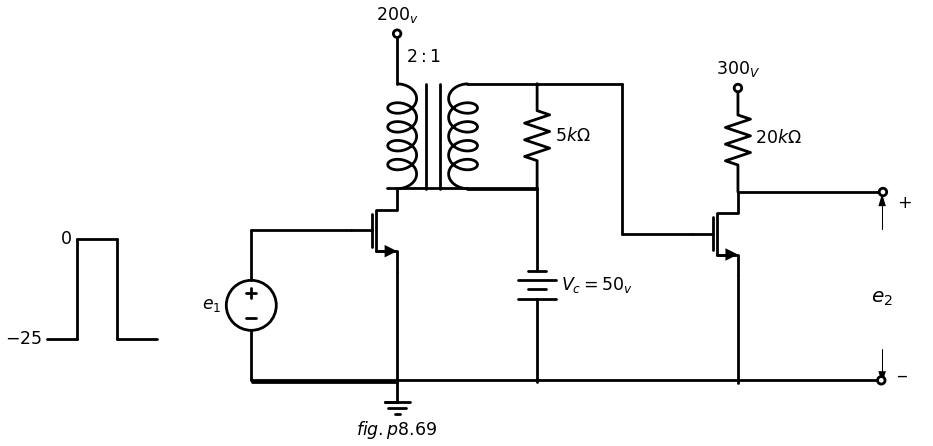

In [25]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    l1 = d.add(elm.Line().left(d.unit*1).at(M1.gate))
    V1 = d.add(elm.SourceV().down(d.unit*1.5).label('$e_1$', 'top').reverse())
    l2 = d.add(elm.Line().down(d.unit*1.1).at(M1.source))
    l3 = d.add(elm.Line().left(d.unit*1.45))
    l4 = d.add(elm.Line().up(d.unit*.5).dot(open=True).at((0,2.1)).label('$200_v$','right').label('$   2:1$','bottom'))
    x = d.add(elm.Transformer(loop=True).at((.01,0)).theta(0))
    l5 = d.add(elm.Line().right(d.unit*.7).at((1.4,0)))
    l6 = d.add(elm.Line().right(d.unit*.7).at((1.4,2.1)))
    d += (R1 := elm.Resistor().down(d.unit*1.04).label('$5kΩ$', 'bottom').at(l6.end))
    #l7 = d.add(elm.Line().down(d.unit*1.95).at(R1.end))
    l8 = d.add(elm.Line().left(d.unit*1.5))
    l9 = d.add(elm.Line().right(d.unit*.85).at(R1.start))
    l10 = d.add(elm.Line().right(d.unit*6.3).at(V1.end).dot(open=True))
    d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((9.7,-0.8))
    d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((9.7,-3.2))
    d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((8,-3))
    G = d.add(elm.Ground().at(l2.end).label('$fig.p8.69$','bottom'))
    l11 = d.add(elm.Line().right(d.unit*.3).at((-7,-3)).label('$-25$', 'left'))
    l12 = d.add(elm.Line().up(d.unit*1))
    l13 = d.add(elm.Line().right(d.unit*.4).label('$0$', 'left'))
    l14 = d.add(elm.Line().down(d.unit*1))
    l15 = d.add(elm.Line().right(d.unit*.4))
    l16 = d.add(elm.Line().down(d.unit*1.5).at(l9.end))
    l17 = d.add(elm.Line().right(d.unit*.7))
    d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    V1 = d.add(elm.Battery().down(d.unit*1.94).label('$V_c=50_v$', 'bottom').at(R1.end).reverse())
    d += (R2 := elm.Resistor().up(d.unit*1.04).label('$20kΩ$', 'bottom').at(M2.drain).dot(open=True).label('$300_V$', 'right'))
    l18 = d.add(elm.Line().right(d.unit*1.45).at(M2.drain).dot(open=True))
    l19 = d.add(elm.Line().down(d.unit*1.08).at(M2.source))

![](images/p8-69.JPG)

Text(0.5, 1.0, 'Original')

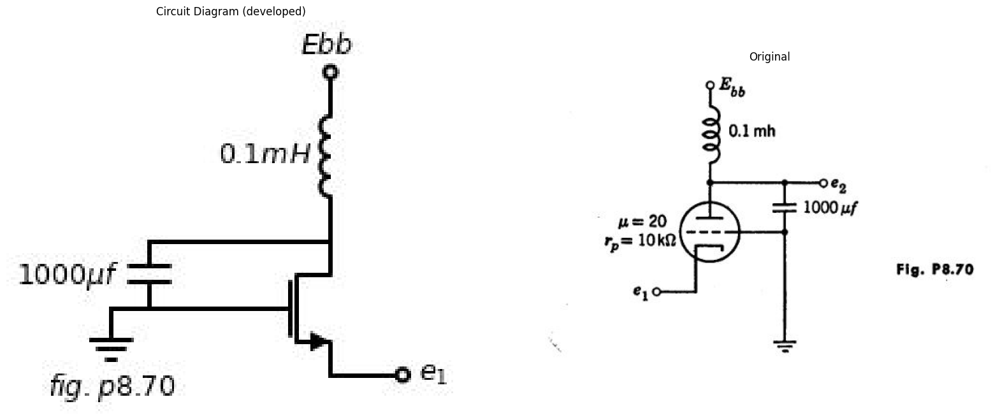

In [30]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
import schemdraw
from scipy import signal
from scipy.signal import butter, lfilter, buttord, freqz
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(20, 15))
d = schemdraw.Drawing()
d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
l1 = d.add(elm.Line().left(d.unit*.6).at(M1.gate))
G = d.add(elm.Ground().at(l1.end).label('$fig.p8.70$','bottom'))
l2 = d.add(elm.Line().right(d.unit*.3).at(M1.source).dot(open=True).label('$e_1$','right'))
d += (L1 := elm.Inductor().up(d.unit*.7).label('$0.1 mH$', 'top').at(M1.drain).dot(open=True).label('$Ebb$','right'))
l3 = d.add(elm.Line().left(d.unit*.75).at(M1.drain))
d += (C1 := elm.Capacitor().down(d.unit*.27).label('$1000μf$', 'top').at(l3.end))
d.save('images/p8-70j;.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('images/p8-70j;.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p8-70.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

$R{o} = \sqrt {LC}$ , and assume $R{L}<< R{o} << R{c}. For frequencies near w{0} show that 

$$Z(jw)= \frac {R_0 .Q}{1+ jQ(\frac{w}{w0}- \frac {w0}{w})}≈ \frac {R_0 .Q}{1+ j2Q(\frac{w}{w0}- 1)} $$


Where $$\frac {1}{Q}= \frac {1}{Q_L}+ \frac {1}{Q_c} , Q_L = \frac {R_o}{R_L}, Q_c = \frac {R_c}{R_o}$$

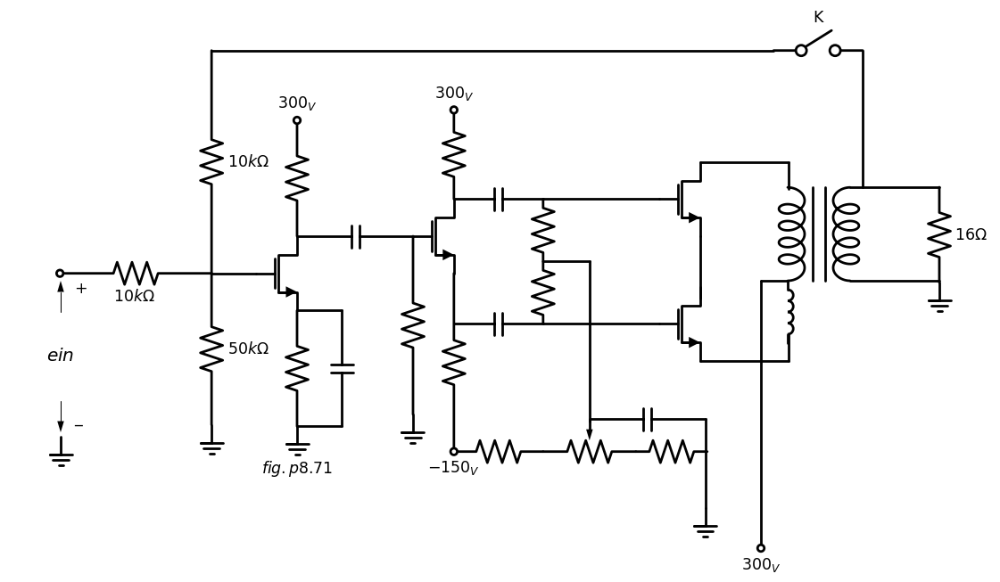

In [31]:
import schemdraw
import schemdraw.elements as elm
import matplotlib.pyplot as plt
from schemdraw import dsp
from schemdraw import logic
with schemdraw.Drawing(unit=2) as d:
    d += (M1 := elm.AnalogNFet(offset_gate = False).anchor('drain').theta(0).reverse())
    d += (R1 := elm.Resistor().up(d.unit*1.3).at(M1.drain).dot(open=True).label('$300_V$', 'right'))
    d += (R2 := elm.Resistor().down(d.unit*1.3).at(M1.source))
    l1 = d.add(elm.Line().right(d.unit*.5).at(M1.source))
    d += (C1 := elm.Capacitor().down(d.unit*1.3))
    l2 = d.add(elm.Line().left(d.unit*.5))
    l3 = d.add(elm.Line().left(d.unit*.5).at(M1.gate))
    d += (R3 := elm.Resistor().up(d.unit*2.5).label('$10kΩ$', 'bottom').at(l3.end))
    d += (R41 := elm.Resistor().down(d.unit*1.7).label('$50kΩ$', 'bottom').at(l3.end))
    d += (R4 := elm.Resistor().left(d.unit*1.7).label('$10kΩ$', 'bottom').at(l3.end).dot(open=True))
    d += (C2 := elm.Capacitor().right(d.unit*1.3).at(M1.drain))
    d += (M2 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    d += (R5 := elm.Resistor().down(d.unit*2).at(C2.end))
    d += (R6 := elm.Resistor().down(d.unit*2).at(M2.source).dot(open=True).label('$-150_V$', 'left'))
    d += (R7 := elm.Resistor().right(d.unit*1).at(R6.end))
    d += (R8 := elm.PotentiometerIEEE().right(d.unit*1.04))
    d += (R9 := elm.Resistor().right(d.unit*.8).at(R8.end))
    d += (C3 := elm.Capacitor().right(d.unit*1.3).at((6.55,-4.1)))
    l4 = d.add(elm.Line().down(d.unit*1))
    d += (R10 := elm.Resistor().up(d.unit*1).at(M2.drain).dot(open=True).label('$300_V$', 'right'))
    d += (C4 := elm.Capacitor().right(d.unit*1).at(M2.drain))
    d += (R11 := elm.Resistor().down(d.unit*.7))
    d += (R12 := elm.Resistor().down(d.unit*.7))
    C5 = d.add(elm.Capacitor().left(d.unit*1))
    l5 = d.add(elm.Line().right(d.unit*.52).at(R11.end))
    l6 = d.add(elm.Line().down(d.unit*1.8))
    l7 = d.add(elm.Line().right(d.unit*1.3).at(C5.start))
    d += (M3 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    l8 = d.add(elm.Line().right(d.unit*1.3).at(C4.end))
    d += (M4 := elm.AnalogNFet(offset_gate = False).anchor('gate').theta(0).reverse())
    l9= d.add(elm.Line().down(d.unit*.7).at(M4.source))
    x = d.add(elm.Transformer(loop=True).theta(0).at((11,-1)))
    d += (L1 := elm.Inductor().down(d.unit*.7).at((11,-1)))
    l10= d.add(elm.Line().left(d.unit*.3).at(L1.start))
    l11= d.add(elm.Line().down(d.unit*3).dot(open=True).label('$300_V$', 'left'))
    l12= d.add(elm.Line().right(d.unit*.99).at(M3.source))
    l13= d.add(elm.Line().up(d.unit*.3))
    l14= d.add(elm.Line().right(d.unit*.99).at(M4.drain))
    l15= d.add(elm.Line().down(d.unit*.3))
    l16= d.add(elm.Line().right(d.unit*1).at((12.4,1.1)))
    l17= d.add(elm.Line().right(d.unit*1).at((12.4,-1)))
    d += (R12 := elm.Resistor().down(d.unit*1.07).at(l16.end).label('$16Ω$', 'bottom'))
    l18= d.add(elm.Line().right(d.unit*6.3).at(R3.end))
    VR1 = d.add(elm.Switch().right().label('K'))
    l19= d.add(elm.Line().down(d.unit*1.53))
    G = d.add(elm.Ground().at(R12.end))
    G = d.add(elm.Ground().at(R2.end).label('$fig.p8.71$','bottom'))
    G = d.add(elm.Ground().at(R41.end))
    G = d.add(elm.Ground().at(l4.end))
    G = d.add(elm.Ground().at(R5.end))
    G = d.add(elm.Ground().at((-5.3,-4.5)))
    d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((-5.3,-1.7))
    d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-5.3,-3.7))
    d += elm.Gap().up().label(  '$ein$' , ofst=-1.7 , fontsize = 16).color('black').at((-7,-3.5))

![](images/p8-71.JPG)

8.76. Complete the design of the amplifier circuit shown in Fig. P8.71 by  specifying the tube types, all resistors (ohms and watts), capacitors and turns  ratio of the output transformer. The amplifier is to fulfill the following  specifications:  
(a) The final stage is designed to deliver maximum power with small dis- tortion and no grid current, this power to be 5-10 watts.  
(b) The transformer when in the circuit is expected to cause half-power  frequencies of 50 cps and 10,000 cps. Make the rest of the amplifier flat in  frequency response from 5 cps to at least 100,000 cps.  
After designing the amplifier calculate the value of maximum power into  the load and the magnitude of sinusoidal voltage ein necessary to produce it.  
8.77. (a) Assume the amplifier of Problem 8.76 to be linear. Calculate the  equivalent circuit faced by the 16-ohm load resistor.  
(b) Do the same with switch K closed.  
(c) If the gain of the driver stage should change (due to tube aging) 10 per  cent, what per cent change in output power would this 10 per cent change  cause for switch K open? Switch K closed? 


<!--NAVIGATION-->
( Previous: [**7.1 Other Control Valves and their Circuit Models**](../Chapter.7/chapter7.ipynb)( [**TOC**](../TOC.md) | Next: [**9.1 Waveform_Generation**](../chapter.9/chapter9.ipynb) )


[**This file as MS Word (docx)**](./Docs/chapter8.docx) 